# CS-GY 6643 Project 3, Question 4: Penalty Kick Prediction (final notebook)

**Task.** From a pre-contact penalty clip, predict `kick_direction` and `goalkeeper_direction` (left / middle or "stands in the middle" / right, from the kicker's point of view). `goal_outcome` was removed from the score on 27 Oct, and the file predicts `goal` everywhere.
Kaggle metric = 0.7 · kick accuracy + 0.3 · keeper accuracy.

**Final file: `submission_N6.csv`** = N4's kick column + the G3 keeper. This notebook rebuilds it from the scripts that produced it and checks it byte for byte (Section 16).

**Results.** CV means source-grouped 5-fold on the 1,300 labelled public clips: every prediction comes from a model that never saw that clip's source. The public board scores 360 of the 900 test clips (±0.02).

| file | what changed | CV kick right (of 1,300, partition seeds 0-2) | CV keeper right | CV metric | Kaggle public |
|---|---|---|---|---|---|
| v10 (user's pipeline) | YOLO11x / RTMW / ViTPose++ pose trees and temporal networks, keeper CNN | 927 (0.713) | 1187 (0.913) | 0.773 | 0.77708 (old formula) |
| P4 | foot-prior ball, ground-plane camera, goal-plane keeper, MotionBERT channels in the networks | | | | 0.81472 |
| P4rkT | + ball on the NBJW spot where the ball was weak, keeper network, kicker re-pick | 953 (0.733) | 1200 (0.923) | 0.790 | 0.81861 |
| P4rkD | + pixel model: frozen ViTPose+ base tokens of three last-frame crops, camera-aware linear head, crops on the right kicker | 994 (0.765) | 1200 | 0.8122 | 0.83611 |
| N4 | + geometric blend of pose and pixel, corrected camera for 6 test clips | 996 | 1200 | 0.8132 | 0.83611 |
| **N6 (this notebook, the final submission)** | + keeper dip timing and "committed yet?" flags in the four keeper trees | **996** | **1203** | **0.8139** | 0.83361 |

Four partition seed sets (012 / 345 / 181920 / 212223) for N6: kick 996 / 1006 / 994 / 995, keeper 1203 / 1199 / 1198 / 1200, metric 0.8139 / 0.8184 / 0.8117 / 0.8127.

N6 and N4 differ only on 7 of the 900 test keepers.
* Out of fold, N6's changed keeper calls won 13 to 4 (pooled over the four sets).
* On the public board they lost 3 clips net, which is why N6's public score sits 0.0025 below N4's.
* Together, the expected private difference is under one keeper clip either way. N6 stays the final file by the rule written before any test feedback.

**How the notebook is organised.**
* "Method in brief" (next cell): the whole approach on one page.
* Sections 1-5: the perception pipeline from v7-v10.
* Sections 6-15: the new geometry and models, in the order they were built. Section 14 shows what the pixel model sees.
* Section 16: writes and checks the CSV.
* Section 17: the final assessment ("is the model guessing?", private vs public), with the confusion matrices and where the points are lost.
* Section 18: negative results and caveats.
* Section 19: the main challenges.

**Pretrained models (all frozen unless noted).**
* Ultralytics **YOLO11x** (COCO): persons and sports ball on 13 timed frames, test-time-augmented candidates, the ball on foot-centred crops (`ball2.py`), low-confidence persons for the kicker re-pick (`kid_exp.py`), ball near the spot (`contact_count.py`).
* **GroundingDINO-tiny** (`IDEA-Research/grounding-dino-tiny`): goal box.
* **RTMW-x** whole-body pose (`rtmw-dw-x-l_simcc-cocktail14_270e-384x288`, OpenMMLab, via `rtmlib` and ONNX Runtime): kicker and keeper, 133 keypoints including toes and heels.
* **RTMW3D-x** (`Soykaf/RTMW3D-x`, ONNX): its 2D output is a further kicker pose stream.
* **ViTPose++ base / large / huge** (`usyd-community/vitpose-plus-base`, `-large`, `-huge`, Hugging Face `transformers`):
  * kicker pose streams E / F / G;
  * keeper pose (large);
  * dense pose on every frame for 3D lifting (large);
  * the pixel model's token maps (base).
* **MotionBERT-Lite** (`walterzhu/MotionBERT`, `FT_MB_lite_MB_ft_h36m_global_lite`): 3D lifting of the dense kicker pose.
* **No Bells, Just Whistles** (NBJW; Gutiérrez-Pérez and Agudo, HRNetV2-W48 `SV_kp` / `SV_lines`): field calibration, used for the projected penalty spot and the kicker check.
* **WASB-SBDT** (Tarashima et al.): `mkball3.py` imports only the foot-reference helper of `wasb_ball.py`. The WASB detector itself was tested and is not used.
* **DINOv3 ViT-B/16** (`vit_base_patch16_dinov3.lvd1689m`): `zoom3.py` loads it. The final recipe uses only that script's meta file (clip order, usable / flip flags).
* **ResNet34** (`timm resnet34.a1_in1k`, ImageNet), **fine-tuned** as the keeper-direction CNN.

**External data:** none.

**Rules (PDF p. 12).**
* Every private clip is processed on its own: no pooling, normalisation or pseudo-labels across private clips. Statistics that need many clips, such as the camera prior and the ball-score threshold, come from public clips only.
* No manual labels and no human in the loop.
* No search for the original broadcasts or records.
* `public_position_clicks.csv` is used only to train and check the kicker / keeper picker.

**LLM usage.** Built with Claude Code, model Claude Opus 5.5 (Anthropic). The first pipeline (Sections 1-5) was built in an earlier Claude Code session that ran mainly on Claude Sonnet 5.5. Details: report, Section 5.

## Method in brief
The model never sees the kick: every clip ends 0.02 s before the foot meets the ball, so everything below reads the approach and the last frames.

1. **Who is who.** YOLO11x finds the people and the ball. A ranker trained on the public position clicks picks the keeper, then the kicker (Section 1). A label-free check catches clips where the track ended on the referee: at contact the kicker must stand at the penalty spot, which the NBJW field calibration projects into the image. Those clips get the kicker re-picked (Sections 13 and 14).
2. **Body pose.** Five pose models (RTMW-x, RTMW3D-x, ViTPose++ base / large / huge) measure the kicker's joints on a set of frames covering the last second. ViTPose++ large also runs on every frame of that second for 3D lifting with MotionBERT-Lite (Sections 2, 3 and 8).
3. **Geometry.** A camera is fitted to the goal posts and the ball, so feet, hips and shoulders can be measured in metres on the ground and in the goal's frame. That makes behind-the-kicker, side-on, high and low views comparable (Sections 6 and 7).
4. **Kick direction: three readers.**
   * Gradient-boosting and extra-trees models on about 400 label-free kinematic features, one model per pose stream (Section 10).
   * Temporal 1D-convolution networks on the per-frame pose channels (Section 9).
   * A pixel model: frozen ViTPose+ base token maps of three crops of the last frame (body, torso-scaled body, legs), read by a camera-aware logistic head (Section 14). Most of its signal is the motion blur of the swinging leg.

   The pose readers are averaged, then combined with the pixel model by a geometric mean (Section 15).
5. **Keeper direction.** The keeper part has three members (Sections 4, 11 and 15):
   * trees on the keeper's movement in the goal plane, including when they last dipped and whether they have already committed;
   * a fine-tuned ResNet34 on goal-aligned keeper crops;
   * a temporal network.
6. **Validation.** Every number is source-grouped 5-fold CV on the 1,300 public clips, so a model never sees the source video of the clip it predicts. It is repeated on four partition seeds. Each change was adopted only by a rule written before its result (Sections 15 and 17).

## 0. Setup and reproducibility
* `Q4data/train` = the 1,300 labelled public clips; `Q4data/val` = the 900 unlabelled test clips.
* **Clean room.** Each script is written by a `%%writefile` cell into `nbrun/` and run there as a subprocess. All paths come from the environment:
  * `Q4P_DIR` = `nbrun`, `Q4P_CACHE` = `nbrun/cache`, `Q4_CACHE` = `nbrun/wcache` (perception cache);
  * so the run never writes into `Q4_work` or into `Q4_word_Prime`'s own caches and CSVs.
* Running the stages as scripts also keeps the multiprocessing pools working on Windows.
* **Pool size.** The pool size of the feature scripts comes from the `NPOOL` environment variable. It defaults to 4; the original runs used 8–12, and the run saved here used 2 because the machine had less free memory. That run (6 Nov, 18:01–19:20) took 79 minutes with the heavy stages cached.
  * On Windows, every pool worker re-imports its script: about 1.6 GB each for `kinR.py`, so 12 workers need about 20 GB of commit memory.
  * `p.map` keeps the clip order, so the outputs do not depend on the pool size.
* **Two kinds of stage.**
  * *Heavy* stages read video or run large networks on the GPU: detection, pose, dense pose, MotionBERT, calibration, crops, ViTPose token maps, and the temporal networks (about 70 trainings). They take many GPU-hours, so they run only when their outputs are missing or `HEAVY=True`.
  * *Refit* stages are the feature tables, every tree and keeper fit, the pixel classifier, and every CSV step. With `REFIT=True` they are recomputed even when cached. The older output moves to `nbrun/_prev/<time>/` and the two are compared, so every refit doubles as a reproduction check.
* **Seeding the run folder.** `nb_prep.ps1` copies the caches of the original run into `nbrun/` (about 27 GB) and reads its sources only:
  * `wcache` ← `Q4_work/cache`;
  * `cache` ← `Q4_word_Prime/cache`, without the experiment crops and embeddings the final recipe never reads;
  * `cache_kf`, `cache_g`, and the MotionBERT / NBJW / WASB code and weights.

  With empty folders, every stage runs from the raw videos in the order shown.
* GPU training is not bit-for-bit deterministic, so retraining the networks (`HEAVY=True`) can change a few test predictions. The CPU fits are seeded and deterministic.
* The cross-validation runs behind the results table are not repeated here. Their out-of-fold files are read from the cache by Section 17.
* Time is handled by timestamp, not frame index: fps ranges from 15 to 60.

In [1]:
import os, sys, time, pickle, shutil, subprocess, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
PROJECT_ROOT = r"C:\path\to\project-root"
NB_DIR = os.path.join(PROJECT_ROOT, "Q4_word_Prime")                     # this notebook and the submitted CSVs
RUN = os.path.join(NB_DIR, "nbrun")                                     # clean-room working folder of this run
CACHE, WCACHE, KC, GC = (os.path.join(RUN, d) for d in ("cache", "wcache", "cache_kf", "cache_g"))
FINAL = "N6"                    # "N4" stops before the keeper change of 6 Nov
REFIT = True                    # recompute every refit stage even when cached (older output -> nbrun/_prev, compared)
HEAVY = False                   # also recompute the GPU / video stages (many GPU-hours)
for d in (RUN, CACHE, WCACHE, os.path.join(RUN, "logs"), os.path.join(RUN, "nb_src")): os.makedirs(d, exist_ok=True)
os.chdir(RUN)
os.environ.update(Q4_ROOT=PROJECT_ROOT, Q4_CACHE=WCACHE, Q4P_DIR=RUN, Q4P_CACHE=CACHE, HF_HUB_OFFLINE="1", PYTHONWARNINGS="ignore", PYTHONIOENCODING="utf-8",
                  NPOOL=os.environ.get("NPOOL", "4"))    # worker processes per feature script (originally 8-12); each re-imports its script, ~1.6 GB for kinR. Results do not depend on it
print("feature-script pool size NPOOL =", os.environ["NPOOL"])
E_KF = dict(Q4P_CACHE=KC, Q4_OVL=os.path.join(CACHE, "kfixW"))           # the re-picked kicker chain (Section 13)
E_B3 = dict(BALLF="ball3", CAMF="camera2_ball3")                         # the NBJW-spot ball chain (Section 12)
PREV = os.path.join(RUN, "_prev", time.strftime("%Y%m%d_%H%M%S")); LOG = []
CFG = [(12, 96), (15, 128), (20, 96), (20, 128), (30, 128)]               # the five configurations of every network bag
LOGF = open(os.path.join(RUN, "logs", "notebook_run.log"), "a", encoding="utf-8")


def say(*a):   # print, and keep a copy in nbrun/logs/notebook_run.log (readable while the notebook runs)
    print(*a); print(time.strftime("[%H:%M:%S]"), *a, file=LOGF, flush=True)


def run(script, *args, env=None, isolated=False, tail=6):
    t0 = time.time(); cmd = [sys.executable] + (["-I", os.path.join(RUN, script)] if isolated else [script]) + [str(a) for a in args]
    r = subprocess.run(cmd, cwd=RUN, env={**os.environ, **(env or {})}, capture_output=True, text=True, encoding="utf-8", errors="replace")
    out = [l for l in (r.stdout + r.stderr).splitlines() if l.strip() and "Warning" not in l and "deprecated" not in l]
    say(f"$ python {'-I ' if isolated else ''}{script} {' '.join(map(str, args))} {env or ''}  [{time.time() - t0:.0f}s, rc {r.returncode}]")
    say("\n".join("    " + l[:300] for l in out[-tail:]))
    if r.returncode: raise RuntimeError(f"{script} failed:\n" + "\n".join(out[-30:]))


path = lambda p: p if os.path.isabs(p) else os.path.join(RUN, p)
present = lambda p: (len(os.listdir(path(p))) > 0) if os.path.isdir(path(p)) else os.path.exists(path(p))


def _diff(x, y):
    if isinstance(x, (np.ndarray, np.generic)) or isinstance(y, (np.ndarray, np.generic)):
        x, y = np.asarray(x), np.asarray(y)
        if x.shape != y.shape: return np.inf
        if x.dtype.kind in "fc" and y.dtype.kind in "fc":
            a, b = x.astype(float), y.astype(float); m = ~(np.isnan(a) & np.isnan(b)); d = np.abs(a - b)[m]
            return 0.0 if d.size == 0 else (np.inf if np.isnan(d).any() else float(d.max()))
        return 0.0 if np.array_equal(x, y) else np.inf
    if isinstance(x, dict) and isinstance(y, dict): return np.inf if set(x) != set(y) else max([_diff(x[k], y[k]) for k in x] or [0.0])
    if isinstance(x, (list, tuple)) and isinstance(y, (list, tuple)): return np.inf if len(x) != len(y) else max([_diff(a, b) for a, b in zip(x, y)] or [0.0])
    if isinstance(x, pd.DataFrame): return 0.0 if x.equals(y) else np.inf
    if isinstance(x, float) and isinstance(y, float): return 0.0 if (x == y or (np.isnan(x) and np.isnan(y))) else abs(x - y)
    try: return 0.0 if x == y else np.inf
    except Exception: return np.inf


def compare(old, new):
    ext = os.path.splitext(new)[1]
    if ext == ".csv": return "identical bytes" if open(old, "rb").read() == open(new, "rb").read() else f"DIFFERENT: {int((pd.read_csv(old) != pd.read_csv(new)).any(axis=1).sum())} rows"
    if ext == ".npy": a, b = np.load(old, allow_pickle=True), np.load(new, allow_pickle=True); a, b = (a.item(), b.item()) if a.dtype == object and a.shape == () else (a, b)
    elif ext == ".npz": za, zb = np.load(old, allow_pickle=True), np.load(new, allow_pickle=True); a, b = {k: za[k] for k in za.files}, {k: zb[k] for k in zb.files}
    elif ext == ".pkl": a, b = pickle.load(open(old, "rb")), pickle.load(open(new, "rb"))
    else: return "identical bytes" if open(old, "rb").read() == open(new, "rb").read() else "different bytes"
    d = _diff(a, b); return "identical" if d == 0 else f"max abs difference {d:.2e}"


def stage(name, outputs, fn, heavy=False):
    # heavy stages run only when an output is missing (or HEAVY); refit stages also when REFIT, with the previous output kept and compared
    missing = [o for o in outputs if not present(o)]
    if not missing and not (HEAVY if heavy else REFIT): say(f"[{name}] cached ({len(outputs)} outputs)"); return
    moved = {}
    if not heavy:
        for o in outputs:
            if present(o) and os.path.isfile(path(o)):
                dst = os.path.join(PREV, os.path.relpath(path(o), RUN)); os.makedirs(os.path.dirname(dst), exist_ok=True); shutil.move(path(o), dst); moved[o] = dst
    say(f"[{name}] {'recomputing' if moved else 'computing'}" + (f" (missing: {missing[:4]})" if missing else "")); t0 = time.time(); fn()
    for o, dst in moved.items(): r = compare(dst, path(o)); LOG.append((name, o, r)); say(f"    check {o}: {r} vs the previous output")
    say(f"[{name}] done in {time.time() - t0:.0f}s")


print("run folder:", RUN, "| perception dirs cached:", [d for d in ("det", "ballspot", "kpts", "kpts3d", "kptsE", "kptsF", "kptsG", "kkeep", "kkeepF") if present(os.path.join(WCACHE, d))])

feature-script pool size NPOOL = 2
run folder: C:\path\to\project-root\Q4_word_Prime\nbrun | perception dirs cached: ['det', 'ballspot', 'kpts', 'kpts3d', 'kptsE', 'kptsF', 'kptsG', 'kkeep', 'kkeepF']


## 1. Persons, goal and kicker / keeper tracks (v7, user's pipeline)
* `extract.py`: YOLO11x on 13 frames at fixed offsets before the last frame (1.0 … 0 s), with a torso-colour descriptor per box.
* `track.py` and `rank2.py`: the v6 pair ranker and its tracks, the fallback track set.
* `scene.py`: the GroundingDINO-tiny goal box, plus YOLO11x on an upscaled crop of the goal mouth (small keepers are missed full-frame).
* `scene3.py`: YOLO11x with test-time augmentation at confidence 0.05.
* `rank5.py`: picks the keeper first, then the kicker given the keeper. It uses ball-to-feet and goal-box features, and is trained on the clicks out of fold by source. Held-out agreement with the clicks: keeper 99.8%, kicker 99.5%.
* `track5.py`: follows each pick over the 13 frames and fills gaps with TTA detections. `apply_tracks.py` writes `tracks.pkl`.

In [2]:
%%writefile extract.py
"""Stage 1: person/ball detection at fixed time offsets before each clip's last frame.
Resumable; writes one pickle per clip into cache/det/."""
import os  # notebook: paths from the environment
import cv2, os, pickle, sys, time, numpy as np, pandas as pd
from ultralytics import YOLO

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"
OUT = os.environ["Q4_CACHE"] + r"\det"
DET_W = ROOT + r"\Q1-Q3work\yolo11x.pt"   # COCO YOLO11x
OFFS = [1.0, 0.8, 0.6, 0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1, 0.06, 0.03, 0.0]  # seconds before last frame
os.makedirs(OUT, exist_ok=True)

tr = pd.read_csv(f"{D}/train_ground_truth.csv")["clip"].tolist()
pr = pd.read_csv(f"{D}/private_metadata.csv")["clip"].tolist()
todo = [("train", c) for c in tr] + [("val", c) for c in pr]
if len(sys.argv) > 1: todo = todo[:int(sys.argv[1])]
model = YOLO(DET_W)


def read_clip(path):
    cap = cv2.VideoCapture(path); fr, ts = [], []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f); ts.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)
    return fr, np.array(ts)


def torso_colour(hsv, b):
    out = []
    for x0, y0, x1, y1 in b.astype(int):
        ty0 = y0 + (y1 - y0) // 5; ty1 = y0 + (y1 - y0) * 3 // 5
        tx0 = x0 + (x1 - x0) // 4; tx1 = x1 - (x1 - x0) // 4
        t = hsv[max(ty0, 0):max(ty1, ty0 + 1), max(tx0, 0):max(tx1, tx0 + 1)].reshape(-1, 3)
        if len(t) == 0: t = np.zeros((1, 3), np.uint8)
        hh = np.bincount((t[:, 0] // 23).clip(0, 7), weights=t[:, 1] / 255., minlength=8) / len(t)
        out.append(np.r_[hh, t[:, 1].mean() / 255, t[:, 2].mean() / 255])
    return np.array(out).reshape(-1, 10)


t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"
    if os.path.exists(fp): continue
    fr, ts = read_clip(f"{D}/{split}/{c}")
    last = ts[-1]
    idx = [int(np.abs(ts - (last - o)).argmin()) for o in OFFS]
    ims = [fr[i] for i in idx]
    h, w = ims[0].shape[:2]
    res = model.predict(ims, imgsz=1280, conf=0.1, classes=[0, 32], verbose=False, device=0, half=True, batch=13)
    frames = []
    for im, r in zip(ims, res):
        b = r.boxes.xyxy.cpu().numpy(); cf = r.boxes.conf.cpu().numpy(); cl = r.boxes.cls.cpu().numpy()
        p = cl == 0
        hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
        frames.append(dict(pb=b[p], pc=cf[p], col=torso_colour(hsv, b[p]), bb=b[~p], bc=cf[~p]))
    pickle.dump(dict(wh=(w, h), ts=ts[idx], idx=idx, offs=OFFS, nframes=len(fr), dur=float(last), frames=frames), open(fp, "wb"))
    n += 1
    if n % 50 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting extract.py


In [3]:
%%writefile track.py
"""Stage 2: choose kicker/keeper at the anchor frame (0.25 s before last frame) with a ranker trained on the
position clicks (out-of-fold by source for train clips), then track both across the 13 timed frames."""
import os  # notebook: paths from the environment
import pickle, os, numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.model_selection import GroupKFold

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
ANCHOR = 6  # OFFS[6] == 0.25 s
CONF = 0.3
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
ck = pd.read_csv(f"{D}/public_position_clicks.csv").set_index("clip")
src = dict(zip(gt["clip"], gt["source_id"]))
clips = [c for c in list(gt["clip"]) + list(pm["clip"]) if os.path.exists(f"{C}/det/{c}.pkl")]
det = {c: pickle.load(open(f"{C}/det/{c}.pkl", "rb")) for c in clips}


def cand_feats(d, j):
    """Per-candidate features for frame j; returns (X, boxes) after conf filter."""
    f = d["frames"][j]; w, h = d["wh"]; k = f["pc"] >= CONF
    b = f["pb"][k]; col = f["col"][k]; cf = f["pc"][k]
    if len(b) == 0: return np.zeros((0, 24)), b
    cx = (b[:, 0] + b[:, 2]) / 2 / w; cy = (b[:, 1] + b[:, 3]) / 2 / h
    bw = (b[:, 2] - b[:, 0]) / w; bh = (b[:, 3] - b[:, 1]) / h
    cd = np.abs(col - np.median(col, axis=0)).sum(1)
    pos = np.c_[cx, cy]; Dm = np.linalg.norm(pos[:, None] - pos[None], axis=2); np.fill_diagonal(Dm, 9)
    X = np.c_[cx, cy, bw, bh, cf, col, cd, Dm.min(1), np.full(len(b), len(b)),
              cy.argsort().argsort() / len(b), cx.argsort().argsort() / len(b), bh / np.median(bh)]
    return X, b


def click_labels(c, d, b, who):
    w, h = d["wh"]; r = ck.loc[c]; p = np.array([r[f"{who}_x_norm"] * w, r[f"{who}_y_norm"] * h])
    ins = (b[:, 0] <= p[0]) & (p[0] <= b[:, 2]) & (b[:, 1] <= p[1]) & (p[1] <= b[:, 3])
    lab = np.zeros(len(b), int)
    if ins.any():
        ar = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]); lab[np.where(ins)[0][ar[ins].argmin()]] = 1
    return lab


# ---- training table from clicked train clips
rows = []
for c in clips:
    if c not in ck.index or c not in src: continue
    X, b = cand_feats(det[c], ANCHOR)
    if len(b) == 0: continue
    ky, gk = click_labels(c, det[c], b, "kicker"), click_labels(c, det[c], b, "keeper")
    for i in range(len(b)): rows.append((c, src[c], X[i], ky[i], gk[i]))
tc = np.array([r[0] for r in rows]); tg = np.array([r[1] for r in rows])
TX = np.stack([r[2] for r in rows]); TK = np.array([r[3] for r in rows]); TG = np.array([r[4] for r in rows])
okK = pd.Series(TK).groupby(tc).transform("max").values > 0; okG = pd.Series(TG).groupby(tc).transform("max").values > 0
fit = lambda m, y: HGB(max_iter=200, learning_rate=0.05, max_depth=4).fit(TX[m], y[m])
folds = list(GroupKFold(5).split(TX, groups=tg))
oof = {}  # clip -> (modelK, modelG) trained without its fold
for tri, tei in folds:
    m = np.zeros(len(TX), bool); m[tri] = True
    mk, mg = fit(m & okK, TK), fit(m & okG, TG)
    for c in set(tc[tei]): oof[c] = (mk, mg)
full = (fit(okK, TK), fit(okG, TG))


def pick(models, d):
    X, b = cand_feats(d, ANCHOR)
    if len(b) == 0: return None, None, b
    pk = models[0].predict_proba(X)[:, 1]; pg = models[1].predict_proba(X)[:, 1]
    ik = pk.argmax(); pg2 = pg.copy()
    if len(b) > 1: pg2[ik] = -1
    return ik, pg2.argmax(), b


def track(d, start_box, a0):
    """Follow a box from the anchor frame to every other frame (greedy nearest, size-consistent)."""
    n = len(d["frames"]); out = np.full((n, 4), np.nan); out[a0] = start_box
    for step in (1, -1):
        prev = start_box.copy(); j = a0 + step
        while 0 <= j < n:
            f = d["frames"][j]; b = f["pb"][f["pc"] >= 0.15]
            if len(b):
                hp = prev[3] - prev[1]; cp = np.array([(prev[0] + prev[2]) / 2, (prev[1] + prev[3]) / 2])
                cc = np.c_[(b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2]
                dist = np.linalg.norm(cc - cp, axis=1) / max(hp, 1); ratio = (b[:, 3] - b[:, 1]) / max(hp, 1)
                cost = dist + 1.5 * np.abs(np.log(ratio))
                i = cost.argmin()
                if cost[i] < 1.5: out[j] = b[i]; prev = b[i]
            j += step
    return out


tracks = {}
for c in clips:
    d = det[c]; models = oof.get(c, full)
    ik, ig, b = pick(models, d)
    if ik is None: tracks[c] = None; continue
    tracks[c] = dict(kick=track(d, b[ik], ANCHOR), keep=track(d, b[ig], ANCHOR) if ig is not None else None,
                     kick_a=b[ik], keep_a=b[ig])
pickle.dump(tracks, open(f"{C}/tracks_base.pkl", "wb"))

# ---- report picking accuracy on clicked clips (OOF)
okc = tot = okg = 0
for c, t in tracks.items():
    if t is None or c not in ck.index: continue
    w, h = det[c]["wh"]; r = ck.loc[c]; tot += 1
    for who, bx in (("kicker", t["kick_a"]), ("keeper", t["keep_a"])):
        p = np.array([r[f"{who}_x_norm"] * w, r[f"{who}_y_norm"] * h])
        hit = bx[0] <= p[0] <= bx[2] and bx[1] <= p[1] <= bx[3]
        if who == "kicker": okc += hit
        else: okg += hit
print(f"clips {len(tracks)}, with clicks {tot}: kicker {okc / tot:.3f} keeper {okg / tot:.3f}")
v = [t for t in tracks.values() if t is not None]
print("no tracks:", sum(t is None for t in tracks.values()),
      "| mean tracked frames of 13: kicker", np.mean([np.isfinite(t["kick"][:, 0]).sum() for t in v]).round(1),
      "keeper", np.mean([np.isfinite(t["keep"][:, 0]).sum() for t in v if t["keep"] is not None]).round(1))

Overwriting track.py


In [4]:
%%writefile rank2.py
"""Stage 2b: joint kicker/keeper PAIR ranker (motion, ball distance, pair geometry), source-grouped OOF on clicked clips.
Reads tracks_base.pkl (single-player ranker, track.py) as fallback and writes the final cache/tracks.pkl."""
import os  # notebook: paths from the environment
import pickle, os, sys, numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.model_selection import GroupKFold

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
ANCHOR, CONF, KMAX = 6, 0.3, 14
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
ck = pd.read_csv(f"{D}/public_position_clicks.csv").set_index("clip")
src = dict(zip(gt["clip"], gt["source_id"]))
clips = list(gt["clip"]) + list(pm["clip"])
det = {c: pickle.load(open(f"{C}/det/{c}.pkl", "rb")) for c in clips}
old = pickle.load(open(f"{C}/tracks_base.pkl", "rb"))


def match(b, d, j):
    """centre displacement (px) of box b to its best match in frame j, normalised by box height; NaN if none."""
    f = d["frames"][j]; bb = f["pb"][f["pc"] >= 0.15]
    if len(bb) == 0: return np.nan, np.nan, np.nan
    h = max(b[3] - b[1], 1); c0 = np.array([(b[0] + b[2]) / 2, (b[1] + b[3]) / 2])
    cc = np.c_[(bb[:, 0] + bb[:, 2]) / 2, (bb[:, 1] + bb[:, 3]) / 2]; dist = np.linalg.norm(cc - c0, axis=1) / h
    ratio = (bb[:, 3] - bb[:, 1]) / h; cost = dist + 1.5 * np.abs(np.log(ratio)); i = cost.argmin()
    if cost[i] > 1.5: return np.nan, np.nan, np.nan
    return (cc[i, 0] - c0[0]) / h, (cc[i, 1] - c0[1]) / h, 1.0


def cand_table(c):
    d = det[c]; f = d["frames"][ANCHOR]; w, h = d["wh"]; k = f["pc"] >= CONF
    b = f["pb"][k]; col = f["col"][k]; cf = f["pc"][k]
    if len(b) == 0: return None
    keep = np.argsort(-(cf * (b[:, 3] - b[:, 1])))[:KMAX]; b, col, cf = b[keep], col[keep], cf[keep]
    n = len(b); cx = (b[:, 0] + b[:, 2]) / 2 / w; cy = (b[:, 1] + b[:, 3]) / 2 / h
    bw = (b[:, 2] - b[:, 0]) / w; bh = (b[:, 3] - b[:, 1]) / h; cd = np.abs(col - np.median(col, axis=0)).sum(1)
    pos = np.c_[cx, cy]; Dm = np.linalg.norm(pos[:, None] - pos[None], axis=2); np.fill_diagonal(Dm, 9)
    mot = np.array([[*match(bx, d, 12)[:2], *match(bx, d, 3)[:2], match(bx, d, 8)[2] + match(bx, d, 12)[2] + match(bx, d, 3)[2] if True else 0] for bx in b], float)
    mot = np.nan_to_num(mot, nan=np.nan)
    sp = np.hypot(mot[:, 0], mot[:, 1]); sp_r = np.where(np.isfinite(sp), sp, -1).argsort().argsort() / n
    ball = d["frames"][ANCHOR]["bb"]; bc = d["frames"][ANCHOR]["bc"]
    if len(ball):
        feet = np.c_[(b[:, 0] + b[:, 2]) / 2, b[:, 3]]; bcen = np.c_[(ball[:, 0] + ball[:, 2]) / 2, (ball[:, 1] + ball[:, 3]) / 2]
        bd = np.linalg.norm(feet[:, None] - bcen[None], axis=2) / np.maximum(b[:, 3] - b[:, 1], 1)[:, None]; bdist = bd.min(1)
    else: bdist = np.full(n, np.nan)
    X = np.c_[cx, cy, bw, bh, cf, col, cd, Dm.min(1), np.full(n, n), cy.argsort().argsort() / n, cx.argsort().argsort() / n,
              bh / np.median(bh), mot[:, :4], sp, sp_r, mot[:, 4], bdist]
    return b, X, (cx, cy, bh)


def pairs(c, tab):
    b, X, (cx, cy, bh) = tab; n = len(b); I, J = np.meshgrid(np.arange(n), np.arange(n), indexing="ij"); m = I != J; I, J = I[m], J[m]
    h = np.maximum(b[:, 3] - b[:, 1], 1)
    dx = ((b[J, 0] + b[J, 2]) / 2 - (b[I, 0] + b[I, 2]) / 2) / h[I]; dy = ((b[J, 1] + b[J, 3]) / 2 - (b[I, 1] + b[I, 3]) / 2) / h[I]
    P = np.c_[X[I], X[J], dx, dy, np.hypot(dx, dy), h[J] / h[I], np.abs(X[I][:, 5:15] - X[J][:, 5:15]).sum(1)]
    return I, J, P


def click_idx(c, b, who):
    w, h = det[c]["wh"]; r = ck.loc[c]; p = np.array([r[f"{who}_x_norm"] * w, r[f"{who}_y_norm"] * h])
    ins = (b[:, 0] <= p[0]) & (p[0] <= b[:, 2]) & (b[:, 1] <= p[1]) & (p[1] <= b[:, 3])
    if not ins.any(): return None
    ar = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]); return int(np.where(ins)[0][ar[ins].argmin()])


tabs = {c: cand_table(c) for c in clips}
rows = []
for c in clips:
    t = tabs[c]
    if t is None or c not in ck.index: continue
    ki, gi = click_idx(c, t[0], "kicker"), click_idx(c, t[0], "keeper")
    I, J, P = pairs(c, t)
    y = ((I == ki) & (J == gi)).astype(int) if ki is not None and gi is not None and ki != gi else np.zeros(len(I), int)
    rows.append((c, P, y, ki is not None and gi is not None and ki != gi))
usable = [r for r in rows if r[3]]
print("clicked clips", len(rows), "with both players in the candidate pool:", len(usable))
cl = np.array([r[0] for r in usable]); grp = np.array([src[c] for c in cl])
fit = lambda sel: HGB(max_iter=250, learning_rate=0.06, max_depth=5, min_samples_leaf=20, l2_regularization=1.0, random_state=0).fit(
    np.vstack([usable[i][1] for i in sel]), np.concatenate([usable[i][2] for i in sel]))
oof_model = {}
for tr, te in GroupKFold(5).split(cl, groups=grp):
    m = fit(tr)
    for i in te: oof_model[cl[i]] = m
full = fit(np.arange(len(usable)))


def best_pair(c, model):
    t = tabs[c]; I, J, P = pairs(c, t); s = model.predict_proba(P)[:, 1]; q = s.argmax(); return t[0][I[q]], t[0][J[q]]


def follow(d, start_box, a0):
    n = len(d["frames"]); out = np.full((n, 4), np.nan); out[a0] = start_box
    for step in (1, -1):
        prev = start_box.copy(); j = a0 + step
        while 0 <= j < n:
            f = d["frames"][j]; b = f["pb"][f["pc"] >= 0.15]
            if len(b):
                hp = prev[3] - prev[1]; cp = np.array([(prev[0] + prev[2]) / 2, (prev[1] + prev[3]) / 2])
                cc = np.c_[(b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2]
                cost = np.linalg.norm(cc - cp, axis=1) / max(hp, 1) + 1.5 * np.abs(np.log((b[:, 3] - b[:, 1]) / max(hp, 1))); i = cost.argmin()
                if cost[i] < 1.5: out[j] = b[i]; prev = b[i]
            j += step
    return out


tracks = {}
for c in clips:
    if tabs[c] is None or len(tabs[c][0]) < 2: tracks[c] = old[c]; continue
    kb, gb = best_pair(c, oof_model.get(c, full))
    tracks[c] = dict(kick=follow(det[c], kb, ANCHOR), keep=follow(det[c], gb, ANCHOR), kick_a=kb, keep_a=gb)
pickle.dump(tracks, open(f"{C}/tracks.pkl", "wb"))


def hitrate(tr_):
    k = g = n = 0
    for c in ck.index:
        if c not in tr_: continue
        w, h = det[c]["wh"]; r = ck.loc[c]; n += 1
        for who, bx in (("kicker", tr_[c]["kick_a"]), ("keeper", tr_[c]["keep_a"])):
            p = (r[f"{who}_x_norm"] * w, r[f"{who}_y_norm"] * h); ok = bx[0] <= p[0] <= bx[2] and bx[1] <= p[1] <= bx[3]
            if who == "kicker": k += ok
            else: g += ok
    return k / n, g / n
print("OLD picker  kicker %.3f keeper %.3f" % hitrate(old))
print("NEW picker  kicker %.3f keeper %.3f" % hitrate(tracks))
chg = [c for c in clips if not np.allclose(tracks[c]["kick_a"], old[c]["kick_a"]) or not np.allclose(tracks[c]["keep_a"], old[c]["keep_a"])]
print("clips whose pick changed:", len(chg), "(train %d, private %d)" % (sum(c in src for c in chg), sum(c not in src for c in chg)))
pickle.dump(chg, open(f"{C}/changed_picks.pkl", "wb"))

Overwriting rank2.py


In [5]:
%%writefile scene.py
"""Stage S1: scene understanding. For every clip, on the anchor frame (idx[6], 0.25 s before the end) and the last frame (idx[12]):
 - goal box(es) from GroundingDINO-tiny ('a soccer goal with net.'), top-3 with scores
 - extra person candidates from YOLO11x run on an upscaled crop around the goal mouth (small keepers are missed by the full-frame pass)
Writes cache/scene/<clip>.pkl."""
import os  # notebook: paths from the environment
import torch, numpy as np, cv2, pandas as pd, pickle, os, time
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from ultralytics import YOLO
ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root"); D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]; OUT = f"{C}/scene"; os.makedirs(OUT, exist_ok=True)
name = "IDEA-Research/grounding-dino-tiny"; proc = AutoProcessor.from_pretrained(name); gdino = AutoModelForZeroShotObjectDetection.from_pretrained(name).cuda().eval()
yolo = YOLO(ROOT + r"\Q1-Q3work\yolo11x.pt")
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]; t0 = time.time(); n = 0
import sys
if len(sys.argv) > 1 and sys.argv[1] == "rev": todo = todo[::-1]        # second worker: walks the list backwards


def torso_colour(hsv, b):
    out = []
    for x0, y0, x1, y1 in b.astype(int):
        ty0 = y0 + (y1 - y0) // 5; ty1 = y0 + (y1 - y0) * 3 // 5; tx0 = x0 + (x1 - x0) // 4; tx1 = x1 - (x1 - x0) // 4
        t = hsv[max(ty0, 0):max(ty1, ty0 + 1), max(tx0, 0):max(tx1, tx0 + 1)].reshape(-1, 3)
        if len(t) == 0: t = np.zeros((1, 3), np.uint8)
        hh = np.bincount((t[:, 0] // 23).clip(0, 7), weights=t[:, 1] / 255., minlength=8) / len(t); out.append(np.r_[hh, t[:, 1].mean() / 255, t[:, 2].mean() / 255])
    return np.array(out).reshape(-1, 10)


def goals(im):
    rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB); inp = proc(images=rgb, text="a soccer goal with net.", return_tensors="pt").to("cuda")
    with torch.no_grad(): out = gdino(**inp)
    r = proc.post_process_grounded_object_detection(out, inp.input_ids, threshold=0.2, text_threshold=0.15, target_sizes=[rgb.shape[:2]])[0]
    b = r["boxes"].cpu().numpy(); s = r["scores"].cpu().numpy(); o = np.argsort(-s)[:3]
    return np.c_[b[o], s[o]] if len(b) else np.zeros((0, 5), np.float32)


def zoom_persons(im, g):
    H, W = im.shape[:2]; x0, y0, x1, y1 = g[:4]; w, h = x1 - x0, y1 - y0; px, py = 0.35 * w, 0.6 * h
    X0, Y0, X1, Y1 = int(max(x0 - px, 0)), int(max(y0 - py, 0)), int(min(x1 + px, W)), int(min(y1 + 0.9 * h, H)); crop = im[Y0:Y1, X0:X1]
    if crop.shape[0] < 20 or crop.shape[1] < 20: return np.zeros((0, 5), np.float32)
    s = 1280 / max(crop.shape[:2]); up = cv2.resize(crop, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
    r = yolo.predict(up, imgsz=1280, conf=0.1, classes=[0], verbose=False, device=0)[0]; b = r.boxes.xyxy.cpu().numpy() / s; c = r.boxes.conf.cpu().numpy()
    b[:, [0, 2]] += X0; b[:, [1, 3]] += Y0; return np.c_[b, c]


for split, c in todo:
    fp = f"{OUT}/{c}.pkl"
    if os.path.exists(fp): continue
    d = pickle.load(open(f"{C}/det/{c}.pkl", "rb")); cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    ia, il = d["idx"][6], d["idx"][12]; ga, gl = goals(fr[ia]), goals(fr[il]); ex = zoom_persons(fr[ia], ga[0]) if len(ga) else np.zeros((0, 5), np.float32)
    excol = torso_colour(cv2.cvtColor(fr[ia], cv2.COLOR_BGR2HSV), ex[:, :4]) if len(ex) else np.zeros((0, 10))
    pickle.dump(dict(goal_a=ga, goal_l=gl, extra_a=ex, extra_col=excol), open(fp, "wb")); n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting scene.py


In [6]:
%%writefile scene3.py
"""Stage S1b: third person-candidate source: YOLO11x with test-time augmentation at conf 0.05 on the anchor frame (recovers blurred/small/low-contrast players).
Writes cache/scene2/<clip>.pkl: extra2 [k,5] boxes+conf, extra2_col [k,10]. usage: python scene2.py [rev]"""
import os  # notebook: paths from the environment
import numpy as np, cv2, pandas as pd, pickle, os, sys, time
from ultralytics import YOLO
ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root"); D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]; OUT = f"{C}/scene3"; os.makedirs(OUT, exist_ok=True)
yolo = YOLO(ROOT + r"\Q1-Q3work\yolo11x.pt"); gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]
if len(sys.argv) > 1 and sys.argv[1] == "rev": todo = todo[::-1]
def torso_colour(hsv, b):
    out = []
    for x0, y0, x1, y1 in b.astype(int):
        ty0 = y0 + (y1 - y0) // 5; ty1 = y0 + (y1 - y0) * 3 // 5; tx0 = x0 + (x1 - x0) // 4; tx1 = x1 - (x1 - x0) // 4
        t = hsv[max(ty0, 0):max(ty1, ty0 + 1), max(tx0, 0):max(tx1, tx0 + 1)].reshape(-1, 3)
        if len(t) == 0: t = np.zeros((1, 3), np.uint8)
        hh = np.bincount((t[:, 0] // 23).clip(0, 7), weights=t[:, 1] / 255., minlength=8) / len(t); out.append(np.r_[hh, t[:, 1].mean() / 255, t[:, 2].mean() / 255])
    return np.array(out).reshape(-1, 10)
t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"
    if os.path.exists(fp): continue
    d = pickle.load(open(f"{C}/det/{c}.pkl", "rb")); cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    im = fr[d["idx"][6]]; r = yolo.predict(im, imgsz=1280, conf=0.03, classes=[0, 32], augment=True, verbose=False, device=0)[0]; allb = r.boxes.xyxy.cpu().numpy(); allc = r.boxes.conf.cpu().numpy(); allk = r.boxes.cls.cpu().numpy(); b, cf = allb[allk == 0], allc[allk == 0]; balls = np.c_[allb[allk == 1], allc[allk == 1]] if (allk == 1).any() else np.zeros((0, 5), np.float32)
    col = torso_colour(cv2.cvtColor(im, cv2.COLOR_BGR2HSV), b) if len(b) else np.zeros((0, 10))
    pickle.dump(dict(extra2=np.c_[b, cf] if len(b) else np.zeros((0, 5), np.float32), extra2_col=col, balls2=balls), open(fp, "wb")); n += 1
    if n % 200 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting scene3.py


In [7]:
%%writefile rank5.py
"""Stage S2c: kicker/keeper picker v5 (ball-to-feet features; compares the joint pair scorer with a two-stage keeper->kicker decoder). v4 = (adds the TTA candidate source from scene2.py, lower confidence floors) with goal-box features and goal-zoomed extra candidates (scene.py). Trained on clicks, source-grouped OOF.
usage: python rank3.py [nogoal]   -> prints held-out pick accuracy; writes cache/picks3.pkl (anchor-frame boxes for every clip)."""
import os  # notebook: paths from the environment
import pickle, os, sys, numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.model_selection import GroupKFold

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root"); D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
USE_GOAL = not (len(sys.argv) > 1 and sys.argv[1] == "nogoal"); ANCHOR, CONF, KMAX = 6, 0.1, 20
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv"); ck = pd.read_csv(f"{D}/public_position_clicks.csv").set_index("clip")
src = dict(zip(gt["clip"], gt["source_id"])); clips = [c for c in list(gt["clip"]) + list(pm["clip"]) if os.path.exists(f"{C}/scene/{c}.pkl") and os.path.exists(f"{C}/scene3/{c}.pkl")]
det = {c: pickle.load(open(f"{C}/det/{c}.pkl", "rb")) for c in clips}; scn = {c: {**pickle.load(open(f"{C}/scene/{c}.pkl", "rb")), **pickle.load(open(f"{C}/scene3/{c}.pkl", "rb"))} for c in clips}
print("clips with scene info:", len(clips), "| goal detected in anchor frame:", np.mean([len(scn[c]["goal_a"]) > 0 for c in clips]).round(3), flush=True)


def match(b, d, j):
    f = d["frames"][j]; bb = f["pb"][f["pc"] >= 0.15]
    if len(bb) == 0: return np.nan, np.nan, np.nan
    h = max(b[3] - b[1], 1); c0 = np.array([(b[0] + b[2]) / 2, (b[1] + b[3]) / 2]); cc = np.c_[(bb[:, 0] + bb[:, 2]) / 2, (bb[:, 1] + bb[:, 3]) / 2]
    dist = np.linalg.norm(cc - c0, axis=1) / h; ratio = (bb[:, 3] - bb[:, 1]) / h; cost = dist + 1.5 * np.abs(np.log(ratio)); i = cost.argmin()
    if cost[i] > 1.5: return np.nan, np.nan, np.nan
    return (cc[i, 0] - c0[0]) / h, (cc[i, 1] - c0[1]) / h, 1.0


def iou(a, b):
    x0, y0, x1, y1 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3]); i = max(0, x1 - x0) * max(0, y1 - y0)
    return i / max((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i, 1e-6)


def cand_table(c):
    d, sc = det[c], scn[c]; f = d["frames"][ANCHOR]; w, h = d["wh"]; k = f["pc"] >= CONF
    B = [f["pb"][k]]; Cf = [f["pc"][k]]; Col = [f["col"][k]]; Src = [np.zeros(k.sum())]
    ex = sc["extra_a"];
    if len(ex): m = ex[:, 4] >= 0.15; B.append(ex[m, :4]); Cf.append(ex[m, 4]); Col.append(sc["extra_col"][m]); Src.append(np.ones(m.sum()))
    e2 = sc["extra2"]
    if len(e2): m = e2[:, 4] >= 0.05; B.append(e2[m, :4]); Cf.append(e2[m, 4]); Col.append(sc["extra2_col"][m]); Src.append(np.full(m.sum(), 2.0))
    b, cf, col, sr = np.concatenate(B), np.concatenate(Cf), np.concatenate(Col), np.concatenate(Src)
    if len(b) == 0: return None
    o = np.argsort(-cf); keep = []
    for i in o:
        if (b[i, 3] - b[i, 1]) < 10: continue
        if all(iou(b[i], b[j]) < 0.5 for j in keep): keep.append(i)
    b, cf, col, sr = b[keep], cf[keep], col[keep], sr[keep]; n0 = len(b)
    g = sc["goal_a"][0] if len(sc["goal_a"]) else None
    pri = cf * (b[:, 3] - b[:, 1])
    if g is not None and USE_GOAL:
        gw = g[2] - g[0]; ingoal = (b[:, 0] + b[:, 2]) / 2 > g[0] - 0.1 * gw; ingoal &= (b[:, 0] + b[:, 2]) / 2 < g[2] + 0.1 * gw; ingoal &= (b[:, 3] > g[1]) & (b[:, 3] < g[3] + 0.4 * (g[3] - g[1]))
        top = np.argsort(-(cf * ingoal))[:4]; boost = np.zeros(len(b)); boost[top[ingoal[top]]] = 1e6; pri = pri + boost          # keep only the 4 most confident people at the goal mouth
    sel = np.argsort(-pri)[:KMAX]; b, cf, col, sr = b[sel], cf[sel], col[sel], sr[sel]; n = len(b)
    cx = (b[:, 0] + b[:, 2]) / 2 / w; cy = (b[:, 1] + b[:, 3]) / 2 / h; bw = (b[:, 2] - b[:, 0]) / w; bh = (b[:, 3] - b[:, 1]) / h
    cd = np.abs(np.nan_to_num(col) - np.median(np.nan_to_num(col), axis=0)).sum(1); pos = np.c_[cx, cy]; Dm = np.linalg.norm(pos[:, None] - pos[None], axis=2); np.fill_diagonal(Dm, 9)
    mot = np.array([[*match(bx, d, 12)[:2], *match(bx, d, 3)[:2], match(bx, d, 8)[2] + match(bx, d, 12)[2] + match(bx, d, 3)[2]] for bx in b], float); sp = np.hypot(mot[:, 0], mot[:, 1]); sp_r = np.where(np.isfinite(sp), sp, -1).argsort().argsort() / n
    balls = [d["frames"][j]["bb"][d["frames"][j]["bc"] >= 0.1] for j in (ANCHOR - 1, ANCHOR, ANCHOR + 1)] + [sc["balls2"][:, :4] if len(sc["balls2"]) else np.zeros((0, 4))]
    ball = np.concatenate([x[:, :4] for x in balls if len(x)]) if any(len(x) for x in balls) else np.zeros((0, 4))
    if len(ball):
        feet = np.c_[(b[:, 0] + b[:, 2]) / 2, b[:, 3]]; bcen = np.c_[(ball[:, 0] + ball[:, 2]) / 2, (ball[:, 1] + ball[:, 3]) / 2]; bdist = (np.linalg.norm(feet[:, None] - bcen[None], axis=2) / np.maximum(b[:, 3] - b[:, 1], 1)[:, None]).min(1)
    else: bdist = np.full(n, np.nan)
    bd_rank = np.where(np.isfinite(bdist), np.nan_to_num(bdist, nan=99).argsort().argsort(), n) / n; nb = np.full(n, float(len(ball)))
    X = [cx, cy, bw, bh, cf, sr, *col.T, cd, Dm.min(1), np.full(n, n), cy.argsort().argsort() / n, cx.argsort().argsort() / n, bh / np.median(bh), *mot.T, sp, sp_r, bdist, bd_rank, (bd_rank == 0).astype(float), nb, np.log1p(bdist)]
    if USE_GOAL:
        if g is not None:
            gw, gh = g[2] - g[0], g[3] - g[1]; gcx = (g[0] + g[2]) / 2; fx, fy = (b[:, 0] + b[:, 2]) / 2, b[:, 3]; dxg, dyg = (fx - gcx) / gw, (fy - g[3]) / gw
            ins_x = ((fx > g[0] - 0.05 * gw) & (fx < g[2] + 0.05 * gw)).astype(float); ins_y = ((fy > g[1]) & (fy < g[3] + 0.35 * gh)).astype(float)
            X += [dxg, dyg, np.hypot(dxg, dyg), ins_x, ins_x * ins_y, (b[:, 3] - b[:, 1]) / gw, np.full(n, g[4]), np.full(n, gw / w), np.full(n, gw / max(gh, 1))]
        else: X += [np.full(n, np.nan)] * 9
    return b, np.array(X).T, h


def pairs(tab):
    b, X, h0 = tab; n = len(b); I, J = np.meshgrid(np.arange(n), np.arange(n), indexing="ij"); m = I != J; I, J = I[m], J[m]; h = np.maximum(b[:, 3] - b[:, 1], 1)
    dx = ((b[J, 0] + b[J, 2]) / 2 - (b[I, 0] + b[I, 2]) / 2) / h[I]; dy = ((b[J, 1] + b[J, 3]) / 2 - (b[I, 1] + b[I, 3]) / 2) / h[I]
    return I, J, np.c_[X[I], X[J], dx, dy, np.hypot(dx, dy), h[J] / h[I]]


def click_idx(c, b, who):
    w, h = det[c]["wh"]; r = ck.loc[c]; p = np.array([r[f"{who}_x_norm"] * w, r[f"{who}_y_norm"] * h]); ins = (b[:, 0] <= p[0]) & (p[0] <= b[:, 2]) & (b[:, 1] <= p[1]) & (p[1] <= b[:, 3])
    if not ins.any(): return None
    ar = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]); return int(np.where(ins)[0][ar[ins].argmin()])


tabs = {c: cand_table(c) for c in clips}; usable = []; n_clicked = n_pool = 0; POOL_FAIL = {}
for c in clips:
    t = tabs[c]
    if t is None or c not in ck.index: continue
    n_clicked += 1; ki, gi = click_idx(c, t[0], "kicker"), click_idx(c, t[0], "keeper")
    if ki is None or gi is None or ki == gi: POOL_FAIL[c] = ("kicker" if ki is None else "") + ("keeper" if gi is None else "") + ("same" if ki == gi and ki is not None else "")
    I, J, P = pairs(t); ok = ki is not None and gi is not None and ki != gi; n_pool += ok
    if ok: usable.append((c, P, ((I == ki) & (J == gi)).astype(int)))
print(f"clicked clips {n_clicked}: both players present in the candidate pool: {n_pool} ({n_pool / n_clicked:.3f}) | goal features {'ON' if USE_GOAL else 'OFF'}", flush=True)
cl = np.array([u[0] for u in usable]); grp = np.array([src[c] for c in cl])
fit = lambda sel: HGB(max_iter=250, learning_rate=0.06, max_depth=5, min_samples_leaf=20, l2_regularization=1.0, random_state=0).fit(np.vstack([usable[i][1] for i in sel]), np.concatenate([usable[i][2] for i in sel]))
oof = {}
for tr, te in GroupKFold(5).split(cl, groups=grp):
    m = fit(tr)
    for i in te: oof[cl[i]] = m
full = fit(np.arange(len(usable)))
picks = {}
for c in clips:
    t = tabs[c]
    if t is None or len(t[0]) < 2: picks[c] = None; continue
    I, J, P = pairs(t); s = (oof.get(c, full)).predict_proba(P)[:, 1]; q = s.argmax(); picks[c] = dict(kick=t[0][I[q]], keep=t[0][J[q]], score=float(s[q]), margin=float(s[q] - np.partition(s, -2)[-2]) if len(s) > 1 else 1.0)
hk = hg = hb = nn = 0
for c in clips:
    if c not in ck.index or picks[c] is None: continue
    w, h = det[c]["wh"]; r = ck.loc[c]; nn += 1; res = []
    for who, bx in (("kicker", picks[c]["kick"]), ("keeper", picks[c]["keep"])):
        p = (r[f"{who}_x_norm"] * w, r[f"{who}_y_norm"] * h); res.append(bx[0] <= p[0] <= bx[2] and bx[1] <= p[1] <= bx[3])
    hk += res[0]; hg += res[1]; hb += res[0] and res[1]
print(f"HELD-OUT picks on {nn} clicked clips: kicker {hk / nn:.3f} | keeper {hg / nn:.3f} | both {hb / nn:.3f}   (v4 pair picker: kicker 0.984, keeper 0.995, both 0.980)")
pickle.dump(picks, open(f"{C}/picks5{'' if USE_GOAL else '_nogoal'}.pkl", "wb")); pickle.dump(POOL_FAIL, open(f"{C}/pool_fail5.pkl", "wb")); print('pool failures:', len(POOL_FAIL), pd.Series(list(POOL_FAIL.values())).value_counts().to_dict())


# ================= two-stage decoder: keeper scorer -> kicker scorer =================
def rel(tab, g):
    b = tab[0]; h = np.maximum(b[:, 3] - b[:, 1], 1); dx = ((b[:, 0] + b[:, 2]) / 2 - (b[g, 0] + b[g, 2]) / 2) / h[g]; dy = ((b[:, 1] + b[:, 3]) / 2 - (b[g, 1] + b[g, 3]) / 2) / h[g]
    return np.c_[dx, dy, np.hypot(dx, dy), h / h[g]]
rowsK = []
for c in clips:
    t = tabs[c]
    if t is None or c not in ck.index: continue
    ki, gi = click_idx(c, t[0], "kicker"), click_idx(c, t[0], "keeper"); rowsK.append((c, t, ki, gi))
cl2 = np.array([r[0] for r in rowsK]); grp2 = np.array([src[c] for c in cl2]); hitK = hitG = hitB = 0; mk = lambda: HGB(max_iter=300, learning_rate=0.05, max_depth=5, min_samples_leaf=15, l2_regularization=1.0, random_state=0)
two = {}
for tr, te in GroupKFold(5).split(cl2, groups=grp2):
    Xg = np.vstack([rowsK[i][1][1] for i in tr if rowsK[i][3] is not None]); yg_ = np.concatenate([(np.arange(len(rowsK[i][1][0])) == rowsK[i][3]).astype(int) for i in tr if rowsK[i][3] is not None])
    mg = mk().fit(Xg, yg_)
    Xk = np.vstack([np.c_[rowsK[i][1][1], rel(rowsK[i][1], rowsK[i][3])] for i in tr if rowsK[i][2] is not None and rowsK[i][3] is not None and rowsK[i][2] != rowsK[i][3]])
    yk_ = np.concatenate([(np.arange(len(rowsK[i][1][0])) == rowsK[i][2]).astype(int) for i in tr if rowsK[i][2] is not None and rowsK[i][3] is not None and rowsK[i][2] != rowsK[i][3]])
    mkk = mk().fit(Xk, yk_)
    for i in te:
        c, t, ki, gi = rowsK[i]; b = t[0]
        if len(b) < 2: continue
        g = int(mg.predict_proba(t[1])[:, 1].argmax()); sk = mkk.predict_proba(np.c_[t[1], rel(t, g)])[:, 1]
        ov = np.array([iou(b[j], b[g]) for j in range(len(b))]); sk[ov > 0.3] = -1; k = int(sk.argmax()); two[c] = (b[k], b[g])
res = []
for c, (kb_, gb_) in two.items():
    w, h = det[c]["wh"]; r = ck.loc[c]; pk = (r["kicker_x_norm"] * w, r["kicker_y_norm"] * h); pg = (r["keeper_x_norm"] * w, r["keeper_y_norm"] * h)
    inb = lambda bx, q: bx[0] <= q[0] <= bx[2] and bx[1] <= q[1] <= bx[3]; res.append((inb(kb_, pk), inb(gb_, pg)))
res = np.array(res); print(f"TWO-STAGE held-out on {len(res)} clicked clips: kicker {res[:, 0].mean():.3f} | keeper {res[:, 1].mean():.3f} | both {(res[:, 0] & res[:, 1]).mean():.3f}")
pickle.dump(two, open(f"{C}/picks5_two.pkl", "wb"))

# ---- final picks for ALL clips: OOF for clicked clips (above), models fit on all clicked clips for the rest
Xg = np.vstack([r[1][1] for r in rowsK if r[3] is not None]); yg_ = np.concatenate([(np.arange(len(r[1][0])) == r[3]).astype(int) for r in rowsK if r[3] is not None]); mg = mk().fit(Xg, yg_)
ok_ = [r for r in rowsK if r[2] is not None and r[3] is not None and r[2] != r[3]]; mkk = mk().fit(np.vstack([np.c_[r[1][1], rel(r[1], r[3])] for r in ok_]), np.concatenate([(np.arange(len(r[1][0])) == r[2]).astype(int) for r in ok_]))
final = {}
for c in clips:
    t = tabs[c]
    if c in two: final[c] = dict(kick=two[c][0], keep=two[c][1], source="oof"); continue
    if t is None or len(t[0]) < 2: final[c] = None; continue
    b = t[0]; g = int(mg.predict_proba(t[1])[:, 1].argmax()); sk = mkk.predict_proba(np.c_[t[1], rel(t, g)])[:, 1]; sk[np.array([iou(b[j], b[g]) for j in range(len(b))]) > 0.3] = -1
    final[c] = dict(kick=b[int(sk.argmax())], keep=b[g], source="full")
pickle.dump(final, open(f"{C}/picks5_final.pkl", "wb")); print("final picks:", sum(v is not None for v in final.values()), "of", len(clips))

Overwriting rank5.py


In [8]:
%%writefile track5.py
"""Stage S4: tracks from the v5 two-stage picks (picks5_final.pkl): follow each pick over the 13 timed frames (det persons, conf>=0.1), fill missing frames with
YOLO11x TTA detections (conf 0.05) matched to the neighbouring track. Writes cache/tracks_new.pkl (same format as tracks.pkl) and cache/changed5.pkl."""
import os  # notebook: paths from the environment
import pickle, os, cv2, time, numpy as np, pandas as pd
from ultralytics import YOLO
ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root"); D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]; ANCHOR = 6
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv"); clips = list(gt["clip"]) + list(pm["clip"]); split = {c: "train" for c in gt["clip"]}; split.update({c: "val" for c in pm["clip"]})
picks = pickle.load(open(f"{C}/picks5_final.pkl", "rb")); old = pickle.load(open(f"{C}/tracks.pkl", "rb")); yolo = YOLO(ROOT + r"\Q1-Q3work\yolo11x.pt")


def cost_to(prev, bb):
    hp = max(prev[3] - prev[1], 1); cp = np.array([(prev[0] + prev[2]) / 2, (prev[1] + prev[3]) / 2]); cc = np.c_[(bb[:, 0] + bb[:, 2]) / 2, (bb[:, 1] + bb[:, 3]) / 2]
    return np.linalg.norm(cc - cp, axis=1) / hp + 1.5 * np.abs(np.log(np.maximum((bb[:, 3] - bb[:, 1]) / hp, 1e-3)))


def follow(d, start, a0, thr=0.1):
    n = len(d["frames"]); out = np.full((n, 4), np.nan); out[a0] = start
    for step in (1, -1):
        prev = start.copy(); j = a0 + step
        while 0 <= j < n:
            f = d["frames"][j]; bb = f["pb"][f["pc"] >= thr]
            if len(bb):
                cst = cost_to(prev, bb); i = cst.argmin()
                if cst[i] < 1.5: out[j] = bb[i]; prev = bb[i]
            j += step
    return out


def iou(a, b):
    x0, y0, x1, y1 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3]); i = max(0, x1 - x0) * max(0, y1 - y0)
    return i / max((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i, 1e-6)


new = {}; changed = []; filled = 0; t0 = time.time()
for n_, c in enumerate(clips):
    p = picks[c]; o = old[c]
    if p is None: new[c] = o; continue
    d = pickle.load(open(f"{C}/det/{c}.pkl", "rb")); kt, gt_ = follow(d, np.asarray(p["kick"], float), ANCHOR), follow(d, np.asarray(p["keep"], float), ANCHOR)
    miss = [j for j in range(len(kt)) if not np.isfinite(kt[j, 0]) or not np.isfinite(gt_[j, 0])]
    if miss:                                                                   # fill gaps with TTA detections on those frames only
        cap = cv2.VideoCapture(f"{D}/{split[c]}/{c}"); fr = []
        while True:
            ok, f = cap.read()
            if not ok: break
            fr.append(f)
        for j in miss:
            r = yolo.predict(fr[d["idx"][j]], imgsz=1280, conf=0.05, classes=[0], augment=True, verbose=False, device=0)[0]; bb = r.boxes.xyxy.cpu().numpy()
            if not len(bb): continue
            for arr in (kt, gt_):
                if np.isfinite(arr[j, 0]): continue
                nb = [arr[k] for k in (j - 1, j + 1) if 0 <= k < len(arr) and np.isfinite(arr[k, 0])]
                if nb:
                    cst = cost_to(nb[0], bb); i = cst.argmin()
                    if cst[i] < 2.0: arr[j] = bb[i]; filled += 1
    new[c] = dict(kick=kt, keep=gt_, kick_a=np.asarray(p["kick"], float), keep_a=np.asarray(p["keep"], float))
    if o is None or o.get("keep") is None or iou(o["kick_a"], new[c]["kick_a"]) < 0.5 or iou(o["keep_a"], new[c]["keep_a"]) < 0.5: changed.append(c)
    if n_ % 300 == 0: print(n_, f"{time.time() - t0:.0f}s", flush=True)
pickle.dump(new, open(f"{C}/tracks_new.pkl", "wb")); pickle.dump(changed, open(f"{C}/changed5.pkl", "wb"))
kv = np.mean([np.isfinite(v["kick"][:, 0]).mean() for v in new.values() if v]); gv = np.mean([np.isfinite(v["keep"][:, 0]).mean() for v in new.values() if v])
kf = np.mean([np.isfinite(v["kick"][:, 0]).all() for v in new.values() if v]); gf = np.mean([np.isfinite(v["keep"][:, 0]).all() for v in new.values() if v])
print(f"tracks: kicker frames tracked {kv:.3f} (fully tracked clips {kf:.3f}) | keeper {gv:.3f} (fully {gf:.3f}) | gaps filled by TTA: {filled}")
print(f"clips whose kicker or keeper pick changed vs current tracks: {len(changed)} of {len(clips)} ({len(changed) / len(clips):.1%})")

Overwriting track5.py


In [9]:
%%writefile apply_tracks.py
"""Swap in tracks_new.pkl as tracks.pkl (backup: tracks_v6.pkl) and delete the downstream caches of every clip whose kicker/keeper boxes changed in ANY frame."""
import os  # notebook: paths from the environment
import pickle, os, shutil, numpy as np
ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root"); C = os.environ["Q4_CACHE"]
old = pickle.load(open(f"{C}/tracks.pkl", "rb")); new = pickle.load(open(f"{C}/tracks_new.pkl", "rb"))
def iou(a, b):
    x0, y0, x1, y1 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3]); i = max(0, x1 - x0) * max(0, y1 - y0)
    return i / max((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i, 1e-6)
diff = []
for c in new:
    o, n = old[c], new[c]
    if o is None or n is None or o.get("keep") is None or n.get("keep") is None: diff.append(c); continue
    for key in ("kick", "keep"):
        a, b = o[key], n[key]; fa, fb = np.isfinite(a[:, 0]), np.isfinite(b[:, 0])
        if (fa != fb).any() or any(iou(a[j], b[j]) < 0.8 for j in range(len(a)) if fa[j] and fb[j]): diff.append(c); break
print("clips whose tracks differ in any frame:", len(diff), f"({len(diff) / len(new):.1%})")
if not os.path.exists(f"{C}/tracks_v6.pkl"): shutil.copy(f"{C}/tracks.pkl", f"{C}/tracks_v6.pkl")
pickle.dump(new, open(f"{C}/tracks.pkl", "wb")); pickle.dump(diff, open(f"{C}/retrack.pkl", "wb")); n = 0
for d in ("ballspot", "kpts", "kpts3d", "kkeep", "align", "kptsC", "kptsD", "kkeep3d", "pose", "ball"):
    for c in diff:
        p = f"{C}/{d}/{c}.pkl"
        if os.path.exists(p): os.remove(p); n += 1
print("removed cached downstream files:", n)

Overwriting apply_tracks.py


In [10]:
stage("tracks", ["wcache/tracks.pkl"], lambda: [run(s + ".py") for s in ('extract', 'track', 'rank2', 'scene', 'scene3', 'rank5', 'track5', 'apply_tracks')], heavy=True)

[tracks] cached (1 outputs)


## 2. Frame set, camera stabilisation, RTMW-x keypoints and the old ball (v5-v7)
* `ballspot.py` builds the frame set F per clip: the last 8 native frames plus sparse frames back to 1 s.
  * It chains frame-to-frame homographies (LK tracks on the background, with the kicker masked) to the last frame. Every position below is in last-frame coordinates.
* `kpts.py`: RTMW-x whole-body pose on the kicker box of every frame.
  * Its left/right labels are unreliable at ~100 px person height, so every kicker feature is label-free.
  * The foot that travels farther is the kicking foot, and body lines are axes taken mod 180°.
* `ballmed.py`, `blob_ball.py` and `apply_ball.py`: the v7 ball, used as one candidate source of the new ball.

In [11]:
%%writefile ballspot.py
"""Stage A: per-clip frame set F (last 8 native frames + sparse frames back to 1.0 s), camera-motion homographies to the last frame,
interpolated kicker boxes, and a *stationary-ball* consensus location (ball detections from kicker-centred crops warped to the last frame).
usage: python ballspot.py [N]  (N = only first N clips, for testing). Writes cache/ballspot/<clip>.pkl"""
import os  # notebook: paths from the environment
import cv2, os, pickle, sys, time, numpy as np, pandas as pd
from ultralytics import YOLO

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
OUT = f"{C}/ballspot"; os.makedirs(OUT, exist_ok=True)
tracks = pickle.load(open(f"{C}/tracks.pkl", "rb"))
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]
if len(sys.argv) > 1: todo = todo[::max(len(todo) // int(sys.argv[1]), 1)][:int(sys.argv[1])]
yolo = YOLO(ROOT + r"\Q1-Q3work\yolo11x.pt")
SPARSE = [0.15, 0.25, 0.35, 0.45, 0.6, 0.8, 1.0]


def frame_set(ts):
    L = len(ts) - 1; idx = set(range(max(0, L - 7), L + 1))
    for o in SPARSE:
        j = int(np.abs(ts - (ts[L] - o)).argmin())
        if j > 0 or ts[L] - o > ts[0] - 1e-6: idx.add(j)
    return sorted(idx)


def interp_box(t, d, tq):
    kb = t["kick"]; v = np.isfinite(kb[:, 0]); tt = np.array(d["ts"])[v]; o = np.argsort(tt)
    return np.array([np.interp(tq, tt[o], kb[v][o][:, k]) for k in range(4)])


def homog(g0, g1, box0):
    """homography mapping frame0 -> frame1 (full-res coords) from LK tracks on the background (kicker region masked)."""
    h, w = g0.shape; mask = np.full((h, w), 255, np.uint8)
    x0, y0, x1, y1 = [int(v / 2) for v in box0]; pad = int(0.4 * (y1 - y0))
    mask[max(y0 - pad, 0):y1 + pad, max(x0 - pad, 0):x1 + pad] = 0
    p0 = cv2.goodFeaturesToTrack(g0, 500, 0.01, 8, mask=mask)
    if p0 is None or len(p0) < 20: return np.eye(3), 0
    p1, st, _ = cv2.calcOpticalFlowPyrLK(g0, g1, p0, None, winSize=(21, 21), maxLevel=3)
    ok = st.ravel() == 1
    if ok.sum() < 20: return np.eye(3), 0
    H, inl = cv2.findHomography(p0[ok].reshape(-1, 2) * 2, p1[ok].reshape(-1, 2) * 2, cv2.RANSAC, 3.0)
    if H is None or inl.sum() < 15: return np.eye(3), 0
    return H, int(inl.sum())


def warp_pt(M, x, y):
    p = M @ np.array([x, y, 1.0]); return p[:2] / p[2]


t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"
    if os.path.exists(fp): continue
    t = tracks[c]
    if t is None or t["keep"] is None: pickle.dump(None, open(fp, "wb")); continue
    d = pickle.load(open(f"{C}/det/{c}.pkl", "rb"))
    cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr, ts = [], []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f); ts.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)
    ts = np.array(ts); F = frame_set(ts); nF = len(F)
    boxes = np.array([interp_box(t, d, ts[j]) for j in F])
    gray = [cv2.resize(cv2.cvtColor(fr[j], cv2.COLOR_BGR2GRAY), None, fx=0.5, fy=0.5) for j in F]
    # chain homographies to the last frame in F
    Hs, inl = [], []
    for i in range(nF - 1):
        H, k = homog(gray[i], gray[i + 1], boxes[i]); Hs.append(H); inl.append(k)
    M = [None] * nF; M[-1] = np.eye(3)
    for i in range(nF - 2, -1, -1): M[i] = M[i + 1] @ Hs[i]
    # ball candidates from kicker-centred crops, warped into last-frame coordinates
    crops, meta = [], []
    for i, j in enumerate(F):
        b = boxes[i]; h = b[3] - b[1]; cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2 + 0.15 * h; side = 3.2 * h
        x0, y0 = int(cx - side / 2), int(cy - side / 2)
        pad = cv2.copyMakeBorder(fr[j], 500, 500, 500, 500, cv2.BORDER_REPLICATE)
        crops.append(cv2.resize(pad[y0 + 500:y0 + 500 + int(side), x0 + 500:x0 + 500 + int(side)], (640, 640), interpolation=cv2.INTER_CUBIC)); meta.append((x0, y0, side))
    res = yolo.predict(crops, imgsz=640, conf=0.01, classes=[32], verbose=False, device=0, batch=nF)
    cands = []   # (frame i, x_last, y_last, conf, size_px)
    for i, (r, (x0, y0, side)) in enumerate(zip(res, meta)):
        bb = r.boxes.xyxy.cpu().numpy(); cf = r.boxes.conf.cpu().numpy(); s = side / 640
        for k in range(len(bb)):
            x, y = warp_pt(M[i], (bb[k, 0] + bb[k, 2]) / 2 * s + x0, (bb[k, 1] + bb[k, 3]) / 2 * s + y0)
            cands.append((i, x, y, float(cf[k]), float((bb[k, 2] - bb[k, 0]) * s)))
    hL = boxes[-1][3] - boxes[-1][1]; rad = 0.14 * hL
    feet = np.array([(boxes[-1][0] + boxes[-1][2]) / 2, boxes[-1][3] - 0.1 * hL])
    best, bscore = None, 0.0
    if cands:
        A = np.array(cands)
        for k in range(len(A)):
            near = np.hypot(A[:, 1] - A[k, 1], A[:, 2] - A[k, 2]) < rad
            sc = 0.0
            for fi in np.unique(A[near, 0]): sc += A[near & (A[:, 0] == fi), 3].max()
            dprior = np.hypot(A[k, 1] - feet[0], A[k, 2] - feet[1]) / hL
            sc *= 1.0 / (1.0 + (dprior / 1.3) ** 2)
            if sc > bscore: bscore, best = sc, k
    if best is not None:
        A = np.array(cands); near = np.hypot(A[:, 1] - A[best, 1], A[:, 2] - A[best, 2]) < rad
        w = A[near, 3]; bl = np.array([(A[near, 1] * w).sum() / w.sum(), (A[near, 2] * w).sum() / w.sum()])
        support = int(len(np.unique(A[near, 0]))); bconf = float(A[near, 3].mean())
    else: bl, support, bconf = np.array([np.nan, np.nan]), 0, 0.0
    ball_f = np.array([warp_pt(np.linalg.inv(M[i]), bl[0], bl[1]) if np.isfinite(bl[0]) else [np.nan, np.nan] for i in range(nF)])
    pickle.dump(dict(F=F, ts=ts[F], M=np.array(M), boxes=boxes, ball_last=bl, ball_f=ball_f, support=support, conf=bconf, score=bscore,
                     inliers=inl, nF=nF, wh=d["wh"], fps_native=float(1 / np.median(np.diff(ts))) if len(ts) > 1 else 0.0), open(fp, "wb"))
    n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting ballspot.py


In [12]:
%%writefile kpts.py
"""Stage B: RTMW-x wholebody keypoints (133, incl. toes/heels) for the kicker on every frame of F (from ballspot). Box refined once from the keypoints.
usage: python kpts.py [N]. Writes cache/kpts/<clip>.pkl  (kp [nF,133,2] image coords, sc [nF,133], box [nF,4] used)"""
import os  # notebook: paths from the environment
import torch  # must come first: makes onnxruntime find the CUDA/cuDNN libraries bundled with torch
import cv2, os, pickle, sys, time, numpy as np, pandas as pd
from rtmlib.tools.pose_estimation import RTMPose

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
OUT = f"{C}/kpts"; os.makedirs(OUT, exist_ok=True)
URL = "https://download.openmmlab.com/mmpose/v1/projects/rtmw/onnx_sdk/rtmw-dw-x-l_simcc-cocktail14_270e-384x288_20231122.zip"
pose = RTMPose(URL, model_input_size=(288, 384), to_openpose=False, backend="onnxruntime", device="cuda")
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]
if len(sys.argv) > 1: todo = todo[::max(len(todo) // int(sys.argv[1]), 1)][:int(sys.argv[1])]


def kbox(kp, sc, old):
    """box from confident body+foot keypoints (0-22), padded; falls back to old box."""
    m = sc[:23] > 0.3
    if m.sum() < 8: return old
    p = kp[:23][m]; x0, y0 = p.min(0); x1, y1 = p.max(0); h = y1 - y0; w = x1 - x0
    return np.array([x0 - 0.12 * w, y0 - 0.12 * h, x1 + 0.12 * w, y1 + 0.08 * h])


t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"; bp = f"{C}/ballspot/{c}.pkl"
    if os.path.exists(fp) or not os.path.exists(bp): continue
    b = pickle.load(open(bp, "rb"))
    if b is None: pickle.dump(None, open(fp, "wb")); continue
    cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    nF = b["nF"]; KP = np.zeros((nF, 133, 2), np.float32); SC = np.zeros((nF, 133), np.float32); BX = np.zeros((nF, 4), np.float32); reran = 0
    for i, j in enumerate(b["F"]):
        box = b["boxes"][i].copy()
        kp, sc = pose(fr[j], bboxes=[[float(v) for v in box]]); kp, sc = kp[0], sc[0]
        nb = kbox(kp, sc, box); hb = box[3] - box[1]
        if abs((nb[3] - nb[1]) - hb) > 0.15 * hb or np.hypot((nb[0] + nb[2] - box[0] - box[2]) / 2, (nb[1] + nb[3] - box[1] - box[3]) / 2) > 0.1 * hb:
            kp, sc = pose(fr[j], bboxes=[[float(v) for v in nb]]); kp, sc = kp[0], sc[0]; box = nb; reran += 1
        KP[i], SC[i], BX[i] = kp, sc, box
    pickle.dump(dict(kp=KP, sc=SC, box=BX, reran=reran), open(fp, "wb")); n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting kpts.py


In [13]:
%%writefile ballmed.py
"""Stage S3: ball from the TEMPORAL MEDIAN of homography-stabilised frames around the kicker's feet (moving legs vanish, the stationary ball stays), detected with YOLO11x (ball class) on the upscaled median image.
usage: python ballmed.py [N] -> cache/ballmed/<clip>.pkl : ball_med (x,y in last-frame coords) , conf, agreement with the consensus ball from ballspot.py"""
import os  # notebook: paths from the environment
import cv2, os, pickle, sys, time, numpy as np, pandas as pd
from ultralytics import YOLO
ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root"); D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]; OUT = f"{C}/ballmed"; os.makedirs(OUT, exist_ok=True)
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv"); todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]
if len(sys.argv) > 1: todo = todo[::max(len(todo) // int(sys.argv[1]), 1)][:int(sys.argv[1])]
yolo = YOLO(ROOT + r"\Q1-Q3work\yolo11x.pt"); W = 192; t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"
    if os.path.exists(fp): continue
    b = pickle.load(open(f"{C}/ballspot/{c}.pkl", "rb")); k = pickle.load(open(f"{C}/kpts/{c}.pkl", "rb"))
    if b is None or k is None: pickle.dump(None, open(fp, "wb")); continue
    bx = k["box"][-1]; hL = max(bx[3] - bx[1], 20.0); feet = np.array([(bx[0] + bx[2]) / 2, bx[3] - 0.1 * hL]); side = 3.6 * hL; s = W / side
    To = np.eye(3); To[0, 0] = To[1, 1] = s; To[:2, 2] = np.array([W / 2, W / 2]) - s * feet
    cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    stack = np.stack([cv2.warpPerspective(fr[b["F"][i]], To @ b["M"][i], (W, W), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE) for i in range(b["nF"])])
    med = np.median(stack, axis=0).astype(np.uint8); up = cv2.resize(med, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
    r = yolo.predict(up, imgsz=576, conf=0.01, classes=[32], verbose=False, device=0)[0]; bb = r.boxes.xyxy.cpu().numpy(); cf = r.boxes.conf.cpu().numpy()
    best = None
    if len(bb):
        ctr = (bb[:, :2] + bb[:, 2:]) / 2 / 3; dist = np.hypot(ctr[:, 0] - W / 2, ctr[:, 1] - W / 2) / W; score = cf / (1 + (dist / 0.3) ** 2); q = int(score.argmax()); best = ctr[q] / s + (feet - np.array([W / 2, W / 2]) / s); bconf = float(cf[q])
    bl = b["ball_last"]; agree = float(np.hypot(*(best - bl)) / hL) if best is not None and np.isfinite(bl[0]) else np.nan
    pickle.dump(dict(ball_med=best if best is not None else np.array([np.nan, np.nan]), conf=bconf if best is not None else 0.0, agree=agree, hL=hL, med=med), open(fp, "wb")); n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting ballmed.py


In [14]:
%%writefile blob_ball.py
"""Stage S3b: classical blob detector for the ball on the temporal-median image (ballmed.py), fused with the YOLO-on-median and consensus estimates.
Writes cache/ball_final.pkl: clip -> dict(ball (x,y in last-frame coords), method, support, ...)."""
import os  # notebook: paths from the environment
import pickle, os, cv2, numpy as np, pandas as pd
ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root"); D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]; W = 192
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv"); clips = list(gt["clip"]) + list(pm["clip"])


def blobs(med):
    up = cv2.resize(med, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC); g = cv2.cvtColor(up, cv2.COLOR_BGR2GRAY); hsv = cv2.cvtColor(up, cv2.COLOR_BGR2HSV)
    th = cv2.morphologyEx(g, cv2.MORPH_TOPHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31)))           # bright things smaller than ~31 px (ball ~12-18 px upscaled)
    m = ((th > 28) & (hsv[:, :, 1] < 90)).astype(np.uint8); n, lab, st, cen = cv2.connectedComponentsWithStats(m, 8); out = []
    for i in range(1, n):
        x, y, w, h, a = st[i]
        if a < 25 or a > 700 or max(w, h) > 2.2 * min(w, h) + 2 or a < 0.5 * w * h: continue                       # size, aspect (rejects lines), fill (rejects thin shapes)
        out.append((cen[i][0] / 3, cen[i][1] / 3, float(th[lab == i].mean()), a / 9.0))
    return out


res = {}; strong_agree = []; weak_info = []
for c in clips:
    fp = f"{C}/ballmed/{c}.pkl"; bp = f"{C}/ballspot/{c}.pkl"
    if not (os.path.exists(fp) and os.path.exists(bp)): continue
    m = pickle.load(open(fp, "rb")); b = pickle.load(open(bp, "rb")); k = pickle.load(open(f"{C}/kpts/{c}.pkl", "rb"))
    if m is None or b is None: continue
    hL = m["hL"]; bx = k["box"][-1]; feet = np.array([(bx[0] + bx[2]) / 2, bx[3] - 0.1 * hL]); s = W / (3.6 * hL)
    to_img = lambda u, v: np.array([u, v]) / s + feet - np.array([W / 2, W / 2]) / s
    bl = blobs(m["med"]); cand = []
    for u, v, resp, area in bl:
        pos = to_img(u, v); dfeet = np.hypot(*(pos - feet)) / hL; cand.append((pos, resp / (1 + (dfeet / 0.8) ** 2), "blob"))
    if np.isfinite(m["ball_med"][0]): cand.append((m["ball_med"], 25.0 * m["conf"] * 8 / (1 + (np.hypot(*(m["ball_med"] - feet)) / hL / 0.8) ** 2) + 5, "yolo_med"))
    blob_best = max([x for x in cand if x[2] == "blob"], key=lambda x: x[1], default=None); cons = b["ball_last"]; sup = b["support"]
    if sup >= 3 and np.isfinite(cons[0]):
        near = [x for x in cand if np.hypot(*(x[0] - cons)) / hL < 0.3]
        if blob_best is not None and sup >= 6: strong_agree.append(np.hypot(*(blob_best[0] - cons)) / hL < 0.3)
        final, method = (cons, "consensus")
    else:
        best = max(cand, key=lambda x: x[1], default=None)
        final, method = (best[0], best[2]) if best is not None else ((cons, "consensus_weak") if np.isfinite(cons[0]) else (feet + np.array([0.0, 0.0]), "feet_fallback"))
    d_foot = np.hypot(*(final - feet)) / hL
    res[c] = dict(ball=np.asarray(final, float), method=method, support=sup, d_feet=d_foot, hL=hL)
    if sup < 3: weak_info.append((method, d_foot))
pickle.dump(res, open(f"{C}/ball_final.pkl", "wb")); r = pd.DataFrame(res).T
print("clips:", len(r), "| method counts:", r["method"].value_counts().to_dict())
print("blob detector agrees with strong consensus (support>=6, within 0.3 body-heights): %.3f (n=%d)" % (np.mean(strong_agree), len(strong_agree)))
w = pd.DataFrame(weak_info, columns=["method", "d"]); print("weak-ball clips (support<3): %d; final ball within 0.6 body-heights of the feet: %.3f; by method:" % (len(w), (w.d < 0.6).mean()), w.groupby("method")["d"].agg(["size", lambda x: (x < 0.6).mean()]).round(2).to_dict("index"))

Overwriting blob_ball.py


In [15]:
%%writefile apply_ball.py
"""Write the fused ball location (ball_final.pkl) back into cache/ballspot/<clip>.pkl for the clips where the consensus was weak (originals backed up in cache/ballspot_bak)."""
import os  # notebook: paths from the environment
import pickle, os, shutil, numpy as np
ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root"); C = os.environ["Q4_CACHE"]; os.makedirs(f"{C}/ballspot_bak", exist_ok=True)
fin = pickle.load(open(f"{C}/ball_final.pkl", "rb")); n = 0
for c, r in fin.items():
    if r["method"] == "consensus": continue
    fp = f"{C}/ballspot/{c}.pkl"; b = pickle.load(open(fp, "rb"))
    if b is None: continue
    if not os.path.exists(f"{C}/ballspot_bak/{c}.pkl"): shutil.copy(fp, f"{C}/ballspot_bak/{c}.pkl")
    b["ball_last"] = np.asarray(r["ball"], float); b["ball_f"] = np.array([(np.linalg.inv(b["M"][i]) @ np.r_[b["ball_last"], 1.0])[:2] / (np.linalg.inv(b["M"][i]) @ np.r_[b["ball_last"], 1.0])[2] for i in range(b["nF"])])
    b["ball_method"] = r["method"]; pickle.dump(b, open(fp, "wb")); n += 1
print("ballspot files updated with the fused ball:", n)

Overwriting apply_ball.py


In [16]:
stage("frames + RTMW", ["wcache/ballspot", "wcache/kpts"], lambda: (run("ballspot.py"), run("kpts.py")), heavy=True)
stage("old ball", ["wcache/ball_final.pkl"], lambda: [run(s) for s in ("ballmed.py", "blob_ball.py", "apply_ball.py")], heavy=True)

[frames + RTMW] cached (2 outputs)


[old ball] cached (1 outputs)


## 3. Pose streams: five for the kicker, two for the keeper (v6-v10)
Each pose model is an independent measurement of the same joints.
* The trees use one stream each (A = RTMW-x, F = ViTPose++ large, G = ViTPose++ huge).
* The temporal networks train on several streams of the same clip as separate samples and average them at test time (measurement-noise augmentation). Their stream groups are A+B+E+F and A+B+G, where B = RTMW3D-x and E = ViTPose++ base.
* Keeper streams: RTMW-x (`kkeep`) and ViTPose++ large (`kkeepF`).

In [17]:
%%writefile kpts3d.py
"""Stage B2: RTMW3D-x (3D wholebody) on the kicker box (refined, from kpts.py) at every frame of F. Keeps keypoints 0-22 (body + feet).
Writes cache/kpts3d/<clip>.pkl: kp3 [nF,23,3] (x,y in model-crop px, z depth in metres, root-relative), kp2 [nF,23,2] image px, sc [nF,23]."""
import os  # notebook: paths from the environment
import torch  # first: lets onnxruntime find CUDA/cuDNN
import cv2, os, pickle, sys, time, numpy as np, pandas as pd
from rtmlib.tools.pose_estimation import RTMPose3d

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
OUT = f"{C}/kpts3d"; os.makedirs(OUT, exist_ok=True)
URL = "https://huggingface.co/Soykaf/RTMW3D-x/resolve/main/onnx/rtmw3d-x_8xb64_cocktail14-384x288-b0a0eab7_20240626.onnx"
pose = RTMPose3d(URL, model_input_size=(288, 384), to_openpose=False, backend="onnxruntime", device="cuda")
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]
t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"; bp = f"{C}/ballspot/{c}.pkl"; kp_ = f"{C}/kpts/{c}.pkl"
    if os.path.exists(fp): continue
    b = pickle.load(open(bp, "rb")); k = pickle.load(open(kp_, "rb"))
    if b is None or k is None: pickle.dump(None, open(fp, "wb")); continue
    cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    nF = b["nF"]; K3 = np.zeros((nF, 23, 3), np.float32); K2 = np.zeros((nF, 23, 2), np.float32); SC = np.zeros((nF, 23), np.float32)
    for i, j in enumerate(b["F"]):
        o = pose(fr[j], bboxes=[[float(v) for v in k["box"][i]]])
        K3[i], K2[i], SC[i] = o[0][0][:23], o[3][0][:23], o[1][0][:23]
    pickle.dump(dict(kp3=K3, kp2=K2, sc=SC), open(fp, "wb")); n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting kpts3d.py


In [18]:
%%writefile kpts_vit.py
"""Stage B6: ViTPose++ base (usyd-community/vitpose-plus-base, COCO 17-kp head, top-down ViT) on the kicker boxes of every frame of F: a third, architecturally different pose measurement.
Writes cache/kptsE/<clip>.pkl in the same layout as kpts (133-slot arrays; only slots 0-16 filled; scores mapped to the RTMW scale x5). usage: python kpts_vit.py [rev]"""
import os  # notebook: paths from the environment
import torch, cv2, os, sys, pickle, time, numpy as np, pandas as pd
from transformers import AutoProcessor, VitPoseForPoseEstimation
ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root"); D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]; OUT = f"{C}/" + os.environ.get("VIT_OUT", "kptsE"); os.makedirs(OUT, exist_ok=True)
name = os.environ.get("VIT_MODEL", "usyd-community/vitpose-plus-base"); proc = AutoProcessor.from_pretrained(name); model = VitPoseForPoseEstimation.from_pretrained(name).cuda().eval()
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv"); todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]
if len(sys.argv) > 1 and sys.argv[1] == "rev": todo = todo[::-1]
t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"
    if os.path.exists(fp): continue
    b = pickle.load(open(f"{C}/ballspot/{c}.pkl", "rb")); k = pickle.load(open(f"{C}/kpts/{c}.pkl", "rb"))
    if b is None or k is None: pickle.dump(None, open(fp, "wb")); continue
    cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    nF = b["nF"]; KP = np.zeros((nF, 133, 2), np.float32); SC = np.zeros((nF, 133), np.float32); imgs = [cv2.cvtColor(fr[j], cv2.COLOR_BGR2RGB) for j in b["F"]]
    for i, im in enumerate(imgs):
        bx = k["box"][i]; box = np.array([[bx[0], bx[1], bx[2] - bx[0], bx[3] - bx[1]]], np.float32)
        inp = proc(im, boxes=[box], return_tensors="pt").to("cuda")
        with torch.no_grad(): out = model(**inp, dataset_index=torch.tensor([0], device="cuda"))
        r = proc.post_process_pose_estimation(out, boxes=[box])[0][0]; KP[i, :17] = r["keypoints"].cpu().numpy(); SC[i, :17] = r["scores"].cpu().numpy() * 5.0
    pickle.dump(dict(kp=KP, sc=SC, box=k["box"]), open(fp, "wb")); n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting kpts_vit.py


In [19]:
%%writefile kpts_keeper.py
"""Stage B3: RTMW-x wholebody keypoints for the KEEPER on every frame of F (keeper boxes interpolated from the 13 timed tracks, refined once from keypoints).
Writes cache/kkeep/<clip>.pkl: kp [nF,133,2] image px, sc [nF,133], box [nF,4]."""
import os  # notebook: paths from the environment
import torch
import cv2, os, pickle, sys, time, numpy as np, pandas as pd
from rtmlib.tools.pose_estimation import RTMPose

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
OUT = f"{C}/kkeep"; os.makedirs(OUT, exist_ok=True)
URL = "https://download.openmmlab.com/mmpose/v1/projects/rtmw/onnx_sdk/rtmw-dw-x-l_simcc-cocktail14_270e-384x288_20231122.zip"
pose = RTMPose(URL, model_input_size=(288, 384), to_openpose=False, backend="onnxruntime", device="cuda")
tracks = pickle.load(open(f"{C}/tracks.pkl", "rb"))
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]


def interp_box(tb, d, tq):
    v = np.isfinite(tb[:, 0]); tt = np.array(d["ts"])[v]; o = np.argsort(tt)
    return np.array([np.interp(tq, tt[o], tb[v][o][:, k]) for k in range(4)])


def kbox(kp, sc, old):
    m = sc[:23] > 2.0
    if m.sum() < 8: return old
    p = kp[:23][m]; x0, y0 = p.min(0); x1, y1 = p.max(0); h = y1 - y0; w = x1 - x0
    return np.array([x0 - 0.12 * w, y0 - 0.12 * h, x1 + 0.12 * w, y1 + 0.08 * h])


t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"
    if os.path.exists(fp): continue
    t = tracks[c]; b = pickle.load(open(f"{C}/ballspot/{c}.pkl", "rb"))
    if t is None or t["keep"] is None or b is None: pickle.dump(None, open(fp, "wb")); continue
    d = pickle.load(open(f"{C}/det/{c}.pkl", "rb"))
    cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    nF = b["nF"]; KP = np.zeros((nF, 133, 2), np.float32); SC = np.zeros((nF, 133), np.float32); BX = np.zeros((nF, 4), np.float32)
    for i, j in enumerate(b["F"]):
        box = interp_box(t["keep"], d, b["ts"][i]); h0 = box[3] - box[1]
        kp, sc = pose(fr[j], bboxes=[[float(v) for v in box]]); kp, sc = kp[0], sc[0]
        nb = kbox(kp, sc, box)
        if abs((nb[3] - nb[1]) - h0) > 0.15 * h0 or np.hypot((nb[0] + nb[2] - box[0] - box[2]) / 2, (nb[1] + nb[3] - box[1] - box[3]) / 2) > 0.1 * h0:
            kp, sc = pose(fr[j], bboxes=[[float(v) for v in nb]]); kp, sc = kp[0], sc[0]; box = nb
        KP[i], SC[i], BX[i] = kp, sc, box
    pickle.dump(dict(kp=KP, sc=SC, box=BX), open(fp, "wb")); n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting kpts_keeper.py


In [20]:
%%writefile kpts_vit_keeper.py
"""Stage B6: ViTPose++ base (usyd-community/vitpose-plus-base, COCO 17-kp head, top-down ViT) on the KEEPER boxes (cache/kkeep) of every frame of F: a third, architecturally different pose measurement.
Writes cache/<VIT_OUT>/<clip>.pkl in the same layout as kpts (133-slot arrays; only slots 0-16 filled; scores mapped to the RTMW scale x5). usage: python kpts_vit.py [rev]"""
import os  # notebook: paths from the environment
import torch, cv2, os, sys, pickle, time, numpy as np, pandas as pd
from transformers import AutoProcessor, VitPoseForPoseEstimation
ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root"); D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]; OUT = f"{C}/" + os.environ.get("VIT_OUT", "kptsE"); os.makedirs(OUT, exist_ok=True)
name = os.environ.get("VIT_MODEL", "usyd-community/vitpose-plus-base"); proc = AutoProcessor.from_pretrained(name); model = VitPoseForPoseEstimation.from_pretrained(name).cuda().eval()
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv"); todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]
if len(sys.argv) > 1 and sys.argv[1] == "rev": todo = todo[::-1]
t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"
    if os.path.exists(fp): continue
    b = pickle.load(open(f"{C}/ballspot/{c}.pkl", "rb")); k = pickle.load(open(f"{C}/kkeep/{c}.pkl", "rb"))
    if b is None or k is None: pickle.dump(None, open(fp, "wb")); continue
    cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    nF = b["nF"]; KP = np.zeros((nF, 133, 2), np.float32); SC = np.zeros((nF, 133), np.float32); imgs = [cv2.cvtColor(fr[j], cv2.COLOR_BGR2RGB) for j in b["F"]]
    for i, im in enumerate(imgs):
        bx = k["box"][i]; box = np.array([[bx[0], bx[1], bx[2] - bx[0], bx[3] - bx[1]]], np.float32)
        inp = proc(im, boxes=[box], return_tensors="pt").to("cuda")
        with torch.no_grad(): out = model(**inp, dataset_index=torch.tensor([0], device="cuda"))
        r = proc.post_process_pose_estimation(out, boxes=[box])[0][0]; KP[i, :17] = r["keypoints"].cpu().numpy(); SC[i, :17] = r["scores"].cpu().numpy() * 5.0
    pickle.dump(dict(kp=KP, sc=SC, box=k["box"]), open(fp, "wb")); n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting kpts_vit_keeper.py


In [21]:
stage("RTMW3D", ["wcache/kpts3d"], lambda: run("kpts3d.py"), heavy=True)
for out, model in (("kptsE", "base"), ("kptsF", "large"), ("kptsG", "huge")):
    stage(f"ViTPose++ {model}", [f"wcache/{out}"], lambda out=out, model=model: run("kpts_vit.py", env=dict(VIT_OUT=out, VIT_MODEL=f"usyd-community/vitpose-plus-{model}")), heavy=True)
stage("keeper RTMW", ["wcache/kkeep"], lambda: run("kpts_keeper.py"), heavy=True)
stage("keeper ViTPose-L", ["wcache/kkeepF"], lambda: run("kpts_vit_keeper.py", env=dict(VIT_OUT="kkeepF", VIT_MODEL="usyd-community/vitpose-plus-large")), heavy=True)

[RTMW3D] cached (1 outputs)


[ViTPose++ base] cached (1 outputs)
[ViTPose++ large] cached (1 outputs)
[ViTPose++ huge] cached (1 outputs)
[keeper RTMW] cached (1 outputs)
[keeper ViTPose-L] cached (1 outputs)


## 4. Keeper CNN (v5)
* `align.py` cuts goal-aligned keeper crops: each is rotated so the goal direction points up, which makes a horizontal flip an exact mirror.
* `final_cnn.py` fine-tunes ResNet34 on all 1,300 public clips:
  * crops at 0 s and 0.25 s, flip with label swap, 30 epochs, 5 seeds;
  * flip TTA on the test clips.
* Its out-of-fold probabilities (`oof_gk_resnet34.a1_in1k_0.npy`, from v5's `train_cnn.py`) are read from the cache by the keeper blend's CV.

In [22]:
%%writefile align.py
"""Stage 7: goal-aligned crops. Each crop is rotated so the kicker->keeper (goal) direction points up in the crop;
then 'kicker's left' == screen-left and an h-flip is an exact left<->right mirror."""
import os  # notebook: paths from the environment
import cv2, os, pickle, time, numpy as np, pandas as pd

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
S = 224
OUT = f"{C}/align"; os.makedirs(OUT, exist_ok=True)
KF, GF = [12, 11, 10, 9, 8, 6], [12, 10, 8, 6]      # kicker: 0,.03,.06,.1,.15,.25 s ; keeper: 0,.06,.15,.25
tracks = pickle.load(open(f"{C}/tracks.pkl", "rb"))
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
split = {c: "train" for c in gt["clip"]}; split.update({c: "val" for c in pm["clip"]})
cen = lambda b: np.c_[(b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2]


def crop(im, box, ang, side_mult=1.7):
    cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    side = side_mult * max(box[3] - box[1], 1.2 * (box[2] - box[0])); s = S / side
    c, sn = np.cos(ang), np.sin(ang)
    R = np.array([[c, -sn], [sn, c]]) * s
    t = np.array([S / 2, S / 2]) - R @ np.array([cx, cy])
    M = np.c_[R, t].astype(np.float32)
    return cv2.warpAffine(im, M, (S, S), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


t0 = time.time(); n = 0
for c, t in tracks.items():
    fp = f"{OUT}/{c}.pkl"
    if os.path.exists(fp): continue
    if t is None or t["keep"] is None: pickle.dump(None, open(fp, "wb")); continue
    d = pickle.load(open(f"{C}/det/{c}.pkl", "rb"))
    kc, gc = cen(t["kick"]), cen(t["keep"]); v = np.isfinite(kc[:, 0]) & np.isfinite(gc[:, 0])
    if not v.any(): pickle.dump(None, open(fp, "wb")); continue
    fv = (gc[v] - kc[v]).mean(0); a = np.arctan2(fv[1], fv[0]); ang = -np.pi / 2 - a
    cap = cv2.VideoCapture(f"{D}/{split[c]}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    res = {}
    for who, FR, key in (("kick", KF, "kick"), ("keep", GF, "keep")):
        arr = np.zeros((len(FR), S, S, 3), np.uint8); miss = []
        for q, j in enumerate(FR):
            b = t[key][j]
            if not np.isfinite(b[0]):  # fall back to nearest valid frame
                vj = np.where(np.isfinite(t[key][:, 0]))[0]; j2 = vj[np.abs(vj - j).argmin()]; b = t[key][j2]; miss.append(True)
            else: miss.append(False)
            arr[q] = crop(fr[d["idx"][j]], b, ang)[:, :, ::-1]
        res[who] = arr; res[who + "_miss"] = miss
    res["f"] = fv / np.linalg.norm(fv); res["ang"] = ang
    pickle.dump(res, open(fp, "wb")); n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting align.py


In [23]:
%%writefile final_cnn.py
"""Stage 14: keeper-direction CNN trained on ALL public clips (ResNet34, goal-aligned keeper crops, flip aug), several seeds,
predicting the private clips with flip TTA. Saves cache/cnn_gk_private.npy  [900,3] in order (left, stands in the middle, right)."""
import os  # notebook: paths from the environment
import os, pickle, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, timm
os.environ["HF_HUB_OFFLINE"] = "1"
ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
ARCH, EP, SEEDS, GIDX = "resnet34.a1_in1k", 30, [0, 1, 2, 3, 4], [0, 3]
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
classes = ["left", "stands in the middle", "right"]
y_tr = gt["goalkeeper_direction"].map({c: i for i, c in enumerate(classes)}).values
foot_tr = np.where(gt["preferred_foot"] == "right", 1.0, -1.0).astype(np.float32)
foot_pv = np.where(pm["preferred_foot"] == "right", 1.0, -1.0).astype(np.float32)


def load(clips):
    X = np.zeros((len(clips), len(GIDX), 224, 224, 3), np.uint8)
    for i, c in enumerate(clips):
        a = pickle.load(open(f"{C}/align/{c}.pkl", "rb"))
        if a is not None: X[i] = a["keep"][GIDX]
    return X


Xtr, Xpv = load(gt["clip"]), load(pm["clip"])
mean = torch.tensor([0.485, 0.456, 0.406], device="cuda").view(1, 1, 3, 1, 1) * 255
std = torch.tensor([0.229, 0.224, 0.225], device="cuda").view(1, 1, 3, 1, 1) * 255


class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.b = timm.create_model(ARCH, pretrained=True, num_classes=0)
        s.h = nn.Sequential(nn.Dropout(0.3), nn.Linear(s.b.num_features * len(GIDX) + 1, 256), nn.GELU(), nn.Dropout(0.3), nn.Linear(256, 3))

    def forward(s, x, foot):
        B = x.shape[0]; return s.h(torch.cat([s.b(x.flatten(0, 1)).view(B, -1), foot[:, None]], 1))


def batch(X, foot_a, y_a, idx, flip, train):
    x = torch.from_numpy(X[idx]).cuda().permute(0, 1, 4, 2, 3).float(); foot = torch.from_numpy(foot_a[idx]).cuda()
    y = torch.from_numpy(y_a[idx]).cuda() if y_a is not None else None
    fl = torch.from_numpy(flip).cuda()
    x = torch.where(fl.view(-1, 1, 1, 1, 1), x.flip(-1), x); foot = torch.where(fl, -foot, foot)
    if y is not None: y = torch.where(fl & (y != 1), 2 - y, y)
    if train:
        B = x.shape[0]
        x = x * (1 + 0.2 * (torch.rand(B, 1, 1, 1, 1, device="cuda") - 0.5)) + 20 * (torch.rand(B, 1, 1, 1, 1, device="cuda") - 0.5)
        s = np.random.uniform(0.85, 1.0); h = int(224 * s); ox = np.random.randint(0, 224 - h + 1); oy = np.random.randint(0, 224 - h + 1)
        x = F.interpolate(x[..., oy:oy + h, ox:ox + h].flatten(0, 1), size=224, mode="bilinear", align_corners=False).view(B, -1, 3, 224, 224)
    return (x - mean) / std, foot, y


@torch.no_grad()
def predict(model, X, foot_a):
    model.eval(); P = []
    for i in range(0, len(X), 32):
        ii = np.arange(i, min(i + 32, len(X))); n = len(ii)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            x, f, _ = batch(X, foot_a, None, ii, np.zeros(n, bool), False); p0 = F.softmax(model(x, f).float(), 1)
            x, f, _ = batch(X, foot_a, None, ii, np.ones(n, bool), False); p1 = F.softmax(model(x, f).float(), 1)[:, [2, 1, 0]]
        P.append(((p0 + p1) / 2).cpu().numpy())
    return np.concatenate(P)


out = 0
for seed in SEEDS:
    torch.manual_seed(seed); np.random.seed(seed)
    model = Net().cuda().to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW([{"params": model.b.parameters(), "lr": 1e-4}, {"params": model.h.parameters(), "lr": 5e-4}], weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[1e-4, 5e-4], total_steps=EP * (len(Xtr) // 32), pct_start=0.15)
    for ep in range(EP):
        model.train(); perm = np.random.permutation(len(Xtr))
        for i in range(0, len(perm) - 31, 32):
            ii = perm[i:i + 32]; fl = np.random.rand(len(ii)) < 0.5
            with torch.autocast("cuda", dtype=torch.bfloat16):
                x, f, y = batch(Xtr, foot_tr, y_tr, ii, fl, True); loss = F.cross_entropy(model(x, f).float(), y, label_smoothing=0.1)
            opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    out = out + predict(model, Xpv, foot_pv); print("seed", seed, "done, last loss", round(loss.item(), 3), flush=True)
np.save(f"{C}/cnn_gk_private.npy", out / len(SEEDS)); print("saved", (out / len(SEEDS)).shape)

Overwriting final_cnn.py


In [24]:
stage("keeper CNN", ["wcache/cnn_gk_private.npy"], lambda: (run("align.py"), run("final_cnn.py")), heavy=True)

[keeper CNN] cached (1 outputs)


## 5. Feature modules from v4-v10 (imported below)
* `kin2.py`: 259 label-free kinematic kicker features in the stabilised, ball-anchored goal frame.
* `seqfeat.py`: the per-frame channels of the temporal network.
* `kinkeep.py`: 162 camera-stabilised keeper features.

The mirror is exact in these frames: negate the lateral axis, flip the foot sign, swap left and right. It doubles the training data and is used as test-time augmentation.

In [25]:
%%writefile kin2.py
"""Stage C (v2): LABEL-FREE kinematic features. RTMW left/right labels are unreliable at this resolution (32% of clips swap ankle identities,
18% have toe/heel groups on the 'other' ankle), so feet are re-grouped physically (ankle-anchored), tracked over the last frames, and the foot that
travels farther is the kicking foot. Hip/shoulder lines are used as axes (angle mod 180 deg). Frame: stabilised coordinates, origin = stationary ball,
u = ball->keeper (goal) direction, v = kicker's left, unit = kicker height. mirror=True negates v and flips the preferred-foot sign."""
import os  # notebook: paths from the environment
import pickle, os, numpy as np, pandas as pd
from scipy.optimize import linear_sum_assignment as lsa

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
CT = 2.0
NAMES = []
EXTRAS = True      # v3 extras: tilt of leg segments / trunk / head relative to gravity


def slope(t, y):
    m = np.isfinite(y)
    if m.sum() < 2: return np.nan
    tt, yy = t[m] - t[m].mean(), y[m]; d = (tt ** 2).sum()
    return (tt * yy).sum() / d if d > 0 else np.nan


def match2(cand_a, cand_b, ref):
    """assign two candidates (2 points each possibly NaN) to the two reference points one-to-one; returns for ref[0], ref[1] the matched candidate index"""
    cost = np.full((2, 2), 1e6)
    for i in range(2):
        for j in range(2):
            if np.isfinite(ref[i]).all() and np.isfinite(cand_a[j]).all(): cost[i, j] = np.hypot(*(ref[i] - cand_a[j]))
    r, c = lsa(cost); out = [None, None]
    for i, j in zip(r, c):
        if cost[i, j] < 1e5: out[i] = j
    return out


def legs_at(P, S):
    """two feet (ordered by ankle label, arbitrary): dict of joints per foot; toes/heels/knees/hips assigned one-to-one by proximity to the ankle."""
    Pm = np.where((S >= CT)[:, None], P, np.nan)
    ank = Pm[[15, 16]]
    feet = [dict(), dict()]
    for i in range(2): feet[i]["ank"] = ank[i]
    for nm, ids in (("toe", [17, 20]), ("sml", [18, 21]), ("heel", [19, 22]), ("knee", [13, 14]), ("hip", [11, 12])):
        cand = Pm[ids]; m = match2(cand, None, ank) if False else None
        cost = np.full((2, 2), 1e6)
        ref = ank.copy()
        # fall back to the foot centroid when an ankle is missing
        for i in range(2):
            for j in range(2):
                if np.isfinite(ref[i]).all() and np.isfinite(cand[j]).all(): cost[i, j] = np.hypot(*(ref[i] - cand[j]))
        r, c = lsa(cost)
        for i in range(2): feet[i][nm] = np.array([np.nan, np.nan])
        for i, j in zip(r, c):
            if cost[i, j] < 1e5: feet[i][nm] = cand[j]
    return feet


def build(b, k, tr, meta, mirror):
    f_ = []
    def add(name, vals):
        vals = np.atleast_1d(vals).astype(np.float32); f_.extend(vals.tolist()); NAMES.extend([f"{name}{i}" if len(vals) > 1 else name for i in range(len(vals))])
    nF = b["nF"]; ts = b["ts"] - b["ts"][-1]; kp, sc = k["kp"], k["sc"]
    M = b["M"]; P = np.einsum("fij,fkj->fki", M, np.concatenate([kp, np.ones(kp.shape[:2] + (1,), np.float32)], -1)); P = P[..., :2] / P[..., 2:3]
    hL = max(float(k["box"][-1][3] - k["box"][-1][1]), 20.0); ball = b["ball_last"].copy()
    if not np.isfinite(ball[0]):
        a = P[-1][[15, 16]]; ball = np.nanmean(a, axis=0) if np.isfinite(a).any() else np.array([np.nan, np.nan])
    kb = tr["keep"]; vv = np.where(np.isfinite(kb[:, 0]))[0]
    if len(vv) == 0 or not np.isfinite(ball[0]): return None
    kf = np.array([(kb[vv[-1]][0] + kb[vv[-1]][2]) / 2, kb[vv[-1]][3]]); fv = kf - ball; fn = np.linalg.norm(fv); f = fv / fn if fn > 1e-6 else np.array([1.0, 0.0])
    Lv = np.array([f[1], -f[0]]) * (-1 if mirror else 1)
    uv = lambda X: np.stack([(X - ball) @ f / hL, (X - ball) @ Lv / hL], -1)
    n6 = min(6, nF); n4 = min(4, nF); idx6 = list(range(nF - n6, nF)); t6 = ts[idx6]
    # ---- per-frame feet, identity tracking over the last frames, kicking foot = larger travel
    L = [legs_at(P[j], sc[j]) for j in idx6]
    order = [[0, 1]]                                    # order[t][identity] -> index in L[t]
    for t in range(1, len(idx6)):
        ref = [np.nanmean(np.array([L[t - 1][order[-1][i]][q] for q in ("ank", "toe", "heel")]), axis=0) if np.isfinite(L[t - 1][order[-1][i]]["ank"]).all() else np.array([np.nan, np.nan]) for i in range(2)]
        cen = [np.nanmean(np.array([L[t][j][q] for q in ("ank", "toe", "heel")]), axis=0) if np.isfinite(L[t][j]["ank"]).all() else np.array([np.nan, np.nan]) for j in range(2)]
        m = match2(np.array(cen), None, np.array(ref))
        o = [m[0] if m[0] is not None else 0, m[1] if m[1] is not None else 1]
        if o[0] == o[1]: o = [0, 1]
        order.append(o)
    ident = [[L[t][order[t][i]] for t in range(len(idx6))] for i in range(2)]   # ident[i][t] = foot dict
    def travel(i):
        pts = np.array([ident[i][t]["ank"] for t in range(len(idx6))]); d = np.hypot(*np.diff(pts, axis=0).T); return np.nansum(d) / hL if np.isfinite(d).any() else np.nan
    tv = [travel(0), travel(1)]
    if not np.isfinite(tv).any(): kick_i = 0
    else: kick_i = int(np.nanargmax(tv))
    plant_i = 1 - kick_i; ratio = (np.nanmax(tv) / max(np.nanmin(tv), 1e-3)) if np.isfinite(tv).all() else np.nan
    legs = {"kk": ident[kick_i], "pl": ident[plant_i]}
    get = lambda who, nm, ts_: np.array([legs[who][t][nm] for t in ts_])           # frames in idx6 coordinates
    last4 = list(range(len(idx6) - n4, len(idx6)))
    for who in ("pl", "kk"):
        for nm in ("ank", "toe", "heel"): add(f"{who}_{nm}_uv", uv(get(who, nm, last4)).ravel())
        d = uv(get(who, "toe", last4)) - uv(get(who, "heel", last4)); ang = np.arctan2(d[:, 1], d[:, 0])
        add(f"{who}_footang", np.r_[np.cos(ang), np.sin(ang)]); m3 = np.nanmean(np.cos(ang[-3:])), np.nanmean(np.sin(ang[-3:])); add(f"{who}_footang_mean3", [m3[0], m3[1], np.arctan2(m3[1], m3[0])])
        add(f"{who}_footlen", np.hypot(d[-1, 0], d[-1, 1]))
        cen = np.nanmean(uv(np.stack([get(who, nm, last4[-3:]) for nm in ("ank", "toe", "heel")])), axis=(0, 1)); add(f"{who}_foot_ball_uv", cen); add(f"{who}_foot_ball_dist", np.hypot(*cen))
        for seg, (a_, b_) in (("shank", ("knee", "ank")), ("thigh", ("hip", "knee"))):
            vec = uv(get(who, b_, range(len(idx6)))) - uv(get(who, a_, range(len(idx6)))); ang6 = np.arctan2(vec[:, 1], vec[:, 0])
            full = np.full(len(ang6), np.nan); fin = np.isfinite(ang6)
            if fin.sum() > 1: full[fin] = np.unwrap(ang6[fin])
            add(f"{who}_{seg}_ang_last", [np.cos(ang6[-1]), np.sin(ang6[-1])]); add(f"{who}_{seg}_angvel", slope(t6, full))
    for nm in ("toe", "ank"):
        y = uv(get("kk", nm, range(len(idx6)))); vu, vv_ = slope(t6, y[:, 0]), slope(t6, y[:, 1])
        add(f"kk_{nm}_vel", [vu, vv_]); add(f"kk_{nm}_speed_ang", [np.hypot(vu, vv_), np.arctan2(vv_, vu) if np.isfinite(vu) else np.nan])
    d_ = uv(get("kk", "ank", last4)) - uv(get("pl", "ank", last4)); add("kk_minus_pl_ank_uv", d_[-1]); add("kk_minus_pl_ank_rate", [slope(ts[idx6][-n4:], d_[:, 0]), slope(ts[idx6][-n4:], d_[:, 1])])
    add("foot_travel", [tv[kick_i], tv[plant_i], ratio])
    # ---- hip / shoulder axes (angle modulo 180 deg => immune to left/right label swaps)
    U = uv(P)
    for nm, (a_, b_) in (("hipax", (11, 12)), ("shax", (5, 6)), ("earax", (3, 4))):
        vec = U[idx6, b_] - U[idx6, a_]; vec = np.where((sc[idx6][:, [a_, b_]] >= CT).all(1)[:, None], vec, np.nan)
        th = np.arctan2(vec[:, 1], vec[:, 0]); n = np.hypot(vec[:, 0], vec[:, 1]); a2 = 2 * th; full = np.full(len(a2), np.nan); fin = np.isfinite(a2)
        if fin.sum() > 1: full[fin] = np.unwrap(a2[fin])
        add(f"{nm}_2ang_last", [np.cos(a2[-1]), np.sin(a2[-1]), n[-1]]); add(f"{nm}_2ang_mean3", [np.nanmean(np.cos(a2[-3:])), np.nanmean(np.sin(a2[-3:]))]); add(f"{nm}_2angvel", slope(t6, full))
    hm = np.nanmean(U[:, [11, 12]], axis=1); sm = np.nanmean(U[:, [5, 6]], axis=1); trunk = sm - hm; head = U[:, 0] - sm
    add("trunk_uv_last", trunk[-1]); add("trunk_uv_rate", [slope(t6, trunk[idx6, 0]), slope(t6, trunk[idx6, 1])])
    add("head_uv_last", head[-1]); add("head_uv_rate", [slope(t6, head[idx6, 0]), slope(t6, head[idx6, 1])])
    for o in (0.0, 0.15, 0.25, 0.45, 0.8):
        j = int(np.abs(ts + o).argmin()); add(f"hip_uv_at{o}", hm[j])
    m4 = np.where(ts >= -0.3)[0]; add("hip_vel_0.3", [slope(ts[m4], hm[m4, 0]), slope(ts[m4], hm[m4, 1])])
    m8 = np.where(ts >= -0.8)[0]; add("hip_vel_0.8", [slope(ts[m8], hm[m8, 0]), slope(ts[m8], hm[m8, 1])])
    # ---- (v3 extras) tilt of leg segments / trunk relative to gravity (image vertical), expressed in the goal frame
    if EXTRAS:
        add("x_goalframe", [f[0], f[1], Lv[0], Lv[1]])
        pts = {"plsh": [("pl", "knee"), ("pl", "ank")], "plth": [("pl", "hip"), ("pl", "knee")], "kksh": [("kk", "knee"), ("kk", "ank")], "kkth": [("kk", "hip"), ("kk", "knee")]}
        segs = {}
        for nm, ((w1, j1), (w2, j2)) in pts.items():
            segs[nm] = (get(w2, j2, range(len(idx6))) - get(w1, j1, range(len(idx6)))) / hL         # image-frame vectors (stabilised), [6,2]
        Pm_ = np.where((sc >= CT)[..., None], P, np.nan)
        hipm = np.nanmean(Pm_[:, [11, 12]], axis=1)[idx6]; shm = np.nanmean(Pm_[:, [5, 6]], axis=1)[idx6]
        segs["trunk"] = (shm - hipm) / hL; segs["head"] = (Pm_[idx6, 0] - shm) / hL
        for nm, s in segs.items():
            sx, sy = s[:, 0], s[:, 1]; tau = np.arctan2(sx, -sy)             # lean from vertical in the image plane (positive = to image right)
            tauf = np.full(len(tau), np.nan); fin = np.isfinite(tau)
            if fin.sum() > 1: tauf[fin] = np.unwrap(tau[fin])
            lu, lv = sx * f[0], sx * Lv[0]                                   # image-lateral lean projected on goal axes
            add(f"x_{nm}_tilt_last", [sx[-1], sy[-1], np.sin(tau[-1]), lu[-1], lv[-1]])
            add(f"x_{nm}_tilt_mean3", [np.nanmean(sx[-3:]), np.nanmean(lu[-3:]), np.nanmean(lv[-3:])])
            add(f"x_{nm}_tilt_rate", [slope(t6, tauf), slope(t6, lu), slope(t6, lv)])
            add(f"x_{nm}_lv_t", lv)                                          # lean_v at each of the last 6 frames
    add("foot_sign", (1.0 if meta["foot"] == "right" else -1.0) * (-1 if mirror else 1))
    add("meta", [1.0 if meta["gender"] == "M" else 0.0, meta["fps"], float(ts[0]), float(b["support"]), float(b["conf"])])
    add("kpq", [float(np.nanmean(sc[-3:][:, [15, 16, 17, 19, 20, 22]])), float(np.isfinite(U[-1, [15, 16, 17, 19, 20, 22], 0]).sum())])
    return np.array(f_, np.float32)


if __name__ == "__main__":
    tracks = pickle.load(open(f"{C}/tracks.pkl", "rb"))
    gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
    meta = {r["clip"]: dict(foot=r["preferred_foot"], gender=r["gender"], fps=float(r["fps"])) for _, r in pd.concat([gt, pm]).iterrows()}
    rows = {}; skipped = 0; names = None
    for c in list(gt["clip"]) + list(pm["clip"]):
        bp, kp_ = f"{C}/ballspot/{c}.pkl", f"{C}/kpts/{c}.pkl"
        if not (os.path.exists(bp) and os.path.exists(kp_)): continue
        b = pickle.load(open(bp, "rb")); k = pickle.load(open(kp_, "rb"))
        if b is None or k is None or tracks[c] is None or tracks[c]["keep"] is None: skipped += 1; continue
        NAMES.clear(); a = build(b, k, tracks[c], meta[c], False); names = list(NAMES); NAMES.clear(); m = build(b, k, tracks[c], meta[c], True)
        if a is None or m is None: skipped += 1; continue
        rows[c] = (a, m)
    pickle.dump(dict(rows=rows, names=names), open(f"{C}/kin.pkl", "wb")); print("built", len(rows), "skipped", skipped, "dim", len(names))

Overwriting kin2.py


In [26]:
%%writefile seqfeat.py
"""Stage D1: per-frame label-free pose channels for a sequence network. T=12 last frames of F (front-padded), C channels each, original + mirrored.
Frame = stabilised, ball-anchored goal frame (u = ball->keeper, v = kicker's left; unit = kicker height). Kicking foot = foot with larger ankle travel over the last frames."""
import os  # notebook: paths from the environment
import pickle, os, numpy as np, pandas as pd
import kin2
from kin2 import legs_at, match2

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
T = 12; CT = kin2.CT


def build(b, k, tr, meta, mirror):
    nF = b["nF"]; ts = b["ts"] - b["ts"][-1]; kp, sc = k["kp"], k["sc"]; M = b["M"]
    P = np.einsum("fij,fkj->fki", M, np.concatenate([kp, np.ones(kp.shape[:2] + (1,), np.float32)], -1)); P = P[..., :2] / P[..., 2:3]
    hL = max(float(k["box"][-1][3] - k["box"][-1][1]), 20.0); ball = b["ball_last"].copy()
    if not np.isfinite(ball[0]):
        a = P[-1][[15, 16]]; ball = np.nanmean(a, axis=0) if np.isfinite(a).any() else np.array([np.nan, np.nan])
    kb = tr["keep"]; vv = np.where(np.isfinite(kb[:, 0]))[0]
    if len(vv) == 0 or not np.isfinite(ball[0]): return None
    kf = np.array([(kb[vv[-1]][0] + kb[vv[-1]][2]) / 2, kb[vv[-1]][3]]); fv = kf - ball; fn = np.linalg.norm(fv); f = fv / fn if fn > 1e-6 else np.array([1.0, 0.0])
    Lv = np.array([f[1], -f[0]]) * (-1 if mirror else 1)
    uv = lambda X: np.stack([(X - ball) @ f / hL, (X - ball) @ Lv / hL], -1)
    # legs per frame (ankle-anchored), identity tracked across ALL frames, kicking foot from travel over the last frames
    L = [legs_at(P[j], sc[j]) for j in range(nF)]; order = [[0, 1]]
    cen = lambda leg: np.nanmean(np.array([leg[q] for q in ("ank", "toe", "heel")]), axis=0) if np.isfinite(leg["ank"]).all() else np.array([np.nan, np.nan])
    for t in range(1, nF):
        ref = [cen(L[t - 1][order[-1][i]]) for i in range(2)]; cand = np.array([cen(L[t][j]) for j in range(2)]); m = match2(cand, None, np.array(ref))
        o = [m[0] if m[0] is not None else 0, m[1] if m[1] is not None else 1]; order.append(o if o[0] != o[1] else [0, 1])
    ident = [[L[t][order[t][i]] for t in range(nF)] for i in range(2)]
    n6 = min(6, nF)
    def travel(i):
        pts = np.array([ident[i][t]["ank"] for t in range(nF - n6, nF)]); d = np.hypot(*np.diff(pts, axis=0).T); return np.nansum(d) if np.isfinite(d).any() else 0.0
    kick_i = int(np.argmax([travel(0), travel(1)])); legs = {"kk": ident[kick_i], "pl": ident[1 - kick_i]}
    U = uv(P); Pm = np.where((sc >= CT)[..., None], P, np.nan)
    hm, sm, nose = np.nanmean(U[:, [11, 12]], axis=1), np.nanmean(U[:, [5, 6]], axis=1), U[:, 0]
    cols = []
    for w in ("kk", "pl"):
        for nm in ("ank", "toe", "heel"): cols.append(uv(np.array([legs[w][t][nm] for t in range(nF)])))
    for w in ("kk", "pl"):
        for nm in ("knee", "hip"): cols.append(uv(np.array([legs[w][t][nm] for t in range(nF)])))
    cols += [hm, sm, nose]
    for a_, b_ in ((11, 12), (5, 6), (3, 4)):
        vec = U[:, b_] - U[:, a_]; th = np.arctan2(vec[:, 1], vec[:, 0]); n = np.hypot(vec[:, 0], vec[:, 1]); ok = (sc[:, [a_, b_]] >= CT).all(1)
        cols.append(np.stack([np.where(ok, np.cos(2 * th), np.nan), np.where(ok, np.sin(2 * th), np.nan)], -1)); cols.append(np.where(ok, n, np.nan)[:, None])
    hmI, smI = np.nanmean(Pm[:, [11, 12]], axis=1), np.nanmean(Pm[:, [5, 6]], axis=1); getI = lambda w, nm: np.array([legs[w][t][nm] for t in range(nF)])
    for a_, b_ in ((hmI, smI), (getI("pl", "knee"), getI("pl", "ank")), (getI("pl", "hip"), getI("pl", "knee")), (getI("kk", "knee"), getI("kk", "ank")), (getI("kk", "hip"), getI("kk", "knee")), (smI, Pm[:, 0])):
        s = (b_ - a_) / hL; sx, sy = s[:, 0], s[:, 1]; cols.append(np.stack([sx, sy, sx * f[0], sx * Lv[0]], -1))
    X = np.concatenate([c if c.ndim == 2 else c[:, None] for c in cols], axis=1).astype(np.float32)            # [nF, C0]
    fin = np.isfinite(X).mean(1, keepdims=True).astype(np.float32); X = np.nan_to_num(X, nan=0.0)
    X = np.concatenate([X, ts[:, None].astype(np.float32), fin, np.ones((nF, 1), np.float32)], axis=1)          # + dt, finite fraction, exists
    out = np.zeros((T, X.shape[1]), np.float32); n = min(T, nF); out[-n:] = X[-n:]
    static = np.array([(1.0 if meta["foot"] == "right" else -1.0) * (-1 if mirror else 1), 1.0 if meta["gender"] == "M" else 0.0, meta["fps"] / 60.0, float(b["support"]) / 15.0], np.float32)
    return out, static


if __name__ == "__main__":
    tracks = pickle.load(open(f"{C}/tracks.pkl", "rb")); gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
    meta = {r["clip"]: dict(foot=r["preferred_foot"], gender=r["gender"], fps=float(r["fps"])) for _, r in pd.concat([gt, pm]).iterrows()}
    rows = {}; skipped = 0
    for c in list(gt["clip"]) + list(pm["clip"]):
        b = pickle.load(open(f"{C}/ballspot/{c}.pkl", "rb")); k = pickle.load(open(f"{C}/kpts/{c}.pkl", "rb"))
        if b is None or k is None or tracks[c] is None or tracks[c]["keep"] is None: skipped += 1; continue
        a = build(b, k, tracks[c], meta[c], False); m = build(b, k, tracks[c], meta[c], True)
        if a is None or m is None: skipped += 1; continue
        rows[c] = (a, m)
    pickle.dump(rows, open(f"{C}/seq.pkl", "wb")); r0 = next(iter(rows.values())); print("built", len(rows), "skipped", skipped, "shape", r0[0][0].shape, "static", r0[0][1].shape)

Overwriting seqfeat.py


In [27]:
%%writefile kinkeep.py
"""Stage C4: KEEPER features from camera-stabilised RTMW keypoints. Same ball-anchored goal frame as kin2 (u = ball->keeper direction, v = kicker's left, unit = keeper height).
Label-free (left/right keypoint identities never used) and mirror-exact. Writes cache/keepfeat.pkl."""
import os  # notebook: paths from the environment
import pickle, os, numpy as np, pandas as pd
from kin2 import slope

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
CT = 2.0
NAMES = []


def build(b, kk, tr, meta, mirror):
    f_ = []
    def add(name, vals):
        vals = np.atleast_1d(vals).astype(np.float32); f_.extend(vals.tolist()); NAMES.extend([f"{name}{i}" if len(vals) > 1 else name for i in range(len(vals))])
    nF = b["nF"]; ts = b["ts"] - b["ts"][-1]; sc = kk["sc"]; M = b["M"]
    P = np.einsum("fij,fkj->fki", M, np.concatenate([kk["kp"], np.ones(kk["kp"].shape[:2] + (1,), np.float32)], -1)); P = P[..., :2] / P[..., 2:3]
    P = np.where((sc >= CT)[..., None], P, np.nan)
    ball = b["ball_last"]; kb = tr["keep"]; vv = np.where(np.isfinite(kb[:, 0]))[0]
    if len(vv) == 0 or not np.isfinite(ball[0]): return None
    kf = np.array([(kb[vv[-1]][0] + kb[vv[-1]][2]) / 2, kb[vv[-1]][3]]); fv = kf - ball; fn = np.linalg.norm(fv); f = fv / fn if fn > 1e-6 else np.array([1.0, 0.0])
    Lv = np.array([f[1], -f[0]]) * (-1 if mirror else 1)
    hk = max(float(np.nanmedian(kk["box"][:, 3] - kk["box"][:, 1])), 20.0)
    uv = lambda X: np.stack([(X - ball) @ f / hk, (X - ball) @ Lv / hk], -1)
    U = uv(P); hm = np.nanmean(U[:, [11, 12]], axis=1); sm = np.nanmean(U[:, [5, 6]], axis=1); am = np.nanmean(U[:, [15, 16]], axis=1); nose = U[:, 0]
    km = np.nanmean(U[:, [13, 14]], axis=1); wm = np.nanmean(U[:, [9, 10]], axis=1)
    near = lambda o: int(np.abs(ts + o).argmin())
    ref = near(0.45)
    for nm, S in (("hip", hm), ("feet", am), ("sho", sm), ("head", nose)):
        add(f"k_{nm}_disp", np.concatenate([S[near(o)] - S[ref] for o in (0.0, 0.03, 0.06, 0.1, 0.15, 0.25)]))
        for w in (0.1, 0.2, 0.3, 0.5):
            m = np.where(ts >= -w)[0]; add(f"k_{nm}_vel{w}", [slope(ts[m], S[m, 0]), slope(ts[m], S[m, 1])])
        m1, m2 = np.where((ts >= -0.3) & (ts < -0.12))[0], np.where(ts >= -0.12)[0]
        add(f"k_{nm}_acc", [slope(ts[m2], S[m2, 1]) - slope(ts[m1], S[m1, 1]) if len(m1) > 1 and len(m2) > 1 else np.nan, slope(ts[m2], S[m2, 0]) - slope(ts[m1], S[m1, 0]) if len(m1) > 1 and len(m2) > 1 else np.nan])
    add("k_pos_ball", [hm[-1][0], hm[-1][1], hm[ref][0], hm[ref][1]])
    # stance / posture (label-free)
    ank = U[:, [15, 16]]; sep = np.hypot(*(ank[:, 0] - ank[:, 1]).T); add("k_ank_sep", [sep[-1], sep[near(0.1)], sep[near(0.25)], sep[-1] - sep[near(0.25)]])
    kn = U[:, [13, 14]]; ksep = np.hypot(*(kn[:, 0] - kn[:, 1]).T); add("k_knee_sep", [ksep[-1], ksep[near(0.25)]])
    for nm, (a_, b_) in (("hipax", (11, 12)), ("shax", (5, 6)), ("ankax", (15, 16)), ("wriax", (9, 10))):
        vec = U[:, b_] - U[:, a_]; th = np.arctan2(vec[:, 1], vec[:, 0]); a2 = 2 * th; n = np.hypot(vec[:, 0], vec[:, 1])
        full = np.full(len(a2), np.nan); fin = np.isfinite(a2)
        if fin.sum() > 1: full[fin] = np.unwrap(a2[fin])
        m = np.where(ts >= -0.3)[0]; add(f"k_{nm}_2ang", [np.cos(a2[-1]), np.sin(a2[-1]), n[-1], slope(ts[m], full[m])])
    add("k_arms", [(wm - hm)[-1][0], (wm - hm)[-1][1], (wm - sm)[-1][0], (wm - sm)[-1][1], (wm - hm)[near(0.25)][1]])
    add("k_com_vs_feet", [(hm - am)[-1][0], (hm - am)[-1][1], (hm - am)[near(0.1)][1], (hm - am)[near(0.25)][1]])
    add("k_trunk", (sm - hm)[-1]); add("k_trunk_rate", [slope(ts[ts >= -0.3], (sm - hm)[ts >= -0.3, 0]), slope(ts[ts >= -0.3], (sm - hm)[ts >= -0.3, 1])])
    # tilt vs gravity of trunk / legs in image (stabilised) expressed on goal axes, plus keeper box shape
    Pm = P; hmI = np.nanmean(Pm[:, [11, 12]], axis=1); smI = np.nanmean(Pm[:, [5, 6]], axis=1); amI = np.nanmean(Pm[:, [15, 16]], axis=1); kmI = np.nanmean(Pm[:, [13, 14]], axis=1)
    for nm, s in (("trunk", (smI - hmI) / hk), ("thigh", (kmI - hmI) / hk), ("shank", (amI - kmI) / hk)):
        sx, sy = s[:, 0], s[:, 1]; tau = np.arctan2(sx, -sy); lu, lv = sx * f[0], sx * Lv[0]; m = np.where(ts >= -0.3)[0]
        add(f"k_{nm}_tilt", [sx[-1], sy[-1], lu[-1], lv[-1], np.nanmean(lv[-3:]), slope(ts[m], lv[m]), slope(ts[m], tau[m])])
    bx = kk["box"]; wh = (bx[:, 2] - bx[:, 0]) / np.maximum(bx[:, 3] - bx[:, 1], 1); hh = (bx[:, 3] - bx[:, 1]) / hk
    add("k_box", [wh[-1], wh[near(0.25)], wh[-1] - wh[near(0.25)], hh[-1], hh[near(0.25)], hh[-1] - hh[near(0.25)]])
    add("k_goalframe", [f[0], f[1], Lv[0], Lv[1]])
    add("meta", [1.0 if meta["gender"] == "M" else 0.0, meta["fps"], float(ts[0]), float(b["support"])])
    return np.array(f_, np.float32)


if __name__ == "__main__":
    tracks = pickle.load(open(f"{C}/tracks.pkl", "rb")); gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
    meta = {r["clip"]: dict(foot=r["preferred_foot"], gender=r["gender"], fps=float(r["fps"])) for _, r in pd.concat([gt, pm]).iterrows()}
    rows = {}; names = None; skipped = 0
    for c in list(gt["clip"]) + list(pm["clip"]):
        kp_ = f"{C}/kkeep/{c}.pkl"
        if not os.path.exists(kp_): continue
        b = pickle.load(open(f"{C}/ballspot/{c}.pkl", "rb")); kk = pickle.load(open(kp_, "rb"))
        if b is None or kk is None or tracks[c] is None or tracks[c]["keep"] is None: skipped += 1; continue
        NAMES.clear(); a = build(b, kk, tracks[c], meta[c], False); names = list(NAMES); NAMES.clear(); m = build(b, kk, tracks[c], meta[c], True)
        if a is None or m is None: skipped += 1; continue
        rows[c] = (a, m)
    pickle.dump(dict(rows=rows, names=names), open(f"{C}/keepfeat.pkl", "wb")); print("built", len(rows), "skipped", skipped, "dim", len(names))

Overwriting kinkeep.py


The pose scripts that the kicker re-pick (Section 13) and the identity fix (Section 14) rerun for a few clips are read from `nb_src/`, as in the original run:

In [28]:
%%writefile nb_src/ballspot.py
"""Stage A: per-clip frame set F (last 8 native frames + sparse frames back to 1.0 s), camera-motion homographies to the last frame,
interpolated kicker boxes, and a *stationary-ball* consensus location (ball detections from kicker-centred crops warped to the last frame).
usage: python ballspot.py [N]  (N = only first N clips, for testing). Writes cache/ballspot/<clip>.pkl"""
import os  # notebook: paths from the environment
import cv2, os, pickle, sys, time, numpy as np, pandas as pd
from ultralytics import YOLO

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
OUT = f"{C}/ballspot"; os.makedirs(OUT, exist_ok=True)
tracks = pickle.load(open(f"{C}/tracks.pkl", "rb"))
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]
if len(sys.argv) > 1: todo = todo[::max(len(todo) // int(sys.argv[1]), 1)][:int(sys.argv[1])]
yolo = YOLO(ROOT + r"\Q1-Q3work\yolo11x.pt")
SPARSE = [0.15, 0.25, 0.35, 0.45, 0.6, 0.8, 1.0]


def frame_set(ts):
    L = len(ts) - 1; idx = set(range(max(0, L - 7), L + 1))
    for o in SPARSE:
        j = int(np.abs(ts - (ts[L] - o)).argmin())
        if j > 0 or ts[L] - o > ts[0] - 1e-6: idx.add(j)
    return sorted(idx)


def interp_box(t, d, tq):
    kb = t["kick"]; v = np.isfinite(kb[:, 0]); tt = np.array(d["ts"])[v]; o = np.argsort(tt)
    return np.array([np.interp(tq, tt[o], kb[v][o][:, k]) for k in range(4)])


def homog(g0, g1, box0):
    """homography mapping frame0 -> frame1 (full-res coords) from LK tracks on the background (kicker region masked)."""
    h, w = g0.shape; mask = np.full((h, w), 255, np.uint8)
    x0, y0, x1, y1 = [int(v / 2) for v in box0]; pad = int(0.4 * (y1 - y0))
    mask[max(y0 - pad, 0):y1 + pad, max(x0 - pad, 0):x1 + pad] = 0
    p0 = cv2.goodFeaturesToTrack(g0, 500, 0.01, 8, mask=mask)
    if p0 is None or len(p0) < 20: return np.eye(3), 0
    p1, st, _ = cv2.calcOpticalFlowPyrLK(g0, g1, p0, None, winSize=(21, 21), maxLevel=3)
    ok = st.ravel() == 1
    if ok.sum() < 20: return np.eye(3), 0
    H, inl = cv2.findHomography(p0[ok].reshape(-1, 2) * 2, p1[ok].reshape(-1, 2) * 2, cv2.RANSAC, 3.0)
    if H is None or inl.sum() < 15: return np.eye(3), 0
    return H, int(inl.sum())


def warp_pt(M, x, y):
    p = M @ np.array([x, y, 1.0]); return p[:2] / p[2]


t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"
    if os.path.exists(fp): continue
    t = tracks[c]
    if t is None or t["keep"] is None: pickle.dump(None, open(fp, "wb")); continue
    d = pickle.load(open(f"{C}/det/{c}.pkl", "rb"))
    cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr, ts = [], []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f); ts.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)
    ts = np.array(ts); F = frame_set(ts); nF = len(F)
    boxes = np.array([interp_box(t, d, ts[j]) for j in F])
    gray = [cv2.resize(cv2.cvtColor(fr[j], cv2.COLOR_BGR2GRAY), None, fx=0.5, fy=0.5) for j in F]
    # chain homographies to the last frame in F
    Hs, inl = [], []
    for i in range(nF - 1):
        H, k = homog(gray[i], gray[i + 1], boxes[i]); Hs.append(H); inl.append(k)
    M = [None] * nF; M[-1] = np.eye(3)
    for i in range(nF - 2, -1, -1): M[i] = M[i + 1] @ Hs[i]
    # ball candidates from kicker-centred crops, warped into last-frame coordinates
    crops, meta = [], []
    for i, j in enumerate(F):
        b = boxes[i]; h = b[3] - b[1]; cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2 + 0.15 * h; side = 3.2 * h
        x0, y0 = int(cx - side / 2), int(cy - side / 2)
        pad = cv2.copyMakeBorder(fr[j], 500, 500, 500, 500, cv2.BORDER_REPLICATE)
        crops.append(cv2.resize(pad[y0 + 500:y0 + 500 + int(side), x0 + 500:x0 + 500 + int(side)], (640, 640), interpolation=cv2.INTER_CUBIC)); meta.append((x0, y0, side))
    res = yolo.predict(crops, imgsz=640, conf=0.01, classes=[32], verbose=False, device=0, batch=nF)
    cands = []   # (frame i, x_last, y_last, conf, size_px)
    for i, (r, (x0, y0, side)) in enumerate(zip(res, meta)):
        bb = r.boxes.xyxy.cpu().numpy(); cf = r.boxes.conf.cpu().numpy(); s = side / 640
        for k in range(len(bb)):
            x, y = warp_pt(M[i], (bb[k, 0] + bb[k, 2]) / 2 * s + x0, (bb[k, 1] + bb[k, 3]) / 2 * s + y0)
            cands.append((i, x, y, float(cf[k]), float((bb[k, 2] - bb[k, 0]) * s)))
    hL = boxes[-1][3] - boxes[-1][1]; rad = 0.14 * hL
    feet = np.array([(boxes[-1][0] + boxes[-1][2]) / 2, boxes[-1][3] - 0.1 * hL])
    best, bscore = None, 0.0
    if cands:
        A = np.array(cands)
        for k in range(len(A)):
            near = np.hypot(A[:, 1] - A[k, 1], A[:, 2] - A[k, 2]) < rad
            sc = 0.0
            for fi in np.unique(A[near, 0]): sc += A[near & (A[:, 0] == fi), 3].max()
            dprior = np.hypot(A[k, 1] - feet[0], A[k, 2] - feet[1]) / hL
            sc *= 1.0 / (1.0 + (dprior / 1.3) ** 2)
            if sc > bscore: bscore, best = sc, k
    if best is not None:
        A = np.array(cands); near = np.hypot(A[:, 1] - A[best, 1], A[:, 2] - A[best, 2]) < rad
        w = A[near, 3]; bl = np.array([(A[near, 1] * w).sum() / w.sum(), (A[near, 2] * w).sum() / w.sum()])
        support = int(len(np.unique(A[near, 0]))); bconf = float(A[near, 3].mean())
    else: bl, support, bconf = np.array([np.nan, np.nan]), 0, 0.0
    ball_f = np.array([warp_pt(np.linalg.inv(M[i]), bl[0], bl[1]) if np.isfinite(bl[0]) else [np.nan, np.nan] for i in range(nF)])
    pickle.dump(dict(F=F, ts=ts[F], M=np.array(M), boxes=boxes, ball_last=bl, ball_f=ball_f, support=support, conf=bconf, score=bscore,
                     inliers=inl, nF=nF, wh=d["wh"], fps_native=float(1 / np.median(np.diff(ts))) if len(ts) > 1 else 0.0), open(fp, "wb"))
    n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting nb_src/ballspot.py


In [29]:
%%writefile nb_src/kpts.py
"""Stage B: RTMW-x wholebody keypoints (133, incl. toes/heels) for the kicker on every frame of F (from ballspot). Box refined once from the keypoints.
usage: python kpts.py [N]. Writes cache/kpts/<clip>.pkl  (kp [nF,133,2] image coords, sc [nF,133], box [nF,4] used)"""
import os  # notebook: paths from the environment
import torch  # must come first: makes onnxruntime find the CUDA/cuDNN libraries bundled with torch
import cv2, os, pickle, sys, time, numpy as np, pandas as pd
from rtmlib.tools.pose_estimation import RTMPose

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
OUT = f"{C}/kpts"; os.makedirs(OUT, exist_ok=True)
URL = "https://download.openmmlab.com/mmpose/v1/projects/rtmw/onnx_sdk/rtmw-dw-x-l_simcc-cocktail14_270e-384x288_20231122.zip"
pose = RTMPose(URL, model_input_size=(288, 384), to_openpose=False, backend="onnxruntime", device="cuda")
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]
if len(sys.argv) > 1: todo = todo[::max(len(todo) // int(sys.argv[1]), 1)][:int(sys.argv[1])]


def kbox(kp, sc, old):
    """box from confident body+foot keypoints (0-22), padded; falls back to old box."""
    m = sc[:23] > 0.3
    if m.sum() < 8: return old
    p = kp[:23][m]; x0, y0 = p.min(0); x1, y1 = p.max(0); h = y1 - y0; w = x1 - x0
    return np.array([x0 - 0.12 * w, y0 - 0.12 * h, x1 + 0.12 * w, y1 + 0.08 * h])


t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"; bp = f"{C}/ballspot/{c}.pkl"
    if os.path.exists(fp) or not os.path.exists(bp): continue
    b = pickle.load(open(bp, "rb"))
    if b is None: pickle.dump(None, open(fp, "wb")); continue
    cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    nF = b["nF"]; KP = np.zeros((nF, 133, 2), np.float32); SC = np.zeros((nF, 133), np.float32); BX = np.zeros((nF, 4), np.float32); reran = 0
    for i, j in enumerate(b["F"]):
        box = b["boxes"][i].copy()
        kp, sc = pose(fr[j], bboxes=[[float(v) for v in box]]); kp, sc = kp[0], sc[0]
        nb = kbox(kp, sc, box); hb = box[3] - box[1]
        if abs((nb[3] - nb[1]) - hb) > 0.15 * hb or np.hypot((nb[0] + nb[2] - box[0] - box[2]) / 2, (nb[1] + nb[3] - box[1] - box[3]) / 2) > 0.1 * hb:
            kp, sc = pose(fr[j], bboxes=[[float(v) for v in nb]]); kp, sc = kp[0], sc[0]; box = nb; reran += 1
        KP[i], SC[i], BX[i] = kp, sc, box
    pickle.dump(dict(kp=KP, sc=SC, box=BX, reran=reran), open(fp, "wb")); n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting nb_src/kpts.py

In [30]:
%%writefile nb_src/kpts_vit.py
"""Stage B6: ViTPose++ base (usyd-community/vitpose-plus-base, COCO 17-kp head, top-down ViT) on the kicker boxes of every frame of F: a third, architecturally different pose measurement.
Writes cache/kptsE/<clip>.pkl in the same layout as kpts (133-slot arrays; only slots 0-16 filled; scores mapped to the RTMW scale x5). usage: python kpts_vit.py [rev]"""
import os  # notebook: paths from the environment
import torch, cv2, os, sys, pickle, time, numpy as np, pandas as pd
from transformers import AutoProcessor, VitPoseForPoseEstimation
ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root"); D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]; OUT = f"{C}/" + os.environ.get("VIT_OUT", "kptsE"); os.makedirs(OUT, exist_ok=True)
name = os.environ.get("VIT_MODEL", "usyd-community/vitpose-plus-base"); proc = AutoProcessor.from_pretrained(name); model = VitPoseForPoseEstimation.from_pretrained(name).cuda().eval()
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv"); todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]
if len(sys.argv) > 1 and sys.argv[1] == "rev": todo = todo[::-1]
t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"
    if os.path.exists(fp): continue
    b = pickle.load(open(f"{C}/ballspot/{c}.pkl", "rb")); k = pickle.load(open(f"{C}/kpts/{c}.pkl", "rb"))
    if b is None or k is None: pickle.dump(None, open(fp, "wb")); continue
    cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    nF = b["nF"]; KP = np.zeros((nF, 133, 2), np.float32); SC = np.zeros((nF, 133), np.float32); imgs = [cv2.cvtColor(fr[j], cv2.COLOR_BGR2RGB) for j in b["F"]]
    for i, im in enumerate(imgs):
        bx = k["box"][i]; box = np.array([[bx[0], bx[1], bx[2] - bx[0], bx[3] - bx[1]]], np.float32)
        inp = proc(im, boxes=[box], return_tensors="pt").to("cuda")
        with torch.no_grad(): out = model(**inp, dataset_index=torch.tensor([0], device="cuda"))
        r = proc.post_process_pose_estimation(out, boxes=[box])[0][0]; KP[i, :17] = r["keypoints"].cpu().numpy(); SC[i, :17] = r["scores"].cpu().numpy() * 5.0
    pickle.dump(dict(kp=KP, sc=SC, box=k["box"]), open(fp, "wb")); n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting nb_src/kpts_vit.py


In [31]:
%%writefile nb_src/kpts3d.py
"""Stage B2: RTMW3D-x (3D wholebody) on the kicker box (refined, from kpts.py) at every frame of F. Keeps keypoints 0-22 (body + feet).
Writes cache/kpts3d/<clip>.pkl: kp3 [nF,23,3] (x,y in model-crop px, z depth in metres, root-relative), kp2 [nF,23,2] image px, sc [nF,23]."""
import os  # notebook: paths from the environment
import torch  # first: lets onnxruntime find CUDA/cuDNN
import cv2, os, pickle, sys, time, numpy as np, pandas as pd
from rtmlib.tools.pose_estimation import RTMPose3d

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"; C = os.environ["Q4_CACHE"]
OUT = f"{C}/kpts3d"; os.makedirs(OUT, exist_ok=True)
URL = "https://huggingface.co/Soykaf/RTMW3D-x/resolve/main/onnx/rtmw3d-x_8xb64_cocktail14-384x288-b0a0eab7_20240626.onnx"
pose = RTMPose3d(URL, model_input_size=(288, 384), to_openpose=False, backend="onnxruntime", device="cuda")
gt = pd.read_csv(f"{D}/train_ground_truth.csv"); pm = pd.read_csv(f"{D}/private_metadata.csv")
todo = [("train", c) for c in gt["clip"]] + [("val", c) for c in pm["clip"]]
t0 = time.time(); n = 0
for split, c in todo:
    fp = f"{OUT}/{c}.pkl"; bp = f"{C}/ballspot/{c}.pkl"; kp_ = f"{C}/kpts/{c}.pkl"
    if os.path.exists(fp): continue
    b = pickle.load(open(bp, "rb")); k = pickle.load(open(kp_, "rb"))
    if b is None or k is None: pickle.dump(None, open(fp, "wb")); continue
    cap = cv2.VideoCapture(f"{D}/{split}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    nF = b["nF"]; K3 = np.zeros((nF, 23, 3), np.float32); K2 = np.zeros((nF, 23, 2), np.float32); SC = np.zeros((nF, 23), np.float32)
    for i, j in enumerate(b["F"]):
        o = pose(fr[j], bboxes=[[float(v) for v in k["box"][i]]])
        K3[i], K2[i], SC[i] = o[0][0][:23], o[3][0][:23], o[1][0][:23]
    pickle.dump(dict(kp3=K3, kp2=K2, sc=SC), open(fp, "wb")); n += 1
    if n % 100 == 0: print(n, f"{(time.time() - t0) / n:.2f}s/clip", flush=True)
print("done", n)

Overwriting nb_src/kpts3d.py


## 6. The stationary ball with a foot prior, and a ground-plane camera from the goal posts
* **Ball** (`ball2.py`).
  * The clip ends 0.02 s before contact, so the kicking foot must be at the ball. Yet the v10 ball was more than 0.5 kicker heights from every foot in 225 clips.
  * Candidates: YOLO11x sports-ball detections on foot-centred crops of every frame, plus the old balls.
  * Each candidate cluster is scored as support × confidence × exp(−(d_foot / 0.3)²).
  * Result: 244 balls moved, and the far-from-feet clips fell from 225 to 24.
* **Posts** (`goalposts.py`): LSD segments inside the goal box, merged into posts.
* **Camera** (`camera2.py`): orthographic, with zero roll, elevation θ, azimuth φ and scale s. It is fitted to ball → goal-line centre = 11 m and post → post = 7.32 m.
  * Ground coordinates of an image point X at height z: g = A⁻¹(X − b_g − a_z z).
  * Clips without posts use the public-median θ.
* `common.py`, `cvlib.py` and `streams.py` are the shared helpers: paths, the CV protocol, and the pose streams in one keypoint layout.

In [32]:
%%writefile timegrid.py
"""One time base for every clip. The F frames were picked per frame rate, so the same input slot means different times: the last 12 slots span 0.8 s at 25-30 fps and 0.45 s at
50-60 fps, the last 6 span 0.2 s vs 0.083 s, the last 4 span 0.12 s vs 0.05 s. With Q4_GRID=1 in the environment, common.load("ballspot") and streams.stream_kb return every clip on the
25 fps pattern GRID (seconds before the end): keypoints are stabilised to last-frame coordinates (M becomes the identity) and linearly interpolated between the two nearest F frames,
so all feature code runs unchanged. Grid times before the first F frame are dropped. Q4_GRID_SHIFT=0.2 ends the window that many seconds before the clip's last frame
(an early-cut view of the same clip)."""
import os, numpy as np

GRID = -np.array([1.0, 0.8, 0.6, 0.44, 0.36, 0.28, 0.24, 0.2, 0.16, 0.12, 0.08, 0.04, 0.0]); SHIFT = float(os.environ.get("Q4_GRID_SHIFT", "0")); SMOOTH = os.environ.get("Q4_GRID_SMOOTH")
# Q4_GRID_PAT=15: the slot times the pipeline gives a real 15 fps clip (020_private: every frame back to -7/15 s, then -0.6, -0.8, -1.0), to simulate 15 fps on faster clips.
# Q4_GRID_PAT=15to25: sample on those 15 fps times first, then interpolate onto GRID, as a 15 fps clip would reach the 25 fps grid.
PAT = os.environ.get("Q4_GRID_PAT", "25"); GRID15 = -np.array([1.0, 0.8, 0.6, 7 / 15, 6 / 15, 5 / 15, 4 / 15, 3 / 15, 2 / 15, 1 / 15, 0.0])


def _times(b):
    t0 = np.asarray(b["ts"], float); t = t0[-1] - SHIFT + (GRID15 if PAT == "15" else GRID)
    return t0, t[t >= t0[0] - 1e-6]


def _lerp(t0, t, P, S):
    i = np.clip(np.searchsorted(t0, t, side="right") - 1, 0, len(t0) - 2); w = np.clip((t - t0[i]) / np.maximum(t0[i + 1] - t0[i], 1e-6), 0, 1)
    return (1 - w)[:, None, None] * P[i] + w[:, None, None] * P[i + 1], (1 - w)[:, None] * S[i] + w[:, None] * S[i + 1]


def grid_b(b):
    t0, t = _times(b)
    if len(t) < 3: return None                                                     # a clip shorter than the shift has no early view
    return dict(b, F=np.round(np.interp(t, t0, np.asarray(b["F"], float))).astype(int), ts=t, M=np.tile(np.eye(3, dtype=np.float32), (len(t), 1, 1)), nF=len(t))


def grid_kb(b, kb):
    """b = the raw ballspot row, kb = dict(kp [nF, K, 2], sc [nF, K], box) on the F frames"""
    t0, t = _times(b); kp, sc = np.asarray(kb["kp"]), np.asarray(kb["sc"]); P = np.einsum("fij,fkj->fki", b["M"], np.concatenate([kp, np.ones(kp.shape[:2] + (1,), kp.dtype)], -1)); P = P[..., :2] / P[..., 2:3]
    if PAT == "15to25":
        t15 = t0[-1] - SHIFT + GRID15; t15 = t15[t15 >= t0[0] - 1e-6]; P15, S15 = _lerp(t0, t15, P, sc); Q, Sq = _lerp(t15, t, P15, S15)
        return dict(kb, kp=Q.astype(np.float32), sc=Sq.astype(np.float32))
    i = np.clip(np.searchsorted(t0, t, side="right") - 1, 0, len(t0) - 2); w = np.clip((t - t0[i]) / np.maximum(t0[i + 1] - t0[i], 1e-6), 0, 1)
    Q = (1 - w)[:, None, None] * P[i] + w[:, None, None] * P[i + 1]
    if SMOOTH: Q = (np.r_[Q[:1], Q[:-1]] + 2 * Q + np.r_[Q[1:], Q[-1:]]) / 4                # Q4_GRID_SMOOTH=1: 1-2-1 over grid neighbours, against per-frame keypoint jitter
    return dict(kb, kp=Q.astype(np.float32), sc=((1 - w)[:, None] * sc[i] + w[:, None] * sc[i + 1]).astype(np.float32))

Overwriting timegrid.py


In [33]:
%%writefile cvlib.py
"""Shared CV protocol (identical to Q4_work: StratifiedGroupKFold(5, shuffle, seeds 0-2) by source_id, mirror augmentation + mirror TTA, HGB / ExtraTrees)."""
import numpy as np, warnings
warnings.filterwarnings("ignore")
from sklearn.ensemble import HistGradientBoostingClassifier as HGB, ExtraTreesClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from common import gt

cl = np.array(["left", "middle", "right"]); SW = {"left": "right", "right": "left", "middle": "middle"}
yk = gt["kick_direction"].values; ym = np.array([SW[v] for v in yk]); grp = gt["source_id"].values
yg = gt["goalkeeper_direction"].replace({"stands in the middle": "middle"}).values; ygm = np.array([SW[v] for v in yg])
hg = lambda s: HGB(random_state=s, max_iter=250, learning_rate=0.04, max_depth=4, min_samples_leaf=25, l2_regularization=2.0, max_features=0.5)
def lgb(s):
    from lightgbm import LGBMClassifier
    return LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=30, feature_fraction=0.3, bagging_fraction=0.8, bagging_freq=1,
                          lambda_l2=5.0, extra_trees=True, random_state=s, verbose=-1, n_jobs=8)


et = lambda s: make_pipeline(SimpleImputer(strategy="median"), ExtraTreesClassifier(500, min_samples_leaf=3, max_features=0.3, n_jobs=-1, random_state=s))


def oof(mk, Xa, Xb, y=yk, y_m=ym, seeds=(0, 1, 2)):
    P = np.zeros((len(y), 3))
    for s in seeds:
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(Xa, y, grp):
            m = mk(s).fit(np.r_[Xa[tr], Xb[tr]], np.r_[y[tr], y_m[tr]]); c_ = list(m.classes_); ix = [c_.index(SW[k]) for k in c_]
            p = (m.predict_proba(Xa[te]) + m.predict_proba(Xb[te])[:, ix]) / 2; P[te] += p[:, [c_.index(k) for k in cl]] / len(seeds)
    return P


def oof_aug(mk, Xa, Xb, aug, y=yk, y_m=ym, seeds=(0, 1, 2)):
    """as oof, plus extra training rows: aug = list of (Aa, Ab, ok) aligned with the public clips (ok = row exists); test rows unchanged"""
    P = np.zeros((len(y), 3))
    for s in seeds:
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(Xa, y, grp):
            XA = [Xa[tr], Xb[tr]]; YA = [y[tr], y_m[tr]]
            for Aa, Ab, ok in aug: t2 = tr[ok[tr]]; XA += [Aa[t2], Ab[t2]]; YA += [y[t2], y_m[t2]]
            m = mk(s).fit(np.concatenate(XA), np.concatenate(YA)); c_ = list(m.classes_); ix = [c_.index(SW[k]) for k in c_]
            p = (m.predict_proba(Xa[te]) + m.predict_proba(Xb[te])[:, ix]) / 2; P[te] += p[:, [c_.index(k) for k in cl]] / len(seeds)
    return P


def fit_predict(mk, Xa, Xb, Qa, Qb, y=yk, y_m=ym, seeds=(0, 1, 2)):
    P = np.zeros((len(Qa), 3))
    for s in seeds:
        m = mk(s).fit(np.r_[Xa, Xb], np.r_[y, y_m]); c_ = list(m.classes_); ix = [c_.index(SW[k]) for k in c_]
        p = (m.predict_proba(Qa) + m.predict_proba(Qb)[:, ix]) / 2; P += p[:, [c_.index(k) for k in cl]] / len(seeds)
    return P


acc = lambda P, y=yk: float((cl[P.argmax(1)] == y).mean())
lr_acc = lambda P, y=yk: float((cl[P.argmax(1)] == y)[y != "middle"].mean())


def stack(rows, clips, dim):
    nan = np.full(dim, np.nan, np.float32)
    return np.stack([rows[c][0] if c in rows else nan for c in clips]), np.stack([rows[c][1] if c in rows else nan for c in clips])

Overwriting cvlib.py


In [34]:
%%writefile runner.py
"""Run a script of this folder as a subprocess and append its (tail of) output to a log."""
import os, sys, subprocess, time
P = os.path.dirname(os.path.abspath(__file__)); os.makedirs(f"{P}/logs", exist_ok=True)


def sh(log, args, env=None):
    t0 = time.time(); r = subprocess.run([sys.executable] + args, cwd=P, capture_output=True, text=True, encoding="utf-8", errors="replace", env={**os.environ, **(env or {})})
    out = "\n".join([l for l in (r.stdout + r.stderr).splitlines() if l.strip() and "half' is deprecated" not in l][-40:]).encode("ascii", "replace").decode()   # logs are cp1252 files
    log.write(f"[{time.strftime('%H:%M:%S')}] {' '.join(args)} {env or ''} ({time.time() - t0:.0f}s, rc {r.returncode})\n{out}\n"); log.flush(); return r.returncode

Overwriting runner.py


In [35]:
%%writefile viewaug.py
"""Synthetic camera views as extra training rows: the learning curve gains about 2 points per doubling of real clips and only mirroring multiplies them now. With Q4_VIEW=j in the environment, common.load("ballspot"), common.tracks() and streams.stream_kb
return every clip through a small per-clip image-plane map (seeded by clip name and j): roll ~ N(0, ROLL deg), vertical scale ~ exp N(0, SY) (camera elevation), shear ~ N(0, SH). Stabilised keypoints follow through M, so the feature code runs unchanged.
build: cache_vJ = ball2 and camera2 moved through the same map, then kin2b / kinR A, F, G.   eval: trees (HGB + ET, folds as cvlib): aug = train on base + V1 + V2, test on base; tta = same training, test on the mean over base, V1, V2.
usage: python viewaug.py build | eval [3,4,5] -> logs/viewaug.txt"""
import os, sys, pickle, zlib, numpy as np

ROLL, SY, SH, NV = 3.0, 0.12, 0.08, 2
J = int(os.environ.get("Q4_VIEW", "0"))


def lin(c, j=None):
    r = np.random.default_rng(zlib.crc32(c.encode()) + 1000 * (J if j is None else j)); a = np.radians(r.normal(0, ROLL)); sy = float(np.exp(r.normal(0, SY))); k = r.normal(0, SH)
    return np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]]) @ np.array([[1.0, k], [0.0, sy]]), sy


def view_b(c, b):
    A, _ = lin(c); H = np.eye(3); H[:2, :2] = A
    return dict(b, M=(H @ np.asarray(b["M"], float)).astype(np.float32), ball_last=A @ np.asarray(b["ball_last"], float))


def view_kb(c, kb):
    _, sy = lin(c); bx = np.array(kb["box"], float); bx[..., [1, 3]] *= sy
    return dict(kb, box=bx)


def view_tr(c, t):
    if t is None or t.get("keep") is None: return t
    A, sy = lin(c); kb = np.array(t["keep"], float); cx, y2 = (kb[:, 0] + kb[:, 2]) / 2, kb[:, 3]; w, h = kb[:, 2] - kb[:, 0], (kb[:, 3] - kb[:, 1]) * sy; p = np.stack([cx, y2], 1) @ A.T
    return dict(t, keep=np.stack([p[:, 0] - w / 2, p[:, 1] - h, p[:, 0] + w / 2, p[:, 1]], 1))


if __name__ == "__main__":
    from common import *
    tag = lambda j: f"{P}/cache_v{j}"
    if sys.argv[1] == "build":
        from runner import sh as _sh
        LOG = open(f"{P}/logs/viewaug_build.log", "a", buffering=1); B2 = pickle.load(open(f"{PC}/ball2.pkl", "rb")); CAM = pickle.load(open(f"{PC}/camera2.pkl", "rb"))
        for j in range(1, NV + 1):
            os.makedirs(tag(j), exist_ok=True); B, C_ = {}, {}
            for c in CLIPS:
                A, _ = lin(c, j); r = B2.get(c); B[c] = None if r is None else dict(r, ball=A @ np.asarray(r["ball"], float)); q = CAM.get(c)
                if q is not None: Ac = A @ np.asarray(q["A"], float); C_[c] = dict(q, A=Ac, Ai=np.linalg.inv(Ac), az=A @ np.asarray(q["az"], float), ball_ground=A @ np.asarray(q["ball_ground"], float))
            pickle.dump(B, open(f"{tag(j)}/ball2.pkl", "wb")); pickle.dump(C_, open(f"{tag(j)}/camera2.pkl", "wb")); E = dict(Q4P_CACHE=tag(j), Q4_VIEW=str(j))
            for S in "AFG": _sh(LOG, ["kin2b.py", S, "ball2"], E); _sh(LOG, ["kinR.py", S], E)
    if sys.argv[1] == "eval":
        from cvlib import cl, yk, ym, grp, hg, et, SW, stack
        from sklearn.model_selection import StratifiedGroupKFold
        pub = list(gt["clip"]); sd = tuple(int(x) for x in sys.argv[2].split(",")) if len(sys.argv) > 2 else (0, 1, 2); SF = "" if sd == (0, 1, 2) else "_sd345"

        def feats(root, S):
            A, B = [], []
            for f in (f"kin2_{S}_ball2", f"kinR_{S}"):
                K = pickle.load(open(f"{root}/{f}.pkl", "rb")); r = K["rows"]
                if isinstance(next(iter(r.values()))[0], tuple): r = {c: (v[0][0], v[1][0]) for c, v in r.items()}
                a, b = stack(r, pub, len(K["names"])); A.append(a); B.append(b)
            return np.concatenate(A, 1), np.concatenate(B, 1)

        ok = lambda Q: cl[Q.argmax(1)] == yk; R = {k: 0 for k in ("base", "aug", "tta")}
        for S in "AFG":
            Xs = [feats(PC if j == 0 else tag(j), S) for j in range(NV + 1)]; keep = ~np.isnan(Xs[0][0]).all(0); Xs = [(a[:, keep], b[:, keep]) for a, b in Xs]; Pa, Pt = np.zeros((len(pub), 3)), np.zeros((len(pub), 3))
            for mk in (hg, et):
                for s in sd:
                    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(Xs[0][0], yk, grp):
                        m = mk(s).fit(np.concatenate([q[tr] for x in Xs for q in x]), np.concatenate([np.r_[yk[tr], ym[tr]]] * len(Xs))); c_ = list(m.classes_); ix = [c_.index(SW[k]) for k in c_]; o = [c_.index(k) for k in cl]
                        pr = lambda Qs: sum(((m.predict_proba(a[te]) + m.predict_proba(b[te])[:, ix]) / 2)[:, o] for a, b in Qs) / len(Qs); Pa[te] += pr(Xs[:1]) / (2 * len(sd)); Pt[te] += pr(Xs) / (2 * len(sd))
            P0 = (np.load(f"{PC}/oof_hgb_{S}_b2R{SF}.npy") + np.load(f"{PC}/oof_et_{S}_b2R{SF}.npy")) / 2; print(f"{S}: base {ok(P0).mean():.4f} | aug {ok(Pa).mean():.4f} | aug + tta {ok(Pt).mean():.4f}", flush=True)
            for k, v in (("base", P0), ("aug", Pa), ("tta", Pt)): R[k] = R[k] + v / 3
            np.save(f"{PC}/oof_view_aug_{S}{SF}.npy", Pa); np.save(f"{PC}/oof_view_tta_{S}{SF}.npy", Pt)
        b = ok(R["base"]); print(f"\nblend of A, F, G, seeds {sd}")
        for k in ("base", "aug", "tta"):
            q = ok(R[k]); print(f"  {k:6s} kick {q.mean():.4f} L/R {q[yk != 'middle'].mean():.4f} | fixed {int((q & ~b).sum())} broken {int((b & ~q).sum())} net {int(q.sum() - b.sum()):+d}")

Overwriting viewaug.py


In [36]:
%%writefile common.py
"""Shared paths and loaders for the Q4_word_Prime experiments. Reads the existing Q4_work caches (never writes there)."""
import os, pickle, cv2, numpy as np, pandas as pd

ROOT = os.environ.get("Q4_ROOT", r"C:\path\to\project-root")
D = ROOT + r"\Q4data"
W = os.environ.get("Q4_CACHE", ROOT + r"\Q4_work\cache")            # existing pipeline caches (read-only); the notebook points this at its own copy
P = os.environ.get("Q4P_DIR", ROOT + r"\Q4_word_Prime")
PC = os.environ.get("Q4P_CACHE", P + r"\cache")                     # new caches
os.makedirs(PC, exist_ok=True)

gt = pd.read_csv(f"{D}/train_ground_truth.csv")
pm = pd.read_csv(f"{D}/private_metadata.csv")
CLIPS = list(gt["clip"]) + list(pm["clip"])
SPLIT = {c: "train" for c in gt["clip"]}
SPLIT.update({c: "val" for c in pm["clip"]})
META = {r["clip"]: dict(foot=r["preferred_foot"], gender=r["gender"], fps=float(r["fps"])) for _, r in pd.concat([gt, pm]).iterrows()}


OVL = os.environ.get("Q4_OVL")                                     # optional overlay of per-clip W caches + tracks.pkl (kfix.py: re-picked kicker), read first


GRIDM = os.environ.get("Q4_GRID")                                  # optional common time base for all frame rates (timegrid.py)


def load_raw(sub, c):
    fp = f"{OVL}/{sub}/{c}.pkl" if OVL and os.path.exists(f"{OVL}/{sub}/{c}.pkl") else f"{W}/{sub}/{c}.pkl"
    return pickle.load(open(fp, "rb")) if os.path.exists(fp) else None


VIEWJ = os.environ.get("Q4_VIEW")                                  # optional synthetic camera view (viewaug.py)


def load(sub, c):
    r = load_raw(sub, c)
    if VIEWJ and sub == "ballspot" and r is not None:
        import viewaug
        r = viewaug.view_b(c, r)
    if GRIDM and sub == "ballspot" and r is not None:
        import timegrid
        return timegrid.grid_b(r)
    return r


def read_frames(c, idx=None):
    cap = cv2.VideoCapture(f"{D}/{SPLIT[c]}/{c}"); fr = []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(f)
    return fr if idx is None else [fr[i] for i in idx]


_tracks = None
def tracks():
    global _tracks
    if _tracks is None:
        _tracks = pickle.load(open(f"{OVL}/tracks.pkl" if OVL and os.path.exists(f"{OVL}/tracks.pkl") else f"{W}/tracks.pkl", "rb"))
        if VIEWJ:
            import viewaug
            _tracks = {c: viewaug.view_tr(c, t) for c, t in _tracks.items()}
    return _tracks


def warp(M, pts):
    pts = np.asarray(pts, float); h = np.c_[pts.reshape(-1, 2), np.ones(len(pts.reshape(-1, 2)))] @ M.T
    return (h[:, :2] / h[:, 2:3]).reshape(pts.shape)

Overwriting common.py


In [37]:
%%writefile streams.py
"""Keypoint streams in the RTMW-133 layout, as the Q4_work seqfeat*.py scripts feed them: A = RTMW-x (kpts), B = RTMW3D 2D (kpts3d, scores x10),
E/F/G = ViTPose++ base/large/huge (kptsE/F/G), S = Sapiens-0.3B body + feet (kptsS). Returns dict(kp, sc, box) with box from the RTMW stream, or None.
With Q4_GRID set (timegrid.py) the keypoints come back stabilised and on the common time grid."""
import os, numpy as np
from common import load, load_raw, GRIDM, VIEWJ


def _stream_kb(c, S):
    k0 = load("kpts", c)
    if k0 is None: return None
    if S == "A": return dict(kp=k0["kp"], sc=k0["sc"], box=k0["box"])
    if S == "M":                                                    # fused: per-frame, per-keypoint median of A, B, E, F, G for the 17 body points (robust to one
        ks = [_stream_kb(c, s) for s in "ABEFG"]                    # stream's leg swap or miss); RTMW-x feet / face / hands, the feet shifted with the fused ankles
        if any(k is None for k in ks): return None
        K = np.stack([k["kp"] for k in ks]); Sc = np.stack([k["sc"] for k in ks]); kp = k0["kp"].copy(); sc = k0["sc"].copy()
        kp[:, :17] = np.median(K[:, :, :17], 0); sc[:, :17] = np.median(Sc[:, :, :17], 0)
        for ank, ft in ((15, slice(17, 20)), (16, slice(20, 23))): kp[:, ft] += (kp[:, ank] - k0["kp"][:, ank])[:, None]
        return dict(kp=kp, sc=sc, box=k0["box"])
    if S == "B":
        k3 = load("kpts3d", c)
        if k3 is None: return None
        nF = k3["kp2"].shape[0]; kp = np.zeros((nF, 133, 2), np.float32); sc = np.zeros((nF, 133), np.float32); kp[:, :23] = k3["kp2"]; sc[:, :23] = k3["sc"] * 10
        return dict(kp=kp, sc=sc, box=k0["box"])
    ks = load({"E": "kptsE", "F": "kptsF", "G": "kptsG", "S": "kptsS"}[S], c)          # S = Sapiens-0.3B (kpts_sap.py, overlay cache/sapW)
    return None if ks is None else dict(kp=ks["kp"], sc=ks["sc"], box=k0["box"])


ANK = os.environ.get("Q4_ANK")                                      # faults 1 / 2 (RULES_fix.md): per-frame leg consensus, threshold in kicker heights (e.g. 0.10)
ANK_S = os.environ.get("Q4_ANK_S", "ABEF")                          # streams corrected; ViTPose+ huge (G) is left as is (lr_check.py: the consensus lowers its foot agreement)
LEG, LSW = [11, 12, 13, 14, 15, 16], [12, 11, 14, 13, 16, 15]; FT, FSW = list(range(17, 23)), [20, 21, 22, 17, 18, 19]


def leg_fix(c, S, kb, thr, ks=None):
    """Stream S's kicker hips / knees / ankles checked against the other pose streams (A, B, E, F, G) frame by frame. The other streams are put on
    common left / right labels (of all assignments, the one with the smallest summed pairwise leg distance; ties and the global flip go to the fewest
    relabelled), their median is the consensus, used only where the others agree (all but at most one within thr of it, per joint; for the
    relabel, on the six-joint mean). S is relabelled on a frame (legs and RTMW feet swapped) only when its legs match the consensus swapped
    clearly better (mean over the six joints by more than thr kicker heights); otherwise the consensus takes S's orientation, so overlapping legs never
    flip. Then a joint more than thr from the consensus is replaced by it on that frame only (score = the others' median score, not lowered), and RTMW
    feet move with their ankle. Returns (kb, n relabelled frames, n replaced joints)."""
    ks = ks or {s: _stream_kb(c, s) for s in "ABEFG"}; ks[S] = kb; nm = [s for s in "ABEFG" if s != S and ks[s] is not None and len(ks[s]["kp"]) == len(kb["kp"])]
    if len(nm) < 2: return kb, 0, 0
    SWI = [LEG.index(j) for j in LSW]; Y = np.stack([ks[s]["kp"][:, LEG].astype(float) for s in nm]); Ysw = Y[:, :, SWI]
    scn = np.stack([ks[s]["sc"][:, LEG] / (10.0 if s == "B" else 1.0) for s in nm]); scs = scn[:, :, SWI]
    n, nF = len(nm), len(kb["kp"]); h = np.maximum(kb["box"][:, 3] - kb["box"][:, 1], 1.0)
    d_id = np.full((n, n, nF), np.nan); d_sw = np.full((n, n, nF), np.nan)
    for i in range(n):
        for j in range(n):
            d_id[i, j] = np.nanmean(np.linalg.norm(Y[i] - Y[j], axis=-1), -1); d_sw[i, j] = np.nanmean(np.linalg.norm(Y[i] - Ysw[j], axis=-1), -1)
    labs = np.array([[(m >> k) & 1 for k in range(n)] for m in range(2 ** n)])           # 1 = stream relabelled
    kp = kb["kp"].copy(); sc = kb["sc"].copy(); med = np.full((nF, 6, 2), np.nan); msc = np.full((nF, 6), np.nan); rl = []
    for t in range(nF):
        best = None
        for o in labs:
            sw = o[:, None] ^ o[None, :]; cost = np.nansum(np.triu(np.where(sw == 1, d_sw[:, :, t], d_id[:, :, t]), 1))
            key = (round(float(cost) / h[t], 3), int(o.sum()))
            if best is None or key < best[0]: best = (key, o)
        o = best[1]; Al = np.where(o[:, None, None] == 1, Ysw[:, t], Y[:, t]); C = np.nanmedian(Al, 0); Cs = np.nanmedian(np.where(o[:, None] == 1, scs[:, t], scn[:, t]), 0)
        dk = np.linalg.norm(Al - C, axis=-1) / h[t]; need = max(2, n - 1)                      # the others must agree: at most one dissenter
        jok = (dk < thr).sum(0) >= need; lok = (np.nanmean(dk, 1) < thr).sum() >= need
        C = np.where(jok[:, None], C, np.nan)                                     # joints without agreement are left alone
        di, ds = np.nanmean(np.linalg.norm(kp[t, LEG] - C, axis=-1)) / h[t], np.nanmean(np.linalg.norm(kp[t, LEG] - C[SWI], axis=-1)) / h[t]
        if not lok or not np.isfinite(di) or not np.isfinite(ds): di = ds = 0.0
        if ds < di - thr:                                                          # clearly labelled the other way: relabel S
            kp[t, LEG] = kp[t, LSW]; sc[t, LEG] = sc[t, LSW]; rl.append(t)
            if (kb["sc"][t, FT] > 0).any(): kp[t, FT] = kp[t, FSW]; sc[t, FT] = sc[t, FSW]
        elif ds < di: C, Cs = C[SWI], Cs[SWI]                                     # ambiguous: the consensus takes S's orientation
        med[t], msc[t] = C, Cs * (10.0 if S == "B" else 1.0)
    d = np.linalg.norm(kp[:, LEG] - med, axis=-1) / h[:, None]; rep = np.isfinite(d) & (d > thr); nrep = int(rep.sum())
    old = kp[:, LEG].copy()
    for t, q in zip(*np.where(rep)):
        kp[t, LEG[q]] = med[t, q]; sc[t, LEG[q]] = max(float(msc[t, q]), float(sc[t, LEG[q]]))
    for ank, ft in ((15, slice(17, 20)), (16, slice(20, 23))):                    # RTMW feet follow a replaced ankle
        q = LEG.index(ank); mv = rep[:, q] & (kb["sc"][:, ft] > 0).any(1)
        kp[mv, ft] += (kp[mv, ank] - old[mv, q])[:, None]
    return dict(kb, kp=kp, sc=sc), len(rl), nrep


_LFC = {}


def _legfix_cached(c, S, kb):
    """leg_fix from the cache written by legfix_cache.py (same arrays), else computed"""
    if S not in _LFC:
        from common import PC
        fp = f"{PC}/legfix_{ANK}_{S}.pkl"; _LFC[S] = __import__("pickle").load(open(fp, "rb")) if os.path.exists(fp) else {}
    z = _LFC[S].get(c)
    if z is None or len(z[0]) != len(kb["kp"]): return leg_fix(c, S, kb, float(ANK))[0]
    kp, sc = kb["kp"].copy(), kb["sc"].copy(); kp[:, 11:23], sc[:, 11:23] = z; return dict(kb, kp=kp, sc=sc)


def stream_kb(c, S):
    kb = _stream_kb(c, S)
    if kb is not None and ANK and S in ANK_S: kb = _legfix_cached(c, S, kb)
    if kb is not None and VIEWJ:
        import viewaug
        kb = viewaug.view_kb(c, kb)
    if kb is None or not GRIDM: return kb
    import timegrid
    return timegrid.grid_kb(load_raw("ballspot", c), kb)

Overwriting streams.py


In [38]:
%%writefile ball2.py
"""Stage B2: re-estimate the stationary ball with a strong foot prior. Candidates: YOLO11x sports-ball detections on foot-centred crops of all F frames
(warped to last-frame coords), the temporal-median candidate and the blob candidate from the old pipeline, and the old consensus ball.
Clusters are scored by support x confidence x exp(-(d_foot / 0.3)^2), d_foot = distance (kicker heights) to the nearest foot keypoint in the last 3 frames.
Writes cache/ball2.pkl {clip: dict(ball, d_foot, support, method, d_old)}"""
import pickle, numpy as np, cv2, time
from ultralytics import YOLO
from common import *

yolo = YOLO(ROOT + r"\Q1-Q3work\yolo11x.pt")
bf = pickle.load(open(f"{W}/ball_final.pkl", "rb"))
FEET = [15, 16, 17, 18, 19, 20, 21, 22]


def foot_refs(b, c, hL):
    pts = []
    for sub, ids in (("kpts", FEET), ("kptsF", [15, 16]), ("kptsG", [15, 16])):
        k = load(sub, c)
        if k is None: continue
        for j in range(max(0, b["nF"] - 3), b["nF"]):
            sc = k["sc"][j, ids]; p = warp(b["M"][j], k["kp"][j, ids])[sc >= 1.5]
            if len(p): pts.append(p)
    return np.concatenate(pts) if pts else np.zeros((0, 2))


def dfoot(p, refs, hL):
    return np.min(np.hypot(*(refs - p).T)) / hL if len(refs) else np.nan


out = {}; t0 = time.time()
for n, c in enumerate(CLIPS):
    b = load("ballspot", c); k = load("kpts", c)
    if b is None or k is None: out[c] = None; continue
    hL = max(float(k["box"][-1][3] - k["box"][-1][1]), 20.0); refs = foot_refs(b, c, hL)
    fr = read_frames(c, b["F"]); crops, meta = [], []
    for i in range(b["nF"]):
        bx = b["boxes"][i]; h = bx[3] - bx[1]; cx, cy = (bx[0] + bx[2]) / 2, bx[3] - 0.1 * h; side = 2.4 * h
        x0, y0 = int(cx - side / 2), int(cy - side / 2); pad = cv2.copyMakeBorder(fr[i], 600, 600, 600, 600, cv2.BORDER_REPLICATE)
        crops.append(cv2.resize(pad[y0 + 600:y0 + 600 + int(side), x0 + 600:x0 + 600 + int(side)], (640, 640), interpolation=cv2.INTER_CUBIC)); meta.append((x0, y0, side))
    res = yolo.predict(crops, imgsz=640, conf=0.01, classes=[32], verbose=False, device=0, batch=len(crops), half=True)
    cand = []                                                       # (frame, x, y, conf)
    for i, (r, (x0, y0, side)) in enumerate(zip(res, meta)):
        bb = r.boxes.xyxy.cpu().numpy(); cf = r.boxes.conf.cpu().numpy(); s = side / 640
        for q in range(len(bb)):
            x, y = warp(b["M"][i], [(bb[q, 0] + bb[q, 2]) / 2 * s + x0, (bb[q, 1] + bb[q, 3]) / 2 * s + y0]); cand.append((i, x, y, float(cf[q])))
    extra = []
    if np.isfinite(b["ball_last"][0]): extra.append(("old", b["ball_last"], 0.3))
    f_ = bf.get(c)
    if f_ is not None and np.isfinite(np.asarray(f_["ball"], float)[0]): extra.append(("fused", np.asarray(f_["ball"], float), 0.3))
    m_ = load("ballmed", c)
    if m_ is not None and np.isfinite(np.asarray(m_["ball_med"], float)[0]): extra.append(("median", np.asarray(m_["ball_med"], float), 0.3 * min(1.0, 5 * m_["conf"])))
    rad = 0.12 * hL; best, bsc, bmeth = None, 0.0, None
    pts = [(np.array([x, y]), "yolo") for _, x, y, _ in cand] + [(p, nm) for nm, p, _ in extra]
    A = np.array([[i, x, y, cf] for i, x, y, cf in cand]) if cand else np.zeros((0, 4))
    for p, nm in pts:
        near = np.hypot(A[:, 1] - p[0], A[:, 2] - p[1]) < rad if len(A) else np.zeros(0, bool)
        sup = sum(A[near & (A[:, 0] == fi), 3].max() for fi in np.unique(A[near, 0])) if near.any() else 0.0
        sup += sum(w for nm2, q, w in extra if np.hypot(*(q - p)) < rad)
        sc = sup * np.exp(-(dfoot(p, refs, hL) / 0.3) ** 2) if len(refs) else sup
        if sc > bsc: bsc, best, bmeth = sc, p, nm
    if best is not None:
        near = np.hypot(A[:, 1] - best[0], A[:, 2] - best[1]) < rad if len(A) else np.zeros(0, bool)
        if near.sum() >= 2: w = A[near, 3]; best = np.array([(A[near, 1] * w).sum() / w.sum(), (A[near, 2] * w).sum() / w.sum()])
        out[c] = dict(ball=best, d_foot=dfoot(best, refs, hL), support=int(len(np.unique(A[near, 0]))) if len(A) else 0, score=bsc, method=bmeth,
                      d_old=float(np.hypot(*(best - b["ball_last"])) / hL) if np.isfinite(b["ball_last"][0]) else np.nan, d_foot_old=dfoot(b["ball_last"], refs, hL) if np.isfinite(b["ball_last"][0]) else np.nan)
    else: out[c] = dict(ball=b["ball_last"], d_foot=dfoot(b["ball_last"], refs, hL), support=0, score=0.0, method="none", d_old=0.0, d_foot_old=dfoot(b["ball_last"], refs, hL))
    if n % 200 == 0: print(n, f"{time.time() - t0:.0f}s", flush=True)
pickle.dump(out, open(f"{PC}/ball2.pkl", "wb"))
import pandas as pd
R = pd.DataFrame([dict(clip=c, **{a: v for a, v in d.items() if a != "ball"}) for c, d in out.items() if d])
print(R[["d_foot", "d_foot_old", "d_old", "support"]].describe(percentiles=[.5, .9, .95, .99]).round(3).T)
print("changed (> 0.15 heights):", int((R.d_old > 0.15).sum()), "| new ball far from feet (> 0.5):", int((R.d_foot > 0.5).sum()), "vs old", int((R.d_foot_old > 0.5).sum()), "| methods:", R.method.value_counts().to_dict())

Overwriting ball2.py


In [39]:
%%writefile goalposts.py
"""Stage G1: goalposts and crossbar on the last frame (stabilised coordinates == last-frame coordinates).
LSD segments inside the GroundingDINO goal box -> white near-vertical fragments merged into posts -> best post pair (long, tops joined by a white crossbar,
keeper between them). Output per clip: post tops/bases, quality numbers. Writes cache/goalposts.pkl.
usage: python goalposts.py [montage.jpg N]"""
import sys, pickle, numpy as np, cv2
from multiprocessing import Pool
from common import *


def white_frac(hsv, p, q, vmin):
    n = max(int(np.hypot(*(q - p))), 2); t = np.linspace(0, 1, n); H, W = hsv.shape[:2]
    xs = np.clip((p[0] + t * (q[0] - p[0])).astype(int), 0, W - 1); ys = np.clip((p[1] + t * (q[1] - p[1])).astype(int), 0, H - 1)
    best = 0.0
    for dy in (-2, -1, 0, 1, 2):                                   # tolerate small offsets of the bar
        yy = np.clip(ys + dy, 0, H - 1); best = max(best, float(((hsv[yy, xs, 2] >= vmin) & (hsv[yy, xs, 1] < 90)).mean()))
    return best


def detect(im, g, kfeet):
    lsd = cv2.createLineSegmentDetector(cv2.LSD_REFINE_STD)
    H, W = im.shape[:2]; x0, y0, x1, y1 = g[:4]; gw, gh = x1 - x0, y1 - y0; pad = 0.15
    X0, Y0, X1, Y1 = int(max(x0 - pad * gw, 0)), int(max(y0 - pad * gh, 0)), int(min(x1 + pad * gw, W)), int(min(y1 + pad * gh, H))
    crop = im[Y0:Y1, X0:X1]
    if crop.shape[0] < 10 or crop.shape[1] < 10: return None
    sc = max(1.0, 500 / max(crop.shape[:2])); up = cv2.resize(crop, None, fx=sc, fy=sc, interpolation=cv2.INTER_CUBIC)
    L = lsd.detect(cv2.cvtColor(up, cv2.COLOR_BGR2GRAY))[0]
    if L is None: return None
    L = L.reshape(-1, 4) / sc + np.array([X0, Y0, X0, Y0]); hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    vref = np.percentile(hsv[Y0:Y1, X0:X1, 2], 97); vmin = max(120.0, 0.75 * vref)
    seg = []
    for xa, ya, xb, yb in L:
        if ya > yb: xa, ya, xb, yb = xb, yb, xa, ya
        ln = np.hypot(xb - xa, yb - ya); ang = np.degrees(np.arctan2(yb - ya, xb - xa))
        if ln < 0.08 * gh or abs(ang - 90) > 22: continue
        if white_frac(hsv, np.array([xa, ya]), np.array([xb, yb]), vmin) < 0.6: continue
        seg.append([xa, ya, xb, yb, ln])
    if len(seg) < 2: return dict(ok=0, nseg=len(seg))
    seg = np.array(seg)
    # merge collinear fragments: line x = a*y + b fitted per segment; group if x at the other segment's mid-y within tol
    tol = max(3.0, 0.012 * gw); groups = []
    for s in seg[np.argsort(-seg[:, 4])]:
        a = (s[2] - s[0]) / max(s[3] - s[1], 1e-6); b = s[0] - a * s[1]; placed = False
        for G in groups:
            ym = (s[1] + s[3]) / 2; xg = G["a"] * ym + G["b"]
            if abs(xg - (a * ym + b)) < tol and abs(G["a"] - a) < 0.15: G["s"].append(s); placed = True; break
        if not placed: groups.append(dict(a=a, b=b, s=[s]))
    posts = []
    for G in groups:
        S = np.array(G["s"]); pts = np.r_[S[:, :2], S[:, 2:4]]; A_ = np.c_[pts[:, 1], np.ones(len(pts))]; a, b = np.linalg.lstsq(A_, pts[:, 0], rcond=None)[0]
        yt, yb = pts[:, 1].min(), pts[:, 1].max(); cover = S[:, 4].sum() / max(yb - yt, 1)
        posts.append(dict(top=np.array([a * yt + b, yt]), base=np.array([a * yb + b, yb]), len=yb - yt, cover=min(cover, 1.5), a=a))
    posts = [p for p in posts if p["len"] > 0.25 * gh]
    if len(posts) < 2: return dict(ok=0, nseg=len(seg), nposts=len(posts))
    best, bs = None, -1
    for i in range(len(posts)):
        for j in range(i + 1, len(posts)):
            p, q = posts[i], posts[j]; sep = abs(p["top"][0] - q["top"][0])
            if sep < 0.12 * gw: continue
            bar = white_frac(hsv, p["top"], q["top"], vmin)
            lo, hi = sorted([p["top"][0], q["top"][0]]); between = float(lo - 0.1 * gw <= kfeet[0] <= hi + 0.1 * gw)
            score = (p["len"] + q["len"]) / gh + 1.5 * bar + 0.7 * between + 0.3 * sep / gw
            if score > bs: bs, best = score, (p, q, bar, between)
    if best is None: return dict(ok=0, nseg=len(seg), nposts=len(posts))
    p, q, bar, between = best
    return dict(ok=1, top=np.array([p["top"], q["top"]]), base=np.array([p["base"], q["base"]]), plen=np.array([p["len"], q["len"]]), bar=bar, between=between, score=bs, nposts=len(posts), vmin=vmin)


def work(c):
    b = load("ballspot", c); s = load("scene", c); t = tracks()[c]
    if b is None or s is None or t is None or t["keep"] is None or not len(s["goal_l"]): return c, None
    kb = t["keep"]; vv = np.where(np.isfinite(kb[:, 0]))[0]; k = kb[vv[-1]]; kfeet = np.array([(k[0] + k[2]) / 2, k[3]])
    im = read_frames(c, [b["F"][-1]])[0]; g = s["goal_l"][0]
    r = detect(im, g, kfeet)
    if r is not None: r["goal"] = g; r["kfeet"] = kfeet
    return c, r


if __name__ == "__main__":
    with Pool(int(os.environ.get("NPOOL", "12"))) as pool: res = dict(pool.map(work, CLIPS, chunksize=8))
    pickle.dump(res, open(f"{PC}/goalposts.pkl", "wb"))
    ok = np.array([r is not None and r.get("ok", 0) == 1 for r in res.values()])
    print(f"posts found: {ok.mean():.3f} ({ok.sum()} of {len(ok)}) | crossbar>0.5: {np.mean([r['bar'] > 0.5 for r in res.values() if r and r.get('ok')]):.3f} | keeper between: {np.mean([r['between'] for r in res.values() if r and r.get('ok')]):.3f}")
    if len(sys.argv) > 2:
        out, n = sys.argv[1], int(sys.argv[2]); rng = np.random.RandomState(2); cl = list(rng.choice(CLIPS, n, replace=False)); tiles = []
        for c in cl:
            r = res[c]; b = load("ballspot", c); f = read_frames(c, [b["F"][-1]])[0].copy()
            if r is None: continue
            g = r["goal"]; cv2.rectangle(f, (int(g[0]), int(g[1])), (int(g[2]), int(g[3])), (255, 0, 255), 1)
            if r.get("ok"):
                for i in range(2): cv2.line(f, tuple(r["top"][i].astype(int)), tuple(r["base"][i].astype(int)), (0, 255, 255), 2); cv2.circle(f, tuple(r["base"][i].astype(int)), 5, (0, 0, 255), -1)
                cv2.line(f, tuple(r["top"][0].astype(int)), tuple(r["top"][1].astype(int)), (0, 128, 255), 1)
            x0, y0, x1, y1 = g[:4]; w, h = x1 - x0, y1 - y0
            crop = f[int(max(y0 - 0.3 * h, 0)):int(min(y1 + 0.3 * h, f.shape[0])), int(max(x0 - 0.3 * w, 0)):int(min(x1 + 0.3 * w, f.shape[1]))]
            crop = cv2.resize(crop, (480, 300)); cv2.putText(crop, f"{c} ok={r.get('ok')} bar={r.get('bar', 0):.2f}", (5, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2); tiles.append(crop)
        while len(tiles) % 4: tiles.append(np.zeros_like(tiles[0]))
        cv2.imwrite(out, np.vstack([np.hstack(tiles[i:i + 4]) for i in range(0, len(tiles), 4)]))

Overwriting goalposts.py


In [40]:
%%writefile camera2.py
"""Stage G3: per-clip orthographic ground-plane camera fitted to (ball -> goal-line centre = 11 m) and (post separation = 7.32 m to the kicker's left).
Model (zero roll, elevation theta, azimuth phi, scale s px/m):  a_u = s (cos phi, -sin th sin phi),  a_v = s (-sin phi, -sin th cos phi),  a_z = (0, -s cos th).
Least squares over (s, th, phi) with a_u weighted 4x more than a_v; clips without posts use the public-median theta.
Ground coords of an image point X at height z (m):  g = A^-1 (X - ball_ground - a_z z),  ball_ground = ball centre moved down 0.11 m.
usage: python camera2.py [ballsrc=ball2|old]   -> cache/camera2[_old].pkl"""
import sys, pickle, numpy as np, pandas as pd
from scipy.optimize import least_squares
from common import *

SRC = sys.argv[1] if len(sys.argv) > 1 else "ball2"
GP = pickle.load(open(f"{PC}/goalposts.pkl", "rb")); B2 = pickle.load(open(f"{PC}/{SRC}.pkl", "rb")) if SRC.startswith("ball") else None      # ball2 | ball3 (mkball3.py) | old


def model(p):
    s, th, ph = p; st, ct = np.sin(th), np.cos(th)
    return np.array([s * np.cos(ph), -s * st * np.sin(ph)]), np.array([-s * np.sin(ph), -s * st * np.cos(ph)]), np.array([0.0, -s * ct])


def fit(au, av, th0):
    ph0 = np.arctan2(-au[1] / np.sin(th0), au[0]); s0 = np.hypot(au[0], au[1] / np.sin(th0))
    if av is None:
        return np.array([s0, th0, ph0]), np.nan
    def res(p):
        mu, mv, _ = model(p); return np.r_[(mu - au) / 0.5, (mv - av) / 1.5]
    best = None
    for t in (0.08, 0.16, 0.25):
        r = least_squares(res, [np.hypot(au[0], au[1] / np.sin(t)), t, np.arctan2(-au[1] / np.sin(t), au[0])], bounds=([1, np.radians(2), -2 * np.pi], [1e4, np.radians(30), 2 * np.pi]))
        if best is None or r.cost < best.cost: best = r
    mu, mv, _ = model(best.x); return best.x, float(np.linalg.norm(mv - av) / max(np.linalg.norm(av), 1e-6))


rows, raw = [], {}
for c in CLIPS:
    b = load("ballspot", c); t = tracks()[c]; k = load("kpts", c); r = GP.get(c)
    if b is None or t is None or t["keep"] is None or k is None: raw[c] = None; continue
    ball = np.asarray(B2[c]["ball"], float) if (B2 is not None and B2.get(c)) else b["ball_last"].copy()
    if not np.isfinite(ball[0]): raw[c] = None; continue
    kb = t["keep"]; vv = np.where(np.isfinite(kb[:, 0]))[0]; kq = kb[vv[-1]]; kfeet = np.array([(kq[0] + kq[2]) / 2, kq[3]])
    hL = max(float(k["box"][-1][3] - k["box"][-1][1]), 20.0)
    d = dict(ball=ball, kfeet=kfeet, hL=hL, posts=0)
    if r is not None and r.get("ok"):
        Gc = r["base"].mean(0); vvec = 0.5 * ((r["top"][1] - r["top"][0]) + (r["base"][1] - r["base"][0])) if r["bar"] > 0.5 else r["base"][1] - r["base"][0]
        # goal centre sanity: keeper feet should be near the post-base line; if the base midpoint is far from the keeper, posts are suspect
        d.update(posts=1, Gc=Gc, av_meas=vvec / 7.32, bar=r["bar"], az_goal=((r["top"] - r["base"]) / 2.44).mean(0))
    else: d.update(Gc=kfeet)
    au = (d["Gc"] - ball) / 11.0
    if d["posts"] and au[0] * d["av_meas"][1] - au[1] * d["av_meas"][0] > 0: d["av_meas"] = -d["av_meas"]
    d["au_meas"] = au; raw[c] = d
TH0 = None
for pass_ in (0, 1):
    for c, d in raw.items():
        if d is None: continue
        if pass_ == 0 and not d["posts"]: continue
        th0 = np.radians(9.2) if TH0 is None else TH0
        p, err = fit(d["au_meas"], d["av_meas"] if d["posts"] else None, th0)
        if d["posts"] and err > 0.6: p, err = fit(d["au_meas"], None, th0); d["posts_rejected"] = 1
        mu, mv, mz = model(p); d.update(s=p[0], theta=np.degrees(p[1]), phi=np.degrees(p[2]), A=np.c_[mu, mv], az=mz, av_err=err)
    if pass_ == 0:
        TH0 = np.radians(np.median([raw[q]["theta"] for q in gt["clip"] if raw.get(q) and raw[q]["posts"] and not raw[q].get("posts_rejected") and "theta" in raw[q]] or [9.2]))
        print(f"public-median theta from posts: {np.degrees(TH0):.2f} deg")
for c, d in raw.items():
    if d is None: continue
    d["ball_ground"] = d["ball"] - d["az"] * 0.11; d["Ai"] = np.linalg.inv(d["A"])
    d["keeper_g"] = d["Ai"] @ (d["kfeet"] - d["ball_ground"])
    rows.append(dict(clip=c, posts=d["posts"], rej=d.get("posts_rejected", 0), theta=d["theta"], phi=d["phi"], av_err=d["av_err"], ku=d["keeper_g"][0], kv=d["keeper_g"][1]))
pickle.dump(raw, open(f"{PC}/camera2{'' if SRC == 'ball2' else '_old' if SRC == 'old' else '_' + SRC}.pkl", "wb"))
R = pd.DataFrame(rows); print(R.describe(percentiles=[.05, .25, .5, .75, .95]).round(3).T)
print("posts used:", int(((R.posts == 1) & (R.rej == 0)).sum()), "| rejected:", int(R.rej.sum()), "| no posts:", int((R.posts == 0).sum()))

Overwriting camera2.py


In [41]:
stage("ball2", ["cache/ball2.pkl"], lambda: run("ball2.py"), heavy=True)
stage("goal posts", ["cache/goalposts.pkl"], lambda: run("goalposts.py"), heavy=True)
stage("camera2", ["cache/camera2.pkl"], lambda: run("camera2.py"))

[ball2] cached (1 outputs)
[goal posts] cached (1 outputs)


[camera2] recomputing


$ python camera2.py    [150s, rc 0]
    phi     2200.0  90.771  56.937 -232.756  ...  133.532  143.681  150.465  228.704
    av_err  2079.0   0.041   0.057    0.000  ...    0.024    0.047    0.146    0.590
    ku      2200.0  10.588   1.821  -15.589  ...   10.771   11.034   11.452   34.508
    kv      2200.0  -0.055   2.706  -39.919  ...   -0.026    0.334    1.011   30.734
    [7 rows x 10 columns]
    posts used: 2079 | rejected: 15 | no posts: 106


    check cache/camera2.pkl: identical vs the previous output
[camera2] done in 151s


## 7. Kicker features: kin2 with the new ball, and ground-plane features (kinR)
* `kin2b.py` recomputes the v10 kin2 features with the new ball.
* `kinR.py` adds 141 features and 36 per-frame channels in metres on the ground. It rectifies only what one elevated view can measure:
  * ground-contact points (feet);
  * same-height differences (hip, shoulder and ear axes);
  * displacements of roughly constant-height points (hip, shoulder and head trajectories).
* Segment leans stay as image leans, re-weighted by the azimuth.

In [42]:
%%writefile kin2b.py
"""E1: the user's kin2 kicker features (Q4_work/kin2.build, unchanged) recomputed with a different stationary ball. usage: python kin2b.py STREAM BALL
STREAM in A / B / E / F / G (streams.py); BALL in old / ball2.  -> cache/kin2_{STREAM}_{BALL}.pkl"""
import sys, pickle, warnings, numpy as np
from multiprocessing import Pool
warnings.filterwarnings("ignore")
from common import *
import kin2

STREAM, BALL = sys.argv[1], sys.argv[2]
B2 = pickle.load(open(f"{PC}/{BALL}.pkl", "rb")) if BALL.startswith("ball") else {}


def one(c):
    from streams import stream_kb
    b = load("ballspot", c); kb = stream_kb(c, STREAM); t = tracks()[c]
    if b is None or kb is None or t is None or t["keep"] is None: return c, None, None
    if B2.get(c) is not None: b = dict(b); b["ball_last"] = np.asarray(B2[c]["ball"], float)
    kin2.NAMES.clear(); a = kin2.build(b, kb, t, META[c], False); names = list(kin2.NAMES); kin2.NAMES.clear()
    m = kin2.build(b, kb, t, META[c], True)
    return c, (a, m) if a is not None and m is not None else None, names


if __name__ == "__main__":
    with Pool(int(os.environ.get("NPOOL", "12"))) as p: res = p.map(one, CLIPS, chunksize=20)
    rows = {c: r for c, r, _ in res if r is not None}; names = next(n for _, r, n in res if r is not None)
    pickle.dump(dict(rows=rows, names=names), open(f"{PC}/kin2_{STREAM}_{BALL}.pkl", "wb")); print(STREAM, BALL, "built", len(rows), "dim", len(names))

Overwriting kin2b.py


In [43]:
%%writefile kinR.py
"""Stage R: ground-plane (rectified) kicker features from the per-clip camera (camera2.pkl) and the new ball.
Only quantities a single elevated view can measure are rectified: ground-contact points (feet), same-height differences (hip / shoulder / ear axes),
and displacements of roughly constant-height points over time (hip / shoulder / head trajectories). Segment leans are kept as image-x leans and
re-weighted by the camera azimuth (a lean along the camera's X axis = cos(phi) * forward - sin(phi) * lateral).
Frame: u = towards goal, v = kicker's left (mirror negates v, flips the foot sign and the azimuth). Units: metres.
build(c, stream, mirror) -> (static vector, per-frame channels [T, C], static-for-NN vector). usage: [CAMF=camera2_old] python kinR.py STREAM  (A, B, E, F, G as in streams.py)"""
import os, sys, pickle, warnings, numpy as np
from common import *
warnings.filterwarnings("ignore")
from kin2 import legs_at, match2, slope

H_M, T, CT = 1.78, 12, 2.0
Z = dict(ank=0.08, toe=0.03, heel=0.05, hip=0.95, sho=1.45, nose=1.65)
NAMES = []


def legs(P, sc, nF):
    L = [legs_at(P[j], sc[j]) for j in range(nF)]; order = [[0, 1]]
    cen = lambda leg: np.nanmean(np.array([leg[q] for q in ("ank", "toe", "heel")]), axis=0) if np.isfinite(leg["ank"]).all() else np.array([np.nan, np.nan])
    for t in range(1, nF):
        ref = [cen(L[t - 1][order[-1][i]]) for i in range(2)]; cand = np.array([cen(L[t][j]) for j in range(2)]); m = match2(cand, None, np.array(ref))
        o = [m[0] if m[0] is not None else 0, m[1] if m[1] is not None else 1]; order.append(o if o[0] != o[1] else [0, 1])
    ident = [[L[t][order[t][i]] for t in range(nF)] for i in range(2)]; n6 = min(6, nF)
    def travel(i):
        pts = np.array([ident[i][t]["ank"] for t in range(nF - n6, nF)]); d = np.hypot(*np.diff(pts, axis=0).T); return np.nansum(d) if np.isfinite(d).any() else 0.0
    tv = [travel(0), travel(1)]; ki = int(np.argmax(tv))
    return {"kk": ident[ki], "pl": ident[1 - ki]}, tv[ki], tv[1 - ki]


def build(c, stream, mirror, cam, b, kb, box):
    f_ = []
    def add(name, vals):
        vals = np.atleast_1d(np.asarray(vals, np.float32)).ravel(); f_.extend(vals.tolist()); NAMES.extend([f"{name}{i}" if len(vals) > 1 else name for i in range(len(vals))])
    nF = b["nF"]; ts = b["ts"] - b["ts"][-1]; kp, sc = kb["kp"], kb["sc"]; M = b["M"]
    P = np.einsum("fij,fkj->fki", M, np.concatenate([kp, np.ones(kp.shape[:2] + (1,), np.float32)], -1)); P = P[..., :2] / P[..., 2:3]
    Pm = np.where((sc >= CT)[..., None], P, np.nan)
    hL = max(float(box[-1][3] - box[-1][1]), 20.0); Ai = cam["Ai"]; bg = cam["ball_ground"]; az = cam["az"]; sg = -1.0 if mirror else 1.0
    phi = np.radians(cam["phi"]); cph, sph = np.cos(phi) * sg, np.sin(phi)
    G = lambda X, z: ((np.asarray(X, float) - bg - az * z) @ Ai.T) * np.array([1.0, sg])          # point at height z -> ground (u, v) m
    Gd = lambda V: (np.asarray(V, float) @ Ai.T) * np.array([1.0, sg])                           # displacement between equal-height points
    lg, tk, tp = legs(P, sc, nF)
    arr = lambda w, nm: np.array([lg[w][t][nm] for t in range(nF)])
    feet = {(w, nm): G(arr(w, nm), Z[nm]) for w in ("kk", "pl") for nm in ("ank", "toe", "heel")}
    hm, sm, nose = np.nanmean(Pm[:, [11, 12]], 1), np.nanmean(Pm[:, [5, 6]], 1), Pm[:, 0]
    l3 = slice(max(0, nF - 3), nF); l4 = list(range(max(0, nF - 4), nF)); l6 = list(range(max(0, nF - 6), nF))
    near = lambda o: int(np.abs(ts + o).argmin())
    # ---- camera
    add("cam", [cam["theta"], cph, sph, float(cam["posts"] and not cam.get("posts_rejected", 0)), cam["av_err"] if np.isfinite(cam["av_err"]) else -1])
    # ---- plant foot (ground contact)
    for nm in ("ank", "toe", "heel"): add(f"pl_{nm}_g", feet[("pl", nm)][-1])
    pc = np.nanmean(np.stack([feet[("pl", nm)][l3] for nm in ("ank", "toe", "heel")]), axis=(0, 1)); add("pl_cen_g", pc); add("pl_cen_dist", np.hypot(*pc))
    th_ = feet[("pl", "toe")] - feet[("pl", "heel")]; ang = np.arctan2(th_[:, 1], th_[:, 0])
    add("pl_dir_last", [np.cos(ang[-1]), np.sin(ang[-1])]); add("pl_dir_m3", [np.nanmean(np.cos(ang[l3])), np.nanmean(np.sin(ang[l3]))])
    # ---- kicking foot
    for nm in ("ank", "toe"): add(f"kk_{nm}_g", feet[("kk", nm)][-1])
    kc = np.nanmean(np.stack([feet[("kk", nm)][-1] for nm in ("ank", "toe", "heel")]), 0); add("kk_minus_pl", kc - pc)
    for nm in ("ank", "toe"):
        y = feet[("kk", nm)]; vu, vv = slope(ts[l4], y[l4, 0]), slope(ts[l4], y[l4, 1]); add(f"kk_{nm}_vel", [vu, vv, np.hypot(vu, vv), np.arctan2(vv, vu) if np.isfinite(vu) else np.nan])
    add("travel", [tk / hL, tp / hL])
    # ---- body axes in the ground plane (angle mod 180)
    for nm, (a_, b_) in (("hipax", (11, 12)), ("shax", (5, 6)), ("earax", (3, 4))):
        V = Gd(Pm[:, b_] - Pm[:, a_]); a2 = 2 * np.arctan2(V[:, 1], V[:, 0]); n = np.hypot(V[:, 0], V[:, 1])
        full = np.full(nF, np.nan); fin = np.isfinite(a2)
        if fin.sum() > 1: full[fin] = np.unwrap(a2[fin])
        add(f"{nm}_g_last", [np.cos(a2[-1]), np.sin(a2[-1]), n[-1]]); add(f"{nm}_g_m3", [np.nanmean(np.cos(a2[l3])), np.nanmean(np.sin(a2[l3]))]); add(f"{nm}_g_angvel", slope(ts[l6], full[l6]))
    # ---- trajectories (displacement relative to the last frame) and body position relative to ball / plant foot
    for nm, S, z in (("hip", hm, Z["hip"]), ("sho", sm, Z["sho"]), ("nose", nose, Z["nose"])):
        D = Gd(S - S[-1]); add(f"{nm}_disp", np.concatenate([D[near(o)] for o in (0.15, 0.25, 0.45, 0.8)]))
        Gp = G(S, z); add(f"{nm}_pos_g", Gp[-1]); add(f"{nm}_over_plant", Gp[-1] - pc)
        for w in (0.3, 0.8):
            m = np.where(ts >= -w)[0]; add(f"{nm}_vel{w}", [slope(ts[m], D[m, 0]), slope(ts[m], D[m, 1])])
    D = Gd(hm - hm[-1])
    for a, b_ in ((0.8, 0.3), (0.3, 0.0)):
        v = D[near(b_)] - D[near(a)]; add(f"approach_{a}", [np.arctan2(v[1], v[0]), np.hypot(*v)])
    # ---- segment leans along the camera X axis, re-weighted by azimuth
    segs = {"trunk": (hm, sm), "head": (sm, nose), "plsh": (arr("pl", "knee"), arr("pl", "ank")), "plth": (arr("pl", "hip"), arr("pl", "knee")),
            "kksh": (arr("kk", "knee"), arr("kk", "ank")), "kkth": (arr("kk", "hip"), arr("kk", "knee"))}
    for nm, (a_, b_) in segs.items():
        d = b_ - a_; lx = sg * d[:, 0] / np.maximum(np.abs(d[:, 1]), 0.05 * hL)
        if nm in ("plsh", "plth", "kksh", "kkth"): lx = -lx                                       # leg segments point downwards: lean = top relative to bottom
        add(f"lean_{nm}", [lx[-1], np.nanmean(lx[l3]), -sph * lx[-1], -sph * np.nanmean(lx[l3]), cph * lx[-1], cph * np.nanmean(lx[l3])])
    meta = META[c]; add("foot_sign", (1.0 if meta["foot"] == "right" else -1.0) * sg)
    st = np.array(f_, np.float32)
    # ---- per-frame channels for the sequence network
    ch = [feet[(w, nm)] for w in ("kk", "pl") for nm in ("ank", "toe", "heel")]
    ch += [Gd(S - S[-1]) for S in (hm, sm, nose)] + [G(hm, Z["hip"])]
    for a_, b_ in ((11, 12), (5, 6)):
        V = Gd(Pm[:, b_] - Pm[:, a_]); a2 = 2 * np.arctan2(V[:, 1], V[:, 0]); ch.append(np.stack([np.cos(a2), np.sin(a2)], -1))
    for nm, (a_, b_) in segs.items():
        d = b_ - a_; lx = sg * d[:, 0] / np.maximum(np.abs(d[:, 1]), 0.05 * hL); lx = -lx if nm in ("plsh", "plth", "kksh", "kkth") else lx; ch.append(np.stack([-sph * lx, cph * lx], -1))
    X = np.concatenate(ch, 1).astype(np.float32); fin = np.isfinite(X).mean(1, keepdims=True).astype(np.float32); X = np.clip(np.nan_to_num(X, nan=0.0), -20, 20)
    X = np.concatenate([X, ts[:, None].astype(np.float32), fin, np.ones((nF, 1), np.float32)], 1); seq = np.zeros((T, X.shape[1]), np.float32); n = min(T, nF); seq[-n:] = X[-n:]
    nst = np.array([(1.0 if meta["foot"] == "right" else -1.0) * sg, 1.0 if meta["gender"] == "M" else 0.0, meta["fps"] / 60.0, cam["theta"] / 20.0, cph, sph], np.float32)
    return st, seq, nst


stream = sys.argv[1] if len(sys.argv) > 1 else "A"; camf = os.environ.get("CAMF", "camera2"); CAM = pickle.load(open(f"{PC}/{camf}.pkl", "rb"))


def one(c):
    from streams import stream_kb
    b = load("ballspot", c); kb = stream_kb(c, stream); cam = CAM.get(c)
    if b is None or kb is None or cam is None: return c, None, None
    NAMES.clear(); a = build(c, stream, False, cam, b, kb, kb["box"]); names = list(NAMES); NAMES.clear(); m = build(c, stream, True, cam, b, kb, kb["box"])
    return c, (a, m), names


if __name__ == "__main__":
    from multiprocessing import Pool
    with Pool(int(os.environ.get("NPOOL", "12"))) as p: res = p.map(one, CLIPS, chunksize=20)
    rows = {c: r for c, r, _ in res if r is not None}; names = next(n for _, r, n in res if r is not None)
    pickle.dump(dict(rows=rows, names=names), open(f"{PC}/kinR_{stream}{'' if camf == 'camera2' else '_' + camf}.pkl", "wb"))
    print(f"stream {stream}: built {len(rows)} skipped {len(CLIPS) - len(rows)} | static dim {len(names)} | seq {rows[next(iter(rows))][0][1].shape}")

Overwriting kinR.py


In [44]:
for S in "AFG": stage(f"kin2 {S}", [f"cache/kin2_{S}_ball2.pkl"], lambda S=S: run("kin2b.py", S, "ball2"))
for S in "AFG": stage(f"kinR {S}", [f"cache/kinR_{S}.pkl"], lambda S=S: run("kinR.py", S))   # the trees' table; seq2b.py computes the same channels per stream itself

[kin2 A] recomputing


$ python kin2b.py A ball2   [21s, rc 0]
    A ball2 built 2200 dim 259
    check cache/kin2_A_ball2.pkl: identical vs the previous output
[kin2 A] done in 21s
[kin2 F] recomputing


$ python kin2b.py F ball2   [48s, rc 0]
    F ball2 built 2200 dim 259
    check cache/kin2_F_ball2.pkl: identical vs the previous output
[kin2 F] done in 48s
[kin2 G] recomputing


$ python kin2b.py G ball2   [44s, rc 0]
    G ball2 built 2200 dim 259
    check cache/kin2_G_ball2.pkl: identical vs the previous output
[kin2 G] done in 44s
[kinR A] recomputing


$ python kinR.py A   [27s, rc 0]
    stream A: built 2200 skipped 0 | static dim 141 | seq (12, 39)


    check cache/kinR_A.pkl: identical vs the previous output
[kinR A] done in 27s
[kinR F] recomputing


$ python kinR.py F   [25s, rc 0]
    stream F: built 2200 skipped 0 | static dim 141 | seq (12, 39)


    check cache/kinR_F.pkl: identical vs the previous output
[kinR F] done in 25s
[kinR G] recomputing


$ python kinR.py G   [23s, rc 0]
    stream G: built 2200 skipped 0 | static dim 141 | seq (12, 39)


    check cache/kinR_G.pkl: identical vs the previous output
[kinR G] done in 24s


## 8. MotionBERT-Lite 3D kicker pose (network channels)
* `kpts_dense.py`: ViTPose++ large on every native frame of the last ~1 s.
* `lift_mb.py`: MotionBERT-Lite lifts the dense pose to 3D. It runs with `python -I`, and the model code is loaded by explicit path.
* `probe_mb.py`: checks the output frame (handedness, z scale).
* `kinMB.py`: rotates the lifted pose into the goal frame with the clip's camera, giving 29 per-frame channels for the networks.

In [45]:
%%writefile kpts_dense.py
"""Dense kicker 2D pose for 3D lifting: ViTPose++ large (usyd-community/vitpose-plus-large, COCO-17 head) on every native frame from F[0] to F[-1] (~1 s before the end).
Boxes: the kpts refined kicker boxes at the F frames, linearly interpolated per coordinate by frame index, enlarged x1.1. Each frame is cut to a padded square
around its box before the processor (same affine crop, far less memory); keypoints are shifted back to full-frame pixels.
-> cache/kptsD/<clip>.pkl dict(fidx [n], ts [n] s, kp [n, 17, 2] px, sc [n, 17], box [n, 4]). usage: python kpts_dense.py [N_CLIPS]"""
import sys, time, threading, queue, pickle, numpy as np, cv2, torch
from transformers import AutoProcessor, VitPoseForPoseEstimation
from common import *

OUT = f"{PC}/kptsD"; os.makedirs(OUT, exist_ok=True); NAME = "usyd-community/vitpose-plus-large"; BS, EXP, NTH = 64, 1.1, 4
proc = AutoProcessor.from_pretrained(NAME); model = VitPoseForPoseEstimation.from_pretrained(NAME).cuda().eval()


def crop(fr, bx):
    cx, cy = (bx[0] + bx[2]) / 2, (bx[1] + bx[3]) / 2; R = int(np.ceil(1.6 * max(bx[2] - bx[0], bx[3] - bx[1]))) + 4; H, Wd = fr.shape[:2]
    x0, y0 = int(cx) - R, int(cy) - R
    if not (0 <= cx < Wd and 0 <= cy < H): return None
    sub = fr[max(y0, 0):min(y0 + 2 * R, H), max(x0, 0):min(x0 + 2 * R, Wd)]
    sub = cv2.copyMakeBorder(sub, max(-y0, 0), max(y0 + 2 * R - H, 0), max(-x0, 0), max(x0 + 2 * R - Wd, 0), cv2.BORDER_CONSTANT, value=0)
    return cv2.cvtColor(sub, cv2.COLOR_BGR2RGB), np.array([[bx[0] - x0, bx[1] - y0, bx[2] - bx[0], bx[3] - bx[1]]], np.float32), np.array([x0, y0], np.float32)


def prepare(c):
    b, k = load("ballspot", c), load("kpts", c)
    if b is None or k is None: return c, None
    n = min(len(b["F"]), len(k["box"])); F = np.asarray(b["F"][-n:]); B = np.asarray(k["box"][-n:], float); fidx = np.arange(F[0], F[-1] + 1)
    box = np.stack([np.interp(fidx, F, B[:, i]) for i in range(4)], 1); ctr, half = (box[:, :2] + box[:, 2:]) / 2, (box[:, 2:] - box[:, :2]) / 2 * EXP; box = np.c_[ctr - half, ctr + half]
    cap = cv2.VideoCapture(f"{D}/{SPLIT[c]}/{c}"); j = 0; items = []
    while j <= F[-1]:
        ok, fr = cap.read()
        if not ok: break
        if j >= F[0]: items.append(crop(fr, box[j - F[0]]))
        j += 1
    items += [None] * (len(fidx) - len(items))
    return c, dict(fidx=fidx, ts=fidx / float(b["fps_native"]), box=box.astype(np.float32), items=items)


def producer(todo, q):
    while True:
        try: c = todo.get_nowait()
        except queue.Empty: break
        q.put(prepare(c))
    q.put(("__done__", None))


if __name__ == "__main__":
    clips = [c for c in CLIPS if not os.path.exists(f"{OUT}/{c}.pkl")]
    if len(sys.argv) > 1: clips = clips[:int(sys.argv[1])]
    todo = queue.Queue(); [todo.put(c) for c in clips]; q = queue.Queue(maxsize=8)
    for _ in range(NTH): threading.Thread(target=producer, args=(todo, q), daemon=True).start()
    t0, n, nfr, done = time.time(), 0, 0, 0
    while done < NTH:
        c, d = q.get()
        if c == "__done__": done += 1; continue
        if d is None: pickle.dump(None, open(f"{OUT}/{c}.pkl", "wb")); continue
        m = len(d["fidx"]); KP = np.zeros((m, 17, 2), np.float32); SC = np.zeros((m, 17), np.float32); ok = [i for i, it in enumerate(d["items"]) if it is not None]
        for s in range(0, len(ok), BS):
            idx = ok[s:s + BS]; ims = [d["items"][i][0] for i in idx]; bxs = [d["items"][i][1] for i in idx]
            inp = proc(ims, boxes=bxs, return_tensors="pt").to("cuda")
            with torch.no_grad(): out = model(**inp, dataset_index=torch.zeros(len(idx), dtype=torch.long, device="cuda"))
            res = proc.post_process_pose_estimation(out, boxes=bxs)
            for i, r in zip(idx, res): KP[i] = r[0]["keypoints"].cpu().numpy() + d["items"][i][2]; SC[i] = r[0]["scores"].cpu().numpy()
        pickle.dump(dict(fidx=d["fidx"], ts=d["ts"], kp=KP, sc=SC, box=d["box"]), open(f"{OUT}/{c}.tmp", "wb")); os.replace(f"{OUT}/{c}.tmp", f"{OUT}/{c}.pkl")
        n += 1; nfr += m
        if n % 100 == 0 or n == len(clips): print(f"{n}/{len(clips)} clips, {nfr} frames, {(time.time() - t0) / n:.2f} s/clip", flush=True)
    print("done", n, f"{time.time() - t0:.0f}s")

Overwriting kpts_dense.py


In [46]:
%%writefile lift_mb.py
"""MotionBERT-Lite 3D lifting of the dense kicker 2D (cache/kptsD). Model: walterzhu/MotionBERT FT_MB_lite_MB_ft_h36m_global_lite (DSTformer, dim_feat 256, depth 5,
dim_rep 512, 8 heads, att_fuse; models/motionbert/best_epoch.bin, weights loaded with weights_only=True). Run with python -I (model code is loaded by explicit path).
2D prep: L/R label continuity fix per group (legs; arms + face) by nearest assignment to the previous frame, then the global labelling that agrees with more raw frames;
COCO-17 -> H36M-17 (root = hip mid, thorax = shoulder mid, spine = their mid, nose, head top ~ ear mid + 0.5 (ear mid - thorax)); crop_scale to [-1, 1] over the sequence
and flip TTA, as infer_wild.py. Output in the model's camera frame (x right, y down, z depth; same units as x, y).
-> cache/mb3d/<clip>.pkl dict(fidx, ts, j2 [n, 17, 3] (normalized 2D + conf), j3 [n, 17, 3], swap_legs, swap_arms)"""
import os, sys
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import time, types, pickle, importlib.util, numpy as np, torch
from common import *

MB = P + r"\models\motionbert"; KIN = os.environ.get("KPTS", "kptsD"); OUT = f"{PC}/" + os.environ.get("MB_OUT", "mb3d"); os.makedirs(OUT, exist_ok=True)   # KPTS=kptsD2 MB_OUT=mb3d2: the 2 s window


def _mod(name, path):
    spec = importlib.util.spec_from_file_location(name, path); m = importlib.util.module_from_spec(spec); sys.modules[name] = m; spec.loader.exec_module(m); return m


for _n in ("lib", "lib.model"): sys.modules.setdefault(_n, types.ModuleType(_n))
_mod("lib.model.drop", MB + r"\drop.py"); DST = _mod("mb_dstformer", MB + r"\DSTformer.py"); UD = _mod("mb_utils_data", MB + r"\utils_data.py")

LEGS = [(11, 12), (13, 14), (15, 16)]; ARMS = [(5, 6), (7, 8), (9, 10), (1, 2), (3, 4)]


def fix_lr(kp, sc, pairs):
    kp, sc = kp.copy(), sc.copy(); L, R = [a for a, _ in pairs], [b for _, b in pairs]; sw = np.zeros(len(kp), bool)
    for j in range(1, len(kp)):
        pr, cu = kp[j - 1], kp[j]
        keep = np.linalg.norm(cu[L] - pr[L], axis=1).sum() + np.linalg.norm(cu[R] - pr[R], axis=1).sum()
        swap = np.linalg.norm(cu[R] - pr[L], axis=1).sum() + np.linalg.norm(cu[L] - pr[R], axis=1).sum()
        if swap < keep: kp[j, L + R] = kp[j, R + L]; sc[j, L + R] = sc[j, R + L]; sw[j] = True
    if sw.mean() > 0.5: kp[:, L + R] = kp[:, R + L]; sc[:, L + R] = sc[:, R + L]; sw = ~sw
    return kp, sc, float(sw.mean())


def coco2h36m(kp, sc):
    X = np.concatenate([kp, sc[..., None]], -1).astype(np.float32); Y = np.zeros((len(X), 17, 3), np.float32)
    mid = lambda a, b: np.concatenate([(X[:, a, :2] + X[:, b, :2]) / 2, np.minimum(X[:, a, 2:], X[:, b, 2:])], -1)
    Y[:, 0] = mid(11, 12); Y[:, 1], Y[:, 2], Y[:, 3], Y[:, 4], Y[:, 5], Y[:, 6] = X[:, 12], X[:, 14], X[:, 16], X[:, 11], X[:, 13], X[:, 15]
    Y[:, 8] = mid(5, 6); Y[:, 7, :2] = (Y[:, 0, :2] + Y[:, 8, :2]) / 2; Y[:, 7, 2] = np.minimum(Y[:, 0, 2], Y[:, 8, 2]); Y[:, 9] = X[:, 0]
    ear = mid(3, 4); Y[:, 10, :2] = ear[:, :2] + 0.5 * (ear[:, :2] - Y[:, 8, :2]); Y[:, 10, 2] = np.minimum(ear[:, 2], Y[:, 8, 2])
    Y[:, 11], Y[:, 12], Y[:, 13], Y[:, 14], Y[:, 15], Y[:, 16] = X[:, 5], X[:, 7], X[:, 9], X[:, 6], X[:, 8], X[:, 10]
    return Y


def load_model():
    m = DST.DSTformer(dim_in=3, dim_out=3, dim_feat=256, dim_rep=512, depth=5, num_heads=8, mlp_ratio=4, num_joints=17, maxlen=243, att_fuse=True)
    ck = torch.load(MB + r"\best_epoch.bin", map_location="cpu", weights_only=True)["model_pos"]
    m.load_state_dict({k.replace("module.", "", 1): v for k, v in ck.items()}, strict=True); return m.cuda().eval()


if __name__ == "__main__":
    model = load_model(); print("MotionBERT-Lite params", sum(p.numel() for p in model.parameters()))
    todo = [c for c in CLIPS if os.path.exists(f"{PC}/{KIN}/{c}.pkl") and not os.path.exists(f"{OUT}/{c}.pkl")]; t0 = time.time(); n = 0
    for c in todo:
        d = pickle.load(open(f"{PC}/{KIN}/{c}.pkl", "rb"))
        if d is None: pickle.dump(None, open(f"{OUT}/{c}.pkl", "wb")); continue
        kp, sc = d["kp"][-243:], d["sc"][-243:]; kp, sc, swl = fix_lr(kp, sc, LEGS); kp, sc, swa = fix_lr(kp, sc, ARMS)
        sc = np.where((sc > 0) & (kp != 0).any(-1), np.maximum(sc, 1e-3), 0.0)                       # frames without a crop stay conf 0 (ignored by crop_scale)
        j2 = UD.crop_scale(coco2h36m(kp, sc), [1, 1]).astype(np.float32); x = torch.from_numpy(j2)[None].cuda()
        with torch.no_grad(): y = (model(x) + torch.from_numpy(UD.flip_data(model(torch.from_numpy(UD.flip_data(j2))[None].cuda()).cpu().numpy())).cuda()) / 2
        pickle.dump(dict(fidx=d["fidx"][-243:], ts=d["ts"][-243:], j2=j2, j3=y[0].cpu().numpy(), swap_legs=swl, swap_arms=swa), open(f"{OUT}/{c}.pkl", "wb")); n += 1
    print("lifted", n, f"{time.time() - t0:.0f}s")

Overwriting lift_mb.py


In [47]:
%%writefile probe_mb.py
"""Calibrate MotionBERT-Lite output (cache/mb3d) in its camera frame (x right, y down, z depth): z sign by two anatomical handedness tests
(forward = (L - R) x up; the nose is in front of the thorax, a flexed knee points forward), z scale by bone-length constancy, and whether the lifted trunk
follows the camera elevation (a vertical trunk seen from elevation theta has camera-frame direction (0, -cos t, -sin t))."""
import pickle, numpy as np
from common import *

CAM = pickle.load(open(f"{PC}/camera2.pkl", "rb")); clips = [c for c in CLIPS if os.path.exists(f"{PC}/mb3d/{c}.pkl") and c in CAM]
unit = lambda V: V / np.linalg.norm(V, axis=-1, keepdims=True)
H = {1: [[], []], -1: [[], []]}; bones, tilt = [], []
for c in clips:
    d = pickle.load(open(f"{PC}/mb3d/{c}.pkl", "rb"))
    if d is None: continue
    J = d["j3"].astype(float); conf = d["j2"][..., 2]
    for s in (1, -1):
        Q = J * np.array([1, 1, s]); up = Q[:, 8] - Q[:, 0]
        fs = np.cross(Q[:, 11] - Q[:, 14], up); fh = np.cross(Q[:, 4] - Q[:, 1], up)
        H[s][0] += list(np.sign(np.einsum("ij,ij->i", fs, Q[:, 9] - Q[:, 8])))
        for hp, kn, an in ((1, 2, 3), (4, 5, 6)):
            off = Q[:, kn] - (Q[:, hp] + Q[:, an]) / 2; L = np.linalg.norm(Q[:, hp] - Q[:, an], axis=1); m = np.linalg.norm(off, axis=1) > 0.08 * L
            H[s][1] += list(np.sign(np.einsum("ij,ij->i", fh[m], off[m])))
    bones.append(np.stack([J[:, a] - J[:, b] for a, b in ((1, 2), (2, 3), (4, 5), (5, 6), (0, 8), (11, 12), (14, 15), (11, 14), (1, 4))], 1))
    t = unit(np.median(J[:, 8] - J[:, 0], 0)); tilt.append([np.sin(np.radians(CAM[c]["theta"])), t[2], t[1]])
print("clips", len(clips))
for s in (1, -1): print(f"z sign {s:+d}: nose-forward {np.mean(np.array(H[s][0]) > 0):.3f} (n={len(H[s][0])}) | flexed-knee-forward {np.mean(np.array(H[s][1]) > 0):.3f} (n={len(H[s][1])})")
for k in (0.5, 0.75, 1.0, 1.25, 1.5, 2.0):
    cv = np.array([(lambda L: L.std(0) / L.mean(0))(np.sqrt(B[..., 0] ** 2 + B[..., 1] ** 2 + (k * B[..., 2]) ** 2)) for B in bones])   # within-clip constancy
    print(f"z scale {k:.2f}: within-clip bone-length CV {np.round(np.median(cv, 0), 3)} mean {np.median(cv, 0).mean():.3f}")
T = np.array(tilt); A = np.c_[T[:, 0], np.ones(len(T))]; sl = np.linalg.lstsq(A, T[:, 1], rcond=None)[0]
print(f"trunk z vs sin(theta): slope {sl[0]:+.2f} intercept {sl[1]:+.3f} (expected slope -1 if the camera elevation is captured; corr {np.corrcoef(T[:, 0], T[:, 1])[0, 1]:+.2f}) | sin(theta) range {T[:, 0].min():.2f}..{T[:, 0].max():.2f}")

Overwriting probe_mb.py


In [48]:
%%writefile kinMB.py
"""Stage MB: MotionBERT-Lite 3D kicker pose (cache/mb3d, lift_mb.py) rotated into the goal frame with the per-clip camera (camera2.pkl).
probe_mb.py: the output frame is right-handed as is (nose in front 98%, flexed knee forward 99.8%) and its z units match x, y (bone-length constancy), so
camera vector -> ground = p @ R_of(cam). Lengths in body heights (median root-to-head-top + leg length), root-relative. Mirror = reflect v AND swap the L/R
joint labels (a pure reflection would flip handedness and point every facing vector backwards). Kicking leg = more 2D ankle travel over the last 0.2 s.
H36M joints: 0 root, 1-3 R hip/knee/ankle, 4-6 L hip/knee/ankle, 7 spine, 8 thorax, 9 nose, 10 head top, 11-13 L shoulder/elbow/wrist, 14-16 R.
-> cache/kinMB.pkl rows {clip: (static, static_mirror)}, names, seq {clip: (channels [12, 29] at the last 12 F frames, channels_mirror)}"""
import pickle, warnings, numpy as np
from common import *
warnings.filterwarnings("ignore")

FLIP = [0, 4, 5, 6, 1, 2, 3, 7, 8, 9, 10, 14, 15, 16, 11, 12, 13]
LEG = {0: dict(hip=1, knee=2, ank=3, sho=14, elb=15, wri=16), 1: dict(hip=4, knee=5, ank=6, sho=11, elb=12, wri=13)}
CAMF = os.environ.get("CAMF", "camera2"); CAM = pickle.load(open(f"{PC}/{CAMF}.pkl", "rb"))  # CAMF=camera2_ball3 -> kinMB_b3.pkl
TILT = os.environ.get("MB_TILT", "1") == "1"; TAG = os.environ.get("MB_TAG", "")             # MB_TILT=0: yaw-only rotation (probe_mb: lifted trunks stay camera-upright)
OUTN = ("kinMB" if TILT else "kinMB0") + TAG + {"camera2_ball3": "_b3", "camera2_ball3b": "_b3b", "camera2_cam3": "_c3"}.get(CAMF, "")     # MB_TAG=2: lifted from the 2 s window (cache/mb3d2)


def R_of(cam):
    p, t = np.radians(cam["phi"]), (np.radians(cam["theta"]) if TILT else 0.0); x = np.array([np.cos(p), -np.sin(p), 0]); y = np.array([-np.sin(t) * np.sin(p), -np.sin(t) * np.cos(p), -np.cos(t)])
    return np.stack([x, y, np.cross(x, y)])


def unit(V):
    n = np.linalg.norm(V, axis=-1, keepdims=True); return V / np.where(n > 1e-6, n, np.nan)


def slope(t, y):
    m = np.isfinite(y)
    return float(np.polyfit(t[m], y[m], 1)[0]) if m.sum() >= 2 and np.ptp(t[m]) > 0 else np.nan


def build(cam, d, mirror, F):
    f_, names = [], []
    def add(name, vals):
        vals = np.atleast_1d(np.asarray(vals, np.float32)).ravel(); f_.extend(vals.tolist()); names.extend([f"{name}{i}" if len(vals) > 1 else name for i in range(len(vals))])
    G = d["j3"].astype(float) @ R_of(cam); j2 = d["j2"].astype(float); ts = d["ts"] - d["ts"][-1]; n = len(ts)
    if mirror: G[..., 1] *= -1; G, j2 = G[:, FLIP], j2[:, FLIP]
    h = np.median(np.linalg.norm(G[:, 10] - G[:, 0], axis=1)) + np.median(np.linalg.norm(G[:, [1, 4]] - G[:, [2, 5]], axis=2).mean(1) + np.linalg.norm(G[:, [2, 5]] - G[:, [3, 6]], axis=2).mean(1))
    G = (G - G[:, :1]) / max(h, 1e-6); up = G[:, 8] - G[:, 0]
    w = lambda s: ts > -s - 1e-6; w1, w2, w3 = w(0.1), w(0.2), w(0.3); early = (ts > -0.6) & (ts < -0.4)
    hang = lambda V: np.arctan2(V[..., 1], V[..., 0])
    unwrap = lambda a: np.where(np.isfinite(a), np.unwrap(np.nan_to_num(a)), np.nan)
    # ---- kicking leg by 2D ankle travel over the last 0.2 s
    trav = [np.nansum(np.linalg.norm(np.diff(j2[w2][:, LEG[i]["ank"], :2], axis=0), axis=1)) for i in range(2)]; ki = int(np.argmax(trav))
    kk, pl = {k: G[:, v] for k, v in LEG[ki].items()}, {k: G[:, v] for k, v in LEG[1 - ki].items()}
    add("mb_kick_is_left", float(ki == 1)); add("mb_trav_ratio", trav[ki] / max(trav[1 - ki], 1e-6))
    # ---- horizontal body axes (mod 180) and full facing directions (handedness from the lifter)
    for nm, (a_, b_) in (("hip", (4, 1)), ("sho", (11, 14))):
        a2 = 2 * hang(G[:, a_] - G[:, b_]); add(f"mb_{nm}ax_last", [np.cos(a2[-1]), np.sin(a2[-1])]); add(f"mb_{nm}ax_m1", [np.nanmean(np.cos(a2[w1])), np.nanmean(np.sin(a2[w1]))])
        add(f"mb_{nm}ax_angvel", slope(ts[w3], unwrap(a2[w3]) / 2))
        fa = hang(np.cross(G[:, a_] - G[:, b_], up)); add(f"mb_{nm}face_last", [np.cos(fa[-1]), np.sin(fa[-1])]); add(f"mb_{nm}face_m1", [np.nanmean(np.cos(fa[w1])), np.nanmean(np.sin(fa[w1]))])
        add(f"mb_{nm}face_early", [np.nanmean(np.cos(fa[early])), np.nanmean(np.sin(fa[early]))] if early.any() else [np.nan, np.nan]); add(f"mb_{nm}face_angvel", slope(ts[w3], unwrap(fa[w3])))
    fh, fs = hang(np.cross(G[:, 4] - G[:, 1], up)), hang(np.cross(G[:, 11] - G[:, 14], up)); tw = np.angle(np.exp(1j * (fs - fh))); add("mb_twist", [tw[-1], np.nanmean(tw[w1])])
    na = hang(G[:, 9] - G[:, 8]); add("mb_nose_dir", [np.cos(na[-1]), np.sin(na[-1])])
    # ---- 3D segment directions (unit u, v, z)
    segs = {"kkth": (kk["hip"], kk["knee"]), "kksh": (kk["knee"], kk["ank"]), "kkleg": (kk["hip"], kk["ank"]), "plsh": (pl["knee"], pl["ank"]), "plleg": (pl["hip"], pl["ank"]),
            "trunk": (G[:, 0], G[:, 8]), "head": (G[:, 8], G[:, 10])}
    for nm, (a_, b_) in segs.items():
        U = unit(b_ - a_); add(f"mb_{nm}_last", U[-1]); add(f"mb_{nm}_m1", np.nanmean(U[w1], 0))
    add("mb_kkplane", np.nanmean(unit(np.cross(kk["knee"] - kk["hip"], kk["ank"] - kk["knee"]))[w1], 0))
    # ---- positions and velocities (body heights, root-relative)
    add("mb_kkank_rel", kk["ank"][-1]); add("mb_kkank_vs_pl", (kk["ank"] - pl["ank"])[-1]); add("mb_plank_rel", pl["ank"][-1]); add("mb_kkknee_rel", kk["knee"][-1])
    for nm, V in (("kkank", kk["ank"]), ("kkknee", kk["knee"])):
        for wn, ww in (("v1", w1), ("v2", w2)):
            vel = [slope(ts[ww], V[ww, q]) for q in range(3)]; add(f"mb_{nm}_{wn}", vel + [np.arctan2(vel[1], vel[0]) if np.isfinite(vel[0]) else np.nan])
    add("mb_wri_kkside", kk["wri"][-1]); add("mb_wri_other", pl["wri"][-1]); add("mb_sho_over_hip", (G[:, 8] - G[:, 0])[-1])
    add("mb_valid", [np.mean(j2[w3][..., 2]), d["swap_legs"], d["swap_arms"], n])
    # ---- per-frame channels for the sequence network at the last SEQ_T F frames (right-aligned, as kin3R)
    a2h, a2s = 2 * hang(G[:, 4] - G[:, 1]), 2 * hang(G[:, 11] - G[:, 14])
    ch = [np.stack([np.cos(a2h), np.sin(a2h), np.cos(a2s), np.sin(a2s), np.cos(fh), np.sin(fh), np.cos(fs), np.sin(fs)], 1), kk["ank"], kk["knee"], pl["ank"],
          unit(G[:, 8] - G[:, 0]), unit(kk["ank"] - kk["knee"]), unit(kk["knee"] - kk["hip"]), unit(pl["ank"] - pl["knee"])]
    X = np.clip(np.nan_to_num(np.concatenate(ch, 1), nan=0.0), -5, 5).astype(np.float32); ix = np.asarray(F) - d["fidx"][0]; ix = ix[(ix >= 0) & (ix < n)][-SEQ_T:]
    seq = np.zeros((SEQ_T, X.shape[1]), np.float32); seq[SEQ_T - len(ix):] = X[ix]
    return np.array(f_, np.float32), names, seq


SEQ_T = 12


def one(c):
    fp = f"{PC}/mb3d{TAG}/{c}.pkl"; cam = CAM.get(c); b, k = load("ballspot", c), load("kpts", c)
    if not os.path.exists(fp) or cam is None or b is None or k is None: return c, None, None
    d = pickle.load(open(fp, "rb"))
    if d is None or len(d["ts"]) < 4: return c, None, None
    F = b["F"][-min(len(b["F"]), len(k["box"])):]; a, names, sa = build(cam, d, False, F); m, _, sm = build(cam, d, True, F); return c, ((a, m), (sa, sm)), names


if __name__ == "__main__":
    from multiprocessing import Pool
    with Pool(int(os.environ.get("NPOOL", "12"))) as p: res = p.map(one, CLIPS, chunksize=20)
    rows = {c: r[0] for c, r, _ in res if r is not None}; seq = {c: r[1] for c, r, _ in res if r is not None}; names = next(n for _, r, n in res if r is not None)
    pickle.dump(dict(rows=rows, names=names, seq=seq), open(f"{PC}/{OUTN}.tmp", "wb")); os.replace(f"{PC}/{OUTN}.tmp", f"{PC}/{OUTN}.pkl")
    X = np.stack([r[0] for r in rows.values()]); print(f"{OUTN}: built {len(rows)} skipped {len(CLIPS) - len(rows)} | dim {len(names)} | NaN frac {np.isnan(X).mean():.3f}")

Overwriting kinMB.py


In [49]:
stage("dense ViTPose-L", ["cache/kptsD"], lambda: run("kpts_dense.py"), heavy=True)
stage("MotionBERT", ["cache/mb3d"], lambda: run("lift_mb.py", isolated=True), heavy=True)
stage("MotionBERT frame check", [], lambda: run("probe_mb.py"))
stage("kinMB", ["cache/kinMB.pkl"], lambda: run("kinMB.py"))

[dense ViTPose-L] cached (1 outputs)
[MotionBERT] cached (1 outputs)
[MotionBERT frame check] computing


$ python probe_mb.py    [76s, rc 0]
    z scale 0.75: within-clip bone-length CV [0.066 0.106 0.067 0.095 0.035 0.098 0.077 0.058 0.054] mean 0.073
    z scale 1.00: within-clip bone-length CV [0.054 0.098 0.056 0.09  0.034 0.071 0.059 0.049 0.053] mean 0.063
    z scale 1.25: within-clip bone-length CV [0.045 0.091 0.047 0.087 0.034 0.068 0.057 0.048 0.059] mean 0.059
    z scale 1.50: within-clip bone-length CV [0.046 0.087 0.045 0.086 0.035 0.082 0.07  0.051 0.066] mean 0.063
    z scale 2.00: within-clip bone-length CV [0.069 0.096 0.063 0.097 0.039 0.117 0.104 0.06  0.079] mean 0.081
    trunk z vs sin(theta): slope -0.09 intercept -0.045 (expected slope -1 if the camera elevation is captured; corr -0.04) | sin(theta) range 0.03..0.43
[MotionBERT frame check] done in 76s
[kinMB] recomputing


$ python kinMB.py    [14s, rc 0]
    kinMB: built 2200 skipped 0 | dim 116 | NaN frac 0.000


    check cache/kinMB.pkl: identical vs the previous output
[kinMB] done in 14s


## 9. Temporal pose networks (two bags × two stream groups)
* `seq2b.py` builds the per-frame channels:
  * `b2`: the v6 channels with the new ball;
  * `b2RM`: plus the 36 ground-plane channels, 3 camera statics, and the MotionBERT goal-frame channels.
* `train_seqP.py` is the v6 / v10 network:
  * an input projection, three residual dilated 1D convolutions, and a head on [last frame, mean of the last 6, max] plus statics;
  * AdamW with one-cycle LR, label smoothing 0.1, mirror augmentation;
  * a clip's pose streams train as separate samples and are averaged at test time.
* The kick network = mean of 20 members: {b2, b2RM} × {stream groups EF, G} × 5 configurations, each over 3 seeds, fitted on all public clips (`MODE=full`).

In [50]:
%%writefile seq2b.py
"""Sequence channels (Q4_work/seqfeat.build, unchanged) with the new ball (ball2), optionally with the rectified per-frame channels of kinR appended.
usage: python seq2b.py STREAM [R|-] [sK]   -> cache/seq_{STREAM}_b2[R][_sK].pkl  (sK: window ending K native frames earlier, public clips only)  rows[c] = ((X [T,C], static), (Xm, static_m)), same layout as Q4_work/cache/seq*.pkl"""
import sys, pickle, warnings, numpy as np
from multiprocessing import Pool
from common import *
from streams import stream_kb
warnings.filterwarnings("ignore")
import seqfeat

EXTRA = {"R3": "kin3R", "RM": "kinMB", "RM2": "kinMB2", "RMR": "kinMBR", "RMU": "kinMBU"}.get(sys.argv[2] if len(sys.argv) > 2 else "")   # also append 3D goal-frame channels: R3 = RTMW3D (kin3R.py), RM = MotionBERT-Lite (kinMB.py), RMR = + its representation (kinMBR.py); the same for every stream
S = sys.argv[1]; RCH = len(sys.argv) > 2 and (sys.argv[2] == "R" or EXTRA is not None); SH = int(sys.argv[3][1:]) if len(sys.argv) > 3 else 0     # e.g. "s1": window ends 1 native frame earlier
R3 = EXTRA is not None
BALLF = os.environ.get("BALLF", "ball2"); SEQTAG = {"ball2": "", "ball3": "_b3", "ball3b": "_b3b"}[BALLF]      # BALLF=ball3 (mkball3.py; run with CAMF=camera2_ball3) -> seq_{S}_b2..._b3.pkl
SEQTAG += {"camera2_cam3": "_c3"}.get(os.environ.get("CAMF", "camera2"), "")                                    # CAMF=camera2_cam3 (camera3.py), ball2 -> seq_{S}_b2RM_c3.pkl
B2 = pickle.load(open(f"{PC}/{BALLF}.pkl", "rb")); K3 = pickle.load(open(f"{PC}/{EXTRA}{SEQTAG}.pkl", "rb"))["seq"] if R3 else None; K3D = next(iter(K3.values()))[0].shape[1] if R3 else 0


def one(c):
    b = load("ballspot", c); kb = stream_kb(c, S); t = tracks()[c]
    if b is None or kb is None or t is None or t["keep"] is None: return c, None
    b = dict(b)
    if B2.get(c) is not None: b["ball_last"] = np.asarray(B2[c]["ball"], float)
    if SH:
        keep = np.where(b["ts"] <= b["ts"][-1] - (SH - 0.5) / b["fps_native"])[0]
        if len(keep) < 6: return c, None
        nF0 = b["nF"]; b.update(F=np.asarray(b["F"])[keep], ts=b["ts"][keep], M=b["M"][keep], nF=len(keep))
        kb = dict(kb, kp=kb["kp"][keep], sc=kb["sc"][keep], box=np.asarray(kb["box"])[keep] if len(kb["box"]) == nF0 else kb["box"])
    a = seqfeat.build(b, kb, t, META[c], False); m = seqfeat.build(b, kb, t, META[c], True)
    if a is None or m is None: return c, None
    if RCH:
        import kinR
        cam = kinR.CAM.get(c)
        if cam is None: return c, None
        out = []
        for mir, base in ((False, a), (True, m)):
            _, seqR, nst = kinR.build(c, S, mir, cam, b, kb, kb["box"]); X = base[0]
            ex = [K3[c][int(mir)] if c in K3 else np.zeros((len(X), K3D), np.float32)] if R3 else []
            out.append((np.concatenate([X[:, :-3], seqR[:, :-3]] + ex + [X[:, -3:]], 1), np.r_[base[1], nst[3:]].astype(np.float32)))
        return c, tuple(out)
    return c, (a, m)


if __name__ == "__main__":
    with Pool(int(os.environ.get("NPOOL", "12"))) as p: res = p.map(one, list(gt["clip"]) if SH else CLIPS, chunksize=20)
    rows = {c: r for c, r in res if r is not None}
    pickle.dump(rows, open(f"{PC}/seq_{S}_b2{sys.argv[2] if R3 else 'R' if RCH else ''}{f'_s{SH}' if SH else ''}{SEQTAG}.pkl", "wb")); r0 = next(iter(rows.values()))
    print(S, "built", len(rows), "shape", r0[0][0].shape, "static", r0[0][1].shape)

Overwriting seq2b.py


In [51]:
%%writefile train_seqP.py
"""Temporal pose network of Q4_work/train_seq2.py (same architecture, optimiser, mirror aug + TTA, extra measurement streams as extra samples),
reading the sequence caches rebuilt here (seq2b.py). Default config = the v10 bag member (AUGB=1, no keeper channels / aux / jitter).
usage: [SEQ=b2|b2R] [STREAMS=EF|G] [MODE=cv|full] python train_seqP.py EPOCHS HIDDEN
  cv   -> cache/oofP_{EP}_{H}_st{STREAMS}_{SEQ}.npy   (source-grouped 5-fold x 3 partitions, OOF probs left/middle/right)
  full -> cache/prvP_{EP}_{H}_st{STREAMS}_{SEQ}.npy   (3 seeds on all public clips, private-clip probs in pm order)"""
import os, pickle, sys, time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import StratifiedGroupKFold
from common import gt, pm, PC

EP = int(sys.argv[1]) if len(sys.argv) > 1 else 12; H = int(sys.argv[2]) if len(sys.argv) > 2 else 96
SEQ = os.environ.get("SEQ", "b2"); STREAMS = os.environ.get("STREAMS", ""); MODE = os.environ.get("MODE", "cv")
SEEDS = tuple(int(s) for s in os.environ.get("SEEDS", "0,1,2").split(","))                 # partition / init seeds; other than 0,1,2 -> tag suffix _sd...
TARGET = os.environ.get("TARGET", "kick"); BASE = os.environ.get("BASE", "AB")             # TARGET=keeper: goalkeeper_direction (left / stands / right), e.g. with BASE=AF SEQ=kp
COL = "goalkeeper_direction" if TARGET == "keeper" else "kick_direction"                 # TARGET=kicklr: kick, trained on the non-middle clips only (left vs right)
lab = {"left": 0, "middle": 1, "right": 2, "stands in the middle": 1}; y = gt[COL].map(lab).values; grp = gt["source_id"].values; ym = np.where(y == 1, 1, 2 - y)
DROPIN = float(os.environ.get("DROPIN", "0"))                                            # training-time input-channel dropout probability
SWT = os.environ.get("SWT", "")                                                        # 1: loss weight 1 / n(source), 2: 1 / sqrt(n(source))
nsrc = gt.groupby("source_id")["clip"].transform("count").values.astype(float); wsrc = {"": np.ones(len(gt)), "1": 1 / nsrc, "2": 1 / np.sqrt(nsrc)}[SWT]
TR = list(gt["clip"]); PR = list(pm["clip"]); ALL = TR + PR


def load_stream(L, sfx=""):
    R = pickle.load(open(f"{PC}/seq_{L}_{SEQ}{sfx}.pkl", "rb")); r0 = next(iter(R.values())); Z = (np.zeros_like(r0[0][0]), np.zeros_like(r0[0][1]))
    get = lambda c, j: R.get(c, (Z, Z))[j]
    return tuple(np.stack([get(c, j)[q] for c in ALL]) for j, q in ((0, 0), (1, 0), (0, 1), (1, 1))) + (np.array([c in R for c in ALL]),)     # X, Xm, S, Sm, ok


SRC = [load_stream(L) for L in BASE] + [load_stream(L) for L in STREAMS]
AUGS = [a for a in os.environ.get("AUGS", "").split(",") if a]                  # time-shifted windows (e.g. s1,s2) of every stream: extra training samples only
TRX = [load_stream(L, f"_{a}") for a in AUGS for L in list(BASE) + list(STREAMS)]
X0 = SRC[0][0]; Nc = X0.shape[2]; ST = SRC[0][2].shape[1]; dev = "cuda"; nT = len(TR)


ARCH = os.environ.get("ARCH", "conv")                                            # conv (v10) | gru: bidirectional GRU encoder, same input layer and head


class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.inp = nn.Sequential(nn.Linear(Nc, H), nn.GELU(), nn.Dropout(0.1))
        if ARCH == "gru": s.rnn = nn.GRU(H, H // 2, batch_first=True, bidirectional=True); s.rnorm = nn.LayerNorm(H); s.drop = nn.Dropout(0.2)
        else: s.convs = nn.ModuleList([nn.Conv1d(H, H, 3, padding=d, dilation=d) for d in (1, 2, 1)]); s.drop = nn.Dropout(0.2); s.norm = nn.ModuleList([nn.LayerNorm(H) for _ in range(3)])
        s.head = nn.Sequential(nn.Linear(3 * H + ST, 128), nn.GELU(), nn.Dropout(0.3), nn.Linear(128, 3))

    def forward(s, x, st):
        h = s.inp(x)
        if ARCH == "gru": h = s.rnorm(h + s.drop(s.rnn(h)[0]))
        else:
            for conv, nm in zip(s.convs, s.norm): h = nm(h + s.drop(F.gelu(conv(h.transpose(1, 2)).transpose(1, 2))))
        return s.head(torch.cat([h[:, -1], h[:, -6:].mean(1), h.max(1).values, st], 1))


def run(tr, te, seed):
    """tr: indices into the public clips, te: indices into ALL"""
    torch.manual_seed(seed); np.random.seed(seed)
    if TARGET == "kicklr": tr = tr[y[tr] != 1]
    X, Xm, S, Sm, _ = SRC[0]
    both = np.concatenate([X[tr], Xm[tr]]); mu = both.reshape(-1, Nc).mean(0); sd = both.reshape(-1, Nc).std(0) + 1e-3; sd[-3:] = 1; mu[-3:] = 0
    nz = lambda a: np.clip((a - mu) / sd, -6, 6).astype(np.float32)
    sb_ = np.concatenate([S[tr], Sm[tr]]); smu = np.nanmean(sb_, 0); ssd = np.nanstd(sb_, 0) + 1e-3; smu[:4] = 0; ssd[:4] = 1
    nzs = lambda a: np.nan_to_num(np.clip((a - smu) / ssd, -6, 6), nan=0.0).astype(np.float32)
    T_ = lambda a: torch.tensor(a, device=dev)
    trs = [(a, tr) for a in SRC] + [(a, tr[a[4][tr]]) for a in TRX]
    tX = T_(np.concatenate([nz(a[0][i]) for a, i in trs])); tXm = T_(np.concatenate([nz(a[1][i]) for a, i in trs]))
    tS = T_(np.concatenate([nzs(a[2][i]) for a, i in trs])); tSm = T_(np.concatenate([nzs(a[3][i]) for a, i in trs]))
    ty = T_(np.concatenate([y[i] for _, i in trs])); tym = T_(np.concatenate([ym[i] for _, i in trs]))
    tw = np.concatenate([wsrc[i] for _, i in trs]); tw = T_((tw / tw.mean()).astype(np.float32))
    ev = [[T_(a) for a in (nz(s_[0][te]), nz(s_[1][te]), nzs(s_[2][te]), nzs(s_[3][te]))] for s_ in SRC]
    m = Net().to(dev); opt = torch.optim.AdamW(m.parameters(), lr=2e-3, weight_decay=1e-2); n = len(tX); steps = EP * ((n + 63) // 64)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=steps, pct_start=0.15)
    for ep in range(EP):
        m.train(); perm = torch.randperm(n, device=dev)
        for i in range(0, n, 64):
            ix = perm[i:i + 64]; fl = torch.rand(len(ix), device=dev) < 0.5
            xb = torch.where(fl[:, None, None], tXm[ix], tX[ix]); sb = torch.where(fl[:, None], tSm[ix], tS[ix]); yb = torch.where(fl, tym[ix], ty[ix])
            xb = xb + 0.03 * torch.randn_like(xb) * (xb != 0)
            if DROPIN: xb = xb * (torch.rand(len(ix), 1, Nc, device=dev) >= DROPIN)       # whole input channels masked per sample (robustness to noisy measurements)
            loss = F.cross_entropy(m(xb, sb), yb, label_smoothing=0.1) if not SWT else (F.cross_entropy(m(xb, sb), yb, label_smoothing=0.1, reduction="none") * tw[ix]).mean()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sch.step()
    m.eval()
    with torch.no_grad():
        outs = [(F.softmax(m(e[0], e[2]), 1) + F.softmax(m(e[1], e[3]), 1)[:, [2, 1, 0]]) / 2 for e in ev]
    return (sum(outs) / len(outs)).cpu().numpy()


t0 = time.time(); seeds = SEEDS; tag = f"{EP}_{H}_st{STREAMS}_{SEQ}" + (f"_aug{''.join(AUGS)}" if AUGS else "") + (f"_sd{''.join(map(str, SEEDS))}" if SEEDS != (0, 1, 2) else "") \
    + (f"_{TARGET}{BASE}" if TARGET != "kick" or BASE != "AB" else "") + (f"_{ARCH}" if ARCH != "conv" else "") + (f"_sw{SWT}" if SWT else "") + (f"_di{DROPIN:g}" if DROPIN else "")
if MODE == "cv":
    P = np.zeros((nT, 3))
    for s in seeds:
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(np.zeros(nT), gt[COL].values, grp): P[te] += run(tr, te, s * 10) / len(seeds)
    cl = np.array(["left", "middle", "right"] if TARGET != "keeper" else ["left", "stands in the middle", "right"]); pred = cl[P.argmax(1)]; yk = gt[COL].values; lr = yk != cl[1]
    print(f"SEQ-P {tag}: {TARGET} acc {(pred == yk).mean():.4f} | L/R-only {(pred[lr] == yk[lr]).mean():.4f}  [{time.time() - t0:.0f}s]", flush=True)
    np.save(f"{PC}/oofP_{tag}.npy", P)
else:
    Q = sum(run(np.arange(nT), np.arange(nT, len(ALL)), s * 10) for s in seeds) / len(seeds)
    np.save(f"{PC}/prvP_{tag}.npy", Q); print(f"SEQ-P full {tag}: private preds {Q.shape}  [{time.time() - t0:.0f}s]")

Overwriting train_seqP.py


In [52]:
for S in "ABEFG":
    stage(f"seq {S}", [f"cache/seq_{S}_b2.pkl", f"cache/seq_{S}_b2RM.pkl"], lambda S=S: (run("seq2b.py", S), run("seq2b.py", S, "RM")))
NN_MAIN = [f"cache/prvP_{e}_{h}_st{st}_{q}.npy" for q in ("b2", "b2RM") for st in ("EF", "G") for e, h in CFG]
stage("kick networks", NN_MAIN, lambda: [run("train_seqP.py", e, h, env=dict(SEQ=q, STREAMS=st, MODE="full"), tail=1) for q in ("b2", "b2RM") for st in ("EF", "G") for e, h in CFG], heavy=True)

[seq A] recomputing


$ python seq2b.py A   [21s, rc 0]
    A built 2200 shape (12, 62) static (4,)


$ python seq2b.py A RM   [40s, rc 0]
    A built 2200 shape (12, 127) static (7,)


    check cache/seq_A_b2.pkl: identical vs the previous output


    check cache/seq_A_b2RM.pkl: identical vs the previous output
[seq A] done in 62s
[seq B] recomputing


$ python seq2b.py B   [52s, rc 0]
    B built 2200 shape (12, 62) static (4,)


... (11 outputs left out)

$ python seq2b.py G   [19s, rc 0]
    G built 2200 shape (12, 62) static (4,)


$ python seq2b.py G RM   [38s, rc 0]
    G built 2200 shape (12, 127) static (7,)


    check cache/seq_G_b2.pkl: identical vs the previous output


    check cache/seq_G_b2RM.pkl: identical vs the previous output
[seq G] done in 58s
[kick networks] cached (20 outputs)


## 10. Kick trees
`trees_private.py` fits one tree model per pose stream (RTMW, ViTPose-L, ViTPose-H) on [kin2 with the new ball, kinR]. Each model is:
* a gradient-boosting bag (4 configurations × 3 seeds) averaged with ExtraTrees (500 trees, min leaf 3, × 3 seeds);
* fitted on all 1,300 public clips with mirror rows, and read on the test clips with mirror TTA.

In [53]:
%%writefile trees_private.py
"""Private-clip kick probabilities from trees fitted on all public clips (as Q4_work/make_v10_parts.py: HGB over 4 configs x 3 seeds averaged, ET x 3 seeds,
then (HGB + ET) / 2; mirror augmentation + mirror TTA). Features assembled exactly as in e_trees.py. usage: python trees_private.py TAG feat1 [feat2 ...]
-> cache/prv_trees_TAG.npy (pm order, columns left/middle/right)"""
import sys, pickle, numpy as np
from common import *
from cvlib import *

TAG, feats = sys.argv[1], sys.argv[2:]
base = dict(max_iter=250, learning_rate=0.04, max_depth=4, min_samples_leaf=25, l2_regularization=2.0, max_features=0.5)
HC = [dict(), dict(max_depth=5, max_iter=200, min_samples_leaf=40), dict(max_depth=3, min_samples_leaf=50), dict(max_depth=3)]
parts = {"tr": [], "pr": []}
for f in feats:
    p = f"{W}/{f[2:]}.pkl" if f.startswith("W:") else f"{PC}/{f}.pkl"; K = pickle.load(open(p, "rb")); r = K["rows"]; dim = len(K["names"])
    if isinstance(next(iter(r.values()))[0], tuple): r = {c: (v[0][0], v[1][0]) for c, v in r.items()}
    parts["tr"].append(stack(r, gt["clip"], dim)); parts["pr"].append(stack(r, pm["clip"], dim))
Xa, Xb = (np.concatenate([q[j] for q in parts["tr"]], 1) for j in (0, 1)); Qa, Qb = (np.concatenate([q[j] for q in parts["pr"]], 1) for j in (0, 1))
keep = ~np.isnan(Xa).all(0); Xa, Xb, Qa, Qb = Xa[:, keep], Xb[:, keep], Qa[:, keep], Qb[:, keep]
Ph = sum(fit_predict(lambda s, c=c: HGB(random_state=s, **{**base, **c}), Xa, Xb, Qa, Qb) for c in HC) / len(HC)
Pe = fit_predict(et, Xa, Xb, Qa, Qb); P = (Ph + Pe) / 2
np.save(f"{PC}/prv_trees_{TAG}.npy", P); print(TAG, "private trees", P.shape, "pred dist", dict(zip(cl, np.bincount(P.argmax(1), minlength=3))))

Overwriting trees_private.py


In [54]:
for S in "AFG": stage(f"kick trees {S}", [f"cache/prv_trees_{S}_b2R.npy"], lambda S=S: run("trees_private.py", f"{S}_b2R", f"kin2_{S}_ball2", f"kinR_{S}"))

[kick trees A] recomputing


$ python trees_private.py A_b2R kin2_A_ball2 kinR_A   [184s, rc 0]
    A_b2R private trees (900, 3) pred dist {np.str_('left'): np.int64(516), np.str_('middle'): np.int64(15), np.str_('right'): np.int64(369)}
    check cache/prv_trees_A_b2R.npy: max abs difference 2.22e-16 vs the previous output
[kick trees A] done in 184s
[kick trees F] recomputing


$ python trees_private.py F_b2R kin2_F_ball2 kinR_F   [164s, rc 0]
    F_b2R private trees (900, 3) pred dist {np.str_('left'): np.int64(493), np.str_('middle'): np.int64(19), np.str_('right'): np.int64(388)}
    check cache/prv_trees_F_b2R.npy: max abs difference 2.22e-16 vs the previous output
[kick trees F] done in 164s
[kick trees G] recomputing


$ python trees_private.py G_b2R kin2_G_ball2 kinR_G   [164s, rc 0]
    G_b2R private trees (900, 3) pred dist {np.str_('left'): np.int64(478), np.str_('middle'): np.int64(27), np.str_('right'): np.int64(395)}
    check cache/prv_trees_G_b2R.npy: max abs difference 2.22e-16 vs the previous output
[kick trees G] done in 164s


## 11. Keeper
* `keep2b.py`: the v10 keeper features with the new ball, for the RTMW and ViTPose-L keeper keypoints. It also prints their CV.
* `keepR.py`: goal-plane keeper features. Image motion is decomposed on the camera's (along the goal line, up) directions, a system that is well conditioned in every view.
* `keep_private.py` (`KEEP_TAG=b2G`) builds the 7-member keeper and fits it on all public clips:
  * 2 × (RTMW trees) + 2 × (ViTPose-L trees) + RTMW goal-plane trees + ViTPose-L goal-plane trees + the keeper CNN.
* Keeper network:
  * `keepseq.py` builds the keeper per-frame channels;
  * `train_seqP.py` with `TARGET=keeper` trains 5 configurations × seed sets {0,1,2} and {3,4,5} on all public clips;
  * the mean of the 10 runs is `pg_private_NNk.npy`.
* N4's keeper = (7 · tree/CNN keeper + keeper network) / 8, written by `make_subP4k.py` (Section 12).
* N6 adds `keepD.py` to the four tree members (Section 15).

In [55]:
%%writefile keep2b.py
"""Keeper features (Q4_work/kinkeep.build, unchanged) with the new ball, for the RTMW (kkeep) and ViTPose-L (kkeepF) keeper keypoints, then keeper CV
with the v10 protocol (HGB + ExtraTrees(min_samples_leaf=2), mirror aug/TTA) and the v10 keeper blend (2 RTMW trees : 2 ViTPose-L trees : 1 CNN).
-> cache/keep_{A,F}_b2.pkl, cache/keep_oof_{A,F}_b2.npy"""
import sys, pickle, warnings, numpy as np
from multiprocessing import Pool
from common import *
warnings.filterwarnings("ignore")
import kinkeep

BALLF = os.environ.get("BALLF", "ball2"); KTAG = {"ball2": "b2", "ball3": "b3"}[BALLF]          # BALLF=ball3 -> keep_{A,F}_b3 (mkball3.py)
B2 = pickle.load(open(f"{PC}/{BALLF}.pkl", "rb"))


def one(args):
    c, S = args
    b = load("ballspot", c); k0 = load("kkeep", c); ks = k0 if S == "A" else load("kkeepF", c); t = tracks()[c]
    if b is None or k0 is None or ks is None or t is None or t["keep"] is None: return c, None, None
    b = dict(b)
    if B2.get(c) is not None: b["ball_last"] = np.asarray(B2[c]["ball"], float)
    kk = dict(kp=ks["kp"], sc=ks["sc"], box=k0["box"]); kinkeep.NAMES.clear(); a = kinkeep.build(b, kk, t, META[c], False); names = list(kinkeep.NAMES); kinkeep.NAMES.clear()
    m = kinkeep.build(b, kk, t, META[c], True)
    return c, (a, m) if a is not None and m is not None else None, names


if __name__ == "__main__":
    from cvlib import oof, hg, yg, ygm, stack, ExtraTreesClassifier, make_pipeline, SimpleImputer, SW, grp
    from sklearn.model_selection import StratifiedGroupKFold
    cg = np.array(["left", "middle", "right"]); cgW = np.array(["left", "right", "stands in the middle"])
    etk = lambda s: make_pipeline(SimpleImputer(strategy="median"), ExtraTreesClassifier(500, min_samples_leaf=2, max_features=0.3, n_jobs=-1, random_state=s))
    accg = lambda P: float((cg[P.argmax(1)] == yg).mean())
    out = {}
    for S in "AF":
        with Pool(int(os.environ.get("NPOOL", "12"))) as p: res = p.map(one, [(c, S) for c in CLIPS], chunksize=20)
        rows = {c: r for c, r, _ in res if r is not None}; names = next(n for _, r, n in res if r is not None)
        pickle.dump(dict(rows=rows, names=names), open(f"{PC}/keep_{S}_{KTAG}.pkl", "wb"))
        Xa, Xb = stack(rows, gt["clip"], len(names)); keep = ~np.isnan(Xa).all(0); Xa, Xb = Xa[:, keep], Xb[:, keep]
        H = oof(hg, Xa, Xb, y=yg, y_m=ygm); E = oof(etk, Xa, Xb, y=yg, y_m=ygm); out[S] = (H + E) / 2
        np.save(f"{PC}/keep_oof_{S}_{KTAG}.npy", out[S][:, [0, 2, 1]])                   # saved in the v10 keeper column order (left, right, stands)
        print(f"keeper {S}: HGB {accg(H):.4f} ET {accg(E):.4f} trees {accg(out[S]):.4f}")
    ygW = gt["goalkeeper_direction"].values; ag = lambda P: float((cgW[P.argmax(1)] == ygW).mean()); nr, nf = out["A"][:, [0, 2, 1]], out["F"][:, [0, 2, 1]]
    if os.path.exists(f"{W}/oof_gk_resnet34.a1_in1k_0.npy"):                        # keeper-CNN OOF (Q4_work/train_cnn.py) for the blend
        cnn = np.load(f"{W}/oof_gk_resnet34.a1_in1k_0.npy")[:, [0, 2, 1]]
        if os.path.exists(f"{W}/keep_oof_rtmw.npy"):
            kr, kf = np.load(f"{W}/keep_oof_rtmw.npy"), np.load(f"{W}/keep_oof_F.npy")
            print(f"v10 keeper trees RTMW {ag(kr):.4f} ViT-L {ag(kf):.4f} | v10 blend {ag((2 * kr + 2 * kf + cnn) / 5):.4f}")
        print(f"new-ball keeper trees RTMW {ag(nr):.4f} ViT-L {ag(nf):.4f} | blend {ag((2 * nr + 2 * nf + cnn) / 5):.4f}")

Overwriting keep2b.py


In [56]:
%%writefile keepR.py
"""Keeper features in the GOAL PLANE. The keeper stays on the goal line, so his motion lies in the vertical plane spanned by a_v (1 m along the goal line, to the
kicker's left) and a_z (1 m up) of the per-clip camera (camera2.pkl). Image displacements are decomposed on [a_v a_z] -> (lateral, up) in metres.
This 2x2 system is well conditioned for every view, unlike the ground decomposition on [a_u a_v] (nearly parallel in the image for low cameras).
Keypoints: RTMW (kkeep, stream A) or ViTPose-L (kkeepF, stream F), stabilised as in kinkeep. Mirror negates the lateral axis.
usage: python keepR.py  -> cache/keepR_{A,F}.pkl rows {clip: (static, static_mirror)}"""
import sys, pickle, warnings, numpy as np
from multiprocessing import Pool
from common import *
warnings.filterwarnings("ignore")
from kin2 import slope

CT = 2.0; NAMES = []
CAMF = os.environ.get("CAMF", "camera2"); CAM = pickle.load(open(f"{PC}/{CAMF}.pkl", "rb")); OSFX = "_b3" if CAMF == "camera2_ball3" else ""   # CAMF=camera2_ball3 -> keepR_{A,F}_b3.pkl


def build(b, kk, cam, mirror):
    f_ = []
    def add(name, vals):
        vals = np.atleast_1d(np.asarray(vals, np.float32)).ravel(); f_.extend(vals.tolist()); NAMES.extend([f"{name}{i}" if len(vals) > 1 else name for i in range(len(vals))])
    nF = b["nF"]; ts = b["ts"] - b["ts"][-1]; sc = kk["sc"]; M = b["M"]; sg = -1.0 if mirror else 1.0
    P = np.einsum("fij,fkj->fki", M, np.concatenate([kk["kp"], np.ones(kk["kp"].shape[:2] + (1,), np.float32)], -1)); P = P[..., :2] / P[..., 2:3]
    P = np.where((sc >= CT)[..., None], P, np.nan)
    Bi = np.linalg.inv(np.c_[cam["A"][:, 1], cam["az"]])
    GP = lambda V: (np.asarray(V, float) @ Bi.T) * np.array([sg, 1.0])                     # image vector -> (lateral to kicker's left, up) m in the goal plane
    mid = lambda ids: np.nanmean(P[:, ids], axis=1)
    pts = {"hip": mid([11, 12]), "sho": mid([5, 6]), "head": P[:, 0], "feet": mid([15, 16]), "wri": mid([9, 10]), "knee": mid([13, 14])}
    near = lambda o: int(np.abs(ts + o).argmin()); ref = near(0.45)
    for nm, S in pts.items():
        D = GP(S - S[ref]); add(f"g_{nm}_disp", np.concatenate([D[near(o)] for o in (0.0, 0.03, 0.06, 0.1, 0.15, 0.25)]))
        for w in (0.1, 0.2, 0.3, 0.5):
            m = np.where(ts >= -w)[0]; add(f"g_{nm}_vel{w}", [slope(ts[m], D[m, 0]), slope(ts[m], D[m, 1])])
        m1, m2 = np.where((ts >= -0.3) & (ts < -0.12))[0], np.where(ts >= -0.12)[0]
        add(f"g_{nm}_acc", slope(ts[m2], D[m2, 0]) - slope(ts[m1], D[m1, 0]) if len(m1) > 1 and len(m2) > 1 else np.nan)
    # posture in the goal plane (lateral lean of trunk / legs, arm and foot spread, centre of mass over the feet)
    for nm, (a_, b_) in (("trunk", ("hip", "sho")), ("head", ("sho", "head")), ("leg", ("feet", "hip")), ("thigh", ("knee", "hip"))):
        V = GP(pts[b_] - pts[a_]); lean = np.arctan2(V[:, 0], np.maximum(np.abs(V[:, 1]), 1e-3) * np.sign(V[:, 1] + 1e-9)); m = np.where(ts >= -0.3)[0]
        add(f"g_lean_{nm}", [lean[-1], np.nanmean(lean[-3:]), lean[near(0.25)], slope(ts[m], lean[m])])
    for nm, (a_, b_) in (("ank", (15, 16)), ("wri", (9, 10)), ("knee", (13, 14))):
        V = GP(P[:, b_] - P[:, a_]); add(f"g_{nm}_spread", [np.abs(V[-1, 0]), np.abs(V[near(0.25), 0]), V[-1, 1] * 0 + np.abs(V[-1, 1])])
    cm = GP(pts["hip"] - pts["feet"]); add("g_com_over_feet", [cm[-1, 0], cm[near(0.1), 0], cm[near(0.25), 0]])
    wr = [GP(P[:, j] - pts["sho"]) for j in (9, 10)]; add("g_wrists", [np.nanmax([wr[0][-1, 1], wr[1][-1, 1]]), np.nansum([wr[0][-1, 0], wr[1][-1, 0]])])
    # keeper position on the goal line relative to the goal centre (posts only)
    if cam["posts"] and not cam.get("posts_rejected", 0):
        o = GP(pts["hip"] - cam["Gc"]); of = GP(pts["feet"] - cam["Gc"]); add("g_off_goal", [o[-1, 0], o[ref, 0], of[-1, 0], of[ref, 0], of[-1, 1]])
    else: add("g_off_goal", [np.nan] * 5)
    add("g_cam", [cam["theta"], np.cos(np.radians(cam["phi"])) * sg, np.sin(np.radians(cam["phi"]))])
    return np.array(f_, np.float32)


def one(args):
    c, S = args
    b = load("ballspot", c); k0 = load("kkeep", c); ks = k0 if S == "A" else load("kkeepF", c); cam = CAM.get(c)
    if b is None or k0 is None or ks is None or cam is None: return c, None, None
    kk = dict(kp=ks["kp"], sc=ks["sc"], box=k0["box"])
    NAMES.clear(); a = build(b, kk, cam, False); names = list(NAMES); NAMES.clear(); m = build(b, kk, cam, True)
    return c, (a, m), names


if __name__ == "__main__":
    for S in "AF":
        with Pool(int(os.environ.get("NPOOL", "12"))) as p: res = p.map(one, [(c, S) for c in CLIPS], chunksize=20)
        rows = {c: r for c, r, _ in res if r is not None}; names = next(n for _, r, n in res if r is not None)
        pickle.dump(dict(rows=rows, names=names), open(f"{PC}/keepR_{S}{OSFX}.pkl", "wb"))
        X = np.stack([r[0] for r in rows.values()]); print(f"keepR {S}: built {len(rows)} | dim {len(names)} | NaN frac {np.isnan(X).mean():.3f}")

Overwriting keepR.py


In [57]:
%%writefile keep_private.py
"""Private keeper probabilities with the new-ball keeper features, as v10 (Q4_work/make_sub7.py + make_v10_parts.py): mean of {HGB x3 seeds, ET(leaf 2) x3 seeds}
on the RTMW keeper features, the same on the ViTPose-L keeper features, and the keeper CNN (cnn_gk_private.npy), i.e. (HGB_A + ET_A + HGB_F + ET_F + CNN) / 5.
-> cache/pg_private_b2.npy (pm order, columns left / right / stands in the middle)"""
import pickle, numpy as np
from common import *
from cvlib import fit_predict, hg, yg, ygm, stack, ExtraTreesClassifier, make_pipeline, SimpleImputer

etk = lambda s: make_pipeline(SimpleImputer(strategy="median"), ExtraTreesClassifier(500, min_samples_leaf=2, max_features=0.3, n_jobs=-1, random_state=s))
TAG = os.environ.get("KEEP_TAG", "b2")       # b2: (HGB_A + ET_A + HGB_F + ET_F + CNN) / 5 ; b2G: + goal-plane trees (keepR.py) as two more members, (HGB+ET)/2 each -> / 7


def trees(f, both):
    K = pickle.load(open(f"{PC}/{f}.pkl", "rb")); r, n = K["rows"], len(K["names"])
    Xa, Xb = stack(r, gt["clip"], n); Qa, Qb = stack(r, pm["clip"], n); keep = ~np.isnan(Xa).all(0)
    P = [fit_predict(mk, Xa[:, keep], Xb[:, keep], Qa[:, keep], Qb[:, keep], y=yg, y_m=ygm)[:, [0, 2, 1]] for mk in (hg, etk)]
    return P if both else [(P[0] + P[1]) / 2]


parts = trees("keep_A_b2", True) + trees("keep_F_b2", True) + (trees("keepR_A", False) + trees("keepR_F", False) if TAG == "b2G" else [])
parts.append(np.load(f"{W}/cnn_gk_private.npy")[:, [0, 2, 1]])
Pg = sum(parts) / len(parts); np.save(f"{PC}/pg_private_{TAG}.npy", Pg); print(f"private keeper {TAG} ({len(parts)} members) pred counts (left / right / stands)", np.bincount(Pg.argmax(1), minlength=3))
if os.path.exists(f"{W}/pg_private_v7.npy"):
    old = (3 * np.load(f"{W}/pg_private_v7.npy") + np.load(f"{W}/keeper_private_F.npy")) / 5; print("private keeper: agreement with v10", round(float((Pg.argmax(1) == old.argmax(1)).mean()), 4))

Overwriting keep_private.py


In [58]:
%%writefile kinN.py
"""Items 1b + 7: kicker and keeper ground features from the NBJW perspective camera (cache/nbjw, nbjw_cam.py) instead of the orthographic post fit (camera2).
A point X (last-frame image coords) at height z m -> pitch (x, y) through H_z = [P0, P1, P3 - z P2]; goal frame: u = towards the goal the ball is nearer to,
origin at the ball's ground point, v = kicker's left (mirror negates v). Calibrations from the 3rd-last F frame are carried to the last frame with that
frame's M. Clips whose calibration puts the ball more than 2 m from a penalty spot get NaN features (and a quality flag), the trees fall back on kinR.
Kicker (stream S, kinR's leg identity): camera height / distance / azimuth, plant and kicking foot positions and directions, hip / shoulder / ear axes,
body trajectories and approach, as kinR but perspective-correct. Keeper (RTMW kkeep, ViTPose-L kkeepF): feet / hips / shoulders lateral position (m from the
goal centre), displacements from -0.45 s and lateral velocities.
usage: python kinN.py STREAM  -> cache/kinN_{STREAM}.pkl ; python kinN.py keep  -> cache/keepN_A.pkl, cache/keepN_F.pkl  (rows {clip: (static, mirror)}, names)"""
import sys, pickle, warnings, numpy as np
from common import *
warnings.filterwarnings("ignore")
from kin2 import slope

B2 = pickle.load(open(f"{PC}/ball2.pkl", "rb")); CT = 2.0; Z = dict(ank=0.08, toe=0.03, heel=0.05, hip=0.95, sho=1.45, ear=1.6, nose=1.65); NAMES = []
VSIGN = float(os.environ.get("NBJW_VSIGN", "-1"))       # v = VSIGN * s * y (pitch y points to the right of someone facing +x; checked against camera2 in check_kinN.py)


def camera(c, b):
    fp = f"{PC}/nbjw/{c}.pkl"
    if not os.path.exists(fp) or B2.get(c) is None: return None
    r = pickle.load(open(fp, "rb"))
    if r is None: return None
    Pl = np.asarray(b["M"][r["frame"]], float) @ r["P"] if r["frame"] != len(b["F"]) - 1 else r["P"]

    def raw(X, z):                                                                          # image point(s) at height z m -> pitch (x, y)
        X = np.asarray(X, float); Hi = np.linalg.inv(np.c_[Pl[:, 0], Pl[:, 1], Pl[:, 3] - z * Pl[:, 2]])
        g = np.c_[X.reshape(-1, 2), np.ones(X.size // 2)] @ Hi.T; return (g[:, :2] / g[:, 2:3]).reshape(X.shape)
    bg = raw(np.asarray(B2[c]["ball"], float), 0.11); s = 1.0 if bg[0] >= 0 else -1.0; spot = np.array([41.5 * s, 0.0]); dspot = float(np.hypot(*(bg - spot)))
    pos = np.array(r["cam"]["position_meters"], float)
    return dict(raw=raw, bg=bg, s=s, dspot=dspot, ok=dspot < 2.0, rep=r["rep_err"], nkp=r["n_kp"], h=-pos[2], cpos=pos[:2], last=float(r["frame"] == len(b["F"]) - 1))


def to_goal(cam, g, mirror, origin):
    """pitch (x, y) -> (u, v) m in the goal frame, origin at `origin` (pitch coords)"""
    d = np.asarray(g, float) - origin; return np.stack([cam["s"] * d[..., 0], VSIGN * cam["s"] * d[..., 1] * (-1.0 if mirror else 1.0)], -1)


def warped(b, kp):
    M = b["M"]; P = np.einsum("fij,fkj->fki", M, np.concatenate([kp, np.ones(kp.shape[:2] + (1,), np.float32)], -1)); return P[..., :2] / P[..., 2:3]


def kicker(c, S, mirror, cam, b, kb):
    import kinR
    f_ = []
    def add(name, vals):
        vals = np.atleast_1d(np.asarray(vals, np.float32)).ravel(); f_.extend(vals.tolist()); NAMES.extend([f"{name}{i}" if len(vals) > 1 else name for i in range(len(vals))])
    nF = b["nF"]; ts = b["ts"] - b["ts"][-1]; kp, sc = kb["kp"], kb["sc"]; P = warped(b, kp); Pm = np.where((sc >= CT)[..., None], P, np.nan); sg = -1.0 if mirror else 1.0
    G = lambda X, z: to_goal(cam, cam["raw"](X, z), mirror, cam["bg"])
    lg, tk, tp = kinR.legs(P, sc, nF); arr = lambda w, nm: np.array([lg[w][t][nm] for t in range(nF)])
    feet = {(w, nm): G(arr(w, nm), Z[nm]) for w in ("kk", "pl") for nm in ("ank", "toe", "heel")}
    hm, sm, em, nose = np.nanmean(Pm[:, [11, 12]], 1), np.nanmean(Pm[:, [5, 6]], 1), np.nanmean(Pm[:, [3, 4]], 1), Pm[:, 0]
    l3 = slice(max(0, nF - 3), nF); l4 = list(range(max(0, nF - 4), nF)); l6 = list(range(max(0, nF - 6), nF)); near = lambda o: int(np.abs(ts + o).argmin())
    cp = to_goal(cam, cam["cpos"], mirror, cam["bg"]); add("n_cam", [cam["h"], np.hypot(*cp), cp[0] / max(np.hypot(*cp), 1e-6), cp[1] / max(np.hypot(*cp), 1e-6), np.degrees(np.arctan2(cam["h"], np.hypot(*cp))),
                                                                    cam["rep"], cam["nkp"], cam["dspot"], cam["last"]])
    for nm in ("ank", "toe", "heel"): add(f"n_pl_{nm}", feet[("pl", nm)][-1])
    pc = np.nanmean(np.stack([feet[("pl", nm)][l3] for nm in ("ank", "toe", "heel")]), axis=(0, 1)); add("n_pl_cen", pc); add("n_pl_cen_dist", np.hypot(*pc))
    th_ = feet[("pl", "toe")] - feet[("pl", "heel")]; ang = np.arctan2(th_[:, 1], th_[:, 0])
    add("n_pl_dir_last", [np.cos(ang[-1]), np.sin(ang[-1])]); add("n_pl_dir_m3", [np.nanmean(np.cos(ang[l3])), np.nanmean(np.sin(ang[l3]))])
    # plant foot pointing relative to the line from the plant foot to the goal centre (u = 11 m from the ball)
    tg = np.array([11.0, 0.0]) - pc; rel = np.angle(np.exp(1j * (ang[-1] - np.arctan2(tg[1], tg[0])))); add("n_pl_vs_goal", [rel, np.abs(rel)])
    for nm in ("ank", "toe"): add(f"n_kk_{nm}", feet[("kk", nm)][-1])
    kc = np.nanmean(np.stack([feet[("kk", nm)][-1] for nm in ("ank", "toe", "heel")]), 0); add("n_kk_minus_pl", kc - pc)
    for nm in ("ank", "toe"):
        y = feet[("kk", nm)]; vu, vv = slope(ts[l4], y[l4, 0]), slope(ts[l4], y[l4, 1]); add(f"n_kk_{nm}_vel", [vu, vv, np.hypot(vu, vv), np.arctan2(vv, vu) if np.isfinite(vu) else np.nan])
    for nm, (a_, b_), z in (("hipax", (11, 12), Z["hip"]), ("shax", (5, 6), Z["sho"]), ("earax", (3, 4), Z["ear"])):
        V = G(Pm[:, b_], z) - G(Pm[:, a_], z); a2 = 2 * np.arctan2(V[:, 1], V[:, 0]); n = np.hypot(V[:, 0], V[:, 1]); full = np.full(nF, np.nan); fin = np.isfinite(a2)
        if fin.sum() > 1: full[fin] = np.unwrap(a2[fin])
        add(f"n_{nm}_last", [np.cos(a2[-1]), np.sin(a2[-1]), n[-1]]); add(f"n_{nm}_m3", [np.nanmean(np.cos(a2[l3])), np.nanmean(np.sin(a2[l3]))]); add(f"n_{nm}_angvel", slope(ts[l6], full[l6]))
    for nm, S_, z in (("hip", hm, Z["hip"]), ("sho", sm, Z["sho"]), ("nose", nose, Z["nose"])):
        Gp = G(S_, z); D = Gp - Gp[-1]; add(f"n_{nm}_disp", np.concatenate([D[near(o)] for o in (0.15, 0.25, 0.45, 0.8)])); add(f"n_{nm}_pos", Gp[-1]); add(f"n_{nm}_over_plant", Gp[-1] - pc)
        for w in (0.3, 0.8):
            m = np.where(ts >= -w)[0]; add(f"n_{nm}_vel{w}", [slope(ts[m], D[m, 0]), slope(ts[m], D[m, 1])])
    D = G(hm, Z["hip"]); D = D - D[-1]
    for a, b_ in ((0.8, 0.3), (0.3, 0.0)):
        v = D[near(b_)] - D[near(a)]; add(f"n_approach_{a}", [np.arctan2(v[1], v[0]), np.hypot(*v)])
    add("n_foot_sign", (1.0 if META[c]["foot"] == "right" else -1.0) * sg)
    return np.array(f_, np.float32)


def keeper(c, mirror, cam, b, kk):
    f_ = []
    def add(name, vals):
        vals = np.atleast_1d(np.asarray(vals, np.float32)).ravel(); f_.extend(vals.tolist()); NAMES.extend([f"{name}{i}" if len(vals) > 1 else name for i in range(len(vals))])
    ts = b["ts"] - b["ts"][-1]; P = warped(b, kk["kp"]); P = np.where((kk["sc"] >= CT)[..., None], P, np.nan); near = lambda o: int(np.abs(ts + o).argmin()); ref = near(0.45)
    goal = np.array([52.5 * cam["s"], 0.0]); G = lambda X, z: to_goal(cam, cam["raw"](X, z), mirror, goal)          # origin at the goal centre, u < 0 in front of the line
    for nm, idx, z in (("feet", [15, 16], 0.08), ("hip", [11, 12], 0.95), ("sho", [5, 6], 1.45)):
        S_ = G(np.nanmean(P[:, idx], 1), z)
        add(f"nk_{nm}_pos", [S_[-1, 0], S_[-1, 1], S_[ref, 1]]); add(f"nk_{nm}_disp", [S_[near(o), 1] - S_[ref, 1] for o in (0.0, 0.06, 0.1, 0.15, 0.25)])
        for w in (0.1, 0.2, 0.3, 0.5):
            m = np.where(ts >= -w)[0]; add(f"nk_{nm}_vel{w}", [slope(ts[m], S_[m, 1]), slope(ts[m], S_[m, 0])])
    A = G(P[:, 15], 0.08) - G(P[:, 16], 0.08); add("nk_ank_sep", [np.hypot(*A[-1]), np.hypot(*A[near(0.25)])])
    add("nk_q", [cam["dspot"], cam["rep"]])
    return np.array(f_, np.float32)


def one(args):
    c, S = args; b = load("ballspot", c)
    if b is None: return c, None, None
    cam = camera(c, b)
    if cam is None or not cam["ok"]: return c, "nan", None
    if S in ("kkeep", "kkeepF"):
        k0 = load("kkeep", c); ks = k0 if S == "kkeep" else load(S, c)
        if k0 is None or ks is None: return c, "nan", None
        kk = dict(kp=ks["kp"], sc=ks["sc"]); NAMES.clear(); a = keeper(c, False, cam, b, kk); names = list(NAMES); NAMES.clear(); return c, (a, keeper(c, True, cam, b, kk)), names
    from streams import stream_kb
    kb = stream_kb(c, S)
    if kb is None: return c, "nan", None
    NAMES.clear(); a = kicker(c, S, False, cam, b, kb); names = list(NAMES); NAMES.clear(); return c, (a, kicker(c, S, True, cam, b, kb)), names


if __name__ == "__main__":
    from multiprocessing import Pool
    jobs = [("kkeep", "keepN_A"), ("kkeepF", "keepN_F")] if sys.argv[1] == "keep" else [(sys.argv[1], f"kinN_{sys.argv[1]}")]
    for S, out in jobs:
        with Pool(int(os.environ.get("NPOOL", "12"))) as p: res = p.map(one, [(c, S) for c in CLIPS], chunksize=20)
        names = next(n for _, r, n in res if n is not None); nan = np.full(len(names), np.nan, np.float32)
        rows = {c: (r if r != "nan" else (nan, nan)) for c, r, _ in res if r is not None}
        pickle.dump(dict(rows=rows, names=names), open(f"{PC}/{out}.pkl", "wb")); X = np.stack([r[0] for r in rows.values()])
        print(f"{out}: rows {len(rows)} | calibrated ok {np.isfinite(X[:, 0]).mean():.3f} (public {np.mean([np.isfinite(rows[c][0][0]) for c in gt['clip'] if c in rows]):.3f}) | dim {len(names)}")

Overwriting kinN.py


In [59]:
%%writefile keepseq.py
"""Keeper sequence channels for the temporal network (train_seqP.py TARGET=keeper BASE=AF SEQ=kp). Same ball-anchored goal frame as kinkeep
(u = ball -> keeper, v = kicker's left, unit = keeper height; mirror negates v), camera-stabilised with M, ball2 ball. Per F frame (last 12, right-aligned):
hip / feet / shoulder / nose / wrist / knee mids, their displacement from -0.45 s, ankle and knee separation, hip / shoulder axis (2 x angle), keeper box shape,
and from the NBJW camera (when the ball lands within 2 m of a spot) the feet / hip / shoulder lateral position in metres from the goal centre.
Streams: A = RTMW keeper (kkeep), F = ViTPose-L keeper (kkeepF). usage: python keepseq.py  -> cache/seq_A_kp.pkl, cache/seq_F_kp.pkl"""
import pickle, warnings, numpy as np
from common import *
import kinN
warnings.filterwarnings("ignore")

T, CT = 12, 2.0; B2 = pickle.load(open(f"{PC}/ball2.pkl", "rb")); CAM2 = pickle.load(open(f"{PC}/camera2.pkl", "rb"))


def build(c, S, mirror, b, kk, tr, ncam):
    nF = b["nF"]; ts = b["ts"] - b["ts"][-1]; sg = -1.0 if mirror else 1.0
    P = kinN.warped(b, kk["kp"]); P = np.where((kk["sc"] >= CT)[..., None], P, np.nan)
    ball = np.asarray(B2[c]["ball"], float) if B2.get(c) else b["ball_last"]; kb = tr["keep"]; vv = np.where(np.isfinite(kb[:, 0]))[0]
    if len(vv) == 0 or not np.isfinite(ball[0]): return None
    kf = np.array([(kb[vv[-1]][0] + kb[vv[-1]][2]) / 2, kb[vv[-1]][3]]); fv = kf - ball; fn = np.linalg.norm(fv); f = fv / fn if fn > 1e-6 else np.array([1.0, 0.0])
    Lv = np.array([f[1], -f[0]]) * sg; hk = max(float(np.nanmedian(kk["box"][:, 3] - kk["box"][:, 1])), 20.0)
    U = np.stack([(P - ball) @ f / hk, (P - ball) @ Lv / hk], -1); mid = lambda a, b_: np.nanmean(U[:, [a, b_]], 1)
    pts = [mid(11, 12), mid(15, 16), mid(5, 6), U[:, 0], mid(9, 10), mid(13, 14)]; ref = int(np.abs(ts + 0.45).argmin())
    ch = pts + [p - p[ref] for p in pts[:4]]
    ch.append(np.stack([np.hypot(*(U[:, 15] - U[:, 16]).T), np.hypot(*(U[:, 13] - U[:, 14]).T)], 1))
    for a, b_ in ((11, 12), (5, 6)):
        V = U[:, b_] - U[:, a]; a2 = 2 * np.arctan2(V[:, 1], V[:, 0]); ch.append(np.stack([np.cos(a2), np.sin(a2)], 1))
    bx = np.asarray(kk["box"], float); ch.append(np.stack([(bx[:, 2] - bx[:, 0]) / np.maximum(bx[:, 3] - bx[:, 1], 1), (bx[:, 3] - bx[:, 1]) / hk], 1))
    if ncam is not None:
        goal = np.array([52.5 * ncam["s"], 0.0]); G = lambda X, z: kinN.to_goal(ncam, ncam["raw"](X, z), mirror, goal)
        ch.append(np.stack([G(np.nanmean(P[:, [15, 16]], 1), 0.08)[:, 1], G(np.nanmean(P[:, [11, 12]], 1), 0.95)[:, 1], G(np.nanmean(P[:, [5, 6]], 1), 1.45)[:, 1], np.ones(nF)], 1) / np.array([3, 3, 3, 1]))
    else: ch.append(np.zeros((nF, 4)))
    X = np.concatenate(ch, 1).astype(np.float32); fin = np.isfinite(X).mean(1, keepdims=True).astype(np.float32); X = np.clip(np.nan_to_num(X, nan=0.0), -20, 20)
    X = np.concatenate([X, ts[:, None].astype(np.float32), fin, np.ones((nF, 1), np.float32)], 1); seq = np.zeros((T, X.shape[1]), np.float32); n = min(T, nF); seq[-n:] = X[-n:]
    m = META[c]; cam = CAM2.get(c); th, ph = (cam["theta"], np.radians(cam["phi"])) if cam else (np.nan, np.nan)
    st = np.array([(1.0 if m["foot"] == "right" else -1.0) * sg, 1.0 if m["gender"] == "M" else 0.0, float(ncam is not None), 0.0, m["fps"] / 60.0, th / 20.0, np.cos(ph) * sg, np.sin(ph)], np.float32)
    return seq, st


def one(args):
    c, S = args; b = load("ballspot", c); k0 = load("kkeep", c); ks = k0 if S == "A" else load("kkeepF", c); t = tracks()[c]
    if b is None or k0 is None or ks is None or t is None or t["keep"] is None: return c, None
    ncam = kinN.camera(c, b); ncam = ncam if ncam is not None and ncam["ok"] else None
    kk = dict(kp=ks["kp"], sc=ks["sc"], box=k0["box"]); a = build(c, S, False, b, kk, t, ncam); m = build(c, S, True, b, kk, t, ncam)
    return c, (a, m) if a is not None and m is not None else None


if __name__ == "__main__":
    from multiprocessing import Pool
    for S in "AF":
        with Pool(int(os.environ.get("NPOOL", "8"))) as p: res = p.map(one, [(c, S) for c in CLIPS], chunksize=20)
        rows = {c: r for c, r in res if r is not None}; pickle.dump(rows, open(f"{PC}/seq_{S}_kp.pkl", "wb")); r0 = next(iter(rows.values()))
        print(S, "built", len(rows), "shape", r0[0][0].shape, "static", r0[0][1].shape)

Overwriting keepseq.py


In [60]:
stage("keeper features (new ball)", ["cache/keep_A_b2.pkl", "cache/keep_F_b2.pkl"], lambda: run("keep2b.py"))
stage("goal-plane keeper features", ["cache/keepR_A.pkl", "cache/keepR_F.pkl"], lambda: run("keepR.py"))
stage("keeper trees + CNN, private", ["cache/pg_private_b2G.npy"], lambda: run("keep_private.py", env=dict(KEEP_TAG="b2G")))
stage("keeper sequences", ["cache/seq_A_kp.pkl", "cache/seq_F_kp.pkl"], lambda: run("keepseq.py"))
NN_KEEP = [(e, h, sd) for sd in ("0,1,2", "3,4,5") for e, h in CFG]
KEEP_FILES = [f"cache/prvP_{e}_{h}_st_kp{'' if sd == '0,1,2' else '_sd345'}_keeperAF.npy" for e, h, sd in NN_KEEP]
stage("keeper network", KEEP_FILES, lambda: [run("train_seqP.py", e, h, env=dict(TARGET="keeper", BASE="AF", SEQ="kp", STREAMS="", MODE="full", SEEDS=sd), tail=1) for e, h, sd in NN_KEEP], heavy=True)
def nnk():   # pipeline23.py's mean of the 10 keeper-network runs, columns (left, right, stands)
    Qk = sum(np.load(path(f)) for f in KEEP_FILES) / len(KEEP_FILES); np.save(path("cache/pg_private_NNk.npy"), Qk[:, [0, 2, 1]]); say("    keeper network counts (left / right / stands)", np.bincount(Qk[:, [0, 2, 1]].argmax(1), minlength=3))
stage("keeper network mean", ["cache/pg_private_NNk.npy"], nnk)

[keeper features (new ball)] recomputing


$ python keep2b.py    [365s, rc 0]
    keeper A: HGB 0.9038 ET 0.9123 trees 0.9054
    keeper F: HGB 0.9115 ET 0.9092 trees 0.9131
    v10 keeper trees RTMW 0.9038 ViT-L 0.9092 | v10 blend 0.9131
    new-ball keeper trees RTMW 0.9054 ViT-L 0.9131 | blend 0.9177
    check cache/keep_A_b2.pkl: identical vs the previous output


    check cache/keep_F_b2.pkl: identical vs the previous output
[keeper features (new ball)] done in 366s
[goal-plane keeper features] recomputing


$ python keepR.py    [21s, rc 0]
    keepR A: built 2200 | dim 164 | NaN frac 0.043
    keepR F: built 2200 | dim 164 | NaN frac 0.026
    check cache/keepR_A.pkl: identical vs the previous output


    check cache/keepR_F.pkl: identical vs the previous output
[goal-plane keeper features] done in 21s
[keeper trees + CNN, private] recomputing


$ python keep_private.py  {'KEEP_TAG': 'b2G'}  [122s, rc 0]
    private keeper b2G (7 members) pred counts (left / right / stands) [491 403   6]
    private keeper: agreement with v10 0.9856
    check cache/pg_private_b2G.npy: max abs difference 2.22e-16 vs the previous output
[keeper trees + CNN, private] done in 122s
[keeper sequences] recomputing


$ python keepseq.py    [37s, rc 0]
    A built 2200 shape (12, 35) static (8,)
    F built 2200 shape (12, 35) static (8,)


    check cache/seq_A_kp.pkl: identical vs the previous output


    check cache/seq_F_kp.pkl: identical vs the previous output
[keeper sequences] done in 37s
[keeper network] cached (10 outputs)
[keeper network mean] recomputing
    keeper network counts (left / right / stands) [471 393  36]
    check cache/pg_private_NNk.npy: identical vs the previous output
[keeper network mean] done in 0s


## 12. First CSVs (P4, P4k) and the ball on the NBJW penalty spot (P4b3k)
* `make_subP.py` writes P4: kick = 0.5 · mean(three tree streams) + 0.5 · mean(20 network members); keeper = the 7-member keeper.
* `make_subP4k.py` adds the keeper network, giving the keeper = (7 · tree/CNN keeper + keeper network) / 8.
* **Ball 3.**
  * `nbjw_cam.py` (No Bells Just Whistles field calibration, `python -I`) gives an independent ball estimate: the penalty spot projected into the last frame.
  * Where ball2 is weak (score in the public bottom third) and more than 1 m from the spot, `mkball3.py` uses the spot. This needs a usable calibration, and the spot must be nearer the feet than ball2. 79 clips moved.
* The whole kick chain is rebuilt with that ball: camera, kin2, kinR, kinMB, sequences, trees and networks.
* `make_subP4b3.py` uses those predictions only on the moved test clips.

In [61]:
%%writefile make_subP.py
"""Submission from the new parts. Kick = 0.5 * mean(private trees for the given tags) + 0.5 * mean(NN bags EF and G for SEQ, or the v10 NN files if SEQ=v10);
keeper = v10 keeper, or KEEPER=b2 (new-ball keeper features); outcome = goal. usage: [KEEPER=b2] python make_subP.py NAME SEQ treeTag1 [treeTag2 ...]
-> Q4_word_Prime/submission_NAME.csv"""
import os, sys, numpy as np, pandas as pd
from common import *

NAME, SEQ, tags = sys.argv[1], sys.argv[2], sys.argv[3:]; cfg = [(12, 96), (15, 128), (20, 96), (20, 128), (30, 128)]
tmpl = pd.read_csv(D + r"\submission_template.csv"); ck = np.array(["left", "middle", "right"]); cg = np.array(["left", "right", "stands in the middle"])
trees = sum(np.load(f"{PC}/prv_trees_{t}.npy") for t in tags) / len(tags)
if SEQ == "v10": nn = (np.load(f"{W}/nn_private_EF.npy") + np.load(f"{W}/nn_private_G.npy")) / 2
else: sq = SEQ.split("+"); nn = sum(np.load(f"{PC}/prvP_{e}_{h}_st{st}_{q}.npy") for e, h in cfg for st in ("EF", "G") for q in sq) / (10 * len(sq))
Pk = 0.5 * trees + 0.5 * nn
KEEP = os.environ.get("KEEPER", "v10")                                           # v10 keeper, or b2 = keeper features with the new ball (keep_private.py)
Pg = (3 * np.load(f"{W}/pg_private_v7.npy") + np.load(f"{W}/keeper_private_F.npy")) / 5 if KEEP == "v10" else np.load(f"{PC}/pg_private_{KEEP}.npy")
sub = pd.DataFrame({"clip": pm["clip"], "kick_direction": ck[Pk.argmax(1)], "goalkeeper_direction": cg[Pg.argmax(1)], "goal_outcome": "goal"})
assert list(sub["clip"]) == list(tmpl["clip"]) and len(sub) == 900 and sub["clip"].is_unique
sub.to_csv(f"{P}/submission_{NAME}.csv", index=False); np.save(f"{PC}/Pk_private_{NAME}.npy", Pk)
print(f"wrote submission_{NAME}.csv | kick {sub.kick_direction.value_counts().to_dict()} | keeper {sub.goalkeeper_direction.value_counts().to_dict()}")
for ref in os.environ.get("COMPARE", ROOT + r"\Q4_work\submission_v10.csv").split(";"):
    if os.path.exists(ref): r = pd.read_csv(ref); print(f"  agreement with {os.path.basename(ref)}: kick {(r.kick_direction == sub.kick_direction).mean():.3f} keeper {(r.goalkeeper_direction == sub.goalkeeper_direction).mean():.3f}")

Overwriting make_subP.py


In [62]:
%%writefile make_subP4k.py
"""P4 + keeper NN: kick column of submission_P4.csv unchanged; keeper = (7 * pg_private_b2G + pg_private_NNk) / 8, i.e. the P4 keeper's 7 members plus the
keeper temporal NN (pipeline23.py, 10 full-mode runs) as an eighth member (CV: keeper 0.9215 -> 0.9238, +3/-0 clips). -> submission_P4k.csv (not submitted)"""
import numpy as np, pandas as pd
from common import *

cg = np.array(["left", "right", "stands in the middle"])
base = pd.read_csv(f"{P}/submission_P4.csv"); Pb = np.load(f"{PC}/pg_private_b2G.npy"); Pg = (7 * Pb + np.load(f"{PC}/pg_private_NNk.npy")) / 8
assert list(base["clip"]) == list(pm["clip"]) and (cg[Pb.argmax(1)] == base["goalkeeper_direction"].values).all()      # P4's keeper column is pg_private_b2G
sub = base.assign(goalkeeper_direction=cg[Pg.argmax(1)]); sub.to_csv(f"{P}/submission_P4k.csv", index=False); np.save(f"{PC}/pg_private_b2GNNk.npy", Pg)
ch = sub.goalkeeper_direction != base.goalkeeper_direction
print(f"wrote submission_P4k.csv | keeper {sub.goalkeeper_direction.value_counts().to_dict()} | keeper changed on {int(ch.sum())} private clips:",
      base.goalkeeper_direction[ch].str[:5].add(" -> ").add(sub.goalkeeper_direction[ch].str[:5]).value_counts().to_dict())

Overwriting make_subP4k.py


In [63]:
%%writefile nbjw_cam.py
"""Item 1b: full perspective field calibration with No Bells Just Whistles (Gutierrez-Perez & Agudo 2024, mguti97/No-Bells-Just-Whistles; single-view
weights models/nbjw/SV_kp (57 field keypoints + background, HRNetV2-W48) and SV_lines (23 lines), loaded with weights_only=True). The authors'
inference.py steps, unchanged: RGB -> [0, 1] tensor resized to 540 x 960, max-pool keypoint extraction, thresholds 0.1486 (keypoints) / 0.3880 (lines),
complete_keypoints (line intersections), FramebyFrameCalib.heuristic_voting (cv2.calibrateCamera over modes / RANSAC levels, lowest reprojection error).
Model and utility code is loaded by explicit path (run with python -I). Run on the last F frame; the 3rd-last as a fallback.
World frame: pitch centre origin, x along the length (goals at x = +-52.5), z negative upwards (crossbar z = -2.44).
usage: python -I nbjw_cam.py [N | clip ...]  -> cache/nbjw/<clip>.pkl dict(P [3, 4] in original pixels, rep_err, mode, n_kp, frame, wh) or None"""
import os, sys
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import time, pickle, importlib.util, numpy as np, cv2, torch, yaml
import torchvision.transforms as T
from common import *

NB = P + r"\models\nbjw_src\No-Bells-Just-Whistles-main"; OUT = f"{PC}/nbjw"; os.makedirs(OUT, exist_ok=True)


def _mod(name, path):
    spec = importlib.util.spec_from_file_location(name, path); m = importlib.util.module_from_spec(spec); sys.modules[name] = m; spec.loader.exec_module(m); return m


HR, HRL = _mod("nbjw_cls_hrnet", NB + r"\model\cls_hrnet.py"), _mod("nbjw_cls_hrnet_l", NB + r"\model\cls_hrnet_l.py")
UH, UC = _mod("nbjw_utils_heatmap", NB + r"\utils\utils_heatmap.py"), _mod("nbjw_utils_calib", NB + r"\utils\utils_calib.py")
RS = T.Resize((540, 960))


def frames_at(c, idx):
    """decode sequentially (as read_frames) but keep only the frames in idx"""
    cap = cv2.VideoCapture(f"{D}/{SPLIT[c]}/{c}"); out, i, want = {}, 0, set(idx)
    while i <= max(idx):
        ok, f = cap.read()
        if not ok: break
        if i in want: out[i] = f
        i += 1
    return out


def load_models():
    out = []
    for mod, cfgf, wf in ((HR, "hrnetv2_w48.yaml", "SV_kp"), (HRL, "hrnetv2_w48_l.yaml", "SV_lines")):
        m = mod.get_cls_net(yaml.safe_load(open(NB + "\\config\\" + cfgf))); m.load_state_dict(torch.load(P + "\\models\\nbjw\\" + wf, map_location="cpu", weights_only=True))
        out.append(m.cuda().eval())
    return out


def calib(models, fr):
    h, w = fr.shape[:2]; x = torch.from_numpy(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float()[None] / 255
    x = (x if x.shape[-1] == 960 else RS(x)).cuda()
    with torch.no_grad(): hk, hl = models[0](x), models[1](x)
    kp = UH.coords_to_dict(UH.get_keypoints_from_heatmap_batch_maxpool(hk[:, :-1]), threshold=0.1486)
    ln = UH.coords_to_dict(UH.get_keypoints_from_heatmap_batch_maxpool_l(hl[:, :-1]), threshold=0.3880)
    fd = UH.complete_keypoints(kp, ln, w=960, h=540, normalize=True); cam = UC.FramebyFrameCalib(iwidth=w, iheight=h, denormalize=True); cam.update(fd[0])
    r = cam.heuristic_voting()
    if r is None: return None, len(fd[0])
    cp = r["cam_params"]; It = np.eye(4)[:-1]; It[:, -1] = -np.array(cp["position_meters"])
    Q = np.array([[cp["x_focal_length"], 0, cp["principal_point"][0]], [0, cp["y_focal_length"], cp["principal_point"][1]], [0, 0, 1]])
    return dict(P=Q @ (np.array(cp["rotation_matrix"]) @ It), rep_err=float(r["rep_err"]), mode=r["mode"], ransac=r["use_ransac"], n_kp=len(fd[0]), cam=cp, wh=(w, h)), len(fd[0])


if __name__ == "__main__":
    models = load_models(); args = sys.argv[1:]
    todo = [a for a in args if a in SPLIT] or [c for c in CLIPS if not os.path.exists(f"{OUT}/{c}.pkl")][: int(args[0]) if args else None]; t0 = time.time(); ok = 0
    for n, c in enumerate(todo):
        b = load("ballspot", c); r = None
        if b is not None:
            F = list(b["F"]); fr = frames_at(c, [F[i] for i in (len(F) - 1, len(F) - 3) if i >= 0])
            for i in (len(F) - 1, len(F) - 3):
                if i < 0 or F[i] not in fr: continue
                r, nk = calib(models, fr[F[i]])
                if r is not None: r["frame"] = i; break
        ok += r is not None; pickle.dump(r, open(f"{OUT}/{c}.pkl", "wb"))
        if n % 100 == 0: print(n, c, f"{time.time() - t0:.0f}s ok {ok}", None if r is None else (round(r["rep_err"], 2), r["mode"], r["n_kp"]), flush=True)
    print("done", len(todo), "calibrated", ok, f"{time.time() - t0:.0f}s")

Overwriting nbjw_cam.py


In [64]:
%%writefile wasb_ball.py
"""Item 2: second ball detector, WASB (Tarashima et al., BMVC 2023; nttcom/WASB-SBDT, MIT) soccer weights models/wasb/wasb_soccer_best.pth.tar: HRNet,
3 consecutive RGB frames in (letterboxed to 512 x 288, ImageNet normalisation), 3 heatmaps out; blobs = connected components of sigmoid > 0.5, heat-weighted
centroid and heat-sum score (the authors' tracknetv2 postprocessor). Model code is loaded by explicit path (run with python -I).
Run on triplets ending at each of the last 6 F frames (consecutive native frames); every blob of an F frame is warped to last-frame coords with that frame's M.
Clusters (radius 0.12 kicker heights): score = sum over frames of the best blob score x exp(-(d_foot / 0.3)^2), as ball2.
usage: python -I wasb_ball.py [N | clip ...]  -> cache/wasb/<clip>.pkl dict(blobs [k, 4] (F index, x, y, score), ball, score, support, d_foot)"""
import os, sys
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import time, pickle, importlib.util, numpy as np, cv2, torch, yaml
from common import *

SRC = P + r"\models\wasb_src\WASB-SBDT-main\src"; OUT = f"{PC}/wasb"; os.makedirs(OUT, exist_ok=True); IW, IH = 512, 288; NLAST = 6
MEAN, STD = np.array([0.485, 0.456, 0.406], np.float32), np.array([0.229, 0.224, 0.225], np.float32)


class AD(dict):
    __getattr__ = lambda s, k: AD(s[k]) if isinstance(s[k], dict) else s[k]


def load_model():
    spec = importlib.util.spec_from_file_location("wasb_hrnet", SRC + r"\models\hrnet.py"); m = importlib.util.module_from_spec(spec); spec.loader.exec_module(m)
    cfg = AD(yaml.safe_load(open(SRC + r"\configs\model\wasb.yaml"))); net = m.HRNet(cfg)
    sd = torch.load(P + r"\models\wasb\wasb_soccer_best.pth.tar", map_location="cpu", weights_only=True)["model_state_dict"]
    net.load_state_dict({k.replace("module.", "", 1): v for k, v in sd.items()}, strict=True); return net.cuda().eval()


def letterbox(fr):
    h, w = fr.shape[:2]; k = min(IW / w, IH / h); A = np.array([[k, 0, (IW - k * w) / 2], [0, k, (IH - k * h) / 2]], np.float32)
    return cv2.warpAffine(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB), A, (IW, IH), flags=cv2.INTER_LINEAR), A


def blobs(hm, thr=0.5):
    out = []
    if hm.max() <= thr: return out
    n, lab = cv2.connectedComponents((hm > thr).astype(np.uint8))
    for q in range(1, n):
        ys, xs = np.where(lab == q); w = hm[ys, xs]; out.append(((xs * w).sum() / w.sum(), (ys * w).sum() / w.sum(), float(w.sum())))
    return out


def foot_refs(b, c):
    pts = []
    for sub, ids in (("kpts", [15, 16, 17, 18, 19, 20, 21, 22]), ("kptsF", [15, 16]), ("kptsG", [15, 16])):
        k = load(sub, c)
        if k is None: continue
        for j in range(max(0, b["nF"] - 3), b["nF"]):
            sc = k["sc"][j, ids]; p = warp(b["M"][j], k["kp"][j, ids])[sc >= 1.5]
            if len(p): pts.append(p)
    return np.concatenate(pts) if pts else np.zeros((0, 2))


def one(net, c):
    b, k = load("ballspot", c), load("kpts", c)
    if b is None or k is None: return None
    F = list(b["F"]); nF = len(F); hL = max(float(k["box"][-1][3] - k["box"][-1][1]), 20.0); refs = foot_refs(b, c)
    want = sorted({f for i in range(max(0, nF - NLAST), nF) for f in (F[i] - 2, F[i] - 1, F[i]) if f >= 0}); fr = dict(zip(want, read_frames(c, want)))
    X = {}; A = None
    for f, im in fr.items():
        x, A = letterbox(im); X[f] = ((x.astype(np.float32) / 255 - MEAN) / STD).transpose(2, 0, 1)
    Ai = cv2.invertAffineTransform(A); det = {}
    trip = [(F[i] - 2, F[i] - 1, F[i]) for i in range(max(0, nF - NLAST), nF) if F[i] - 2 >= 0]
    with torch.no_grad():
        for t in trip:
            hm = torch.sigmoid(net(torch.from_numpy(np.concatenate([X[f] for f in t]))[None].cuda())[0])[0].cpu().numpy()
            for j, f in enumerate(t): det.setdefault(f, []).append(blobs(hm[j]))
    rows = []
    for i, f in enumerate(F):
        if f not in det: continue
        bl = max(det[f], key=lambda L: sum(s for *_, s in L))                     # the triplet giving this frame the most heat
        for x, y, s in bl: p = Ai @ np.array([x, y, 1.0]); q = warp(b["M"][i], p[None])[0]; rows.append((i, q[0], q[1], s))
    B = np.array(rows) if rows else np.zeros((0, 4)); rad = 0.12 * hL; best = None
    dfoot = lambda p: np.min(np.hypot(*(refs - p).T)) / hL if len(refs) else np.nan
    for p in B[:, 1:3]:
        near = np.hypot(B[:, 1] - p[0], B[:, 2] - p[1]) < rad; sup = sum(B[near & (B[:, 0] == fi), 3].max() for fi in np.unique(B[near, 0]))
        df = dfoot(p); sc = sup * (np.exp(-(df / 0.3) ** 2) if np.isfinite(df) else 1.0)
        if best is None or sc > best[0]:
            w = B[near, 3]; best = (sc, np.array([(B[near, 1] * w).sum() / w.sum(), (B[near, 2] * w).sum() / w.sum()]), int(len(np.unique(B[near, 0]))), df)
    r = dict(blobs=B.astype(np.float32), ball=None, score=0.0, support=0, d_foot=np.nan)
    if best is not None: r.update(score=float(best[0]), ball=best[1], support=best[2], d_foot=float(best[3]))
    return r


if __name__ == "__main__":
    net = load_model(); args = sys.argv[1:]
    todo = [a for a in args if a in SPLIT] or [c for c in CLIPS if not os.path.exists(f"{OUT}/{c}.pkl")][: int(args[0]) if args else None]; t0 = time.time()
    for n, c in enumerate(todo):
        r = one(net, c); pickle.dump(r, open(f"{OUT}/{c}.pkl", "wb"))
        if n % 200 == 0: print(n, c, f"{time.time() - t0:.0f}s", None if r is None else (r["ball"], round(r["score"], 2), r["support"]), flush=True)
    print("done", len(todo), f"{time.time() - t0:.0f}s")

Overwriting wasb_ball.py


In [65]:
%%writefile mkball3.py
"""Ball 3: the stationary ball sits on the penalty spot, so the NBJW camera (nbjw_cam.py) gives an independent ball estimate: the spot (x = +-41.5 m,
y = 0, ball centre 0.11 m up) projected into the last frame. Where the ball2 detection is weak (score in the public bottom third) and lands more than 1 m
from the spot on a usable calibration (reprojection error < 10 px), and the spot is nearer the kicker's feet than ball2, ball3 = the projected spot;
elsewhere ball3 = ball2. Uses only the clip's own frames.
-> cache/ball3.pkl (ball2 layout, method 'nbjw_spot' where replaced)"""
import pickle, numpy as np
from common import *
import kinN
from wasb_ball import foot_refs

DSPOT = float(os.environ.get("DSPOT", "1.0")); OUT = "ball3" if DSPOT == 1.0 else "ball3b"          # DSPOT=0.5: ball3b, any ball2 score from 0.5 m (pipeline27)
B2 = pickle.load(open(f"{PC}/ball2.pkl", "rb")); TLOW =float(np.percentile([B2[c]["score"] for c in gt["clip"] if B2.get(c)], 33.3)); out = {}; rows = []
for c in CLIPS:
    out[c] = B2.get(c); b = load("ballspot", c)
    if b is None or not B2.get(c) or not os.path.exists(f"{PC}/nbjw/{c}.pkl"): continue
    r = pickle.load(open(f"{PC}/nbjw/{c}.pkl", "rb")); cam = kinN.camera(c, b)
    if r is None or cam is None or r["rep_err"] >= 10: continue
    Pl = np.asarray(b["M"][r["frame"]], float) @ r["P"] if r["frame"] != len(b["F"]) - 1 else r["P"]
    q = Pl @ np.array([41.5 * cam["s"], 0.0, -0.11, 1.0]); spot = q[:2] / q[2]
    if cam["dspot"] > DSPOT and (B2[c]["score"] <= TLOW or DSPOT != 1.0):
        k = load("kpts", c); hL = max(float(k["box"][-1][3] - k["box"][-1][1]), 20.0); refs = foot_refs(b, c)
        df = lambda p: float(np.min(np.hypot(*(refs - p).T)) / hL) if len(refs) else np.nan
        if not df(spot) < df(np.asarray(B2[c]["ball"], float)): continue                    # arbiter: at contact - 0.02 s the ball is next to a foot; keep the nearer one
        out[c] = dict(B2[c], ball=spot, method="nbjw_spot", d_foot=df(spot), d_ball2=float(np.hypot(*(spot - np.asarray(B2[c]["ball"], float))) / hL))
        rows.append((c in SPLIT and SPLIT[c] == "train", cam["dspot"], df(np.asarray(B2[c]["ball"], float)), df(spot), out[c]["d_ball2"]))
pickle.dump(out, open(f"{PC}/{OUT}.pkl", "wb")); A = np.array(rows, float)
print(f"{OUT}: replaced {len(rows)} clips (public {int(A[:, 0].sum())}, private {int(len(A) - A[:, 0].sum())}) | ball2-to-spot median {np.median(A[:, 1]):.2f} m | "
      f"distance to the nearest foot (kicker heights): ball2 median {np.nanmedian(A[:, 2]):.3f}, spot {np.nanmedian(A[:, 3]):.3f}; spot closer in {np.nanmean(A[:, 3] < A[:, 2]):.2f} | moved {np.median(A[:, 4]):.2f} h")

Overwriting mkball3.py


In [66]:
%%writefile make_subP4b3.py
"""P4 + ball3 (hybrid) + keeper NN. Kick: on the private clips whose ball mkball3.py moved to the NBJW-projected spot, 0.5 * mean(prv_trees {A,F,G}_b3R)
+ 0.5 * mean(NN full-mode bags b2_b3, b2RM_b3 on EF and G); every other clip keeps P4's kick (Pk_private_P4.npy). Keeper: submission_P4k.csv (P4 keeper + keeper NN).
ARM=b3b: the same with ball3b (mkball3.py DSPOT=0.5). -> submission_P4b3k.csv / submission_P4b3bk.csv (not submitted)"""
import pickle, numpy as np, pandas as pd
from common import *

ARM = os.environ.get("ARM", "b3"); BF = {"b3": "ball3", "b3b": "ball3b"}[ARM]
cfg = [(12, 96), (15, 128), (20, 96), (20, 128), (30, 128)]; ck = np.array(["left", "middle", "right"])
B3 = pickle.load(open(f"{PC}/{BF}.pkl", "rb")); mv = np.array([bool(B3.get(c)) and B3[c].get("method") == "nbjw_spot" for c in pm["clip"]])
T = sum(np.load(f"{PC}/prv_trees_{S}_{ARM}R.npy") for S in "AFG") / 3
N = sum(np.load(f"{PC}/prvP_{e}_{h}_st{st}_{q}.npy") for e, h in cfg for st in ("EF", "G") for q in (f"b2_{ARM}", f"b2RM_{ARM}")) / 20
P4 = np.load(f"{PC}/Pk_private_P4.npy"); base = pd.read_csv(f"{P}/submission_P4k.csv"); ref = pd.read_csv(f"{P}/submission_P4.csv")
assert list(base["clip"]) == list(pm["clip"]) and (ck[P4.argmax(1)] == ref["kick_direction"].values).all()
Pk = np.where(mv[:, None], 0.5 * T + 0.5 * N, P4); sub = base.assign(kick_direction=ck[Pk.argmax(1)]); sub.to_csv(f"{P}/submission_P4{ARM}k.csv", index=False)
np.save(f"{PC}/Pk_private_P4{ARM}.npy", Pk); chg = sub.kick_direction != ref.kick_direction
full = ck[(0.5 * T + 0.5 * N).argmax(1)] != ref.kick_direction
print(f"wrote submission_P4{ARM}k.csv | moved private clips {mv.sum()} | kick changed on {int(chg.sum())} of them vs P4 "
      f"({ref.kick_direction[chg].str[:1].add('->').add(sub.kick_direction[chg].str[:1]).value_counts().to_dict()}) | a full swap would change {int(full.sum())} | "
      f"keeper vs P4 changed {int((sub.goalkeeper_direction != ref.goalkeeper_direction).sum())}")

Overwriting make_subP4b3.py


In [67]:
stage("P4", ["submission_P4.csv", "cache/Pk_private_P4.npy"], lambda: run("make_subP.py", "P4", "b2+b2RM", "A_b2R", "F_b2R", "G_b2R", env=dict(KEEPER="b2G", COMPARE=os.path.join(NB_DIR, "submission_P4.csv"))))
stage("P4k", ["submission_P4k.csv", "cache/pg_private_b2GNNk.npy"], lambda: run("make_subP4k.py"))
stage("NBJW calibration", ["cache/nbjw"], lambda: run("nbjw_cam.py", isolated=True), heavy=True)
stage("ball3", ["cache/ball3.pkl"], lambda: run("mkball3.py"))
stage("camera (ball3)", ["cache/camera2_ball3.pkl"], lambda: run("camera2.py", "ball3"))
for S in "AFG":
    stage(f"kin2 / kinR {S} (ball3)", [f"cache/kin2_{S}_ball3.pkl", f"cache/kinR_{S}_camera2_ball3.pkl"], lambda S=S: (run("kin2b.py", S, "ball3"), run("kinR.py", S, env=dict(CAMF="camera2_ball3"))))
stage("kinMB (ball3)", ["cache/kinMB_b3.pkl"], lambda: run("kinMB.py", env=dict(CAMF="camera2_ball3")))
for S in "ABEFG": stage(f"seq {S} (ball3)", [f"cache/seq_{S}_b2_b3.pkl", f"cache/seq_{S}_b2RM_b3.pkl"], lambda S=S: (run("seq2b.py", S, env=E_B3), run("seq2b.py", S, "RM", env=E_B3)))
for S in "AFG": stage(f"kick trees {S} (ball3)", [f"cache/prv_trees_{S}_b3R.npy"], lambda S=S: run("trees_private.py", f"{S}_b3R", f"kin2_{S}_ball3", f"kinR_{S}_camera2_ball3"))
NN_B3 = [f"cache/prvP_{e}_{h}_st{st}_{q}.npy" for q in ("b2_b3", "b2RM_b3") for st in ("EF", "G") for e, h in CFG]
stage("kick networks (ball3)", NN_B3, lambda: [run("train_seqP.py", e, h, env=dict(SEQ=q, STREAMS=st, MODE="full"), tail=1) for q in ("b2_b3", "b2RM_b3") for st in ("EF", "G") for e, h in CFG], heavy=True)
stage("P4b3k", ["submission_P4b3k.csv", "cache/Pk_private_P4b3.npy"], lambda: run("make_subP4b3.py", env=dict(ARM="b3")))

[P4] recomputing


$ python make_subP.py P4 b2+b2RM A_b2R F_b2R G_b2R {'KEEPER': 'b2G', 'COMPARE': 'C:\\path\\to\\project-root\\Q4_word_Prime\\submission_P4.csv'}  [2s, rc 0]
    wrote submission_P4.csv | kick {'left': 476, 'right': 390, 'middle': 34} | keeper {'left': 491, 'right': 403, 'stands in the middle': 6}
      agreement with submission_P4.csv: kick 1.000 keeper 1.000
    check submission_P4.csv: identical bytes vs the previous output
    check cache/Pk_private_P4.npy: max abs difference 2.22e-16 vs the previous output
[P4] done in 2s
[P4k] recomputing


$ python make_subP4k.py    [2s, rc 0]
    wrote submission_P4k.csv | keeper {'left': 490, 'right': 401, 'stands in the middle': 9} | keeper changed on 7 private clips: {'left -> right': 2, 'right -> stand': 2, 'right -> left': 2, 'left -> stand': 1}
    check submission_P4k.csv: identical bytes vs the previous output
    check cache/pg_private_b2GNNk.npy: max abs difference 2.22e-16 vs the previous output
[P4k] done in 2s
[NBJW calibration] cached (1 outputs)
[ball3] recomputing


$ python mkball3.py    [15s, rc 0]
    ball3: replaced 79 clips (public 50, private 29) | ball2-to-spot median 2.67 m | distance to the nearest foot (kicker heights): ball2 median 0.244, spot 0.031; spot closer in 1.00 | moved 0.51 h
    check cache/ball3.pkl: identical vs the previous output
[ball3] done in 15s
[camera (ball3)] recomputing


$ python camera2.py ball3   [36s, rc 0]
    phi     2200.0  91.427  55.430 -232.756  ...  133.900  143.702  150.432  228.704
    av_err  2079.0   0.039   0.056    0.000  ...    0.023    0.045    0.142    0.590
    ku      2200.0  10.621   1.736  -15.589  ...   10.781   11.038   11.452   34.508
    kv      2200.0  -0.068   2.594  -39.919  ...   -0.032    0.324    0.965   30.734
    [7 rows x 10 columns]
    posts used: 2079 | rejected: 15 | no posts: 106


    check cache/camera2_ball3.pkl: identical vs the previous output
[camera (ball3)] done in 37s
[kin2 / kinR A (ball3)] recomputing


... (32 outputs left out)

$ python trees_private.py A_b3R kin2_A_ball3 kinR_A_camera2_ball3   [128s, rc 0]
    A_b3R private trees (900, 3) pred dist {np.str_('left'): np.int64(513), np.str_('middle'): np.int64(19), np.str_('right'): np.int64(368)}
    check cache/prv_trees_A_b3R.npy: max abs difference 1.11e-16 vs the previous output
[kick trees A (ball3)] done in 128s
[kick trees F (ball3)] recomputing


$ python trees_private.py F_b3R kin2_F_ball3 kinR_F_camera2_ball3   [109s, rc 0]
    F_b3R private trees (900, 3) pred dist {np.str_('left'): np.int64(502), np.str_('middle'): np.int64(23), np.str_('right'): np.int64(375)}
    check cache/prv_trees_F_b3R.npy: max abs difference 1.11e-16 vs the previous output
[kick trees F (ball3)] done in 109s
[kick trees G (ball3)] recomputing


$ python trees_private.py G_b3R kin2_G_ball3 kinR_G_camera2_ball3   [110s, rc 0]
    G_b3R private trees (900, 3) pred dist {np.str_('left'): np.int64(488), np.str_('middle'): np.int64(26), np.str_('right'): np.int64(386)}
    check cache/prv_trees_G_b3R.npy: max abs difference 1.11e-16 vs the previous output
[kick trees G (ball3)] done in 110s
[kick networks (ball3)] cached (20 outputs)
[P4b3k] recomputing


$ python make_subP4b3.py  {'ARM': 'b3'}  [2s, rc 0]
    wrote submission_P4b3k.csv | moved private clips 29 | kick changed on 2 of them vs P4 ({'r->l': 2}) | a full swap would change 16 | keeper vs P4 changed 7
    check submission_P4b3k.csv: identical bytes vs the previous output
    check cache/Pk_private_P4b3.npy: max abs difference 2.22e-16 vs the previous output
[P4b3k] done in 2s


## 13. Kicker re-pick (P4rkT)
* **Check.** `kickcheck.py` measures, on the ground plane, the distance from the tracked kicker's last-frame box to the NBJW-projected spot. It is label-free: at contact − 0.02 s the kicker is at the spot.
* **Re-pick.** Where the tracked box is more than 6 m away and another detected person is within 2 m, `kfix.py pick` takes that person and follows them back over the 13 frames. 32 clips: 23 public, 9 test.
  * `kfix.py pose` / `pose3d` rerun the pose models on those clips into the overlay `cache/kfixW`.
* The kick chain is rebuilt for them in `cache_kf/`:
  * dense pose and MotionBERT;
  * ball2 for the re-picked clips, merged into a copy;
  * camera2, with every other clip put back to the main camera, because its no-posts prior moves when any public clip changes;
  * kin2, kinR, kinMB and the sequences.
* `make_subP4rk.py` with `ARM=T` gives the re-picked test clips the `cache_kf` trees. That choice was made after the CV: its networks did not gain.

In [68]:
%%writefile blend_eval.py
"""CV score of the v10 recipe with parts swapped for the new ones. Kick: 0.5 * mean(trees A, F, G) + 0.5 * mean(NN bag EF, NN bag G);
keeper: v10 blend (unchanged unless given); outcome: always 'goal'. Score = 0.6 kick + 0.25 keeper + 0.15 outcome. usage: python blend_eval.py"""
import os, numpy as np
from common import *
from cvlib import acc, lr_acc, yk

cg = np.array(["left", "right", "stands in the middle"]); yg = gt["goalkeeper_direction"].values; go = (gt["goal_outcome"].values == "goal").mean()
ag = lambda P: float((cg[P.argmax(1)] == yg).mean()); cfg = [(12, 96), (15, 128), (20, 96), (20, 128), (30, 128)]
trW = lambda n: (np.load(f"{W}/base_hgb{n}.npy") + np.load(f"{W}/base_et{n}.npy")) / 2
trP = lambda t: (np.load(f"{PC}/oof_hgb_{t}.npy") + np.load(f"{PC}/oof_et_{t}.npy")) / 2
bagW = lambda st: sum(np.load(f"{W}/oof_seq2_{e}_{h}_b1_kc0_ax0_j0_st{st}.npy") for e, h in cfg) / 5
bagP = lambda st, sq: sum(np.load(f"{PC}/oofP_{e}_{h}_st{st}_{sq}.npy") for e, h in cfg) / 5
Pg10 = (2 * np.load(f"{W}/keep_oof_rtmw.npy") + 2 * np.load(f"{W}/keep_oof_F.npy") + np.load(f"{W}/oof_gk_resnet34.a1_in1k_0.npy")[:, [0, 2, 1]]) / 5
score = lambda Pk, Pg=Pg10: 0.6 * acc(Pk) + 0.25 * ag(Pg) + 0.15 * go
have = lambda f: os.path.exists(f"{PC}/{f}")


def report(name, trees, nn):
    Pk = 0.5 * trees + 0.5 * nn
    print(f"{name:44s} trees {acc(trees):.4f} | nn {acc(nn):.4f} | kick {acc(Pk):.4f} (L/R {lr_acc(Pk):.4f}) | CV score {score(Pk):.4f}")
    return Pk


if __name__ == "__main__":
    T10 = (trW("") + trW("_F") + trW("_G")) / 3; N10 = (bagW("EF") + bagW("G")) / 2
    report("v10 (reference)", T10, N10)
    for tag in ("b2", "b2R"):
        if all(have(f"oof_hgb_{s}_{tag}.npy") for s in "AFG"):
            T = (trP(f"A_{tag}") + trP(f"F_{tag}") + trP(f"G_{tag}")) / 3; report(f"trees {tag} + v10 NN", T, N10)
            for sq in ("b2", "b2R"):
                if all(have(f"oofP_{e}_{h}_st{st}_{sq}.npy") for e, h in cfg for st in ("EF", "G")):
                    report(f"trees {tag} + NN {sq}", T, (bagP("EF", sq) + bagP("G", sq)) / 2)
    print(f"keeper v10 {ag(Pg10):.4f} | outcome 'goal' {go:.4f}")

Overwriting blend_eval.py


In [69]:
%%writefile kickcheck.py
"""Is the tracked kicker the player at the ball? At contact - 0.02 s the kicker's feet are at the penalty spot. With the NBJW field calibration
(reprojection error < 10 px, independent of ball2 and of the tracks), measure on the ground plane the distance from the tracked kicker's last-frame box
(bottom centre) to the projected spot, and find the detected person (det cache, last F frame) nearest to the spot. Label-free audit; P4 kick accuracy
by group is printed for the public clips. -> cache/kickcheck.pkl {clip: dict(d_track, d_best, best_box, iou, s)}"""
import numpy as np
from common import *
from cvlib import cl, yk
from blend_eval import trP, bagP


def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1])); i = ix * iy
    return i / max((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i, 1e-6)


out = {}
for c in CLIPS:
    b = load("ballspot", c); dt = load("det", c); t = tracks()[c]; fp = f"{PC}/nbjw/{c}.pkl"
    if b is None or dt is None or t is None or not os.path.exists(fp): continue
    r = pickle.load(open(fp, "rb"))
    if r is None or r["rep_err"] >= 10: continue
    Pl = np.asarray(b["M"][r["frame"]], float) @ r["P"] if r["frame"] != len(b["F"]) - 1 else r["P"]; W, H = dt["wh"]
    H0 = np.linalg.inv(np.c_[Pl[:, 0], Pl[:, 1], Pl[:, 3]]); gr = lambda X: (lambda g: g[:2] / g[2])(H0 @ np.r_[X, 1.0])
    pj = lambda x, y: (lambda q: q[:2] / q[2])(Pl @ np.array([x, y, 0.0, 1.0]))
    cand = [(np.hypot(*(pj(52.5 * s, 0) - [W / 2, H / 2])), s) for s in (1.0, -1.0)]; s = min(cand)[1]; spot = np.array([41.5 * s, 0.0])
    kb = t["kick"]; vk = np.where(np.isfinite(kb[:, 0]))[0]
    if len(vk) == 0: continue
    tb = kb[vk[-1]]; d_track = float(np.hypot(*(gr([(tb[0] + tb[2]) / 2, tb[3]]) - spot)))
    pb = np.asarray(dt["frames"][-1]["pb"], float); best = (np.inf, None)
    for q in pb:
        dd = float(np.hypot(*(gr([(q[0] + q[2]) / 2, q[3]]) - spot)))
        if dd < best[0]: best = (dd, q)
    out[c] = dict(d_track=d_track, d_best=best[0], best_box=best[1], iou=iou(tb, best[1]) if best[1] is not None else 0.0, s=s, track_box=tb)
pickle.dump(out, open(f"{PC}/kickcheck.pkl", "wb"))
nT = len(gt); B = 0.5 * sum(trP(f"{S}_b2R") for S in "AFG") / 3 + 0.5 * sum(bagP(st, s) for st in ("EF", "G") for s in ("b2", "b2RM")) / 4; ok = cl[B.argmax(1)] == yk
dtr = np.array([out[c]["d_track"] if c in out else np.nan for c in CLIPS]); dbe = np.array([out[c]["d_best"] if c in out else np.nan for c in CLIPS])
io = np.array([out[c]["iou"] if c in out else np.nan for c in CLIPS])
print(f"clips with a usable NBJW calibration: {np.isfinite(dtr).sum()} of {len(CLIPS)} | tracked kicker to spot (m): median {np.nanmedian(dtr):.2f}, p90 {np.nanpercentile(dtr, 90):.2f}, p95 {np.nanpercentile(dtr, 95):.2f}")
for lo, hi in ((0, 1.5), (1.5, 3), (3, 6), (6, 999)):
    m = (dtr >= lo) & (dtr < hi); mp = m[:nT]
    print(f"tracked kicker {lo}-{hi} m from the spot: public {mp.sum()} (P4 kick acc {ok[mp].mean() if mp.any() else float('nan'):.3f}) | private {m[nT:].sum()}"
          f" | another detected person within 1.5 m of the spot and not the tracked one: public {int((mp & (dbe[:nT] < 1.5) & (io[:nT] < 0.3)).sum())}, private {int((m[nT:] & (dbe[nT:] < 1.5) & (io[nT:] < 0.3)).sum())}")

Overwriting kickcheck.py


In [70]:
%%writefile kfix.py
"""Kicker re-pick for clips whose tracked kicker is not the player at the ball (kickcheck.py: tracked box > 6 m from the NBJW-projected penalty spot on the
ground plane, another detected person < 2 m from it). The new kicker is that person at the last det frame, followed back over the 13 timed frames with
Q4_work/track5.py's association (det persons conf >= 0.1, centre/height cost < 1.5). Label-free; the same rule on public and private clips.
Writes the overlay dir cache/kfixW (read by common.load / tracks() when Q4_OVL points there): tracks.pkl (full copy, re-picked kick + kick_a), det/<clip>.pkl
copies for the re-picked clips (Q4_work/cache is never written), and cache/kfix_clips.pkl. Then:
  stage pose: the nb_src per-clip scripts (ballspot, kpts, kpts_vit E/F/G) restricted to these clips with Q4_CACHE=cache/kfixW
usage: python kfix.py pick | python kfix.py pose"""
import sys, shutil, subprocess, numpy as np
from common import *

OV = f"{PC}/kfixW"; os.makedirs(f"{OV}/det", exist_ok=True)


def cost_to(prev, bb):
    hp = max(prev[3] - prev[1], 1); cp = np.array([(prev[0] + prev[2]) / 2, (prev[1] + prev[3]) / 2]); cc = np.c_[(bb[:, 0] + bb[:, 2]) / 2, (bb[:, 1] + bb[:, 3]) / 2]
    return np.linalg.norm(cc - cp, axis=1) / hp + 1.5 * np.abs(np.log(np.maximum((bb[:, 3] - bb[:, 1]) / hp, 1e-3)))


def follow(d, start, a0, thr=0.1):
    n = len(d["frames"]); out = np.full((n, 4), np.nan); out[a0] = start; prev = start.copy(); j = a0 - 1
    while j >= 0:
        f = d["frames"][j]; bb = np.asarray(f["pb"], float)[np.asarray(f["pc"]) >= thr]
        if len(bb):
            cst = cost_to(prev, bb); i = cst.argmin()
            if cst[i] < 1.5: out[j] = bb[i]; prev = bb[i]
        j -= 1
    return out


if sys.argv[1] == "pick":
    KC = pickle.load(open(f"{PC}/kickcheck.pkl", "rb")); T = pickle.load(open(f"{W}/tracks.pkl", "rb")); KF = []
    for c in CLIPS:
        r = KC.get(c)
        if r is None or not (r["d_track"] > 6 and r["d_best"] < 2 and r["iou"] < 0.3): continue
        d = load("det", c); kt = follow(d, np.asarray(r["best_box"], float), len(d["frames"]) - 1)
        T[c] = dict(T[c], kick=kt, kick_a=kt[6] if np.isfinite(kt[6, 0]) else kt[-1]); KF.append(c); shutil.copy(f"{W}/det/{c}.pkl", f"{OV}/det/{c}.pkl")
        print(c, "frames followed", int(np.isfinite(kt[:, 0]).sum()), "of", len(kt))
    pickle.dump(T, open(f"{OV}/tracks.pkl", "wb")); pickle.dump(KF, open(f"{PC}/kfix_clips.pkl", "wb"))
    print("re-picked", len(KF), "clips: public", sum(c in SPLIT and SPLIT[c] == "train" for c in KF), "private", sum(SPLIT[c] == "val" for c in KF))
elif sys.argv[1] in ("pose", "pose3d"):
    KF = set(pickle.load(open(f"{PC}/kfix_clips.pkl", "rb"))); env = dict(os.environ, Q4_CACHE=OV)
    for scr, ex in (("ballspot.py", {}), ("kpts.py", {}), ("kpts_vit.py", dict(VIT_OUT="kptsE", VIT_MODEL="usyd-community/vitpose-plus-base")),
                    ("kpts_vit.py", dict(VIT_OUT="kptsF", VIT_MODEL="usyd-community/vitpose-plus-large")), ("kpts_vit.py", dict(VIT_OUT="kptsG", VIT_MODEL="usyd-community/vitpose-plus-huge")))\
            if sys.argv[1] == "pose" else (("kpts3d.py", {}),):
        src = open(f"{P}/nb_src/{scr}", encoding="utf-8").read(); assert "for split, c in todo:" in src
        src = src.replace("for split, c in todo:", f"todo = [t for t in todo if t[1] in {sorted(KF)!r}]\nfor split, c in todo:", 1)
        fp = f"{OV}/_run_{scr}"; open(fp, "w", encoding="utf-8").write(src); t0 = time.time() if "time" in globals() else 0
        r = subprocess.run([sys.executable, fp], env=dict(env, **ex), cwd=f"{P}/nb_src"); print(scr, ex.get("VIT_OUT", ""), "rc", r.returncode, flush=True)
        if r.returncode: sys.exit(1)

Overwriting kfix.py


In [71]:
%%writefile make_subP4rk.py
"""P4b3k + kicker re-pick (hybrid). Kick: on the private clips whose kicker kfix.py re-picked, 0.5 * mean(prv_trees {A,F,G}_b2R) + 0.5 * mean(NN full-mode
bags b2, b2RM on EF and G), all from cache_kf (pipeline34 / pipeline35); every other clip keeps P4b3k's kick (Pk_private_P4b3.npy). Keeper: P4b3k's.
ARM=T: re-pick trees only on those clips (chosen after the CV, kfix_eval.py). -> submission_P4rk.csv / submission_P4rkT.csv (not submitted)"""
import pickle, numpy as np, pandas as pd
from common import *

KC = P + r"\cache_kf"; cfg = [(12, 96), (15, 128), (20, 96), (20, 128), (30, 128)]; ck = np.array(["left", "middle", "right"])
KF = set(pickle.load(open(f"{PC}/kfix_clips.pkl", "rb"))); mv = np.array([c in KF for c in pm["clip"]])
T = sum(np.load(f"{KC}/prv_trees_{S}_b2R.npy") for S in "AFG") / 3
N = sum(np.load(f"{KC}/prvP_{e}_{h}_st{st}_{q}.npy") for e, h in cfg for st in ("EF", "G") for q in ("b2", "b2RM")) / 20
Pb = np.load(f"{PC}/Pk_private_P4b3.npy"); base = pd.read_csv(f"{P}/submission_P4b3k.csv"); ref = pd.read_csv(f"{P}/submission_P4.csv")
assert list(base["clip"]) == list(pm["clip"]) and (ck[Pb.argmax(1)] == base["kick_direction"].values).all()
ARM = os.environ.get("ARM", ""); NAME = "P4rk" + ARM
Pk = np.where(mv[:, None], T if ARM == "T" else 0.5 * T + 0.5 * N, Pb); sub = base.assign(kick_direction=ck[Pk.argmax(1)]); sub.to_csv(f"{P}/submission_{NAME}.csv", index=False)
np.save(f"{PC}/Pk_private_{NAME}.npy", Pk); chg = sub.kick_direction != base.kick_direction
print(f"wrote submission_{NAME}.csv | re-picked private clips {mv.sum()} | kick changed on {int(chg.sum())} of them vs P4b3k "
      f"({base.kick_direction[chg].str[:1].add('->').add(sub.kick_direction[chg].str[:1]).value_counts().to_dict()}) | vs P4: kick {int((sub.kick_direction != ref.kick_direction).sum())}, "
      f"keeper {int((sub.goalkeeper_direction != ref.goalkeeper_direction).sum())}")

Overwriting make_subP4rk.py


In [72]:
stage("kicker check", ["cache/kickcheck.pkl"], lambda: run("kickcheck.py"))
stage("kicker re-pick", ["cache/kfixW/tracks.pkl", "cache/kfix_clips.pkl"], lambda: run("kfix.py", "pick"))
stage("re-picked pose", ["cache/kfixW/kpts", "cache/kfixW/kptsG", "cache/kfixW/kpts3d"], lambda: (run("kfix.py", "pose"), run("kfix.py", "pose3d")), heavy=True)


def kf_copy_and_heavy():   # pipeline34.py: start cache_kf from the main cache, then dense pose, MotionBERT and ball2 for the re-picked clips only
    KF = set(pickle.load(open(path("cache/kfix_clips.pkl"), "rb"))); os.makedirs(KC, exist_ok=True)
    for f in ("goalposts.pkl", "ball2.pkl"):
        if not os.path.exists(f"{KC}/{f}"): shutil.copy(f"{CACHE}/{f}", f"{KC}/{f}")
    for d in ("kptsD", "mb3d"):
        os.makedirs(f"{KC}/{d}", exist_ok=True)
        for fn in os.listdir(f"{CACHE}/{d}"):
            if fn[:-4] not in KF and not os.path.exists(f"{KC}/{d}/{fn}"): shutil.copy(f"{CACHE}/{d}/{fn}", f"{KC}/{d}/{fn}")
    run("kpts_dense.py", env=E_KF); run("lift_mb.py", isolated=True, env=E_KF)
    src = open(path("ball2.py"), encoding="utf-8").read()
    src = "import sys; sys.path.insert(0, r'%s')\n" % RUN + src.replace("for n, c in enumerate(CLIPS):", f"for n, c in enumerate([c for c in CLIPS if c in {sorted(KF)!r}]):", 1)
    src = src.replace('pickle.dump(out, open(f"{PC}/ball2.pkl", "wb"))', 'full = pickle.load(open(f"{PC}/ball2.pkl", "rb")); full.update(out); pickle.dump(full, open(f"{PC}/ball2.pkl", "wb"))', 1)
    assert "full.update(out)" in src; open(f"{KC}/_ball2_kf.py", "w", encoding="utf-8").write(src); run(f"{KC}/_ball2_kf.py", env=E_KF)
stage("re-pick chain: dense pose, MotionBERT, ball2", ["cache_kf/kptsD", "cache_kf/mb3d", "cache_kf/ball2.pkl"], kf_copy_and_heavy, heavy=True)


def kf_camera():           # camera2 in cache_kf, then every clip that was not re-picked gets the main camera back (kidfix.py's code for the same step)
    run("camera2.py", env=E_KF); KF = set(pickle.load(open(path("cache/kfix_clips.pkl"), "rb")))
    new, old = pickle.load(open(f"{KC}/camera2.pkl", "rb")), pickle.load(open(f"{CACHE}/camera2.pkl", "rb"))
    for c in old:
        if c not in KF: new[c] = old[c]
    pickle.dump(new, open(f"{KC}/camera2.pkl", "wb")); say(f"    camera2 put back for {len(old) - len(KF)} clips that were not re-picked")
stage("re-pick chain: camera", ["cache_kf/camera2.pkl"], kf_camera)
for S in "AFG": stage(f"re-pick chain: kin2 / kinR {S}", [f"cache_kf/kin2_{S}_ball2.pkl", f"cache_kf/kinR_{S}.pkl"], lambda S=S: (run("kin2b.py", S, "ball2", env=E_KF), run("kinR.py", S, env=E_KF)))
stage("re-pick chain: kinMB", ["cache_kf/kinMB.pkl"], lambda: run("kinMB.py", env=E_KF))
for S in "ABEFG": stage(f"re-pick chain: seq {S}", [f"cache_kf/seq_{S}_b2.pkl", f"cache_kf/seq_{S}_b2RM.pkl"], lambda S=S: (run("seq2b.py", S, env=E_KF), run("seq2b.py", S, "RM", env=E_KF)))
for S in "AFG": stage(f"re-pick chain: kick trees {S}", [f"cache_kf/prv_trees_{S}_b2R.npy"], lambda S=S: run("trees_private.py", f"{S}_b2R", f"kin2_{S}_ball2", f"kinR_{S}", env=E_KF))
NN_KF = [f"cache_kf/prvP_{e}_{h}_st{st}_{q}.npy" for q in ("b2", "b2RM") for st in ("EF", "G") for e, h in CFG]   # read by make_subP4rk.py; ARM=T uses only the trees
stage("re-pick chain: networks", NN_KF, lambda: [run("train_seqP.py", e, h, env=dict(E_KF, SEQ=q, STREAMS=st, MODE="full"), tail=1) for q in ("b2", "b2RM") for st in ("EF", "G") for e, h in CFG], heavy=True)
stage("P4rkT", ["submission_P4rkT.csv", "cache/Pk_private_P4rkT.npy"], lambda: run("make_subP4rk.py", env=dict(ARM="T")))

[kicker check] recomputing


$ python kickcheck.py    [61s, rc 0]
    clips with a usable NBJW calibration: 2184 of 2200 | tracked kicker to spot (m): median 0.51, p90 1.00, p95 1.73
    tracked kicker 0-1.5 m from the spot: public 1205 (P4 kick acc 0.745) | private 854 | another detected person within 1.5 m of the spot and not the tracked one: public 0, private 0
    tracked kicker 1.5-3 m from the spot: public 44 (P4 kick acc 0.477) | private 14 | another detected person within 1.5 m of the spot and not the tracked one: public 0, private 0
    tracked kicker 3-6 m from the spot: public 13 (P4 kick acc 0.692) | private 7 | another detected person within 1.5 m of the spot and not the tracked one: public 3, private 1
    tracked kicker 6-999 m from the spot: public 27 (P4 kick acc 0.333) | private 20 | another detected person within 1.5 m of the spot and not the tracked one: public 22, private 7
    check cache/kickcheck.pkl: identical vs the previous output
[kicker check] done in 61s
[kicker re-pick] recomputing


$ python kfix.py pick   [1s, rc 0]
    190_private.mp4 frames followed 13 of 13
    212_private.mp4 frames followed 13 of 13
    406_private.mp4 frames followed 13 of 13
    440_private.mp4 frames followed 13 of 13
    754_private.mp4 frames followed 13 of 13
    re-picked 32 clips: public 23 private 9
    check cache/kfixW/tracks.pkl: identical vs the previous output


    check cache/kfix_clips.pkl: identical vs the previous output
[kicker re-pick] done in 2s
[re-picked pose] cached (3 outputs)
[re-pick chain: dense pose, MotionBERT, ball2] cached (3 outputs)
[re-pick chain: camera] recomputing


$ python camera2.py  {'Q4P_CACHE': 'C:\\path\\to\\project-root\\Q4_word_Prime\\nbrun\\cache_kf', 'Q4_OVL': 'C:\\path\\to\\project-root\\Q4_word_Prime\\nbrun\\cache\\kfixW'}  [29s, rc 0]
    phi     2200.0  90.886  56.485 -232.756  ...  133.336  143.653  150.436  212.416
    av_err  2080.0   0.040   0.055    0.000  ...    0.024    0.046    0.139    0.590
    ku      2200.0  10.644   1.626  -19.646  ...   10.773   11.035   11.450   40.155
    kv      2200.0   0.051   2.189  -28.705  ...   -0.023    0.334    1.004   30.734
    [7 rows x 10 columns]
    posts used: 2080 | rejected: 14 | no posts: 106
    camera2 put back for 2168 clips that were not re-picked


    check cache_kf/camera2.pkl: identical vs the previous output
[re-pick chain: camera] done in 30s
[re-pick chain: kin2 / kinR A] recomputing


... (30 outputs left out)

$ python trees_private.py A_b2R kin2_A_ball2 kinR_A {'Q4P_CACHE': 'C:\\path\\to\\project-root\\Q4_word_Prime\\nbrun\\cache_kf', 'Q4_OVL': 'C:\\path\\to\\project-root\\Q4_word_Prime\\nbrun\\cache\\kfixW'}  [102s, rc 0]
    A_b2R private trees (900, 3) pred dist {np.str_('left'): np.int64(509), np.str_('middle'): np.int64(18), np.str_('right'): np.int64(373)}
    check cache_kf/prv_trees_A_b2R.npy: max abs difference 1.11e-16 vs the previous output
[re-pick chain: kick trees A] done in 103s
[re-pick chain: kick trees F] recomputing


$ python trees_private.py F_b2R kin2_F_ball2 kinR_F {'Q4P_CACHE': 'C:\\path\\to\\project-root\\Q4_word_Prime\\nbrun\\cache_kf', 'Q4_OVL': 'C:\\path\\to\\project-root\\Q4_word_Prime\\nbrun\\cache\\kfixW'}  [103s, rc 0]
    F_b2R private trees (900, 3) pred dist {np.str_('left'): np.int64(495), np.str_('middle'): np.int64(17), np.str_('right'): np.int64(388)}
    check cache_kf/prv_trees_F_b2R.npy: max abs difference 1.11e-16 vs the previous output
[re-pick chain: kick trees F] done in 103s
[re-pick chain: kick trees G] recomputing


$ python trees_private.py G_b2R kin2_G_ball2 kinR_G {'Q4P_CACHE': 'C:\\path\\to\\project-root\\Q4_word_Prime\\nbrun\\cache_kf', 'Q4_OVL': 'C:\\path\\to\\project-root\\Q4_word_Prime\\nbrun\\cache\\kfixW'}  [104s, rc 0]
    G_b2R private trees (900, 3) pred dist {np.str_('left'): np.int64(482), np.str_('middle'): np.int64(24), np.str_('right'): np.int64(394)}
    check cache_kf/prv_trees_G_b2R.npy: max abs difference 2.22e-16 vs the previous output
[re-pick chain: kick trees G] done in 104s
[re-pick chain: networks] cached (20 outputs)
[P4rkT] recomputing


$ python make_subP4rk.py  {'ARM': 'T'}  [2s, rc 0]
    wrote submission_P4rkT.csv | re-picked private clips 9 | kick changed on 3 of them vs P4b3k ({'r->l': 2, 'l->r': 1}) | vs P4: kick 5, keeper 7
    check submission_P4rkT.csv: identical bytes vs the previous output
    check cache/Pk_private_P4rkT.npy: max abs difference 2.22e-16 vs the previous output
[P4rkT] done in 2s


## 14. Pixel model (P4rkD)
A frozen ViTPose+ base reads three last-frame crops. The crops are cut on the kicker and mirrored so that the goal is on one side:
* body on the hip mid;
* torso;
* legs, 1.2 kicker heights.

The token maps (8 × 6 × 768 per crop) are joined, standardised and reduced by PCA 512. A camera-aware logistic head then reads them: tokens × (1, cos φ, sin φ) × (1, foot sign), C = 0.001, with mirror rows and mirror TTA.
* `contact_count.py run` writes `contact.pkl`, which `late_reader.py` reads on import.
* `late_reader.py` gives the calibration-based goal side used to mirror the crops.
* `zoom3.py` writes the clip order and the usable / flip flags (`zoom3_meta.npz`).
* `crops8.py` and `crops5.py` cut the crops. `vitpose_emb.py` turns them into token maps.
* **Crops on the right kicker.** `kid.py` and `kid_exp.py` (sweep → combo → tta → v2) build a motion-gated kicker track from the anchor pick, with a re-pick of the fastest approacher near the spot.
  * `kidfix.py prep` / `pose` put the 82 clips whose kicker track changes (53 public, 29 test) into the overlay `cache/kidW`.
  * `fix_crops.py D` and `fix_emb.py D` recut and re-embed the 46 whose last-frame kicker box moved: 31 public, 15 test.
* `make_subPx2.py` fits the pixel model on all public clips. It writes P4rkD = 0.5 · P4rkT + 0.5 · pixel, the input of N4.

In [73]:
%%writefile contact_count.py
"""Does the clip end after contact? (TA tips notebook: 0058_public's last two frames are at / after contact.) Counts the clips whose last frames show
the ball leaving the spot, which would make the ball's own direction a kick cue. Read-only on the Q4_work caches.
run:  YOLO11x sports-ball detections (conf >= 0.01) on spot-centred crops (side 3 kicker heights, upscaled to 640) of the last 8 native frames,
      warped to last-frame coordinates with the ballspot camera homographies; spot = ball3 (ball2, or the NBJW spot on the 79 moved clips);
      nearest foot keypoint (RTMW, slots 15-22) to the spot per frame -> cache/contact.pkl
eval: per clip, in units of kicker height h: ON = a detection within 0.07 h of the spot (ball diameter ~0.12 h); OFF = a detection 0.10-2.0 h away that
      no frame >= 3 earlier has within 0.05 h (not a static ball-like object). Classes from the last frame: on_spot / moved (ball seen on the spot
      earlier, not on it now, a new detection off it) / gone (seen earlier, nowhere now: foot occlusion, blur or out of the crop) / unknown
      (never seen on the spot). Counts public vs private and by fps, P4rkT out-of-fold kick accuracy per class (the ceiling), montages of
      the public moved / gone clips (logs/contact_*.jpg) for an eye check.
usage: python contact_count.py run | eval   -> logs/contact_count.txt"""
import sys, time, pickle, numpy as np
from common import *

R_ON, R_OFF0, R_OFF1, R_STATIC = 0.07, 0.10, 2.0, 0.05
stage = sys.argv[1]

if stage == "run":
    from ultralytics import YOLO
    yolo = YOLO(ROOT + r"\Q1-Q3work\yolo11x.pt")
    B3 = pickle.load(open(f"{PC}/ball3.pkl", "rb")); out, t0 = {}, time.time()
    todo = CLIPS if len(sys.argv) < 3 else sys.argv[2].split(",")             # optional comma-separated clip list (test run, not saved)
    PART = f"{PC}/contact_part.pkl"                                          # checkpoint every 200 clips; a rerun resumes from it
    if todo is CLIPS and os.path.exists(PART): out = pickle.load(open(PART, "rb")); print("resuming from", len(out), "clips", flush=True)
    for n, c in enumerate(todo):
        if c in out: continue
        b, k = load("ballspot", c), load("kpts", c)
        if b is None or not B3.get(c) or not np.isfinite(B3[c]["ball"][0]): out[c] = None; continue
        F = list(b["F"]); last = F[-1]; idx = [i for i, j in enumerate(F) if j > last - 8]; h = float(b["boxes"][-1][3] - b["boxes"][-1][1])
        s = np.asarray(B3[c]["ball"], float); fr = read_frames(c, [F[0]] + [F[i] for i in idx]); f0, fr = fr[0], fr[1:]; crops, meta = [], []
        # appearance at the spot: 24x24 grey patch covering +-0.12 h around the spot in last-frame coords, sampled in each frame through its homography
        g = (np.mgrid[0:24, 0:24][::-1].reshape(2, -1).T - 11.5) * (0.24 * h / 24) + s
        def patch(f, i):
            m = warp(np.linalg.inv(b["M"][i]), g).astype(np.float32)
            return cv2.remap(cv2.cvtColor(f, cv2.COLOR_BGR2GRAY).astype(np.float32), m[:, 0].reshape(24, 24), m[:, 1].reshape(24, 24), cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
        pref = patch(f0, 0); pats = [patch(f, i) for i, f in zip(idx, fr)]
        for i, f in zip(idx, fr):
            sx, sy = warp(np.linalg.inv(b["M"][i]), s); side = 3.0 * h; x0, y0 = int(sx - side / 2), int(sy - side / 2)
            pad = cv2.copyMakeBorder(f, 600, 600, 600, 600, cv2.BORDER_REPLICATE)
            crops.append(cv2.resize(pad[y0 + 600:y0 + 600 + int(side), x0 + 600:x0 + 600 + int(side)], (640, 640), interpolation=cv2.INTER_CUBIC)); meta.append((x0, y0, side))
        res = yolo.predict(crops, imgsz=640, conf=0.01, classes=[32], verbose=False, device=0, batch=len(crops))
        dets, foot = [], []
        for i, r, (x0, y0, side) in zip(idx, res, meta):
            bb = r.boxes.xyxy.cpu().numpy(); cf = r.boxes.conf.cpu().numpy(); sc = side / 640
            xy = np.c_[(bb[:, 0] + bb[:, 2]) / 2 * sc + x0, (bb[:, 1] + bb[:, 3]) / 2 * sc + y0] if len(bb) else np.zeros((0, 2))
            xy = warp(b["M"][i], xy) if len(xy) else xy
            dets.append(np.c_[(xy - s) / h, cf, (bb[:, 2] - bb[:, 0]) * sc / h] if len(bb) else np.zeros((0, 4)))
            if k is not None and i < len(k["kp"]):
                kp = warp(b["M"][i], k["kp"][i, 15:23]); ok = k["sc"][i, 15:23] > 0.3
                foot.append(float(np.min(np.hypot(*((kp[ok] - s) / h).T))) if ok.any() else np.nan)
            else: foot.append(np.nan)
        ncc = lambda a, q: float(((a - a.mean()) * (q - q.mean())).sum() / (np.sqrt(((a - a.mean()) ** 2).sum() * ((q - q.mean()) ** 2).sum()) + 1e-6))
        out[c] = dict(frames=[F[i] for i in idx], dets=dets, foot=np.array(foot), h=h, fps=b["fps_native"], ncc=np.array([ncc(pref, q) for q in pats]),
                      foot0=float(np.nanmin(foot[:1])) if foot else np.nan)
        if (n + 1) % 200 == 0:
            print(n + 1, f"{time.time() - t0:.0f}s elapsed", flush=True)
            if todo is CLIPS: pickle.dump(out, open(PART, "wb"))
    if todo is CLIPS: pickle.dump(out, open(f"{PC}/contact.pkl", "wb")); print("done", len(out))
    else:
        for c, r in out.items():
            print(c, "h", round(r["h"]), "fps", round(r["fps"], 1), "foot", np.round(r["foot"], 2), "ncc", np.round(r["ncc"], 2))
            for f, d in zip(r["frames"], r["dets"]): print("   frame", f, np.round(d[np.argsort(-d[:, 2])][:3], 3).tolist())

else:
    from cvlib import cl, yk
    from blend_eval import trP, bagP
    fx = f"{PC}/contact.pkl" if os.path.exists(f"{PC}/contact.pkl") else f"{PC}/contact_part.pkl"     # partial checkpoint while a run is going
    yk = np.asarray(yk, dtype=object); X = pickle.load(open(fx, "rb")); print(f"{os.path.basename(fx)}: {len(X)} clips")

    def classify(r):
        """appearance first: early = best similarity of the spot patch (frames L-7..L-5) to the one ~1 s earlier; unreliable if < 0.7 (ball not
        clearly visible / aligned). changed = the last frame no longer looks like it (ncc < 0.5 and 0.3 below early); changed2 = the frame before too.
        moved = YOLO also finds a new ball off the spot in the last frame (direction available)."""
        if r is None: return "unreliable", None
        q, d, L = r["ncc"], r["dets"], len(r["ncc"]) - 1; early = q[:3].max()
        if early < 0.7: return "unreliable", None
        chg = lambda t: q[t] < 0.5 and q[t] < early - 0.3
        if not chg(L): return "stable", None
        mv = new_off(d, L)
        if mv is not None: return "moved", mv
        return ("changed2" if chg(L - 1) else "changed"), None

    def new_off(d, t):
        """the most confident YOLO ball 0.10-2.0 h off the spot in frame t that no frame >= 3 earlier has within 0.05 h (not a static object)"""
        best = None
        for e in d[t]:
            dist = np.hypot(e[0], e[1])
            if not (R_OFF0 <= dist <= R_OFF1) or e[2] < 0.15: continue
            if any(np.hypot(e[0] - q[0], e[1] - q[1]) < R_STATIC for u in range(0, max(t - 2, 0)) for q in d[u]): continue
            if best is None or e[2] > best[2]: best = e
        return best

    C = {c: classify(X.get(c)) for c in CLIPS}; pub = list(gt["clip"]); prv = list(pm["clip"])
    cats = ["stable", "changed", "changed2", "moved", "unreliable"]
    print("last-frame ball state (counts, share):")
    for nm, cs in (("public", pub), ("private", prv)):
        v = [C[c][0] for c in cs]; print(f"  {nm:8s} " + " | ".join(f"{k} {v.count(k)} ({v.count(k) / len(v):.1%})" for k in cats))
    print("by fps (public + private):")
    fps = np.array([META[c]["fps"] for c in CLIPS]); grp = np.where(fps < 20, "<20", np.where(fps < 27, "24-26", np.where(fps < 40, "30", "50-60")))
    for g in ("<20", "24-26", "30", "50-60"):
        cs = [c for c, gg in zip(CLIPS, grp) if gg == g]; v = [C[c][0] for c in cs]
        print(f"  {g:6s} n {len(cs):4d} | " + " | ".join(f"{k} {v.count(k) / max(len(v), 1):.1%}" for k in cats))
    # foot distance to the spot in the last frame, for the gone class (occlusion check)
    for k_ in ("changed", "changed2", "moved", "stable"):
        fd = np.array([X[c]["foot"][-1] for c in pub if C[c][0] == k_ and X.get(c) is not None])
        if len(fd): print(f"  public {k_:8s}: nearest foot point to the spot in the last frame, median {np.nanmedian(fd):.2f} h, share < 0.10 h {np.nanmean(fd < 0.10):.2f}")
    # P4rkT out-of-fold kick accuracy per class (same construction as kick_metrics.py)
    KC = P + r"\cache_kf"
    KF = set(pickle.load(open(f"{PC}/kfix_clips.pkl", "rb"))); mk = np.array([c in KF for c in pub])
    B3 = pickle.load(open(f"{PC}/ball3.pkl", "rb")); mb = np.array([bool(B3.get(c)) and B3[c].get("method") == "nbjw_spot" for c in pub])
    T2 = sum(trP(f"{S}_b2R") for S in "AFG") / 3; N2 = sum(bagP(st, q) for st in ("EF", "G") for q in ("b2", "b2RM")) / 4
    Tb = sum(trP(f"{S}_b3R") for S in "AFG") / 3; Nb = sum(bagP(st, q) for st in ("EF", "G") for q in ("b2_b3", "b2RM_b3")) / 4
    Tk = sum((np.load(f"{KC}/oof_hgb_{S}_b2R.npy") + np.load(f"{KC}/oof_et_{S}_b2R.npy")) / 2 for S in "AFG") / 3
    Pk = np.where(mk[:, None], Tk, np.where(mb[:, None], 0.5 * Tb + 0.5 * Nb, 0.5 * T2 + 0.5 * N2)); pk = cl[Pk.argmax(1)]; ok = pk == yk
    cp = np.array([C[c][0] for c in pub])
    print("P4rkT out-of-fold kick accuracy by class (public):")
    for k_ in cats:
        m = cp == k_
        if m.any(): print(f"  {k_:8s} n {m.sum():4d} acc {ok[m].mean():.3f} | wrong {int((~ok[m]).sum())} | middle share {np.mean(yk[m] == 'middle'):.2f}")
    # montages of the public flagged clips for the eye check: last 4 native frames around the spot, spot = green circle, new off-spot
    # YOLO ball = red, spot-patch similarity to ~1 s earlier printed on each tile
    for k_ in ("moved", "changed2", "changed"):
        cs = [c for c in pub if C[c][0] == k_]; rows = []
        for c in cs[:60]:
            b = load("ballspot", c); F = list(b["F"]); h = X[c]["h"]; s = np.asarray(B3[c]["ball"], float); idx = [i for i, j in enumerate(F) if j > F[-1] - 4]
            fr = read_frames(c, [F[i] for i in idx]); tiles = []
            for i, f in zip(idx, fr):
                sx, sy = warp(np.linalg.inv(b["M"][i]), s); side = 2.4 * h; x0, y0 = int(sx - side / 2), int(sy - side * 0.6)
                pad = cv2.copyMakeBorder(f, 600, 600, 600, 600, cv2.BORDER_REPLICATE); im = pad[y0 + 600:y0 + 600 + int(side), x0 + 600:x0 + 600 + int(side)].copy()
                z = 240 / im.shape[0]; im = cv2.resize(im, (240, 240), interpolation=cv2.INTER_CUBIC)
                cv2.circle(im, (int((sx - x0) * z), int((sy - y0) * z)), max(int(0.08 * h * z), 4), (0, 255, 0), 1)
                if i == idx[-1] and C[c][1] is not None:
                    e = C[c][1]; q = warp(np.linalg.inv(b["M"][i]), s + e[:2] * h); cv2.circle(im, (int((q[0] - x0) * z), int((q[1] - y0) * z)), max(int(0.08 * h * z), 4), (0, 0, 255), 2)
                cv2.putText(im, f"{X[c]['ncc'][idx.index(i) + len(X[c]['ncc']) - len(idx)]:.2f}", (6, 232), 0, 0.5, (255, 255, 255), 1); tiles.append(im)
            while len(tiles) < 4: tiles.insert(0, np.zeros((240, 240, 3), np.uint8))
            row = np.hstack(tiles); j = pub.index(c)
            cv2.putText(row, f"{c[:4]} true {yk[j]} pred {pk[j]}", (6, 20), 0, 0.6, (255, 255, 255), 2); rows.append(row)
        for p in range(0, len(rows), 12):
            cv2.imwrite(f"{P}/logs/contact_{k_}_{p // 12 + 1}.jpg", np.vstack(rows[p:p + 12]))
        print(f"wrote {(len(rows) + 11) // 12} montage(s) for public {k_} ({len(cs)} clips, first 60 shown)")
    pickle.dump({c: C[c][0] for c in CLIPS}, open(f"{PC}/contact_class.pkl", "wb"))

Overwriting contact_count.py


In [74]:
%%writefile late_reader.py
"""Late-frame reader (overnight Job 1 in OVERNIGHT_JOBS.md). 12-20% of clips end at or just after contact, with the ball (or its blur streak) leaving
the spot. Label-free and per clip: the same rules run on public and private clips.
run:  per clip, the last 3 native frames and one reference frame (the latest of the last 8 where the spot patch still looks like the ball, contact.pkl)
      are warped to last-frame coordinates (ballspot homographies) into a region around the spot scaled so the kicker is 120 px tall. New bright pixels
      = min(R,G,B) of the frame minus a 7x7 max filter of the reference (the ball is white; the max filter absorbs small misalignments of pitch lines).
      Masked: the kicker's skeleton in both frames (RTMW, thick limbs), the spot itself, pixels outside either image. Connected components are the
      candidates. Each candidate's image displacement from the spot is decomposed on the NBJW camera's image directions of the pitch axes at the spot
      (lateral l = kicker's left, forward f = toward the goal, up u), with the height tied to the forward travel (u = 0.1 f, a low-to-mid shot), giving
      a lateral and forward component and an angle (+ = kicker's left).
eval: on public clips, which candidates are the ball (eye-check montages, labels hidden), how often the reader fires, and how its direction agrees with
      kick_direction vs P4rkT out-of-fold on the same clips; private = automatic counts only.
usage: python late_reader.py run [clip,clip -> debug images only] | eval  -> cache/late_reader.pkl, logs/late_reader.txt, logs/late_*.jpg"""
import sys, time, pickle, numpy as np, cv2
from multiprocessing import Pool
from common import *

Z, HU = 120.0, 0.1                                     # ROI scale (kicker height -> px), assumed rise per metre of forward travel
X0 = pickle.load(open(f"{PC}/contact.pkl", "rb")); B3 = pickle.load(open(f"{PC}/ball3.pkl", "rb")); KCK = pickle.load(open(f"{PC}/kickcheck.pkl", "rb"))
LIMBS = [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (0, 5), (0, 6)]
FEETL = [(15, 17), (15, 19), (17, 18), (16, 20), (16, 22), (20, 21)]


def calib(c, b):
    """last-frame 3x4 pitch -> image projection and the goal-end sign, or None"""
    fp = f"{PC}/nbjw/{c}.pkl"; k = KCK.get(c)
    if not os.path.exists(fp) or k is None: return None
    r = pickle.load(open(fp, "rb"))
    if r is None or r["rep_err"] >= 10: return None
    Pl = np.asarray(b["M"][r["frame"]], float) @ np.asarray(r["P"], float) if r["frame"] != len(b["F"]) - 1 else np.asarray(r["P"], float)
    return Pl, float(k["s"])


def axes(Pl, s):
    """image directions (px per metre) of the pitch axes at the spot: lateral (kicker's left), forward (to goal), up"""
    pr = lambda X: (lambda q: q[:2] / q[2])(Pl @ np.r_[X, 1.0]); o = np.array([41.5 * s, 0.0, 0.0]); p0 = pr(o)
    Il, If = pr(o + [0, -s, 0]) - p0, pr(o + [s, 0, 0]) - p0; Iu = pr(o + [0, 0, 1.0]) - p0
    if Iu[1] > 0: Iu = pr(o + [0, 0, -1.0]) - p0                                       # z sign convention: up must go up in the image
    return Il, If, Iu


ZT = (0.1, 1.0, 2.3)                                     # heights (m) where the ball might cross the goal line: ground, mid, crossbar. One image
                                                         # point fixes the flight only up to a lateral-vs-height trade-off (strong in side-on views),
                                                         # so a read counts only if its side is the same at all three heights


def target(Pl, s, p, zt):
    """straight flight from the spot (41.5 s, 0, 0.11) to the goal line (52.5 s, y, zt): the image point p fixes the travelled fraction u and y
    (linear in u and w = u y). Returns (u, lateral at the goal line in m, + = kicker's left). A 2D ground-plane decomposition is ill-conditioned in
    oblique views (lateral and forward map to nearly the same image direction), this is not."""
    up = Pl @ np.r_[41.5 * s, 0, 1.0, 1]; o = Pl @ np.r_[41.5 * s, 0, 0, 1]; zs = 1.0 if up[1] / up[2] < o[1] / o[2] else -1.0   # z sign: up is up in the image
    S = np.r_[41.5 * s, 0.0, 0.11 * zs, 1.0]; a, bu, bw = Pl @ S, Pl @ np.r_[11.0 * s, 0.0, (zt - 0.11) * zs, 0.0], Pl @ np.r_[0.0, 1.0, 0.0, 0.0]
    M = np.array([[bu[0] - p[0] * bu[2], bw[0] - p[0] * bw[2]], [bu[1] - p[1] * bu[2], bw[1] - p[1] * bw[2]]])
    if abs(np.linalg.det(M)) < 1e-9: return np.nan, np.nan
    u, w = np.linalg.solve(M, -np.array([a[0] - p[0] * a[2], a[1] - p[1] * a[2]]))
    return float(u), float(-s * w / u) if abs(u) > 1e-6 else np.nan


def kmask(kp, sc, T, shape):
    """the kicker's skeleton, thick, in ROI coordinates"""
    m = np.zeros(shape, np.uint8); q = warp(T, kp); ok = sc >= 1.0
    for (a, b_), t in [(l, int(0.15 * Z)) for l in LIMBS] + [(l, int(0.10 * Z)) for l in FEETL]:
        if ok[a] and ok[b_]: cv2.line(m, tuple(int(v) for v in q[a]), tuple(int(v) for v in q[b_]), 255, t)
    if ok[[5, 6, 12, 11]].all(): cv2.fillPoly(m, [q[[5, 6, 12, 11]].astype(np.int32)], 255)
    if ok[0]: cv2.circle(m, tuple(int(v) for v in q[0]), int(0.15 * Z), 255, -1)
    for j in range(17, 23):
        if ok[j]: cv2.circle(m, tuple(int(v) for v in q[j]), int(0.06 * Z), 255, -1)
    return cv2.dilate(m, np.ones((7, 7), np.uint8))


def one(c, debug=False):
    try:
        b, k, x = load("ballspot", c), load("kpts", c), X0.get(c)
        if b is None or k is None or x is None or not B3.get(c) or not np.isfinite(B3[c]["ball"][0]): return c, None
        cal = calib(c, b)
        if cal is None: return c, None
        Pl, s_ = cal; F = list(b["F"]); h = float(x["h"]); sp = np.asarray(B3[c]["ball"], float)
        last8 = [F.index(fr) for fr in x["frames"]]; q = x["ncc"]
        good = [t for t in range(len(last8) - 2) if q[t] >= 0.7]                         # ball still on the spot, at least 2 frames before the end
        tr = good[-1] if good else 0; ri = last8[tr]; use = last8[-3:]
        refs = [ri] + [j for j in range(ri - 1, -1, -1)][:3]                              # background = the reference and up to 3 earlier frames
        Il, If, Iu = axes(Pl, s_); A = np.c_[Il, If + HU * Iu]
        p0 = (lambda q_: q_[:2] / q_[2])(Pl @ np.r_[41.5 * s_, 0.0, 0.0, 1.0])
        if abs(np.linalg.det(A)) < 1e-6: return c, None
        z = Z / h; W_, H_ = int(6 * Z), int(4 * Z); T0 = np.array([[z, 0, -(sp[0] - 3 * h) * z], [0, z, -(sp[1] - 2.5 * h) * z], [0, 0, 1.0]])
        spR = (sp - (sp - [3 * h, 2.5 * h])) * z                                          # spot in ROI px
        fr = read_frames(c, [F[i] for i in refs + use]); wh = (fr[0].shape[1], fr[0].shape[0])
        def wp(f, i):
            T = T0 @ np.asarray(b["M"][i], float)
            im = cv2.warpPerspective(f, T, (W_, H_), flags=cv2.INTER_LINEAR, borderValue=0)
            v = cv2.warpPerspective(np.full((wh[1], wh[0]), 255, np.uint8), T, (W_, H_), flags=cv2.INTER_NEAREST, borderValue=0)
            return im, v, T
        # background: per channel, the max over the reference frames of a 7x7 max filter (absorbs small misalignments, and the kicker and his shadow
        # move between the references, so the grass under them shows up in at least one). New = brighter than that in any channel (white or coloured
        # ball; shadows only get darker).
        WR = [wp(f, i) for f, i in zip(fr[:len(refs)], refs)]; R, vR, TR = WR[0]
        IB = np.max([cv2.dilate(w[0], np.ones((7, 7), np.uint8)) for w in WR], 0).astype(np.int16); mR = kmask(k["kp"][ri], k["sc"][ri], TR, (H_, W_))
        spot_m = np.zeros((H_, W_), np.uint8); cv2.circle(spot_m, tuple(int(v) for v in spR), int(0.12 * Z), 255, -1)
        # ball and grass colours from the reference frame: the ball = the spot centre, the grass = a ring around it away from the kicker
        yy, xx = np.mgrid[0:H_, 0:W_]; rr = np.hypot(xx - spR[0], yy - spR[1]) / Z
        bc = R[(rr < 0.04) & (vR > 0)].reshape(-1, 3).mean(0); ring = (rr > 0.2) & (rr < 0.4) & (mR == 0) & (vR > 0)
        gc = np.median(R[ring].reshape(-1, 3), 0) if ring.sum() > 20 else np.full(3, np.nan); bg = bc - gc
        alpha = lambda col: float((col - gc) @ bg / max(bg @ bg, 1e-6))                 # 0 = grass colour, 1 = ball colour (a blurred ball mixes)
        out = dict(fps=b["fps_native"], h=h, ref_t=tr, ncc=np.asarray(q), Il=Il, If=If, Iu=Iu, s=s_, frames=[], ballcol=bc, grass=gc)
        dbg = []
        for t, (i, f) in enumerate(zip(use, fr[len(refs):])):
            im, v, T = wp(f, i)
            D = (im.astype(np.int16) - IB).max(2); I = im.max(2).astype(np.int16)
            bad = (vR == 0) | (v == 0) | (mR > 0) | (kmask(k["kp"][i], k["sc"][i], T, (H_, W_)) > 0) | (spot_m > 0)
            bw = ((D > 30) & ~bad).astype(np.uint8); bw = cv2.morphologyEx(bw, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
            n, lab, st, cen = cv2.connectedComponentsWithStats(bw, 8); cands = []
            spot_a = alpha(im[(rr < 0.04) & (v > 0)].reshape(-1, 3).mean(0))               # is the spot still the ball's colour?
            kq = warp(T, k["kp"][i][[11, 12, 13, 14]]); ks = k["sc"][i][[11, 12, 13, 14]]
            hip_y = float(np.mean(kq[:2, 1][ks[:2] >= 1.0])) if (ks[:2] >= 1.0).any() else np.nan
            knee_y = float(np.mean(kq[2:, 1][ks[2:] >= 1.0])) if (ks[2:] >= 1.0).any() else np.nan
            for j in range(1, n):
                ar = st[j, 4]
                if ar < 12 or ar > 2500: continue
                ys, xs = np.nonzero(lab == j); d = (cen[j] - spR) / Z                    # displacement in kicker heights (image)
                dist = float(np.hypot(*d))
                if dist < 0.15 or dist > 3.0: continue
                cov = np.cov(np.c_[xs, ys].T) if ar > 2 else np.eye(2); ev, evec = np.linalg.eigh(cov); el = float(np.sqrt(max(ev[1], 1e-6) / max(ev[0], 1e-6)))
                ax_ = evec[:, 1]; radial = float(abs(ax_ @ (d / max(dist, 1e-6))))           # streak axis vs the ray from the spot (1 = along it)
                lat, fwd = np.linalg.solve(A, d * h)                                       # old 2D decomposition, kept for comparison
                tg = [target(Pl, s_, p0 + d * h, zt) for zt in ZT]                         # p0 = projected spot: displacement from the ball, applied there
                u1, l1 = tg[1]
                if not os.environ.get("LR_ALL") and (not (0.0 < u1 < 0.8) or not np.isfinite(l1)): continue   # toward the goal (players behind: u < 0)
                con = float(D[ys, xs].mean())
                cands.append(dict(dx=float(d[0]), dy=float(d[1]), dist=dist, area=int(ar), con=con, el=el, radial=radial, lat2d=float(lat), fwd2d=float(fwd),
                                  u=u1, lat=l1, lat_lo=tg[0][1], lat_hi=tg[2][1], ang=float(np.degrees(np.arctan2(l1, 11.0))), bright=float(I[ys, xs].mean()),
                                  ca=alpha(im[ys, xs].reshape(-1, 3).mean(0)), below_hip=float(cen[j][1] - hip_y) / Z if np.isfinite(hip_y) else np.nan,
                                  below_knee=float(cen[j][1] - knee_y) / Z if np.isfinite(knee_y) else np.nan))
            cands.sort(key=lambda e: -e["con"] * np.sqrt(min(e["area"], 400)))
            out["frames"].append(dict(t=len(last8) - 3 + t, cands=cands[:8], n=len(cands), spot_a=spot_a))
            if debug: dbg.append((im, bw, cands[:3]))
        if debug:
            rows = []
            for im, bw, cs in dbg:
                a = im.copy(); a[bw > 0] = (0, 0, 255); cv2.circle(a, tuple(int(v) for v in spR), int(0.12 * Z), (0, 255, 0), 1)
                for e in cs:
                    cv2.circle(a, (int(spR[0] + e["dx"] * Z), int(spR[1] + e["dy"] * Z)), 10, (255, 0, 255), 2)
                    cv2.putText(a, f"{e['ang']:.0f} c{e['con']:.0f} a{e['area']}", (int(spR[0] + e["dx"] * Z) + 12, int(spR[1] + e["dy"] * Z)), 0, 0.45, (255, 255, 255), 1)
                rows.append(np.hstack([im, a]))
            cv2.imwrite(f"{P}/logs/late_dbg_{c[:4]}.jpg", np.vstack(rows + [np.hstack([R, cv2.cvtColor(mR, cv2.COLOR_GRAY2BGR)])]))
        return c, out
    except Exception as e:
        return c, dict(err=repr(e))


if __name__ == "__main__":
    if sys.argv[1] == "run" and len(sys.argv) > 2:
        for c_ in sys.argv[2].split(","):
            c_ = [cc for cc in CLIPS if cc.startswith(c_)][0]; _, r = one(c_, debug=True)
            if r is None or "err" in r: print(c_, r); continue
            print(c_, "fps", round(r["fps"], 1), "ref_t", r["ref_t"], "ncc", np.round(r["ncc"], 2))
            for fr_ in r["frames"]: print("   t", fr_["t"], "n", fr_["n"], [dict(u=round(e["u"], 2), lat=(round(e["lat_lo"], 1), round(e["lat"], 1), round(e["lat_hi"], 1)), con=round(e["con"]), a=e["area"], d=(round(e["dx"], 2), round(e["dy"], 2))) for e in fr_["cands"][:3]])
    elif sys.argv[1] == "run":
        t0 = time.time()
        with Pool(int(os.environ.get("NPOOL", "12"))) as p: R_ = dict(p.map(one, CLIPS, chunksize=8))
        pickle.dump(R_, open(f"{PC}/late_reader.pkl", "wb"))
        err = [c for c, r in R_.items() if r is not None and "err" in r]
        print(f"done {len(R_)} clips in {time.time() - t0:.0f}s | none {sum(r is None for r in R_.values())} | errors {len(err)}", err[:5])

Overwriting late_reader.py


In [75]:
%%writefile zoom3.py
"""Richer pixel features for the camera-aware pixel model (foot_sweep.py): the body crops read left/right far better than the foot crop once the head knows the camera and the foot. Per clip, frames nearest 0, 0.08, 0.2, 0.4 s before the end, stabilised to the last frame and centred on that frame's own body point;
views body (1.4 h on the hips), upper (0.7 h on the shoulders), legs (0.9 h on the knees); goal on the right as foot_zoom.py; 224 px; frozen DINOv3 ViT-B/16: 14 x 14 patch tokens pooled to 7 x 7, plus the CLS token; crop and mirror.
-> cache/zoom3_emb.npy [clips, view, time, mirror, 50, 768] float16 (index 0 = CLS), cache/zoom3_meta.npz. usage: python zoom3.py"""
import sys, pickle, numpy as np, cv2
from common import *

IMG = 224; VIEWS = ("body", "upper", "legs"); SIDES = dict(body=1.4, upper=0.7, legs=0.9); TIMES = (0.0, 0.08, 0.2, 0.4)


def crops(c):
    try:
        from late_reader import calib, axes
        b = load_raw("ballspot", c); k = load_raw("kpts", c)
        if b is None or k is None: return c, None
        n = min(b["nF"], len(k["kp"])); P_ = np.einsum("fij,fkj->fki", b["M"][:n], np.concatenate([k["kp"][:n], np.ones((n, k["kp"].shape[1], 1), np.float32)], -1)); P_ = P_[..., :2] / P_[..., 2:3]; h = max(float(np.asarray(k["box"])[-1][3] - np.asarray(k["box"])[-1][1]), 20.0); ts = np.asarray(b["ts"], float)[:n]; ts = ts - ts[-1]
        ids = [int(np.abs(ts + t).argmin()) for t in TIMES]; cal = calib(c, b); flip = bool(axes(*cal)[1][0] < 0) if cal is not None else False; fr = dict(zip(sorted(set(ids)), read_frames(c, [b["F"][i] for i in sorted(set(ids))]))); out = np.zeros((len(VIEWS), len(TIMES), IMG, IMG, 3), np.uint8)
        for ti, i in enumerate(ids):
            Pm = np.where((k["sc"][i] >= 2.0)[:, None], P_[i], np.nan); hip = np.nanmean(Pm[[11, 12]], 0); sho = np.nanmean(Pm[[5, 6]], 0); kn = np.nanmean(Pm[[13, 14]], 0); bx = np.asarray(k["box"])[min(i, len(k["box"]) - 1)]; cx, cy = (bx[0] + bx[2]) / 2, (bx[1] + bx[3]) / 2
            hip = hip if np.isfinite(hip).all() else np.array([cx, cy], float); sho = sho if np.isfinite(sho).all() else hip + np.array([0.0, -0.3 * h]); kn = kn if np.isfinite(kn).all() else hip + np.array([0.0, 0.25 * h]); cen = dict(body=hip, upper=sho, legs=kn)
            for vi, v in enumerate(VIEWS):
                z = IMG / (SIDES[v] * h); T0 = np.array([[z, 0, IMG / 2 - cen[v][0] * z], [0, z, IMG / 2 - cen[v][1] * z], [0, 0, 1.0]]); im = cv2.warpPerspective(fr[i], T0 @ np.asarray(b["M"][i], float), (IMG, IMG), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
                out[vi, ti] = cv2.cvtColor(np.ascontiguousarray(im[:, ::-1] if flip else im), cv2.COLOR_BGR2RGB)
        return c, (flip, out)
    except Exception:
        return c, None


if __name__ == "__main__":
    import torch, timm
    from multiprocessing import Pool
    Wt = ROOT + r"\Q4_word_GPT\models\vit_base_patch16_dinov3.lvd1689m.safetensors"; m = timm.create_model("vit_base_patch16_dinov3", pretrained=True, num_classes=0, pretrained_cfg_overlay=dict(file=Wt)).cuda().eval().half()
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).cuda().half(); std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).cuda().half()

    @torch.no_grad()
    def emb(arr):
        x = torch.from_numpy(np.ascontiguousarray(np.concatenate([arr, arr[:, :, ::-1]]))).cuda().permute(0, 3, 1, 2).half() / 255; t = m.forward_features((x - mean) / std); cls = t[:, 0].float(); p = t[:, m.num_prefix_tokens:]; g = int(round(p.shape[1] ** 0.5))
        p = p.reshape(len(x), g, g, -1).permute(0, 3, 1, 2); gr = torch.nn.functional.adaptive_avg_pool2d(p.float(), 7).flatten(2).permute(0, 2, 1); z = torch.cat([cls[:, None], gr], 1).cpu().numpy().astype(np.float16); n = len(arr)
        return np.stack([z[:n], z[n:]], 1)

    nV, nT = len(VIEWS), len(TIMES); G = np.lib.format.open_memmap(f"{PC}/zoom3_emb.npy", mode="w+", dtype=np.float16, shape=(len(CLIPS), nV, nT, 2, 50, 768)); ok = np.zeros(len(CLIPS), bool); fl = np.zeros(len(CLIPS), bool); ix = {c: j for j, c in enumerate(CLIPS)}; ex = []
    with Pool(int(os.environ.get("NPOOL", "10"))) as p:
        for n, (c, r) in enumerate(p.imap(crops, CLIPS, chunksize=4)):
            if r is None: continue
            G[ix[c]] = emb(r[1].reshape(-1, IMG, IMG, 3)).reshape(nV, nT, 2, 50, 768); ok[ix[c]] = True; fl[ix[c]] = r[0]
            if len(ex) < 6 and c in set(gt["clip"]): ex.append(np.vstack([np.hstack(list(r[1][v])) for v in range(nV)]))
            if (n + 1) % 500 == 0: print(n + 1, flush=True)
    G.flush(); cv2.imwrite(f"{P}/logs/zoom3_example.jpg", cv2.cvtColor(np.vstack(ex[:2]), cv2.COLOR_RGB2BGR)); np.savez(f"{PC}/zoom3_meta.npz", clips=np.array(CLIPS), ok=ok, flip=fl, views=np.array(VIEWS), times=np.array(TIMES)); print("saved", ok.sum(), "of", len(CLIPS))

Overwriting zoom3.py


In [76]:
%%writefile crops8.py
"""Alignment variants of the body crop, because random jitter of the crop costs most of the signal (px_sweep5.py): the reading depends on where the limbs fall in the crop. Last frame, stabilised, goal on the right as zoom3.py, 224 px, saved as images; default = 1.4 x last box height on the hips.
body_hm = scale from the median box height over the last 13 frames; body_tor = scale from the torso (mid-shoulder to mid-hip x 3.2); body_mid = centre halfway between hips and ankles; body_cen = centre of the last box; body_ball = centre on the ball; body11 = 1.1 h; body18 = 1.8 h.
-> cache/crops8.npy [clips, view, 224, 224, 3] uint8, cache/crops8_meta.npz. usage: python crops8.py"""
import pickle, numpy as np, cv2
from common import *

IMG = 224; VIEWS = ("body_hm", "body_tor", "body_mid", "body_cen", "body_ball", "body11", "body18"); B3 = pickle.load(open(f"{PC}/ball3.pkl", "rb"))


def crops(c):
    try:
        from late_reader import calib, axes
        b = load_raw("ballspot", c); k = load_raw("kpts", c)
        if b is None or k is None: return c, None
        n = min(b["nF"], len(k["kp"])); i = n - 1; Pi = (np.asarray(b["M"][i], float) @ np.c_[k["kp"][i], np.ones(len(k["kp"][i]))].T).T; Pi = Pi[:, :2] / Pi[:, 2:3]; bxs = np.asarray(k["box"]); h = max(float(bxs[-1][3] - bxs[-1][1]), 20.0); hm = max(float(np.median(bxs[-13:, 3] - bxs[-13:, 1])), 20.0); cal = calib(c, b); flip = bool(axes(*cal)[1][0] < 0) if cal is not None else False; f = read_frames(c, [b["F"][i]])[0]
        Pm = np.where((k["sc"][i] >= 2.0)[:, None], Pi, np.nan); bx = bxs[min(i, len(bxs) - 1)]; cen = np.array([(bx[0] + bx[2]) / 2, (bx[1] + bx[3]) / 2], float); hip = np.nanmean(Pm[[11, 12]], 0); hip = hip if np.isfinite(hip).all() else cen; sho = np.nanmean(Pm[[5, 6]], 0); ank = np.nanmean(Pm[[15, 16]], 0); ank = ank if np.isfinite(ank).all() else hip + np.array([0.0, 0.45 * h]); tor = 3.2 * float(np.hypot(*(sho - hip))) if np.isfinite(sho).all() else h; tor = float(np.clip(tor, 0.6 * h, 1.6 * h)); ball = np.asarray(B3[c]["ball"], float) if B3.get(c) and np.isfinite(B3[c]["ball"][0]) else ank; out = np.zeros((len(VIEWS), IMG, IMG, 3), np.uint8)
        spec = dict(body_hm=(hip, 1.4 * hm), body_tor=(hip, 1.4 * tor), body_mid=((hip + ank) / 2, 1.4 * h), body_cen=(cen, 1.4 * h), body_ball=(ball, 1.4 * h), body11=(hip, 1.1 * h), body18=(hip, 1.8 * h))
        for vi, v in enumerate(VIEWS):
            q, sd = spec[v]; z = IMG / sd; T0 = np.array([[z, 0, IMG / 2 - q[0] * z], [0, z, IMG / 2 - q[1] * z], [0, 0, 1.0]]); im = cv2.warpPerspective(f, T0 @ np.asarray(b["M"][i], float), (IMG, IMG), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE); out[vi] = cv2.cvtColor(np.ascontiguousarray(im[:, ::-1] if flip else im), cv2.COLOR_BGR2RGB)
        return c, (flip, out)
    except Exception:
        return c, None


if __name__ == "__main__":
    from multiprocessing import Pool
    C_ = np.lib.format.open_memmap(f"{PC}/crops8.npy", mode="w+", dtype=np.uint8, shape=(len(CLIPS), len(VIEWS), IMG, IMG, 3)); ok = np.zeros(len(CLIPS), bool); fl = np.zeros(len(CLIPS), bool); ix = {c: j for j, c in enumerate(CLIPS)}; ex = []
    with Pool(int(os.environ.get("NPOOL", "8"))) as p:
        for n, (c, r) in enumerate(p.imap(crops, CLIPS, chunksize=4)):
            if r is None: continue
            C_[ix[c]] = r[1]; ok[ix[c]] = True; fl[ix[c]] = r[0]
            if len(ex) < 3 and c in set(gt["clip"]): ex.append(np.hstack(list(r[1])))
            if (n + 1) % 500 == 0: print(n + 1, flush=True)
    C_.flush(); cv2.imwrite(f"{P}/logs/crops8_example.jpg", cv2.cvtColor(np.vstack(ex), cv2.COLOR_RGB2BGR)); np.savez(f"{PC}/crops8_meta.npz", clips=np.array(CLIPS), ok=ok, flip=fl, views=np.array(VIEWS)); print("saved", ok.sum(), "of", len(CLIPS))

Overwriting crops8.py


In [77]:
%%writefile crops5.py
"""More crops around the legs, because the knee-centred crop of the last frame reads left/right best (pixel_sweep3.py, px_blend.py). All at the last frame unless named, stabilised, goal on the right as zoom3.py, 224 px, saved as images:
legs_p1, legs_p2 = same legs crop one and two frames earlier; knee06 = 0.6 h on the knees; legs12 = 1.2 h on the knees; shin06 = 0.6 h on the ankles; foot09 = 0.9 h on the plant foot; ball09 = 0.9 h on the ball (ball3).
-> cache/crops5.npy [clips, view, 224, 224, 3] uint8, cache/crops5_meta.npz. usage: python crops5.py"""
import pickle, numpy as np, cv2
from common import *

IMG = 224; VIEWS = ("legs_p1", "legs_p2", "knee06", "legs12", "shin06", "foot09", "ball09"); B3 = pickle.load(open(f"{PC}/ball3.pkl", "rb"))


def crops(c):
    try:
        import kinR
        from late_reader import calib, axes
        b = load_raw("ballspot", c); k = load_raw("kpts", c)
        if b is None or k is None: return c, None
        n = min(b["nF"], len(k["kp"])); P_ = np.einsum("fij,fkj->fki", b["M"][:n], np.concatenate([k["kp"][:n], np.ones((n, k["kp"].shape[1], 1), np.float32)], -1)); P_ = P_[..., :2] / P_[..., 2:3]; h = max(float(np.asarray(k["box"])[-1][3] - np.asarray(k["box"])[-1][1]), 20.0); cal = calib(c, b); flip = bool(axes(*cal)[1][0] < 0) if cal is not None else False; ids = sorted({n - 1, max(n - 2, 0), max(n - 3, 0)}); fr = dict(zip(ids, read_frames(c, [b["F"][i] for i in ids])))
        lg, _, _ = kinR.legs(P_, k["sc"][:n], n); pts = np.array([[lg["pl"][t][nm] for nm in ("ank", "toe", "heel")] for t in range(max(0, n - 4), n)], float); ft = np.nanmedian(pts.reshape(-1, 2), 0) if np.isfinite(pts).any() else None; out = np.zeros((len(VIEWS), IMG, IMG, 3), np.uint8)

        def knees(i):
            Pm = np.where((k["sc"][i] >= 2.0)[:, None], P_[i], np.nan); bx = np.asarray(k["box"])[min(i, len(k["box"]) - 1)]; hip = np.nanmean(Pm[[11, 12]], 0); hip = hip if np.isfinite(hip).all() else np.array([(bx[0] + bx[2]) / 2, (bx[1] + bx[3]) / 2], float); kn = np.nanmean(Pm[[13, 14]], 0); kn = kn if np.isfinite(kn).all() else hip + np.array([0.0, 0.25 * h]); an = np.nanmean(Pm[[15, 16]], 0); an = an if np.isfinite(an).all() else kn + np.array([0.0, 0.25 * h])
            return kn, an

        kn0, an0 = knees(n - 1); ft = ft if ft is not None else an0; ball = np.asarray(B3[c]["ball"], float) if B3.get(c) and np.isfinite(B3[c]["ball"][0]) else ft
        spec = dict(legs_p1=(max(n - 2, 0), None, 0.9), legs_p2=(max(n - 3, 0), None, 0.9), knee06=(n - 1, kn0, 0.6), legs12=(n - 1, kn0, 1.2), shin06=(n - 1, an0, 0.6), foot09=(n - 1, ft, 0.9), ball09=(n - 1, ball, 0.9))
        for vi, v in enumerate(VIEWS):
            i, cen, sd = spec[v]; cen = knees(i)[0] if cen is None else cen; z = IMG / (sd * h); T0 = np.array([[z, 0, IMG / 2 - cen[0] * z], [0, z, IMG / 2 - cen[1] * z], [0, 0, 1.0]]); im = cv2.warpPerspective(fr[i], T0 @ np.asarray(b["M"][i], float), (IMG, IMG), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE); out[vi] = cv2.cvtColor(np.ascontiguousarray(im[:, ::-1] if flip else im), cv2.COLOR_BGR2RGB)
        return c, (flip, out)
    except Exception:
        return c, None


if __name__ == "__main__":
    from multiprocessing import Pool
    C_ = np.lib.format.open_memmap(f"{PC}/crops5.npy", mode="w+", dtype=np.uint8, shape=(len(CLIPS), len(VIEWS), IMG, IMG, 3)); ok = np.zeros(len(CLIPS), bool); fl = np.zeros(len(CLIPS), bool); ix = {c: j for j, c in enumerate(CLIPS)}; ex = []
    with Pool(int(os.environ.get("NPOOL", "8"))) as p:
        for n, (c, r) in enumerate(p.imap(crops, CLIPS, chunksize=4)):
            if r is None: continue
            C_[ix[c]] = r[1]; ok[ix[c]] = True; fl[ix[c]] = r[0]
            if len(ex) < 3 and c in set(gt["clip"]): ex.append(np.hstack(list(r[1])))
            if (n + 1) % 500 == 0: print(n + 1, flush=True)
    C_.flush(); cv2.imwrite(f"{P}/logs/crops5_example.jpg", cv2.cvtColor(np.vstack(ex), cv2.COLOR_RGB2BGR)); np.savez(f"{PC}/crops5_meta.npz", clips=np.array(CLIPS), ok=ok, flip=fl, views=np.array(VIEWS)); print("saved", ok.sum(), "of", len(CLIPS))

Overwriting crops5.py


In [78]:
%%writefile gpucap.py
"""GPU cap. History: 70% from 2026-11-01, 75% from 2026-11-04, lifted 2026-11-04 evening; 75% again 2026-11-05 17:00 (duty 0.7, memory fraction 0.75);
lifted 2026-11-05 18:03 (user: "uncap gpu and cpu usage, you are permitted to use 100%"): `with duty:` no longer sleeps and no memory fraction is set."""
import time, torch

SHARE = 1.0


class Duty:
    def __init__(self, share=1.0): self.r = (1 - share) / share

    def __enter__(self): self.t = time.perf_counter()

    def __exit__(self, *a):
        if self.r > 0: torch.cuda.synchronize(); time.sleep((time.perf_counter() - self.t) * self.r)


duty = Duty(SHARE)

Overwriting gpucap.py


In [79]:
%%writefile vitpose_emb.py
"""A backbone trained for pose instead of DINOv3: ViTPose+ (usyd-community/vitpose-plus-{base,huge}, already on disk) feature map of the saved last-frame crops. The central 3/4 of the crop's width, resized to 256 x 192; feature map 16 x 12 pooled to 8 x 6. usage: python vitpose_emb.py view base|huge [p16] [d5] -> cache/ce_{view}_vp{size}{_p16}{_d5}.npy [clips, mirror, 48, dim] float16; p16 = no pooling (192 tokens); d5 = the COCO-WholeBody branch of ViTPose+ (dataset_index 5, feet included) instead of COCO; hm = the joint heatmaps pooled to 16 x 12; b8 = tokens of encoder block 8 instead of the last."""
import os, sys
os.environ["HF_HUB_OFFLINE"] = "1"
import numpy as np, torch, torch.nn.functional as F
from common import *
from gpucap import duty
from transformers import VitPoseForPoseEstimation

VW, SZ = sys.argv[1], sys.argv[2]; P16 = "p16" in sys.argv; DS = 5 if "d5" in sys.argv else 0; HM = "hm" in sys.argv; LAY = next((int(a[1:]) for a in sys.argv[3:] if a.startswith("b") and a[1:].isdigit()), 0); SUF = ("_p16" if P16 else "") + ("_d5" if DS else "") + ("_hm" if HM else "") + (f"_b{LAY}" if LAY else ""); SRC = "crops_last" if VW in ("body", "upper", "legs") else "crops_k" if VW in ("k0", "k1", "k3", "kw") else "crops8" if VW in ("body_hm", "body_tor", "body_mid", "body_cen", "body_ball", "body11", "body18") else "crops7" if VW.startswith(("body", "tbody")) else "crops6" if VW.startswith(("legsJ", "ahead", "tstack")) else "crops5"; M_ = np.load(f"{PC}/{SRC}_meta.npz"); vi = list(M_["views"]).index(VW); C_ = np.load(f"{PC}/{SRC}.npy", mmap_mode="r"); m = VitPoseForPoseEstimation.from_pretrained(f"usyd-community/vitpose-plus-{SZ}", local_files_only=True).cuda().eval(); bb = m.backbone
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).cuda(); std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).cuda(); N = len(C_); BS = 32; G = None


@torch.no_grad()
def emb(x):
    di = torch.full((len(x),), DS, dtype=torch.long, device=x.device)
    with torch.amp.autocast("cuda", dtype=torch.float16):
        if HM: return F.adaptive_avg_pool2d(m(pixel_values=(x - mean) / std, dataset_index=di).heatmaps.float(), (16, 12)).flatten(2).permute(0, 2, 1).cpu().numpy().astype(np.float16)  # joints x 16 x 12 -> [B, 192, joints]
        o = bb((x - mean) / std, dataset_index=di, output_hidden_states=LAY > 0); f = o.hidden_states[LAY] if LAY else o.feature_maps[-1]
    f = f.float().permute(0, 2, 1).reshape(len(x), -1, 16, 12)  # the backbone returns a token sequence [B, 192, dim]
    return (f if P16 else F.adaptive_avg_pool2d(f, (8, 6))).flatten(2).permute(0, 2, 1).cpu().numpy().astype(np.float16)


for i in range(0, N, BS):
    with duty: x = torch.from_numpy(np.array(C_[i:i + BS, vi])).cuda().permute(0, 3, 1, 2).float().div(255); w = x.shape[-1]; d = w // 8; x = F.interpolate(x[..., d:w - d], size=(256, 192), mode="bicubic", align_corners=False).clamp(0, 1); a = emb(x); b = emb(x.flip(-1))
    if G is None: G = np.lib.format.open_memmap(f"{PC}/ce_{VW}_vp{SZ}{SUF}.npy", mode="w+", dtype=np.float16, shape=(N, 2) + a.shape[1:]); print("shape", G.shape, flush=True)
    G[i:i + BS, 0] = a; G[i:i + BS, 1] = b
    if (i // BS + 1) % 20 == 0: print(i + BS, flush=True)
G.flush(); print("saved", G.shape)

Overwriting vitpose_emb.py


In [80]:
%%writefile kid.py
"""Kicker identity toolkit (label-free; same rules on public and private clips).
geo(c): every detected person on the 13 timed frames in stabilised last-frame image coordinates (ballspot homographies, interpolated in time to the det
frames) and, when the NBJW calibration is usable, on the ground plane in metres, plus the projected penalty spot and ball2.
gtrack(): motion-gated tracker - constant-velocity prediction in stabilised coordinates, a speed gate that grows with the time step (a person cannot move
more than VMAX kicker heights per second), gaps interpolated instead of jumping to whoever is closest.
approach(): the user's cue - how the person moves relative to the ball: approach speed (m/s toward the spot), radial acceleration, net distance gained.
evaluate(): the harness - kicker at the anchor vs the clicks, kicker at the spot at the last frame, implausible jumps, approach of the tracked kicker."""
import numpy as np, pandas as pd
from common import *

VMAX, SLACK, MINC = 5.0, 0.3, 0.1                # kicker heights per second (about 9 m/s), gate slack in heights, det confidence floor (as track5)
ANCHOR = 6
B2 = pickle.load(open(f"{PC}/ball2.pkl", "rb")); KCK = pickle.load(open(f"{PC}/kickcheck.pkl", "rb"))
CK = pd.read_csv(f"{D}/public_position_clicks.csv").set_index("clip")


def _norm(M): M = np.asarray(M, float); return M / M[2, 2]


def homs(d, b):
    """frame -> last-frame homography for each det frame: ballspot M at its own frame times, linear in time in between"""
    ts, Ms = np.asarray(b["ts"], float), [_norm(m) for m in b["M"]]; out = []
    for t in d["ts"]:
        k = int(np.searchsorted(ts, t - 1e-6))
        if k < len(ts) and abs(ts[k] - t) < 1e-3: out.append(Ms[k]); continue
        k0, k1 = max(k - 1, 0), min(k, len(ts) - 1); w = 0.0 if k1 == k0 else (t - ts[k0]) / (ts[k1] - ts[k0]); out.append(_norm((1 - w) * Ms[k0] + w * Ms[k1]))
    return out


def wbox(M, bb):
    """axis-aligned box of the homography-mapped corners"""
    bb = np.atleast_2d(np.asarray(bb, float)); q = np.stack([bb[:, [0, 1]], bb[:, [2, 1]], bb[:, [0, 3]], bb[:, [2, 3]]], 1)
    w = warp(M, q.reshape(-1, 2)).reshape(-1, 4, 2); return np.c_[w[..., 0].min(1), w[..., 1].min(1), w[..., 0].max(1), w[..., 1].max(1)]


_G = {}
def geo(c):
    if c in _G: return _G[c]
    d, b = load("det", c), load("ballspot", c)
    if d is None or b is None: _G[c] = None; return None
    Hs = homs(d, b); g = dict(d=d, H=Hs, ts=np.asarray(d["ts"], float), wh=d["wh"], spot_px=None, ball=np.asarray(B2[c]["ball"], float) if c in B2 else None, gr=None)
    g["P"] = [np.asarray(f["pb"], float)[np.asarray(f["pc"]) >= MINC] for f in d["frames"]]
    g["S"] = [wbox(Hs[j], p) if len(p) else np.zeros((0, 4)) for j, p in enumerate(g["P"])]       # stabilised boxes
    fp = f"{PC}/nbjw/{c}.pkl"; k = KCK.get(c)
    if os.path.exists(fp) and k is not None:
        r = pickle.load(open(fp, "rb"))
        if r is not None and r["rep_err"] < 10:
            Pl = np.asarray(b["M"][r["frame"]], float) @ r["P"] if r["frame"] != len(b["F"]) - 1 else r["P"]; H0 = np.linalg.inv(np.c_[Pl[:, 0], Pl[:, 1], Pl[:, 3]])
            g["gr"] = lambda X, H0=H0: (lambda q: q[..., :2] / q[..., 2:3])(np.c_[np.atleast_2d(X), np.ones(len(np.atleast_2d(X)))] @ H0.T)
            g["spot"] = np.array([41.5 * k["s"], 0.0]); q = Pl @ np.array([41.5 * k["s"], 0, 0, 1.0]); g["spot_px"] = q[:2] / q[2]; g["rep_err"] = r["rep_err"]
    _G[c] = g; return g


def foot(bb): bb = np.atleast_2d(bb); return np.c_[(bb[:, 0] + bb[:, 2]) / 2, bb[:, 3]]


def iou_many(a, B):
    B = np.atleast_2d(B); ix = np.maximum(0, np.minimum(a[2], B[:, 2]) - np.maximum(a[0], B[:, 0])); iy = np.maximum(0, np.minimum(a[3], B[:, 3]) - np.maximum(a[1], B[:, 1]))
    i = ix * iy; return i / np.maximum((a[2] - a[0]) * (a[3] - a[1]) + (B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1]) - i, 1e-6)


def augment(g, extra, conf=0.05):
    """geo with extra per-frame person boxes [(boxes, conf)] (TTA detections) added where they don't duplicate a det box"""
    g2 = dict(g); g2["P"] = []; g2["S"] = []
    for j, (bb, cf) in enumerate(extra):
        P_ = g["P"][j]; add = [b for b, s in zip(np.asarray(bb, float), cf) if s >= conf and (not len(P_) or iou_many(b, P_).max() < 0.5)]
        P2 = np.r_[P_.reshape(-1, 4), np.asarray(add).reshape(-1, 4)]; g2["P"].append(P2); g2["S"].append(wbox(g["H"][j], P2) if len(P2) else np.zeros((0, 4)))
    return g2


def calib_ok(g):
    """the spot projection is usable: calibrated (reprojection < 10 px) and on screen"""
    sp = g["spot_px"]; return sp is not None and 0 <= sp[0] <= g["wh"][0] and 0 <= sp[1] <= g["wh"][1]


def target(g, h=None):
    """the ball's stabilised position: the projected spot when the calibration is usable (ball2 leans on the tracked kicker's feet, so it follows a
    wrongly tracked kicker), else ball2"""
    return g["spot_px"] if calib_ok(g) else g["ball"]


def gtrack(g, a0, start, vmax=2.0, slack=0.6, damp=0.0, tgt=None, mono=None):
    """follow the det box `start` (frame coordinates, frame a0) forward and backward. Returns (13, 4) frame-coordinate boxes and a matched mask;
    unmatched frames are interpolated (or held at the nearest match at the ends). mono (kicker heights): the user's motion cue as a gate - before contact
    the kicker does not move away from the ball, so forward in time a match may not end farther from `tgt` than the previous one by more than mono
    (backward: not nearer by more than mono)."""
    n = len(g["P"]); S0 = wbox(g["H"][a0], start)[0]; out = np.full((n, 4), np.nan); outS = np.full((n, 4), np.nan); m = np.zeros(n, bool)
    out[a0], outS[a0], m[a0] = start, S0, True
    for step in (1, -1):
        hist = [(g["ts"][a0], S0)]; j = a0 + step
        while 0 <= j < n:
            tl, bl = hist[-1]; h = max(bl[3] - bl[1], 1.0); dt = abs(g["ts"][j] - tl)
            v = (foot(bl)[0] - foot(hist[-2][1])[0]) / max(abs(tl - hist[-2][0]), 1e-3) if len(hist) > 1 else np.zeros(2)
            pred = foot(bl)[0] + damp * v * dt                                  # damped constant-velocity prediction
            Sj = g["S"][j]
            if len(Sj):
                dist = np.linalg.norm(foot(Sj) - pred, axis=1) / h; hr = np.abs(np.log(np.maximum((Sj[:, 3] - Sj[:, 1]) / h, 1e-3)))
                ok = (dist <= vmax * dt + slack) & (hr < 0.5); cst = dist + 1.5 * hr
                if mono is not None and tgt is not None:
                    r_new = np.linalg.norm(foot(Sj) - tgt, axis=1) / h; r_prev = np.linalg.norm(foot(bl)[0] - tgt) / h
                    ok &= (r_new <= r_prev + mono) if step == 1 else (r_new >= r_prev - mono)
                if ok.any():
                    i = np.where(ok)[0][cst[ok].argmin()]; out[j], outS[j], m[j] = g["P"][j][i], Sj[i], True; hist.append((g["ts"][j], Sj[i]))
            j += step
    mi = np.where(m)[0]
    for j in np.where(~m)[0]:                                                  # interpolate in stabilised coordinates, map back to the frame
        lo, hi = mi[mi < j], mi[mi > j]
        if len(lo) and len(hi):
            a, b_ = lo[-1], hi[0]; w = (g["ts"][j] - g["ts"][a]) / (g["ts"][b_] - g["ts"][a]); s = (1 - w) * outS[a] + w * outS[b_]
        else: s = outS[lo[-1]] if len(lo) else outS[hi[0]]
        outS[j] = s; out[j] = wbox(np.linalg.inv(g["H"][j]), s)[0]
    return out, m


def stab(g, boxes): return np.array([wbox(g["H"][j], b)[0] if np.all(np.isfinite(b)) else np.full(4, np.nan) for j, b in enumerate(boxes)])


def approach(g, boxes, use=slice(0, 11)):
    """motion relative to the ball. Ground plane (m, m/s) when calibrated, else stabilised image in kicker heights. use: frames for the rates (the
    last two are the plant). Returns dict(v, a, gain, r_end, units)"""
    S = stab(g, boxes); ok = np.isfinite(S[:, 0])
    if ok.sum() < 4: return dict(v=np.nan, a=np.nan, gain=np.nan, r_end=np.nan, units="none")
    if g["gr"] is not None:
        X = np.full((len(S), 2), np.nan); X[ok] = g["gr"](foot(S[ok])); tgt = g["spot"]; units = "m"
    else:
        h = np.nanmedian(S[:, 3] - S[:, 1]); X = foot(S) / h; tgt = (g["ball"] if g["ball"] is not None else foot(S[ok][-1:])[0]) / h; units = "h"
    r = np.linalg.norm(X - tgt, axis=1); t = g["ts"]; idx = np.arange(len(r))[use]; idx = idx[np.isfinite(r[idx])]
    if len(idx) < 4: return dict(v=np.nan, a=np.nan, gain=np.nan, r_end=float(r[ok][-1]), units=units)
    v = float(-np.polyfit(t[idx], r[idx], 1)[0]); a = float(-2 * np.polyfit(t[idx], r[idx], 2)[0])     # approach speed, approach acceleration
    return dict(v=v, a=a, gain=float(r[idx[0]] - r[idx[-1]]), r_end=float(r[ok][-1]), units=units)


def inb(b, p): return b is not None and np.all(np.isfinite(b)) and b[0] <= p[0] <= b[2] and b[1] <= p[1] <= b[3]


def click_px(c, g): q = CK.loc[c]; W_, H_ = g["wh"]; return np.array([q.kicker_x_norm * W_, q.kicker_y_norm * H_])


def spot_m(g, box):
    if g is None or g["gr"] is None or not np.all(np.isfinite(box)): return np.nan
    return float(np.linalg.norm(g["gr"](foot(wbox(g["H"][-1], box)))[0] - g["spot"]))


def jumps(g, boxes):
    """largest step in stabilised foot position relative to what the speed gate allows (> 1 = physically implausible)"""
    S = stab(g, boxes); ok = np.where(np.isfinite(S[:, 0]))[0]
    if len(ok) < 2: return np.nan
    F_ = foot(S[ok]); h = np.maximum(S[ok][:, 3] - S[ok][:, 1], 1); dt = np.diff(g["ts"][ok])
    return float(np.max(np.linalg.norm(np.diff(F_, axis=0), axis=1) / h[:-1] / (VMAX * dt + SLACK)))


def evaluate(T, clips=None, name=""):
    """T: {clip: dict(kick=(13,4), kick_a=(4,))}. Per-clip table + printed summary."""
    rows = []
    for c in clips or CLIPS:
        t, g = T.get(c), geo(c)
        if t is None or g is None: continue
        kb = np.asarray(t["kick"], float); r = dict(clip=c, split=SPLIT[c])
        if c in CK.index: r["anchor_ok"] = float(inb(np.asarray(t["kick_a"], float), click_px(c, g)))
        last = kb[np.where(np.isfinite(kb[:, 0]))[0][-1]] if np.isfinite(kb[:, 0]).any() else np.full(4, np.nan)
        r["spot_m"] = spot_m(g, last); r["jump"] = jumps(g, kb); ap = approach(g, kb); r.update({f"ap_{k}": v for k, v in ap.items()})
        rows.append(r)
    E = pd.DataFrame(rows).set_index("clip"); pub = E.split == "train"
    sm = E.spot_m
    if name:
        a = E.anchor_ok.dropna() if "anchor_ok" in E else pd.Series(dtype=float)
        both = E.loc[a.index].pipe(lambda e: (e.anchor_ok == 1) & (e.spot_m < 1.5))
        print(f"{name:28s} anchor vs click {a.mean():.4f} ({int((a == 0).sum())} wrong) | spot<1.5m pub {np.mean(sm[pub] < 1.5):.4f} prv {np.mean(sm[~pub] < 1.5):.4f} | "
              f">6m pub {int((sm[pub] > 6).sum())} prv {int((sm[~pub] > 6).sum())} | clicked: anchor ok & spot ok {both.mean():.4f} | implausible jump {int((E.jump > 1).sum())}")
    return E

Overwriting kid.py


In [81]:
%%writefile kid_exp.py
"""Kicker identity experiments (read-only on every cache; writes cache/kid_*.pkl). Compares, on the kid.py harness:
T0 original tracks, T1 current (kfix re-pick), G gated re-track from the anchor pick, SPL splice of T0 / T1 at the crossing, and re-pick variants.
usage: python kid_exp.py base"""
import sys, time
from kid import *

T0 = pickle.load(open(f"{W}/tracks.pkl", "rb")); T1 = pickle.load(open(f"{PC}/kfixW/tracks.pkl", "rb")); KF = set(pickle.load(open(f"{PC}/kfix_clips.pkl", "rb")))
stage = sys.argv[1]

if stage == "base":
    t0 = time.time(); G = {}; nm = {}
    for i, c in enumerate(CLIPS):
        g = geo(c)
        if g is None or T0.get(c) is None: continue
        a = np.asarray(T0[c]["kick_a"], float); kb, m = gtrack(g, ANCHOR, a); G[c] = dict(T0[c], kick=kb, kick_a=a); nm[c] = int((~m).sum())
        if i % 500 == 0: print(i, f"{time.time() - t0:.0f}s", flush=True)
    pickle.dump(dict(G=G, nm=nm), open(f"{PC}/kid_G.pkl", "wb"))
    E0 = evaluate(T0, name="T0 original"); E1 = evaluate(T1, name="T1 current (re-pick)"); EG = evaluate(G, name="G gated from anchor")
    print("gated: frames interpolated per clip", pd.Series(nm).describe().round(2).to_dict())
    for nmE, E in (("T0", E0), ("T1", E1), ("G", EG)): pickle.dump(E, open(f"{PC}/kid_E_{nmE}.pkl", "wb"))

elif stage == "motion":                                                    # the user's cue: every person at the anchor, tracked, scored by approach to the ball
    rows = []; t0 = time.time()
    for i, c in enumerate(CLIPS):
        g = geo(c)
        if g is None or T0.get(c) is None or not len(g["P"][ANCHOR]): continue
        pk = np.asarray(T0[c]["kick_a"], float); cp = click_px(c, g) if c in CK.index else None
        for k, b in enumerate(g["P"][ANCHOR]):
            kb, m = gtrack(g, ANCHOR, b, vmax=2, slack=0.6, damp=0.0); ap = approach(g, kb)
            last = kb[-1]; d_ball = np.linalg.norm(foot(wbox(g["H"][-1], last))[0] - g["ball"]) / max(last[3] - last[1], 1) if g["ball"] is not None else np.nan
            ix = max(0, min(b[2], pk[2]) - max(b[0], pk[0])) * max(0, min(b[3], pk[3]) - max(b[1], pk[1])); io = ix / ((b[2] - b[0]) * (b[3] - b[1]) + (pk[2] - pk[0]) * (pk[3] - pk[1]) - ix)
            rows.append(dict(clip=c, k=k, split=SPLIT[c], pick=io > 0.5, click=float(inb(b, cp)) if cp is not None else np.nan, h=b[3] - b[1], cy=b[3],
                             spot_end=spot_m(g, last), d_ball_end=d_ball, nmatch=int(m.sum()), **{f"ap_{q}": v for q, v in ap.items()}))
        if i % 300 == 0: print(i, f"{time.time() - t0:.0f}s", flush=True)
    pickle.dump(pd.DataFrame(rows), open(f"{PC}/kid_motion.pkl", "wb"))

elif stage == "combo":                                                     # gated tracks + re-pick variants for tracks still ending far from the spot
    GS = pickle.load(open(f"{PC}/kid_G_2_0.6_0.0.pkl", "rb")); kw = dict(vmax=2, slack=0.6, damp=0.0)

    def repick(G, far=6.0, near=2.0, how="nearest"):
        out, n = dict(G), []
        for c, t in G.items():
            g = geo(c)
            if g is None or g["gr"] is None: continue
            if not spot_m(g, t["kick"][-1]) > far: continue
            P_ = g["P"][-1]
            if not len(P_): continue
            ds = np.array([spot_m(g, b) for b in P_]); cand = np.where(ds < near)[0]
            if not len(cand): continue
            if how == "nearest": i = cand[ds[cand].argmin()]
            else:                                                          # the user's cue: among people near the spot, the one approaching fastest
                tr = [gtrack(g, len(P_) and len(g["P"]) - 1, P_[i], **kw)[0] for i in cand]; v = np.array([approach(g, kb)["v"] for kb in tr])
                i = cand[np.nanargmax(np.where(np.isfinite(v), v, -np.inf))] if np.isfinite(v).any() else cand[ds[cand].argmin()]
            kb, m = gtrack(g, len(g["P"]) - 1, P_[i], **kw); out[c] = dict(t, kick=kb, kick_a=kb[ANCHOR]); n.append(c)
        return out, n
    R = {}
    for nm, args in (("G* + re-pick nearest (>6 m)", dict()), ("G* + re-pick fastest approacher", dict(how="fastest")),
                     ("G* + re-pick nearest (>3 m)", dict(far=3.0)), ("G* + re-pick nearest (>4.5 m)", dict(far=4.5))):
        R[nm], n = repick(GS, **args); evaluate(R[nm], name=nm); print(f"   re-picked {len(n)} (public {sum(SPLIT[c] == 'train' for c in n)}, private {sum(SPLIT[c] == 'val' for c in n)})", flush=True)
    pickle.dump(R, open(f"{PC}/kid_combo.pkl", "wb"))

elif stage == "tta":                                                       # the missed kicker: low-confidence TTA person detection where nobody stands on the spot
    from ultralytics import YOLO
    R = pickle.load(open(f"{PC}/kid_combo.pkl", "rb"))["G* + re-pick nearest (>6 m)"]; todo = []
    for c, t in R.items():
        g = geo(c)
        if g is None or g["gr"] is None: continue
        s = spot_m(g, t["kick"][-1]); sp = g["spot_px"]
        if 6 < s < 50 and 0 <= sp[0] <= g["wh"][0] and 0 <= sp[1] <= g["wh"][1]: todo.append(c)  # beyond 50 m or off-screen = broken calibration
    print("TTA clips", len(todo), todo, flush=True)
    yolo = YOLO(ROOT + r"\Q1-Q3work\yolo11x.pt"); out = {}
    for c in todo:
        g = geo(c); fr = read_frames(c, list(g["d"]["idx"])); out[c] = []
        for f in fr:
            r = yolo.predict(f, imgsz=1280, conf=0.05, classes=[0], augment=True, verbose=False, device=0)[0]; out[c].append((r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()))
    pickle.dump(out, open(f"{PC}/kid_tta.pkl", "wb")); print("done", flush=True)

elif stage == "tta_pick":
    R = pickle.load(open(f"{PC}/kid_combo.pkl", "rb")); base = R["G* + re-pick nearest (>6 m)"]; TT = pickle.load(open(f"{PC}/kid_tta.pkl", "rb")); out = dict(base); kw = dict(vmax=2, slack=0.6, damp=0.0)
    for c, ex in TT.items():
        g2 = augment(geo(c), ex); t = base[c]; P_ = g2["P"][-1]; ds = np.array([spot_m(g2, b) for b in P_]); io = iou_many(t["kick"][-1], P_)
        cand = np.where((ds < 2) & (io < 0.3))[0]
        print(c, "TTA persons at the last frame", len(P_), "vs det", len(geo(c)["P"][-1]), "| nearest to the spot", f"{np.nanmin(ds):.2f} m", "| candidates", len(cand))
        if not len(cand): continue
        i = cand[ds[cand].argmin()]; kb, m = gtrack(g2, len(P_) and len(g2["P"]) - 1, P_[i], **kw)
        out[c] = dict(t, kick=kb, kick_a=kb[ANCHOR]); print("   re-picked: frames matched", int(m.sum()), "| new spot distance", f"{spot_m(g2, kb[-1]):.2f}", "| approach v", f"{approach(g2, kb)['v']:.2f}", "vs old", f"{approach(g2, t['kick'])['v']:.2f}")
    evaluate(out, name="G* + re-pick + TTA kicker"); R["G* + re-pick + TTA kicker"] = out; pickle.dump(R, open(f"{PC}/kid_combo.pkl", "wb"))

elif stage == "v2":                                                        # the motion cue inside the tracker (mono gate) and in the re-pick
    from ultralytics import YOLO
    TT = pickle.load(open(f"{PC}/kid_tta.pkl", "rb")); yolo = [None]

    def tta(c):
        if c not in TT:
            if yolo[0] is None: yolo[0] = YOLO(ROOT + r"\Q1-Q3work\yolo11x.pt")
            g = geo(c); TT[c] = [(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()) for r in
                                 (yolo[0].predict(f, imgsz=1280, conf=0.05, classes=[0], augment=True, verbose=False, device=0)[0] for f in read_frames(c, list(g["d"]["idx"])))]
        return augment(geo(c), TT[c])

    def base(mono):
        G = {}
        for c in CLIPS:
            g = geo(c)
            if g is None or T0.get(c) is None: continue
            a = np.asarray(T0[c]["kick_a"], float); kb, m = gtrack(g, ANCHOR, a, tgt=target(g, a[3] - a[1]), mono=mono); G[c] = dict(T0[c], kick=kb, kick_a=a)
        return G

    def repick(G, how, far=6.0, near=2.0, wide=8.0, vmin=1.5, mono=0.35):
        out, n = dict(G), []
        for c, t in G.items():
            g = geo(c)
            if g is None or g["gr"] is None or not calib_ok(g): continue
            s = spot_m(g, t["kick"][-1])
            if not (far < s < 50): continue
            g2 = tta(c); P_ = g2["P"][-1]
            if not len(P_): continue
            ds = np.array([spot_m(g2, b) for b in P_]); io = iou_many(t["kick"][-1], P_); new = None
            if how == "motion":                                            # the user's cue: the person near the spot who approaches the ball fastest
                cand = np.where((ds < wide) & (io < 0.3))[0]; best = (-np.inf, None)
                v_cur = approach(g2, t["kick"], use=LATE)["v"]
                for i in cand:
                    kb, m = gtrack(g2, len(g2["P"]) - 1, P_[i], tgt=target(g2, P_[i][3] - P_[i][1]), mono=mono); v = approach(g2, kb, use=LATE)["v"]
                    if np.isfinite(v) and v > best[0]: best = (v, kb)
                if best[1] is not None and best[0] >= vmin and best[0] >= (v_cur if np.isfinite(v_cur) else 0) + 1: new = best[1]
            if new is None:                                                # nearest person on the spot (kfix rule)
                cand = np.where((ds < near) & (io < 0.3))[0]
                if len(cand): i = cand[ds[cand].argmin()]; new = gtrack(g2, len(g2["P"]) - 1, P_[i], tgt=target(g2, P_[i][3] - P_[i][1]), mono=mono)[0]
            if new is not None: out[c] = dict(t, kick=new, kick_a=new[ANCHOR]); n.append(c)
        return out, n

    R = {}; LATE = slice(4, 12)                                            # approach over the last 0.4 s before the plant: a track that switched late shows it
    for mono in (None, 0.2, 0.35):
        G = base(mono); evaluate(G, name=f"G* mono {mono}")
        for how in ("nearest", "motion"):
            nm = f"G* mono {mono} + re-pick {how}"; R[nm], n = repick(G, how, mono=mono if mono is not None else 0.35); evaluate(R[nm], name=nm)
            print(f"   re-picked {len(n)}: {sorted(n)}", flush=True)
    pickle.dump(TT, open(f"{PC}/kid_tta.pkl", "wb")); old = pickle.load(open(f"{PC}/kid_combo.pkl", "rb")); old.update(R); pickle.dump(old, open(f"{PC}/kid_combo.pkl", "wb"))

elif stage == "sweep":                                                     # gate parameters of the tracker
    def iou(a, b):
        ix = np.maximum(0, np.minimum(a[:, 2], b[:, 2]) - np.maximum(a[:, 0], b[:, 0])); iy = np.maximum(0, np.minimum(a[:, 3], b[:, 3]) - np.maximum(a[:, 1], b[:, 1]))
        i = ix * iy; return i / np.maximum((a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]) + (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]) - i, 1e-6)
    grid = [(5, 0.3, 0.7), (3, 0.6, 0.7), (3, 0.75, 0.7), (2, 0.75, 0.7), (3, 0.75, 0.0), (3, 0.9, 0.7), (1.5, 0.9, 0.7), (5, 0.75, 0.7)] if len(sys.argv) < 3 else \
           [(3, 0.6, 0.0), (2, 0.6, 0.0), (4, 0.6, 0.0), (2, 0.75, 0.0), (4, 0.75, 0.0), (3, 0.9, 0.0), (3, 0.75, 0.3), (3, 0.5, 0.0)]
    for vmax, slack, damp in grid:
        G = {}
        for c in CLIPS:
            g = geo(c)
            if g is None or T0.get(c) is None: continue
            a = np.asarray(T0[c]["kick_a"], float); kb, m = gtrack(g, ANCHOR, a, vmax=vmax, slack=slack, damp=damp); G[c] = dict(T0[c], kick=kb, kick_a=a)
        ch = sum(np.nanmin(iou(np.asarray(T0[c]["kick"], float), G[c]["kick"])) < 0.5 for c in G)
        evaluate(G, name=f"G vmax {vmax} slack {slack} damp {damp}"); print(f"   clips changed vs T0 (some frame IoU < 0.5): {ch}", flush=True)
        pickle.dump(G, open(f"{PC}/kid_G_{vmax}_{slack}_{damp}.pkl", "wb"))

Overwriting kid_exp.py


In [82]:
%%writefile kidfix.py
"""Kicker-identity fix (kid.py, variant 'G* mono 0.2 + re-pick motion': motion-gated tracking from the anchor pick with the no-retreat gate, re-pick of the
fastest approacher near the spot when the track still ends > 6 m from it, low-confidence TTA persons for that re-pick) through P4's kick chain.
Only clips whose kicker track changes vs the current overlay (some timed frame IoU < 0.5) are rebuilt; every other clip keeps its current files.
  prep : cache/kidW overlay (tracks.pkl = current tracks with the changed clips replaced; per-clip files of the kfix overlay for unchanged re-picked
         clips; det copies for the changed clips) and cache_kid (copy of cache_kf without the changed clips' dense pose / MotionBERT) + cache/kid_clips.pkl
  pose : ballspot, RTMW, ViTPose E/F/G for the changed clips (nb_src scripts with Q4_CACHE=cache/kidW)
  rest : dense ViTPose + MotionBERT, ball2 (merged), camera2 (other clips patched back), kin2b / kinR / kinMB / seq2b, trees and NN bags (2 seed sets)
usage: python kidfix.py prep | pose | rest   -> logs/kidfix.log"""
import sys, shutil, subprocess, time, threading
from concurrent.futures import ThreadPoolExecutor
from common import *
from runner import sh as _sh

VAR = "G* mono 0.2 + re-pick motion"; OV, OVk, KC0, KC = f"{PC}/kidW", f"{PC}/kfixW", f"{P}/cache_kf", f"{P}/cache_kid"
LOG = open(f"{P}/logs/kidfix.log", "a", buffering=1); sh = lambda a, env=None: _sh(LOG, a, env)
E = dict(Q4P_CACHE=KC, Q4_OVL=OV); TH = dict(E, OMP_NUM_THREADS="8", LOKY_MAX_CPU_COUNT="8")
SUBS = ("ballspot", "det", "kpts", "kpts3d", "kptsE", "kptsF", "kptsG")
stage = sys.argv[1]

if stage == "prep":
    T1 = pickle.load(open(f"{OVk}/tracks.pkl", "rb")); K = pickle.load(open(f"{PC}/kid_combo.pkl", "rb"))[VAR]; KF = set(pickle.load(open(f"{PC}/kfix_clips.pkl", "rb")))
    def iou(a, b):
        ix = np.maximum(0, np.minimum(a[:, 2], b[:, 2]) - np.maximum(a[:, 0], b[:, 0])); iy = np.maximum(0, np.minimum(a[:, 3], b[:, 3]) - np.maximum(a[:, 1], b[:, 1]))
        i = ix * iy; return i / np.maximum((a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]) + (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]) - i, 1e-6)
    CH = sorted(c for c in K if T1.get(c) is not None and np.nanmin(iou(np.asarray(T1[c]["kick"], float), K[c]["kick"])) < 0.5)
    T = dict(T1)
    for c in CH: T[c] = dict(T1[c], kick=np.asarray(K[c]["kick"], float), kick_a=np.asarray(K[c]["kick_a"], float))
    for s in SUBS: os.makedirs(f"{OV}/{s}", exist_ok=True)
    pickle.dump(T, open(f"{OV}/tracks.pkl", "wb")); pickle.dump(CH, open(f"{PC}/kid_clips.pkl", "wb"))
    for c in KF - set(CH):                                                  # unchanged re-picked clips keep the kfix overlay files
        for s in SUBS: shutil.copy(f"{OVk}/{s}/{c}.pkl", f"{OV}/{s}/{c}.pkl")
    for c in CH: shutil.copy(f"{W}/det/{c}.pkl", f"{OV}/det/{c}.pkl")
    os.makedirs(KC, exist_ok=True)
    for f in ("goalposts.pkl", "ball2.pkl", "camera2.pkl"): shutil.copy(f"{KC0}/{f}", f"{KC}/{f}")
    for d in ("kptsD", "mb3d"):
        os.makedirs(f"{KC}/{d}", exist_ok=True)
        for fn in os.listdir(f"{KC0}/{d}"):
            if fn[:-4] not in CH: shutil.copy(f"{KC0}/{d}/{fn}", f"{KC}/{d}/{fn}")
    print(f"changed clips {len(CH)} (public {sum(SPLIT[c] == 'train' for c in CH)}, private {sum(SPLIT[c] == 'val' for c in CH)}); of them kfix re-picked {len(set(CH) & KF)}")

elif stage in ("pose", "pose3d"):                                           # pose3d: RTMW3D (stream B of the NN), missed by the first run
    CH = pickle.load(open(f"{PC}/kid_clips.pkl", "rb")); env = dict(os.environ, Q4_CACHE=OV)
    for scr, ex in (("ballspot.py", {}), ("kpts.py", {}), ("kpts_vit.py", dict(VIT_OUT="kptsE", VIT_MODEL="usyd-community/vitpose-plus-base")),
                    ("kpts_vit.py", dict(VIT_OUT="kptsF", VIT_MODEL="usyd-community/vitpose-plus-large")), ("kpts_vit.py", dict(VIT_OUT="kptsG", VIT_MODEL="usyd-community/vitpose-plus-huge")))\
            if stage == "pose" else (("kpts3d.py", {}),):
        src = open(f"{P}/nb_src/{scr}", encoding="utf-8").read(); assert "for split, c in todo:" in src
        src = src.replace("for split, c in todo:", f"todo = [t for t in todo if t[1] in {CH!r}]\nfor split, c in todo:", 1)
        fp = f"{OV}/_run_{scr}"; open(fp, "w", encoding="utf-8").write(src); t0 = time.time()
        r = subprocess.run([sys.executable, fp], env=dict(env, **ex), cwd=f"{P}/nb_src"); LOG.write(f"[{time.strftime('%H:%M:%S')}] pose {scr} {ex.get('VIT_OUT', '')} rc {r.returncode} ({time.time() - t0:.0f}s)\n")
        if r.returncode: sys.exit(1)

elif stage == "rest":
    CH = set(pickle.load(open(f"{PC}/kid_clips.pkl", "rb")))
    sh(["kpts_dense.py"], E); sh(["-I", f"{P}/lift_mb.py"], E)
    src = open(f"{P}/ball2.py", encoding="utf-8").read()                   # ball2 only for the changed clips, merged into the copy
    src = "import sys; sys.path.insert(0, r'%s')\n" % P + src.replace("for n, c in enumerate(CLIPS):", f"for n, c in enumerate([c for c in CLIPS if c in {sorted(CH)!r}]):", 1)
    src = src.replace('pickle.dump(out, open(f"{PC}/ball2.pkl", "wb"))', 'full = pickle.load(open(f"{PC}/ball2.pkl", "rb")); full.update(out); pickle.dump(full, open(f"{PC}/ball2.pkl", "wb"))', 1)
    assert "full.update(out)" in src; open(f"{KC}/_ball2_kid.py", "w", encoding="utf-8").write(src); sh([f"{KC}/_ball2_kid.py"], E)
    sh(["camera2.py"], E)                                                  # its no-posts prior shifts other clips when any clip changes: put them back
    new, old = pickle.load(open(f"{KC}/camera2.pkl", "rb")), pickle.load(open(f"{KC0}/camera2.pkl", "rb"))
    for c in old:
        if c not in CH: new[c] = old[c]
    pickle.dump(new, open(f"{KC}/camera2.pkl", "wb")); LOG.write(f"[{time.strftime('%H:%M:%S')}] camera2 patched back for {len(old) - len(CH)} unchanged clips\n")
    for S in "AFG": sh(["kin2b.py", S, "ball2"], E); sh(["kinR.py", S], E)
    sh(["kinMB.py"], E)
    for S in "EFG": sh(["seq2b.py", S], E); sh(["seq2b.py", S, "RM"], E)
    LOG.write(f"[{time.strftime('%H:%M:%S')}] features done\n")

    def cpu():
        for sd in ("0,1,2", "3,4,5"):
            for S in "AFG": sh(["e_trees.py", f"{S}_b2R" + ("" if sd == "0,1,2" else "_sd345"), f"kin2_{S}_ball2", f"kinR_{S}", f"--seeds={sd}"], TH)
        LOG.write(f"[{time.strftime('%H:%M:%S')}] trees done\n")
    th = threading.Thread(target=cpu); th.start()
    cfg = [(12, 96), (15, 128), (20, 96), (20, 128), (30, 128)]
    jobs = [(e, h, st, sq, sd) for sd in ("0,1,2", "3,4,5") for sq in ("b2", "b2RM") for st in ("EF", "G") for e, h in cfg]
    with ThreadPoolExecutor(3) as ex: list(ex.map(lambda j: sh(["train_seqP.py", str(j[0]), str(j[1])], dict(E, SEQ=j[3], STREAMS=j[2], SEEDS=j[4], OMP_NUM_THREADS="2")), jobs))
    th.join(); LOG.write(f"[{time.strftime('%H:%M:%S')}] kidfix done\n")

elif stage == "nn":                                                         # rerun of the NN bags after pose3d: base streams A, B of train_seqP
    for S in "AB": sh(["seq2b.py", S], E); sh(["seq2b.py", S, "RM"], E)
    cfg = [(12, 96), (15, 128), (20, 96), (20, 128), (30, 128)]
    jobs = [(e, h, st, sq, sd) for sd in ("0,1,2", "3,4,5") for sq in ("b2", "b2RM") for st in ("EF", "G") for e, h in cfg]
    with ThreadPoolExecutor(3) as ex: list(ex.map(lambda j: sh(["train_seqP.py", str(j[0]), str(j[1])], dict(E, SEQ=j[3], STREAMS=j[2], SEEDS=j[4], OMP_NUM_THREADS="2")), jobs))
    LOG.write(f"[{time.strftime('%H:%M:%S')}] kidfix nn done\n")

Overwriting kidfix.py


In [83]:
%%writefile fix_crops.py
"""The pixel crops were built from the original tracks, so on clips where the tracked person is not the kicker the model reads someone else. Rebuild the three crops of P4rkC (body_hm, body_tor, legs12) from a kicker overlay; only clips whose last box moved more than 0.3 h. Run with Q4_OVL set to the overlay. check = same code without an overlay reproduces saved crops.
usage: Q4_OVL=<abs>/cache/kfixW python cap.py fix_crops.py K | Q4_OVL=<abs>/cache/kidW python cap.py fix_crops.py D | python cap.py fix_crops.py check -> cache/cropsfix_{tag}.npz, logs/cropsfix_{tag}.jpg (public clips: old, new)"""
import os, sys, pickle, numpy as np, cv2
from common import *
import crops5, crops8

TAG = sys.argv[1]; prv = set(pm["clip"]); ix = {c: j for j, c in enumerate(CLIPS)}; C8 = np.load(f"{PC}/crops8.npy", mmap_mode="r"); C5 = np.load(f"{PC}/crops5.npy", mmap_mode="r"); V8 = list(crops8.VIEWS); V5 = list(crops5.VIEWS); FL = np.load(f"{PC}/zoom3_meta.npz"); IX = {c: j for j, c in enumerate(FL["clips"])}
assert all(IX[c] == ix[c] for c in CLIPS)


def three(c):
    _, r8 = crops8.crops(c); _, r5 = crops5.crops(c)
    if r8 is None or r5 is None: return None
    return r8[0], r5[0], np.stack([r8[1][V8.index("body_hm")], r8[1][V8.index("body_tor")], r5[1][V5.index("legs12")]])


if TAG == "check":
    for c in [gt["clip"][5], gt["clip"][500], pm["clip"][7]]:
        f8, f5, x = three(c); o = np.stack([C8[ix[c], V8.index("body_hm")], C8[ix[c], V8.index("body_tor")], C5[ix[c], V5.index("legs12")]]); print(c, "flip", f8, f5, bool(FL["flip"][IX[c]]), "max pixel difference from the saved crops", int(np.abs(x.astype(int) - o.astype(int)).max()))
    sys.exit()
OV = os.environ["Q4_OVL"]; names = [f[:-4] for f in os.listdir(f"{OV}/kpts")]; todo = []
for c in names:
    a = pickle.load(open(f"{W}/kpts/{c}.pkl", "rb")); b = pickle.load(open(f"{OV}/kpts/{c}.pkl", "rb")); ba, bb = np.asarray(a["box"])[-1], np.asarray(b["box"])[-1]; d = np.hypot((ba[0] + ba[2] - bb[0] - bb[2]) / 2, (ba[1] + ba[3] - bb[1] - bb[3]) / 2) / max(bb[3] - bb[1], 1)
    if d > 0.3: todo.append((c, float(d)))
print(f"overlay {OV}: {len(names)} clips, moved more than 0.3 h: {len(todo)} (public {sum(c not in prv for c, _ in todo)}, private {sum(c in prv for c, _ in todo)})", flush=True); out, ok_c, nflip, ex = [], [], 0, []
for c, d in todo:
    r = three(c)
    if r is None: print("  no crop", c); continue
    nflip += int(r[0] != bool(FL["flip"][IX[c]])); ok_c.append(c); out.append(r[2])
    if c not in prv and len(ex) < 10: ex.append(np.hstack([C8[ix[c], V8.index("body_hm")], r[2][0], C5[ix[c], V5.index("legs12")], r[2][2]]))
np.savez(f"{PC}/cropsfix_{TAG}.npz", clips=np.array(ok_c), crops=np.stack(out), dist=np.array([d for c, d in todo if c in ok_c])); cv2.imwrite(f"{P}/logs/cropsfix_{TAG}.jpg", cv2.cvtColor(np.vstack(ex), cv2.COLOR_RGB2BGR)); print(f"saved {len(ok_c)} clips; flip differs from the saved flip on {nflip}", flush=True)

Overwriting fix_crops.py


In [84]:
%%writefile vp_embed.py
"""ViTPose+ base tokens of any array of saved crops [N, 224, 224, 3] uint8: the same steps as vitpose_emb.py (central 3/4 of the width, 256 x 192, feature map pooled to 8 x 6, mirror too), under the GPU cap. Returns [N, 2, 48, 768] float16."""
import os
os.environ["HF_HUB_OFFLINE"] = "1"
import numpy as np, torch, torch.nn.functional as F
from gpucap import duty
from transformers import VitPoseForPoseEstimation

_m = None
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).cuda(); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).cuda()


@torch.no_grad()
def _emb(x):
    di = torch.zeros(len(x), dtype=torch.long, device=x.device)
    with torch.amp.autocast("cuda", dtype=torch.float16): f = _m.backbone((x - MEAN) / STD, dataset_index=di).feature_maps[-1]
    return F.adaptive_avg_pool2d(f.float().permute(0, 2, 1).reshape(len(x), -1, 16, 12), (8, 6)).flatten(2).permute(0, 2, 1).cpu().numpy().astype(np.float16)


def embed(C, BS=32):
    global _m
    if _m is None: _m = VitPoseForPoseEstimation.from_pretrained("usyd-community/vitpose-plus-base", local_files_only=True).cuda().eval()
    G = np.zeros((len(C), 2, 48, 768), np.float16)
    for i in range(0, len(C), BS):
        with duty: x = torch.from_numpy(np.array(C[i:i + BS])).cuda().permute(0, 3, 1, 2).float().div(255); w = x.shape[-1]; d = w // 8; x = F.interpolate(x[..., d:w - d], size=(256, 192), mode="bicubic", align_corners=False).clamp(0, 1); G[i:i + BS, 0] = _emb(x); G[i:i + BS, 1] = _emb(x.flip(-1))
    return G

Overwriting vp_embed.py


In [85]:
%%writefile fix_emb.py
"""ViTPose+ tokens of the rebuilt crops (fix_crops.py), written over copies of the three P4rkC embedding files: cache/ce_{view}_vpbase{tag}.npy, so views e_{view}_vpbase{tag}. check = embed saved crops and compare with the saved tokens. usage: python cap.py fix_emb.py K | D | check"""
import sys, shutil, numpy as np
from common import *
from vp_embed import embed

TAG = sys.argv[1]; VW = ("body_hm", "body_tor", "legs12"); ix = {c: j for j, c in enumerate(CLIPS)}
if TAG == "check":
    C8 = np.load(f"{PC}/crops8.npy", mmap_mode="r"); M = list(np.load(f"{PC}/crops8_meta.npz")["views"]); J = [5, 500, 1500]; G = embed(np.array(C8[J, M.index("body_hm")])); E = np.load(f"{PC}/ce_body_hm_vpbase.npy", mmap_mode="r")[J]; print("max token difference from the saved tokens", float(np.abs(G.astype(np.float32) - E.astype(np.float32)).max()), "| token scale", float(np.abs(E.astype(np.float32)).mean())); sys.exit()
Z = np.load(f"{PC}/cropsfix_{TAG}.npz"); J = np.array([ix[c] for c in Z["clips"]])
for i, v in enumerate(VW):
    fp = f"{PC}/ce_{v}_vpbase{TAG}.npy"; shutil.copyfile(f"{PC}/ce_{v}_vpbase.npy", fp); G = np.load(fp, mmap_mode="r+"); G[J] = embed(Z["crops"][:, i]); G.flush(); del G; print("patched", fp, len(J), "clips", flush=True)

Overwriting fix_emb.py


In [86]:
%%writefile pxlib.py
"""Camera-aware pixel model on frozen DINOv3 tokens, for any set of cached views: OOF on the public clips and a fit on all public clips for the private ones. Head V3 of foot_sweep.py; scaler and PCA fitted on the training clips only, crop and mirror rows, mirror TTA.
View names: f_last, f_stack (foot_emb), z_foot35, z_foot80, z_body, z_upper, z_ball (zoom_emb), g_{body,upper,legs}_{0,1,2,3} (zoom3 grid, time index), c_{body,upper,legs}_{0,1,2,3} (zoom3 CLS), h_grid_{0,1,2}, h_pose_{0,1,2} (zoom4, 448 px)."""
import pickle, numpy as np
from common import *
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from cvlib import cl, yk, SW, grp

pub = list(gt["clip"]); prv = list(pm["clip"]); CAM = pickle.load(open(f"{PC}/camera2.pkl", "rb")); M3 = np.load(f"{PC}/zoom3_meta.npz"); IX = {c: j for j, c in enumerate(M3["clips"])}; OK3, FL3 = M3["ok"], M3["flip"]; _c = {}


def _src(nm):
    if nm not in _c:
        if nm == "f": Z = np.load(f"{PC}/foot_emb.npz"); _c[nm] = (dict(zip(list(Z["clips"]), range(len(Z["clips"])))), Z["ok"], Z["flip"], Z["grid"])
        if nm == "z": Z = np.load(f"{PC}/zoom_emb.npz"); _c[nm] = (dict(zip(list(Z["clips"]), range(len(Z["clips"])))), Z["ok"], Z["flip"], Z["grid"], list(Z["views"]))
        if nm == "3": _c[nm] = (IX, OK3, FL3, np.load(f"{PC}/zoom3_emb.npy", mmap_mode="r"), list(M3["views"]))
        if nm == "4": Z = np.load(f"{PC}/zoom4_meta.npz"); _c[nm] = (dict(zip(list(Z["clips"]), range(len(Z["clips"])))), Z["ok"], Z["flip"], np.load(f"{PC}/pose_tok.npy", mmap_mode="r"), np.load(f"{PC}/zoom4_grid.npy", mmap_mode="r"))
    return _c[nm]


def view(name, clips):
    """Returns crop rows, mirror rows, ok, flip for these clips. d_{a}-{b} = tokens of e_{a} minus tokens of e_{b}."""
    fam, rest = name.split("_", 1); n = len(clips)
    if fam == "d": a, b = rest.split("-"); Va, Vb = view(f"e_{a}", clips), view(f"e_{b}", clips); return Va[0] - Vb[0], Va[1] - Vb[1], Va[2] & Vb[2], Va[3]
    if fam == "f": ix, o, fl, G = _src("f"); J = np.array([ix[c] for c in clips]); t = {"last": 1, "stack": 0}[rest]; A, B = G[J, 0, t, 0], G[J, 0, t, 1]
    if fam == "z": ix, o, fl, G, vs = _src("z"); J = np.array([ix[c] for c in clips]); i = vs.index(rest); A, B = G[J, i, 0], G[J, i, 1]
    if fam in "gc" and len(fam) == 1:
        ix, o, fl, G, vs = _src("3"); J = np.array([ix[c] for c in clips]); v, t = rest.rsplit("_", 1); i, t = vs.index(v), int(t); sl = slice(1, None) if fam == "g" else slice(0, 1); A, B = np.asarray(G[J, i, t, 0][:, sl]), np.asarray(G[J, i, t, 1][:, sl])
    if fam == "h": ix, o, fl, Tk, Gr = _src("4"); J = np.array([ix[c] for c in clips]); kind, t = rest.rsplit("_", 1); G = Tk if kind == "pose" else Gr; t = int(t); A, B = np.asarray(G[J, t, 0]), np.asarray(G[J, t, 1])
    if fam == "e":  # e_{view}_{img}_{pool}, crop_emb.py; same clip order and flips as zoom3
        J = np.array([IX[c] for c in clips]); G = np.load(f"{PC}/ce_{rest}.npy", mmap_mode="r"); o, fl = OK3, FL3; A, B = np.asarray(G[J, 0]), np.asarray(G[J, 1])
        if rest.startswith("k"): o = np.load(f"{PC}/crops_k_meta.npz")["ok"]
    return A.astype(np.float32).reshape(n, -1), B.astype(np.float32).reshape(n, -1), o[J], fl[J]


def rows(names, clips):
    V = [view(v, clips) for v in names]; fl = V[0][3]; assert all((v[3] == fl).all() for v in V)
    return np.concatenate([v[0] for v in V], 1), np.concatenate([v[1] for v in V], 1), np.logical_and.reduce([v[2] for v in V]), fl


def cam(clips, fl):
    ph = np.radians(np.array([CAM[c]["phi"] if c in CAM else 0.0 for c in clips])); foot = np.array([1.0 if META[c]["foot"] == "right" else -1.0 for c in clips])
    return np.where(fl, -foot, foot), np.where(fl, -np.cos(ph), np.cos(ph)), np.sin(ph)


def head(Q, f, c, s): return np.column_stack([Q, Q * c[:, None], Q * s[:, None], 3 * f[:, None], c, s, Q * f[:, None], Q * (f * c)[:, None], Q * (f * s)[:, None]])


def _fit(Xa, Xb, tr, fa, cp, sp, yc, ycm, k, C, seed):
    E = np.r_[Xa[tr], Xb[tr]]; sc = StandardScaler().fit(E); pc = PCA(k, random_state=seed).fit(sc.transform(E)); q = pc.transform(sc.transform(E)).std(0) + 1e-6; ex = lambda A, f, c_, s_: head(pc.transform(sc.transform(A)) / q, f, c_, s_)
    m = LogisticRegression(C=C, max_iter=4000).fit(np.r_[ex(Xa[tr], fa[tr], cp[tr], sp[tr]), ex(Xb[tr], -fa[tr], -cp[tr], sp[tr])], np.r_[yc[tr], ycm[tr]]); c_ = list(m.classes_); sw = [c_.index(SW[z]) for z in c_]; o_ = [c_.index(z) for z in cl]
    return lambda Aq, Bq, f, c, s: ((m.predict_proba(ex(Aq, f, c, s)) + m.predict_proba(ex(Bq, -f, -c, s))[:, sw]) / 2)[:, o_]


def oof(names, k, C, seeds=(0, 1, 2)):
    Xa, Xb, ok_, fl = rows(names, pub); fa, cp, sp = cam(pub, fl); yc = np.array([SW[v] if f else v for v, f in zip(yk, fl)]); ycm = np.array([SW[v] for v in yc]); Pc = np.zeros((len(pub), 3))
    for s in seeds:
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(Xa, yk, grp): Pc[te] += _fit(Xa, Xb, tr[ok_[tr]], fa, cp, sp, yc, ycm, k, C, s)(Xa[te], Xb[te], fa[te], cp[te], sp[te]) / len(seeds)
    return np.where(fl[:, None], Pc[:, ::-1], Pc)


def _fit_multi(V, tr, fa, cp, sp, yc, ycm, k, C, seed):
    """V = rows of several versions of one crop (same dimension): all train, all average at test. Scaler and PCA from the first version."""
    E = np.r_[V[0][0][tr], V[0][1][tr]]; sc = StandardScaler().fit(E); pc = PCA(k, random_state=seed).fit(sc.transform(E)); q = pc.transform(sc.transform(E)).std(0) + 1e-6; ex = lambda A, f, c_, s_: head(pc.transform(sc.transform(A)) / q, f, c_, s_)
    m = LogisticRegression(C=C / len(V), max_iter=4000).fit(np.concatenate([np.r_[ex(v[0][tr], fa[tr], cp[tr], sp[tr]), ex(v[1][tr], -fa[tr], -cp[tr], sp[tr])] for v in V]), np.tile(np.r_[yc[tr], ycm[tr]], len(V))); c_ = list(m.classes_); sw = [c_.index(SW[z]) for z in c_]; o_ = [c_.index(z) for z in cl]
    return lambda Vq, f, c, s: (sum((m.predict_proba(ex(v[0], f, c, s)) + m.predict_proba(ex(v[1], -f, -c, s))[:, sw]) / 2 for v in Vq) / len(Vq))[:, o_]


def oof_multi(names, k, C, seeds=(0, 1, 2)):
    V = [view(v, pub) for v in names]; fl = V[0][3]; ok_ = V[0][2]; fa, cp, sp = cam(pub, fl); yc = np.array([SW[v] if f else v for v, f in zip(yk, fl)]); ycm = np.array([SW[v] for v in yc]); Pc = np.zeros((len(pub), 3))
    for s in seeds:
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(V[0][0], yk, grp): Pc[te] += _fit_multi(V, tr[ok_[tr]], fa, cp, sp, yc, ycm, k, C, s)([(v[0][te], v[1][te]) for v in V], fa[te], cp[te], sp[te]) / len(seeds)
    return np.where(fl[:, None], Pc[:, ::-1], Pc)


def private_multi(names, k, C, seeds=(0, 1, 2)):
    V = [view(v, pub) for v in names]; fl = V[0][3]; ok_ = V[0][2]; fa, cp, sp = cam(pub, fl); yc = np.array([SW[v] if f else v for v, f in zip(yk, fl)]); ycm = np.array([SW[v] for v in yc]); Vq = [view(v, prv) for v in names]; flq = Vq[0][3]; fq, cq, sq = cam(prv, flq); Pc = np.zeros((len(prv), 3))
    for s in seeds: Pc += _fit_multi(V, np.where(ok_)[0], fa, cp, sp, yc, ycm, k, C, s)([(v[0], v[1]) for v in Vq], fq, cq, sq) / len(seeds)
    return np.where(flq[:, None], Pc[:, ::-1], Pc), Vq[0][2]


def private(names, k, C, seeds=(0, 1, 2)):
    """Fit on all public clips with features (three PCA seeds), predict the private clips. Returns probabilities and the private ok mask."""
    Xa, Xb, ok_, fl = rows(names, pub); fa, cp, sp = cam(pub, fl); yc = np.array([SW[v] if f else v for v, f in zip(yk, fl)]); ycm = np.array([SW[v] for v in yc]); Qa, Qb, oq, flq = rows(names, prv); fq, cq, sq = cam(prv, flq); Pc = np.zeros((len(prv), 3))
    for s in seeds: Pc += _fit(Xa, Xb, np.where(ok_)[0], fa, cp, sp, yc, ycm, k, C, s)(Qa, Qb, fq, cq, sq) / len(seeds)
    return np.where(flq[:, None], Pc[:, ::-1], Pc), oq

Overwriting pxlib.py


In [87]:
%%writefile make_subPx2.py
"""P4rkT + mean of camera-aware pixel models (pxlib.py), each fitted on all public clips. Kick = (1 - w) * P4rkT + w * mean(pixel); keeper = P4rkT's. Private clips without features keep P4rkT. Each model's private probabilities are cached, so a new blend does not refit. Writes only the local file; submitting is a separate step.
usage: python make_subPx2.py NAME w views:k:C [views:k:C ...] (views joined by commas) -> submission_{NAME}.csv, cache/Pk_private_{NAME}.npy, cache/Pp_{views}_{k}_{C}.npy"""
import sys, os, numpy as np, pandas as pd
from common import *
import pxlib
from pxlib import cl, prv

NAME, w = sys.argv[1], float(sys.argv[2]); Pb = np.load(f"{PC}/Pk_private_P4rkT.npy"); base = pd.read_csv(f"{P}/submission_P4rkT.csv"); assert list(base["clip"]) == prv and (cl[Pb.argmax(1)] == base["kick_direction"].values).all(); Ps = []; OK = np.ones(len(prv), bool)
for sp in sys.argv[3:]:
    vs, k, C = sp.split(":"); fp = f"{PC}/Pp_{vs.replace(',', '+')}_{k}_{C}.npy"
    if os.path.exists(fp): z = np.load(fp, allow_pickle=True).item(); Px, oq = z["P"], z["ok"]
    else: Px, oq = pxlib.private(vs.split(","), int(k), float(C)); np.save(fp, dict(P=Px, ok=oq))
    Ps.append(Px); OK &= oq; print(f"{sp}: pixel alone {pd.Series(cl[Px.argmax(1)]).value_counts().to_dict()} | agreement with P4rkT {np.mean(cl[Px.argmax(1)] == base.kick_direction.values):.3f} | no features {int((~oq).sum())}", flush=True)
F = sum(Ps) / len(Ps); Pk = np.where(OK[:, None], (1 - w) * Pb + w * F, Pb); np.save(f"{PC}/Pk_private_{NAME}.npy", Pk); sub = base.assign(kick_direction=cl[Pk.argmax(1)]); sub.to_csv(f"{P}/submission_{NAME}.csv", index=False); chg = sub.kick_direction != base.kick_direction
print(f"wrote submission_{NAME}.csv | kick changed on {int(chg.sum())} of {len(sub)} ({base.kick_direction[chg].str[:1].add('->').add(sub.kick_direction[chg].str[:1]).value_counts().to_dict()}) | counts {sub.kick_direction.value_counts().to_dict()}")

Overwriting make_subPx2.py


In [88]:
stage("ball at the spot (contact)", ["cache/contact.pkl"], lambda: run("contact_count.py", "run"), heavy=True)
stage("crop meta (zoom3)", ["cache/zoom3_meta.npz"], lambda: run("zoom3.py"), heavy=True)
stage("crops", ["cache/crops8.npy", "cache/crops8_meta.npz", "cache/crops5.npy", "cache/crops5_meta.npz"], lambda: (run("crops8.py"), run("crops5.py")), heavy=True)
for v in ("body_hm", "body_tor", "legs12"): stage(f"ViTPose+ base tokens {v}", [f"cache/ce_{v}_vpbase.npy"], lambda v=v: run("vitpose_emb.py", v, "base"), heavy=True)
stage("kicker identity tracks", ["cache/kid_combo.pkl"], lambda: [run("kid_exp.py", *a) for a in (("sweep", "x"), ("combo",), ("tta",), ("v2",))], heavy=True)
stage("identity overlay", ["cache/kidW/tracks.pkl", "cache/kid_clips.pkl"], lambda: run("kidfix.py", "prep"))
stage("identity overlay pose", ["cache/kidW/kpts", "cache/kidW/kptsE"], lambda: run("kidfix.py", "pose"), heavy=True)
stage("crops on the right kicker", ["cache/cropsfix_D.npz"], lambda: run("fix_crops.py", "D", env=dict(Q4_OVL=os.path.join(CACHE, "kidW"))))
stage("tokens on the right kicker", [f"cache/ce_{v}_vpbaseD.npy" for v in ("body_hm", "body_tor", "legs12")], lambda: run("fix_emb.py", "D"))
PX = "e_body_hm_vpbaseD,e_body_tor_vpbaseD,e_legs12_vpbaseD:512:0.001"
stage("pixel model + P4rkD", ["cache/Pp_e_body_hm_vpbaseD+e_body_tor_vpbaseD+e_legs12_vpbaseD_512_0.001.npy", "submission_P4rkD.csv", "cache/Pk_private_P4rkD.npy"], lambda: run("make_subPx2.py", "P4rkD", "0.5", PX))

[ball at the spot (contact)] cached (1 outputs)
[crop meta (zoom3)] cached (1 outputs)
[crops] cached (4 outputs)
[ViTPose+ base tokens body_hm] cached (1 outputs)
[ViTPose+ base tokens body_tor] cached (1 outputs)
[ViTPose+ base tokens legs12] cached (1 outputs)
[kicker identity tracks] cached (1 outputs)


[identity overlay] recomputing


$ python kidfix.py prep   [44s, rc 0]
    changed clips 82 (public 53, private 29); of them kfix re-picked 28


    check cache/kidW/tracks.pkl: identical vs the previous output
    check cache/kid_clips.pkl: identical vs the previous output
[identity overlay] done in 45s
[identity overlay pose] cached (2 outputs)
[crops on the right kicker] recomputing


$ python fix_crops.py D {'Q4_OVL': 'C:\\path\\to\\project-root\\Q4_word_Prime\\nbrun\\cache\\kidW'}  [27s, rc 0]
    overlay C:\path\to\project-root\Q4_word_Prime\nbrun\cache\kidW: 86 clips, moved more than 0.3 h: 46 (public 31, private 15)
    saved 46 clips; flip differs from the saved flip on 0
    check cache/cropsfix_D.npz: identical vs the previous output
[crops on the right kicker] done in 27s
[tokens on the right kicker] recomputing


$ python fix_emb.py D   [61s, rc 0]
    Loading weights: 100%|██████████| 355/355 [00:00<00:00, 579.30it/s]


    check cache/ce_body_hm_vpbaseD.npy: identical vs the previous output


    check cache/ce_body_tor_vpbaseD.npy: identical vs the previous output


    check cache/ce_legs12_vpbaseD.npy: identical vs the previous output
[tokens on the right kicker] done in 76s
[pixel model + P4rkD] recomputing


$ python make_subPx2.py P4rkD 0.5 e_body_hm_vpbaseD,e_body_tor_vpbaseD,e_legs12_vpbaseD:512:0.001   [105s, rc 0]
    e_body_hm_vpbaseD,e_body_tor_vpbaseD,e_legs12_vpbaseD:512:0.001: pixel alone {'left': 494, 'right': 387, 'middle': 19} | agreement with P4rkT 0.784 | no features 0
    wrote submission_P4rkD.csv | kick changed on 92 of 900 ({'r->l': 39, 'l->r': 36, 'm->r': 8, 'm->l': 8, 'r->m': 1}) | counts {'left': 490, 'right': 391, 'middle': 19}
    check cache/Pp_e_body_hm_vpbaseD+e_body_tor_vpbaseD+e_legs12_vpbaseD_512_0.001.npy: identical vs the previous output
    check submission_P4rkD.csv: identical bytes vs the previous output
    check cache/Pk_private_P4rkD.npy: max abs difference 1.11e-16 vs the previous output
[pixel model + P4rkD] done in 105s


**What the pixel model sees.** Below are the three crops for four labelled public clips:
* the pixel model's most confident correct call of each kick class;
* its most confident miss of a middle kick.

The calls are out of fold. The leg's motion blur in the last frame carries most of the signal. In the last frame a middle kick can look just like a side kick (bottom row), which is why middles are the main loss. No test clip is shown.

In [89]:
%%writefile fig_crops.py
"""Figure for the notebook's Section 14 (read-only on the caches; labelled public clips only, no test clip is shown or used).
The three last-frame crops the pixel model reads: body on the hips at 1.4 x the median kicker height, body at 1.4 x the torso-based height, legs at 1.2 x the
height on the knees. They are stabilised to the last frame and mirrored when needed so that the goal is on the right; the kicker re-pick crops (cropsfix_D) replace
the original ones where the kicker track changed, as in the model. Rows: the pixel model's most confident correct call of each kick class, then its most confident
miss of a middle kick. Calls are out of fold (source-grouped 5-fold, partition seeds 0-2, oof_px_cat3D.npy).
-> logs/fig/crops.png. usage: python fig_crops.py"""
import os, numpy as np
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
from common import *
from cvlib import cl, yk
import crops5, crops8

OUT = f"{P}/logs/fig"; os.makedirs(OUT, exist_ok=True)
INK, INK2, SURF = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9, "text.color": INK, "figure.facecolor": SURF, "savefig.facecolor": SURF})

C8, C5 = np.load(f"{PC}/crops8.npy", mmap_mode="r"), np.load(f"{PC}/crops5.npy", mmap_mode="r"); FX = np.load(f"{PC}/cropsfix_D.npz"); fx = {c: j for j, c in enumerate(FX["clips"])}
ix = {c: j for j, c in enumerate(CLIPS)}; meta = np.load(f"{PC}/zoom3_meta.npz"); assert list(meta["clips"]) == CLIPS; ok = meta["ok"][:len(gt)]
three = lambda c: FX["crops"][fx[c]] if c in fx else np.stack([C8[ix[c], crops8.VIEWS.index("body_hm")], C8[ix[c], crops8.VIEWS.index("body_tor")], C5[ix[c], crops5.VIEWS.index("legs12")]])
PX = np.load(f"{PC}/oof_px_cat3D.npy"); assert len(PX) == len(gt); call = cl[PX.argmax(1)]; y = np.asarray(yk, dtype=str); clips = np.asarray(gt["clip"])

rows = []
for k, c_ in enumerate(cl):
    m = ok & (y == c_) & (call == c_)
    if m.any(): rows.append((np.where(m)[0][PX[m, k].argmax()], "most confident correct call"))
m = ok & (y == "middle") & (call != "middle")
if m.any(): rows.append((np.where(m)[0][PX[m].max(1).argmax()], "most confident miss of a middle kick"))

COLS = ("body, 1.4 x height on the hips", "body, 1.4 x torso-based height", "legs, 1.2 x height on the knees")
fig, ax = plt.subplots(len(rows), 3, figsize=(7.2, 2.62 * len(rows)), gridspec_kw=dict(wspace=0.04, hspace=0.42))
for r, (j, why) in enumerate(rows):
    im = three(clips[j]); p = PX[j]
    for v in range(3):
        a = ax[r, v]; a.imshow(im[v]); a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values(): s.set_visible(False)
        if r == len(rows) - 1: a.set_xlabel(COLS[v], color=INK2)
    ax[r, 0].set_title(f"{clips[j]}   true: {y[j]}   pixel call: {call[j]}   (P left {p[0]:.2f}, middle {p[1]:.2f}, right {p[2]:.2f})   - {why}", loc="left", fontsize=8.5, color=INK)
    print(f"row {r}: {clips[j]} true {y[j]} call {call[j]} p {np.round(p, 3).tolist()} ({why})")
fig.subplots_adjust(top=0.95); fig.suptitle("What the pixel model reads: three crops of the last frame (goal always on the right)", x=0.125, ha="left", fontsize=10.5, y=0.985)
fig.savefig(f"{OUT}/crops.png", dpi=120, bbox_inches="tight"); print("saved", f"{OUT}/crops.png")

Writing fig_crops.py


$ python fig_crops.py    [6s, rc 0]
    row 0: 0076_public.mp4 true left call left p [0.961, 0.032, 0.008] (most confident correct call)
    row 1: 0885_public.mp4 true middle call middle p [0.146, 0.564, 0.289] (most confident correct call)
    row 2: 0449_public.mp4 true right call right p [0.026, 0.028, 0.945] (most confident correct call)
    row 3: 0935_public.mp4 true middle call right p [0.034, 0.061, 0.905] (most confident miss of a middle kick)
    saved C:\path\to\project-root\Q4_word_Prime\nbrun/logs/fig/crops.png


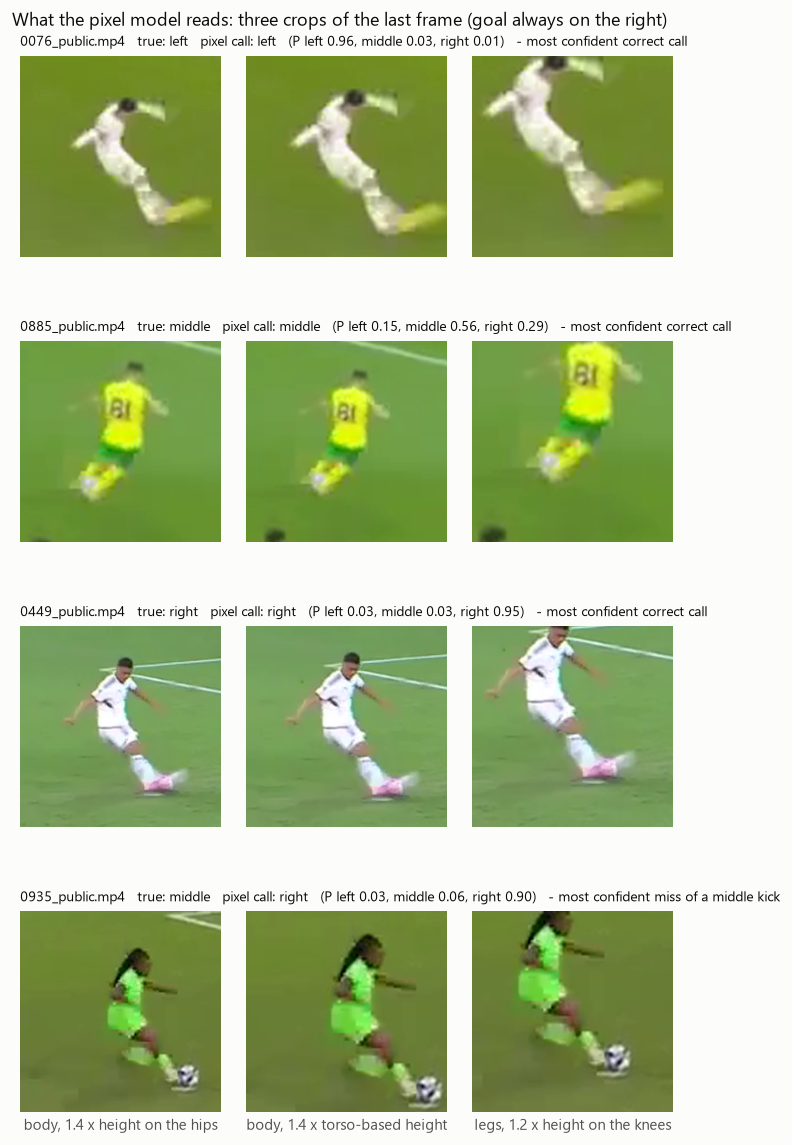

In [90]:
from IPython.display import Image, display
run("fig_crops.py", tail=6); display(Image(filename=os.path.join(RUN, "logs", "fig", "crops.png")))

## 15. N4 (geometric blend, corrected camera) and N6 (keeper dip timing)
Rules for both were written before their CV results (`RULES_nov4.md`, `RULES_nov6.md`).
* **Camera below the horizon.** `nov4_cam.py make` targets the clips whose fitted camera has sin φ < 0 (12 public, 6 test):
  * when camera2's goal side disagrees with the calibration flip, it uses φ + 180°, otherwise −φ;
  * then it rebuilds kinR on that camera.
  * `nov4_private.py trees` reads the main trees on the corrected rows, and `nov4_private.py cam` the pixel model's camera terms. It also reads the 25 fps grid rows (`pipeline_grid.py features`, `timegrid.py`) for an arm the final recipe does not use.
* **Geometric blend.** `make_subN4.py N4 --geo --cam`: kick = normalise(√(base · pixel)), where base = P4rkT's.
  * Source-grouped CV: +2 / +3 / +3 clips over the linear blend; log loss is better on every set.
* **Keeper dip timing.** `keepD.py` reads the keeper's goal-plane track:
  * the time since the last up/down turning point of the hips and head, and the depth of the last dip;
  * "committed yet?" flags: lateral move > 0.10 m in the last 0.12 s, feet raised > 0.10 m.
* `nov6_private.py keeper` appends these to the four keeper tree members and refits them on all public clips. It checks that without keepD it reproduces the N4 keeper exactly.
  * CV: +3 / +2 / +2 / +2 keeper clips on four partition sets, adopted by the rule.
* `make_subN6.py N6 --g3` = N4's kick + the new keeper. It changes 7 of 900 test keepers.

In [91]:
%%writefile nov4_cam.py
"""Idea 3a (RULES_nov4.md): camera angle below the horizon (sin phi < 0). If camera2's goal side (sign of cos phi) disagrees with the calibration flip, the goal direction is reversed: phi + 180; else phi -> -phi.
make  -> cache/camera2f.pkl (camera2 with the flagged clips refitted from (s, theta, phi')), then kinR A/F/G with CAMF=camera2f -> cache/kinR_{S}_camera2f.pkl
trees -> per partition set: trees trained on the original rows (as e_trees.py), read on original and corrected test rows -> cache/nov4/cam_trees_{set}.npz
usage: python cap.py nov4_cam.py make | trees 012|345|91011"""
import os, sys, pickle, subprocess, numpy as np
from common import *

FLP = np.load(f"{PC}/zoom3_meta.npz"); FLIP = dict(zip(list(FLP["clips"]), FLP["flip"]))


def model(p):  # camera2.py's model; camera2.py itself is not imported, since importing it refits and rewrites camera2.pkl
    s, th, ph = p; st, ct = np.sin(th), np.cos(th)
    return np.array([s * np.cos(ph), -s * st * np.sin(ph)]), np.array([-s * np.sin(ph), -s * st * np.cos(ph)]), np.array([0.0, -s * ct])


def fixed_phi(d, c):
    ph = np.radians(d["phi"])
    if np.sin(ph) >= 0: return None
    goal_right = np.cos(ph) > 0
    return float(np.degrees(ph + np.pi)) if goal_right == bool(FLIP[c]) else float(-d["phi"])      # flip True = goal on the left, so goal_right == flip means they disagree


if sys.argv[1] == "make":
    CAM = pickle.load(open(f"{PC}/camera2.pkl", "rb")); out = dict(CAM); prv = set(pm["clip"]); n = 0
    for c, d in CAM.items():
        if d is None or "phi" not in d: continue
        p2 = fixed_phi(d, c)
        if p2 is None: continue
        e = dict(d); mu, mv, mz = model([d["s"], np.radians(d["theta"]), np.radians(p2)]); e.update(phi=p2, A=np.c_[mu, mv], az=mz, phi_old=d["phi"]); e["ball_ground"] = e["ball"] - e["az"] * 0.11; e["Ai"] = np.linalg.inv(e["A"]); e["keeper_g"] = e["Ai"] @ (e["kfeet"] - e["ball_ground"]); out[c] = e; n += 1
        print(f"   {c:18s} {'test' if c in prv else 'labelled':8s} flip {int(FLIP[c])} phi {d['phi']:7.1f} -> {p2:7.1f} | {'reversed' if abs(((p2 - d['phi']) % 360) - 180) < 1e-6 else 'vertical'}", flush=True)
    pickle.dump(out, open(f"{PC}/camera2f.pkl", "wb")); print("flagged", n, flush=True)
    for S in "AFG": subprocess.run([sys.executable, "kinR.py", S], env=dict(os.environ, CAMF="camera2f"), check=True)

if sys.argv[1] == "trees":
    from cvlib import hg, et, stack, yk, ym, grp, cl, SW
    from sklearn.model_selection import StratifiedGroupKFold
    SET = sys.argv[2]; SEEDS = {"012": (0, 1, 2), "345": (3, 4, 5), "91011": (9, 10, 11)}[SET]

    def feats(kr):
        Xa, Xb, nm = [], [], []
        for f in kr:
            K = pickle.load(open(f"{PC}/{f}.pkl", "rb")); r = K["rows"]; nm += list(K["names"])
            if isinstance(next(iter(r.values()))[0], tuple): r = {c: (v[0][0], v[1][0]) for c, v in r.items()}
            a, b = stack(r, gt["clip"], len(K["names"])); Xa.append(a); Xb.append(b)
        return np.concatenate(Xa, 1), np.concatenate(Xb, 1), nm

    R = {k: np.zeros((len(gt), 3)) for k in ("orig", "cam")}
    for S in "AFG":
        V = dict(orig=feats([f"kin2_{S}_ball2", f"kinR_{S}"]), cam=feats([f"kin2_{S}_ball2", f"kinR_{S}_camera2f"])); assert V["orig"][2] == V["cam"][2]; keep = ~np.isnan(V["orig"][0]).all(0); V = {k: (a[:, keep], b[:, keep]) for k, (a, b, _) in V.items()}; Xa, Xb = V["orig"]
        ch = np.where(~(np.isclose(V["orig"][0], V["cam"][0], equal_nan=True).all(1)))[0]; print(S, "rows changed by the corrected camera:", len(ch), flush=True)
        for mk in (hg, et):
            for s in SEEDS:
                for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(Xa, yk, grp):
                    m = mk(s).fit(np.r_[Xa[tr], Xb[tr]], np.r_[yk[tr], ym[tr]]); c_ = list(m.classes_); ix = [c_.index(SW[k]) for k in c_]; o_ = [c_.index(k) for k in cl]
                    for k, (a, b) in V.items(): R[k][te] += ((m.predict_proba(a[te]) + m.predict_proba(b[te])[:, ix]) / 2)[:, o_] / len(SEEDS) / 2 / 3
    os.makedirs(f"{PC}/nov4", exist_ok=True); np.savez(f"{PC}/nov4/cam_trees_{SET}.npz", **R); print("saved", flush=True)

Overwriting nov4_cam.py


In [92]:
%%writefile pipeline_grid.py
"""Common time grid (timegrid.py) through P4's kick chain, in a separate cache dir cache_g (Q4P_CACHE) with Q4_GRID=1: kin2b A/F/G, kinR A/F/G, kinMB, seq2b A/B/E/F/G plain and RM;
trees {S}_b2R and NN bags b2 / b2RM on EF and G, seed sets from argv (default 0,1,2). ball2 and camera2 are copies of the main cache; nothing there changes.
usage: python pipeline_grid.py [features] [0,1,2] [3,4,5] -> logs/pipeline_grid.log"""
import os, sys, shutil, threading, time
from concurrent.futures import ThreadPoolExecutor
from runner import P, sh as _sh
LOG = open(f"{P}/logs/pipeline_grid.log", "a", buffering=1); sh = lambda a, env=None: _sh(LOG, a, env)
PC0, GC = f"{P}/cache", f"{P}/cache_g"; E = dict(Q4P_CACHE=GC, Q4_GRID="1"); TH = dict(E, OMP_NUM_THREADS="8", LOKY_MAX_CPU_COUNT="8")
sds = [a for a in sys.argv[1:] if "," in a] or []
os.makedirs(GC, exist_ok=True)
for f in ("ball2.pkl", "camera2.pkl"):
    if not os.path.exists(f"{GC}/{f}"): shutil.copy(f"{PC0}/{f}", f"{GC}/{f}")
if not os.path.isdir(f"{GC}/mb3d"): shutil.copytree(f"{PC0}/mb3d", f"{GC}/mb3d")
if "features" in sys.argv:
    for S in "AFG": sh(["kin2b.py", S, "ball2"], E); sh(["kinR.py", S], E)
    sh(["kinMB.py"], E)
    for S in "ABEFG": sh(["seq2b.py", S], E); sh(["seq2b.py", S, "RM"], E)
    LOG.write(f"[{time.strftime('%H:%M:%S')}] features done\n")


SF = lambda sd: "" if sd == "0,1,2" else "_sd345"


def cpu():
    for sd in sds:
        for S in "AFG":
            if not (os.path.exists(f"{GC}/oof_hgb_{S}_b2R{SF(sd)}.npy") and os.path.exists(f"{GC}/oof_et_{S}_b2R{SF(sd)}.npy")): sh(["e_trees.py", f"{S}_b2R" + SF(sd), f"kin2_{S}_ball2", f"kinR_{S}", f"--seeds={sd}"], TH)


th = threading.Thread(target=cpu); th.start()
cfg = [(12, 96), (15, 128), (20, 96), (20, 128), (30, 128)]
jobs = [(e, h, st, sq, sd) for sd in sds for sq in ("b2", "b2RM") for st in ("EF", "G") for e, h in cfg if not os.path.exists(f"{GC}/oofP_{e}_{h}_st{st}_{sq}{SF(sd)}.npy")]
with ThreadPoolExecutor(3) as ex: list(ex.map(lambda j: sh(["train_seqP.py", str(j[0]), str(j[1])], dict(E, SEQ=j[3], STREAMS=j[2], SEEDS=j[4], OMP_NUM_THREADS="2")), jobs))
th.join(); LOG.write(f"[{time.strftime('%H:%M:%S')}] pipeline_grid done {sds}\n")

Overwriting pipeline_grid.py


In [93]:
%%writefile nov4_private.py
"""Private-clip parts for the 4 Nov ideas (RULES_nov4.md), fitted on all labelled clips; each part also reproduces P4rkD's saved private part as a check.
trees -> trees_private.py recipe (HGB 4 configs x 3 seeds + ET x 3 seeds, mirror rows and TTA) on the original rows, read on the private clips' original rows, 25 fps grid rows (cache_g, idea 1c) and corrected-camera rows (kinR_{S}_camera2f, idea 3a) -> cache/nov4/prv_trees_{S}.npz
DC    -> pixel model on the CLAHE crops (idea 4) -> cache/nov4/prv_px_DC.npy
mix   -> pixel model trained on original + LR + LRJ crops, read on the private original crops (idea 1b) -> cache/nov4/prv_px_mix.npy
cam   -> P4rkD pixel model read with the corrected camera (idea 3a) -> cache/nov4/prv_px_cam.npy
usage: python cap.py nov4_private.py trees | DC | mix | cam"""
import os, sys, pickle, numpy as np
from common import *

OUT = f"{PC}/nov4"; os.makedirs(OUT, exist_ok=True); PART = sys.argv[1]; prv = list(pm["clip"])

if PART == "trees":
    from cvlib import HGB, et, stack, fit_predict, cl
    base = dict(max_iter=250, learning_rate=0.04, max_depth=4, min_samples_leaf=25, l2_regularization=2.0, max_features=0.5); HC = [dict(), dict(max_depth=5, max_iter=200, min_samples_leaf=40), dict(max_depth=3, min_samples_leaf=50), dict(max_depth=3)]

    def rows(paths, clips):
        A, B = [], []
        for p in paths:
            K = pickle.load(open(p, "rb")); r = K["rows"]
            if isinstance(next(iter(r.values()))[0], tuple): r = {c: (v[0][0], v[1][0]) for c, v in r.items()}
            r = {c: v for c, v in r.items() if len(v[0]) == len(K["names"])}; a, b = stack(r, clips, len(K["names"])); A.append(a); B.append(b)
        return np.concatenate(A, 1), np.concatenate(B, 1)

    for S in "AFG":
        o = [f"{PC}/kin2_{S}_ball2.pkl", f"{PC}/kinR_{S}.pkl"]; V = dict(orig=o, grid=[f"{P}/cache_g/kin2_{S}_ball2.pkl", f"{P}/cache_g/kinR_{S}.pkl"], cam=[o[0], f"{PC}/kinR_{S}_camera2f.pkl"])
        Xa, Xb = rows(o, gt["clip"]); keep = ~np.isnan(Xa).all(0); Xa, Xb = Xa[:, keep], Xb[:, keep]; Q = {k: tuple(x[:, keep] for x in rows(v, prv)) for k, v in V.items()}; Qa, Qb = np.concatenate([q[0] for q in Q.values()]), np.concatenate([q[1] for q in Q.values()])
        Ph = sum(fit_predict(lambda s, c=c: HGB(random_state=s, **{**base, **c}), Xa, Xb, Qa, Qb) for c in HC) / len(HC); Pe = fit_predict(et, Xa, Xb, Qa, Qb); Pall = (Ph + Pe) / 2; R = {k: Pall[i * len(prv):(i + 1) * len(prv)] for i, k in enumerate(V)}
        print(f"{S}: check vs saved prv_trees_{S}_b2R: max abs difference {np.abs(R['orig'] - np.load(f'{PC}/prv_trees_{S}_b2R.npy')).max():.2e} | rows changed: grid {int((~np.isclose(Q['grid'][0], Q['orig'][0], equal_nan=True).all(1)).sum())}, cam {int((~np.isclose(Q['cam'][0], Q['orig'][0], equal_nan=True).all(1)).sum())}", flush=True)
        np.savez(f"{OUT}/prv_trees_{S}.npz", **R)

else:
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    import pxlib
    from pxlib import rows, cam, head, pub, cl, yk, SW
    VW = ("body_hm", "body_tor", "legs12"); K, C = 512, 0.001

    def fit(versions, tr, fa, cp, sp, yc, ycm, seed):   # as nov4_px.fit
        Xa, Xb = versions[0]; E = np.r_[Xa[tr], Xb[tr]]; sc = StandardScaler().fit(E); pc = PCA(K, random_state=seed).fit(sc.transform(E)); del E; q = pc.transform(sc.transform(np.r_[Xa[tr], Xb[tr]])).std(0) + 1e-6
        ex = lambda A, f, c_, s_: head(pc.transform(sc.transform(A)) / q, f, c_, s_)
        X = np.concatenate([np.r_[ex(a[tr], fa[tr], cp[tr], sp[tr]), ex(b[tr], -fa[tr], -cp[tr], sp[tr])] for a, b in versions]); Y = np.tile(np.r_[yc[tr], ycm[tr]], len(versions))
        m = LogisticRegression(C=C / len(versions), max_iter=4000).fit(X, Y); c_ = list(m.classes_); sw = [c_.index(SW[z]) for z in c_]; o_ = [c_.index(z) for z in cl]
        return lambda Aq, Bq, f, c, s: ((m.predict_proba(ex(Aq, f, c, s)) + m.predict_proba(ex(Bq, -f, -c, s))[:, sw]) / 2)[:, o_]

    tag = "DC" if PART == "DC" else "D"; Xa, Xb, ok_, fl = rows([f"e_{v}_vpbase{tag}" for v in VW], pub); fa, cp, sp = cam(pub, fl); yc = np.array([SW[v] if f else v for v, f in zip(yk, fl)]); ycm = np.array([SW[v] for v in yc])
    Qa, Qb, oq, flq = rows([f"e_{v}_vpbase{tag}" for v in VW], prv); fq, cq, sq = cam(prv, flq); unflip = lambda P: np.where(flq[:, None], P[:, ::-1], P)
    S0 = np.load(f"{PC}/Pp_e_body_hm_vpbaseD+e_body_tor_vpbaseD+e_legs12_vpbaseD_512_0.001.npy", allow_pickle=True).item()["P"]; tr = np.where(ok_)[0]; Po, Pv = np.zeros((len(prv), 3)), np.zeros((len(prv), 3))
    if PART == "cam":
        CF = pickle.load(open(f"{PC}/camera2f.pkl", "rb")); ph2 = np.radians(np.array([CF[c]["phi"] if CF.get(c) else 0.0 for c in prv])); cq2, sq2 = np.where(flq, -np.cos(ph2), np.cos(ph2)), np.sin(ph2); print("private camera rows changed:", int((~np.isclose(cq2, cq) | ~np.isclose(sq2, sq)).sum()), flush=True)
    if PART == "mix": L = [rows([f"e_{v}_vpbase{m}" for v in VW], pub)[:2] for m in ("LR", "LRJ")]; tr = np.where(ok_ & np.load(f"{PC}/cropsLR_ok.npy"))[0]
    for s in (0, 1, 2):
        if PART in ("DC", "cam"): f_ = fit([(Xa, Xb)], tr, fa, cp, sp, yc, ycm, s); Po += f_(Qa, Qb, fq, cq, sq) / 3; Pv += (f_(Qa, Qb, fq, cq2, sq2) if PART == "cam" else 0) / 3
        if PART == "mix": f_ = fit([(Xa, Xb)] + L, tr, fa, cp, sp, yc, ycm, s); Pv += f_(Qa, Qb, fq, cq, sq) / 3
        print("seed", s, flush=True)
    if PART == "DC": np.save(f"{OUT}/prv_px_DC.npy", unflip(Po))
    if PART == "cam": print(f"check vs saved P4rkD private pixel: max abs difference {np.abs(unflip(Po) - S0).max():.2e}", flush=True); np.save(f"{OUT}/prv_px_cam.npy", unflip(Pv))
    if PART == "mix": np.save(f"{OUT}/prv_px_mix.npy", unflip(Pv))
    print("saved", PART, flush=True)

Overwriting nov4_private.py


In [94]:
%%writefile make_subN4.py
"""P4rkD + the adopted 4 Nov ideas (RULES_nov4.md, decisions in logs/nov4/eval.txt). Kick = blend of base (P4rkT) and pixel (P4rkD's three ViTPose+ base crops); keeper = P4rkT's. Flags:
--g15  base trees for the private clips at 15 fps from the 25 fps grid rows (cache_g), trees trained on the original rows (idea 1c)
--cam  base trees and pixel camera terms from the corrected camera on the private clips with sin phi < 0 (idea 3a)
--dc   pixel model on CLAHE crops (idea 4)
--mix  pixel model trained on original + degraded crops for the private clips at 640x360 (idea 1b)
--geo  geometric blend (idea 2a); --mid  P(middle) x 0.8 (idea 2b)
Re-picked / ball3-moved clips keep P4rkT's base. No flags reproduces P4rkD (checked). Writes only the local file; submitting is a separate step.
usage: python make_subN4.py NAME [flags] -> submission_{NAME}.csv, cache/Pk_private_{NAME}.npy"""
import sys, pickle, numpy as np, pandas as pd
from common import *

NAME, FL = sys.argv[1], set(a[2:] for a in sys.argv[2:]); cl = np.array(["left", "middle", "right"]); prv = list(pm["clip"]); NV = f"{PC}/nov4"; cfg = [(12, 96), (15, 128), (20, 96), (20, 128), (30, 128)]
KF = set(pickle.load(open(f"{PC}/kfix_clips.pkl", "rb"))); B3 = pickle.load(open(f"{PC}/ball3.pkl", "rb")); oth = np.array([c in KF or (bool(B3.get(c)) and B3[c].get("method") == "nbjw_spot") for c in prv])
Pb = np.load(f"{PC}/Pk_private_P4rkT.npy"); base = pd.read_csv(f"{P}/submission_P4rkT.csv"); assert list(base["clip"]) == prv
N = sum(np.load(f"{PC}/prvP_{e}_{h}_st{st}_{q}.npy") for e, h in cfg for st in ("EF", "G") for q in ("b2", "b2RM")) / 20; F = np.load(f"{PC}/Pp_e_body_hm_vpbaseD+e_body_tor_vpbaseD+e_legs12_vpbaseD_512_0.001.npy", allow_pickle=True).item()["P"]
f15 = pm["fps"].values < 20; lr = pm["resolution"].values == "640x360"; CF = pickle.load(open(f"{PC}/camera2f.pkl", "rb")); fc = np.array([bool(CF.get(c)) and "phi_old" in CF[c] for c in prv]); Bk = Pb.copy(); log = []
if "cam" in FL:
    T = sum(np.load(f"{NV}/prv_trees_{S}.npz")["cam"] for S in "AFG") / 3; m = fc & ~oth; Bk[m] = .5 * T[m] + .5 * N[m]; log.append(f"cam base on {int(m.sum())} clips")
if "g15" in FL:
    T = sum(np.load(f"{NV}/prv_trees_{S}.npz")["grid"] for S in "AFG") / 3; m = f15 & ~oth; Bk[m] = .5 * T[m] + .5 * N[m]; log.append(f"grid base on {int(m.sum())} clips at 15 fps")
if "dc" in FL: F = np.load(f"{NV}/prv_px_DC.npy"); log.append("CLAHE pixel on all clips")
if "cam" in FL and "dc" not in FL: Fc = np.load(f"{NV}/prv_px_cam.npy"); F = np.where(fc[:, None], Fc, F); log.append(f"cam pixel on {int(fc.sum())} clips")
if "mix" in FL: Fm = np.load(f"{NV}/prv_px_mix.npy"); F = np.where(lr[:, None], Fm, F); log.append(f"mix pixel on {int(lr.sum())} clips at 640x360")
if "geo" in FL: G = np.exp(.5 * np.log(Bk + 1e-4) + .5 * np.log(F + 1e-4)); Pk = G / G.sum(1, keepdims=True); log.append("geometric blend")
else: Pk = .5 * Bk + .5 * F
if "mid" in FL: Pk = Pk * np.array([1, .8, 1]); Pk = Pk / Pk.sum(1, keepdims=True); log.append("middle x0.8")
D = np.load(f"{PC}/Pk_private_P4rkD.npy")
if not FL: assert np.allclose(Pk, D), "no flags must reproduce P4rkD"
sub = base.assign(kick_direction=cl[Pk.argmax(1)]); sub.to_csv(f"{P}/submission_{NAME}.csv", index=False); np.save(f"{PC}/Pk_private_{NAME}.npy", Pk); d = cl[D.argmax(1)]; chg = sub.kick_direction.values != d
print(f"wrote submission_{NAME}.csv | {'; '.join(log) or 'P4rkD as is'} | kick changed vs P4rkD on {int(chg.sum())} of {len(sub)} ({pd.Series([a[0] + '->' + b[0] for a, b in zip(d[chg], sub.kick_direction.values[chg])]).value_counts().to_dict()}) | by group: 15 fps {int((chg & f15).sum())}, 640x360 {int((chg & lr).sum())}, camera-flagged {int((chg & fc).sum())} | counts {sub.kick_direction.value_counts().to_dict()}")

Overwriting make_subN4.py


In [95]:
%%writefile keepD.py
"""Idea 3 of RULES_nov6.md: keeper dip timing and "committed yet?" flags, appended to the four keeper tree members (keep_S_b2 + keepD_S, keepR_S + keepD_S).
Goal-plane decomposition of keepR.py (camera2: a_v along the goal line to the kicker's left, a_z up; metres), keeper keypoints at the F frames stabilised with M,
score >= 2.0 (RTMW kkeep = stream A, ViTPose-L kkeepF = stream F). Series relative to -0.45 s: hip mid, head (nose), feet mid.
Turning points of 'up' (hip, head) among the frames from -0.6 s: scipy find_peaks on up (tops) and -up (dip bottoms), prominence PROM metres (fixed without labels, see probe).
Per series: time since the last turning point (s before the end; NaN if none), its kind (+1 dip bottom, -1 top, 0 none), rise and lateral move since then
(lateral signed and absolute), time since the last dip bottom and its depth (highest point in the 0.3 s before it minus the bottom).
Flags: lateral hip move over the last 0.12 s > 0.10 m; feet raised > 0.10 m at the last frame; time since the hip / the feet were last >= 0.15 m (lateral) from their final
position (NaN if never in the window). Mirror negates the lateral axis.
usage: python cap.py keepD.py [probe]  -> cache/keepD_{A,F}.pkl rows {clip: (static, static_mirror)}, names"""
import os, sys, pickle, warnings, numpy as np
from common import *
warnings.filterwarnings("ignore")
from scipy.signal import find_peaks

CT, PROM = 2.0, float(os.environ.get("KD_PROM", "0.03"))                  # probe: hip 'up' jitter ~0.02 m per frame -> 0.03 m (turning point in ~1 clip in 4)
CAMF = os.environ.get("CAMF", "camera2"); CAM = pickle.load(open(f"{PC}/{CAMF}.pkl", "rb")); NAMES = []


def series(b, kk, cam, sg):
    ts = b["ts"] - b["ts"][-1]; sc = kk["sc"]; M = b["M"]
    P = np.einsum("fij,fkj->fki", M, np.concatenate([kk["kp"], np.ones(kk["kp"].shape[:2] + (1,), np.float32)], -1)); P = P[..., :2] / P[..., 2:3]; P = np.where((sc >= CT)[..., None], P, np.nan)
    Bi = np.linalg.inv(np.c_[cam["A"][:, 1], cam["az"]]); GP = lambda V: (np.asarray(V, float) @ Bi.T) * np.array([sg, 1.0])
    mid = lambda ids: np.nanmean(P[:, ids], axis=1); ref = int(np.abs(ts + 0.45).argmin())
    pts = {"hip": mid([11, 12]), "head": P[:, 0], "feet": mid([15, 16])}
    return ts, {k: GP(v - v[ref]) for k, v in pts.items()}


def turning(ts, up, prom=None):
    prom = PROM if prom is None else prom; m = np.where((ts >= -0.6) & np.isfinite(up))[0]
    if len(m) < 4: return np.array([], int), np.array([], int)
    hi, _ = find_peaks(up[m], prominence=prom); lo, _ = find_peaks(-up[m], prominence=prom); return m[hi], m[lo]


def build(b, kk, cam, mirror):
    f_ = []
    def add(name, vals):
        vals = np.atleast_1d(np.asarray(vals, np.float32)).ravel(); f_.extend(vals.tolist()); NAMES.extend([f"{name}{i}" if len(vals) > 1 else name for i in range(len(vals))])
    ts, S = series(b, kk, cam, -1.0 if mirror else 1.0); near = lambda o: int(np.abs(ts + o).argmin())
    for nm in ("hip", "head"):
        lat, up = S[nm][:, 0], S[nm][:, 1]; hi, lo = turning(ts, up); ex = sorted([(i, -1) for i in hi] + [(i, 1) for i in lo])
        if ex:
            i, kind = ex[-1]; add(f"d_{nm}_last_turn", [-ts[i], kind, up[-1] - up[i], lat[-1] - lat[i], abs(lat[-1] - lat[i])])
        else: add(f"d_{nm}_last_turn", [np.nan, 0, np.nan, np.nan, np.nan])
        if len(lo):
            i = lo[-1]; w = np.where((ts >= ts[i] - 0.3) & (ts <= ts[i]))[0]; add(f"d_{nm}_dip", [-ts[i], np.nanmax(up[w]) - up[i]])
        else: add(f"d_{nm}_dip", [np.nan, np.nan])
    hl, fu, fl = S["hip"][:, 0], S["feet"][:, 1], S["feet"][:, 0]; j12 = near(0.12)
    mv = abs(hl[-1] - hl[j12]); add("d_commit", [float(mv > 0.10) if np.isfinite(mv) else np.nan, float(fu[-1] > 0.10) if np.isfinite(fu[-1]) else np.nan])
    for nm, L in (("hip", hl), ("feet", fl)):
        far = np.where(np.isfinite(L) & (np.abs(L - L[-1]) >= 0.15))[0]; add(f"d_{nm}_t15", -ts[far[-1]] if len(far) and np.isfinite(L[-1]) else np.nan)
    return np.array(f_, np.float32)


def one(args):
    c, S = args
    b = load("ballspot", c); k0 = load("kkeep", c); ks = k0 if S == "A" else load("kkeepF", c); cam = CAM.get(c)
    if b is None or k0 is None or ks is None or cam is None: return c, None, None
    kk = dict(kp=ks["kp"], sc=ks["sc"], box=k0["box"]); NAMES.clear(); a = build(b, kk, cam, False); names = list(NAMES); NAMES.clear(); m = build(b, kk, cam, True)
    return c, (a, m), names


if __name__ == "__main__":
    if len(sys.argv) > 1 and sys.argv[1] == "probe":                       # label-free: turning points per clip for a few prominences, frame-to-frame jitter of 'up'
        rng = np.random.default_rng(0); smp = [CLIPS[i] for i in rng.choice(len(CLIPS), 200, replace=False)]
        for S in "AF":
            cnt = {p: [] for p in (0.02, 0.03, 0.04, 0.06)}; jit = []
            for c in smp:
                b = load("ballspot", c); k0 = load("kkeep", c); ks = k0 if S == "A" else load("kkeepF", c); cam = CAM.get(c)
                if b is None or k0 is None or ks is None or cam is None: continue
                ts, Sr = series(b, dict(kp=ks["kp"], sc=ks["sc"], box=k0["box"]), cam, 1.0); up = Sr["hip"][:, 1]; m = np.where(ts >= -0.24)[0]; jit.append(np.nanmedian(np.abs(np.diff(up[m]))))
                for p in cnt: hi, lo = turning(ts, up, p); cnt[p].append(len(hi) + len(lo))
            print(f"{S}: hip 'up' median frame-to-frame change over the last 0.24 s {np.nanmedian(jit):.4f} m (p90 {np.nanpercentile(jit, 90):.4f})")
            for p, v in cnt.items(): v = np.array(v); print(f"   prominence {p:.2f} m: turning points per clip median {np.median(v):.1f}, mean {v.mean():.2f}, none {np.mean(v == 0):.2f}, >= 3 {np.mean(v >= 3):.2f}")
        sys.exit()
    from multiprocessing import Pool
    for S in "AF":
        with Pool(int(os.environ.get("NPOOL", "8"))) as p: res = p.map(one, [(c, S) for c in CLIPS], chunksize=20)
        rows = {c: r for c, r, _ in res if r is not None}; names = next(n for _, r, n in res if r is not None)
        pickle.dump(dict(rows=rows, names=names), open(f"{PC}/keepD_{S}{'' if CAMF == 'camera2' else '_' + CAMF}.pkl", "wb"))
        X = np.stack([r[0] for r in rows.values()]); print(f"keepD {S}: built {len(rows)} | dim {len(names)} | NaN frac {np.isnan(X).mean():.3f} | names {names}", flush=True)

Overwriting keepD.py


In [96]:
%%writefile nov6_px.py
"""Pixel model out of fold for RULES_nov6.md (variant Tm) on the fresh partition set 212223: the T job of RULES_px2 (archive/scripts/px2.py, unchanged logic).
D = P4rkD recipe (ViTPose+ base tokens of body_hm, body_tor, legs12 joined, scaler and PCA 512 on the training clips, C 0.001, head V3, crop and mirror rows, mirror TTA,
three partition seeds averaged); T = D's tokens plus the four alignment versions T1..T4, scaler and PCA from D's version, all five versions train (C / 5), the five
averaged at test. D is fit alongside T with the same scaler and PCA (the 5 Nov check: matches the saved P4rkD files to 8e-6). Tokens kept in float16. Per-seed checkpoint.
usage: python cap.py nov6_px.py 212223 -> cache/px2/px_T_212223.npz (P = T, D = D)"""
import os, sys, time, numpy as np
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from common import *
from pxlib import cam, head, pub, cl, yk, SW, grp, IX, OK3, FL3

OUT = f"{PC}/px2"; os.makedirs(OUT, exist_ok=True)
VW = ("body_hm", "body_tor", "legs12"); K, C = 512, 0.001; J = np.array([IX[c] for c in pub]); fl = FL3[J]
ok_ = OK3[J] & np.load(f"{PC}/crops_hr_meta.npz")["ok"][J]                    # the same training clips as RULES_px2 (all sets)


def load(tag):
    G = [np.load(f"{PC}/ce_{v}_vpbase{tag}.npy", mmap_mode="r") for v in VW]
    return tuple(np.concatenate([np.asarray(g[J, k]).reshape(len(J), -1) for g in G], 1) for k in (0, 1))


def fit(V, tr, fa, cp, sp, yc, ycm, seed):
    f32 = lambda A: A.astype(np.float32); E = f32(np.r_[V[0][0][tr], V[0][1][tr]]); sc = StandardScaler().fit(E); pc = PCA(K, random_state=seed).fit(sc.transform(E)); q = pc.transform(sc.transform(E)).std(0) + 1e-6; del E
    Z = lambda A: pc.transform(sc.transform(f32(A))) / q; Y = np.r_[yc[tr], ycm[tr]]
    R = [np.r_[head(Z(a[tr]), fa[tr], cp[tr], sp[tr]), head(Z(b[tr]), -fa[tr], -cp[tr], sp[tr])] for a, b in V]

    def lr(Xs):
        m = LogisticRegression(C=C / len(Xs), max_iter=4000).fit(np.concatenate(Xs), np.tile(Y, len(Xs))); c_ = list(m.classes_); sw = [c_.index(SW[z]) for z in c_]; o_ = [c_.index(z) for z in cl]
        return lambda Vq, f, c, s: (sum((m.predict_proba(head(Z(a), f, c, s)) + m.predict_proba(head(Z(b), -f, -c, s))[:, sw]) / 2 for a, b in Vq) / len(Vq))[:, o_]
    return lr(R), lr(R[:1])


if __name__ == "__main__":
    SET = sys.argv[1]; SEEDS = {"212223": (21, 22, 23)}[SET]
    V = [load(t) for t in ("D", "T1", "T2", "T3", "T4")]; fa, cp, sp = cam(pub, fl)                    # the ce_*.npy token files are float16 already
    yc = np.array([SW[v] if f else v for v, f in zip(yk, fl)]); ycm = np.array([SW[v] for v in yc]); Pc = {"P": np.zeros((len(pub), 3)), "D": np.zeros((len(pub), 3))}
    CK = f"{OUT}/px_T_{SET}_part.npz"; done = []
    if os.path.exists(CK): z = np.load(CK); Pc, done = {k: z[k].copy() for k in Pc}, list(z["done"]); print("resumed after seeds", done, flush=True)
    for s in SEEDS:
        if s in done: continue
        for f_, (tr, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=s).split(V[0][0], yk, grp)):
            t0 = time.time(); pm_, pd_ = fit(V, tr[ok_[tr]], fa, cp, sp, yc, ycm, s); Vq = [(a[te], b[te]) for a, b in V]
            Pc["P"][te] += pm_(Vq, fa[te], cp[te], sp[te]) / len(SEEDS); Pc["D"][te] += pd_(Vq[:1], fa[te], cp[te], sp[te]) / len(SEEDS)
            print(f"T {SET} seed {s} fold {f_} ({time.time() - t0:.0f}s)", flush=True)
        done.append(s); np.savez(CK, done=np.array(done), **Pc)
    R = {k: np.where(fl[:, None], v[:, ::-1], v) for k, v in Pc.items()}; np.savez(f"{OUT}/px_T_{SET}.npz", **R); print("saved", flush=True)

Overwriting nov6_px.py


In [97]:
%%writefile nov6_private.py
"""Test-clip parts for the variants adopted by RULES_nov6.md, fitted on all 1300 labelled clips; every part re-derives a saved N4 part on the same code path as a check.
trees  -> K2: kick trees S_b2X (kin2 + kinR + kinX) with the trees_private.py recipe (HGB 4 configs x 3 seeds + ET x 3 seeds, mirror rows and TTA), read on the test clips'
          rows and on the corrected-camera rows (kinR_S_camera2f + kinX_S_camera2f, idea 3a of 4 Nov) -> cache/nov6/prv_trees_X_{S}.npz (orig, cam).
          Check: stream A with kin2 + kinR only must reproduce prv_trees_A_b2R.npy.
keeper -> G3: keep_private.py's seven members with keepD appended to the four tree members -> cache/nov6/pg_private_b2GD.npy.
          Check: the same without keepD must reproduce pg_private_b2G.npy.
pxT    -> Tm: the T pixel model (D's scaler and PCA, five alignment versions train with C / 5, the five averaged at test), three PCA seeds, read with the original camera
          terms and with the corrected camera (camera2f) -> cache/nov6/prv_px_T.npz (P, Pcam, D). Check: D from the same fit vs P4rkD's saved test-clip pixel.
usage: python cap.py nov6_private.py trees | keeper | pxT"""
import os, sys, pickle, numpy as np
from common import *

OUT = f"{PC}/nov6"; os.makedirs(OUT, exist_ok=True); PART = sys.argv[1]; prv = list(pm["clip"])

if PART == "trees":
    from cvlib import HGB, et, stack, fit_predict, cl
    base = dict(max_iter=250, learning_rate=0.04, max_depth=4, min_samples_leaf=25, l2_regularization=2.0, max_features=0.5); HC = [dict(), dict(max_depth=5, max_iter=200, min_samples_leaf=40), dict(max_depth=3, min_samples_leaf=50), dict(max_depth=3)]

    def rows(paths, clips):
        A, B = [], []
        for p in paths:
            K = pickle.load(open(p, "rb")); r = K["rows"]
            if isinstance(next(iter(r.values()))[0], tuple): r = {c: (v[0][0], v[1][0]) for c, v in r.items()}
            r = {c: v for c, v in r.items() if len(v[0]) == len(K["names"])}; a, b = stack(r, clips, len(K["names"])); A.append(a); B.append(b)
        return np.concatenate(A, 1), np.concatenate(B, 1)

    def fitread(train, queries):
        Xa, Xb = rows(train, gt["clip"]); keep = ~np.isnan(Xa).all(0); Xa, Xb = Xa[:, keep], Xb[:, keep]; Q = [tuple(x[:, keep] for x in rows(q, prv)) for q in queries]
        Qa, Qb = np.concatenate([q[0] for q in Q]), np.concatenate([q[1] for q in Q])
        Ph = sum(fit_predict(lambda s, c=c: HGB(random_state=s, **{**base, **c}), Xa, Xb, Qa, Qb) for c in HC) / len(HC); Pe = fit_predict(et, Xa, Xb, Qa, Qb); Pall = (Ph + Pe) / 2
        return [Pall[i * len(prv):(i + 1) * len(prv)] for i in range(len(queries))], Q

    o = [f"{PC}/kin2_A_ball2.pkl", f"{PC}/kinR_A.pkl"]; (R0,), _ = fitread(o, [o]); print(f"check: A with kin2 + kinR vs saved prv_trees_A_b2R: max abs difference {np.abs(R0 - np.load(f'{PC}/prv_trees_A_b2R.npy')).max():.2e}", flush=True)
    for S in "AFG":
        tr = [f"{PC}/kin2_{S}_ball2.pkl", f"{PC}/kinR_{S}.pkl", f"{PC}/kinX_{S}.pkl"]; cm = [tr[0], f"{PC}/kinR_{S}_camera2f.pkl", f"{PC}/kinX_{S}_camera2f.pkl"]
        (Po, Pc), Q = fitread(tr, [tr, cm]); np.savez(f"{OUT}/prv_trees_X_{S}.npz", orig=Po, cam=Pc)
        print(f"{S}: saved | test rows changed by the corrected camera: {int((~np.isclose(Q[1][0], Q[0][0], equal_nan=True).all(1)).sum())} | argmax vs b2R trees differ on {int((Po.argmax(1) != np.load(f'{PC}/prv_trees_{S}_b2R.npy').argmax(1)).sum())}", flush=True)

if PART == "keeper":
    from cvlib import fit_predict, hg, yg, ygm, stack, ExtraTreesClassifier, make_pipeline, SimpleImputer
    etk = lambda s: make_pipeline(SimpleImputer(strategy="median"), ExtraTreesClassifier(500, min_samples_leaf=2, max_features=0.3, n_jobs=-1, random_state=s))

    def trees(fs, both):
        A, B, QA, QB = [], [], [], []
        for f in fs:
            K = pickle.load(open(f"{PC}/{f}.pkl", "rb")); r, n = K["rows"], len(K["names"]); a, b = stack(r, gt["clip"], n); qa, qb = stack(r, pm["clip"], n); A.append(a); B.append(b); QA.append(qa); QB.append(qb)
        Xa, Xb, Qa, Qb = (np.concatenate(z, 1) for z in (A, B, QA, QB)); keep = ~np.isnan(Xa).all(0)
        P = [fit_predict(mk, Xa[:, keep], Xb[:, keep], Qa[:, keep], Qb[:, keep], y=yg, y_m=ygm)[:, [0, 2, 1]] for mk in (hg, etk)]
        return P if both else [(P[0] + P[1]) / 2]

    cnn = np.load(f"{W}/cnn_gk_private.npy")[:, [0, 2, 1]]
    for D, tag in ((False, "b2G"), (True, "b2GD")):
        ap = (lambda f, S: [f, f"keepD_{S}"]) if D else (lambda f, S: [f])
        parts = trees(ap("keep_A_b2", "A"), True) + trees(ap("keep_F_b2", "F"), True) + trees(ap("keepR_A", "A"), False) + trees(ap("keepR_F", "F"), False) + [cnn]; Pg = sum(parts) / len(parts)
        if not D: print(f"check: no keepD vs saved pg_private_b2G: max abs difference {np.abs(Pg - np.load(f'{PC}/pg_private_b2G.npy')).max():.2e}", flush=True)
        else: np.save(f"{OUT}/pg_private_b2GD.npy", Pg); print(f"saved pg_private_b2GD | predicted left / right / stands {np.bincount(Pg.argmax(1), minlength=3)}", flush=True)

if PART == "pxT":
    from pxlib import cam, pub, yk, SW, IX, OK3, FL3
    from nov6_px import fit, VW
    okH = np.load(f"{PC}/crops_hr_meta.npz")["ok"]; tags = ["D", "T1", "T2", "T3", "T4"]

    def load(tag, clips):
        J = np.array([IX[c] for c in clips]); G = [np.load(f"{PC}/ce_{v}_vpbase{tag}.npy", mmap_mode="r") for v in VW]
        return tuple(np.concatenate([np.asarray(g[J, k]).reshape(len(J), -1) for g in G], 1) for k in (0, 1))

    Jp, Jq = np.array([IX[c] for c in pub]), np.array([IX[c] for c in prv]); fl, flq = FL3[Jp], FL3[Jq]; ok_ = OK3[Jp] & okH[Jp]
    V, Vq = [load(t, pub) for t in tags], [load(t, prv) for t in tags]; fa, cp, sp = cam(pub, fl); fq, cq, sq = cam(prv, flq)
    CF = pickle.load(open(f"{PC}/camera2f.pkl", "rb")); ph2 = np.radians(np.array([CF[c]["phi"] if CF.get(c) else 0.0 for c in prv])); cq2, sq2 = np.where(flq, -np.cos(ph2), np.cos(ph2)), np.sin(ph2)
    print("test-clip camera terms changed by camera2f:", int((~np.isclose(cq2, cq) | ~np.isclose(sq2, sq)).sum()), flush=True)
    yc = np.array([SW[v] if f else v for v, f in zip(yk, fl)]); ycm = np.array([SW[v] for v in yc]); Pt, Ptc, Pd = (np.zeros((len(prv), 3)) for _ in range(3))
    for s in (0, 1, 2):
        pm_, pd_ = fit(V, np.where(ok_)[0], fa, cp, sp, yc, ycm, s); Pt += pm_(Vq, fq, cq, sq) / 3; Ptc += pm_(Vq, fq, cq2, sq2) / 3; Pd += pd_(Vq[:1], fq, cq, sq) / 3; print("seed", s, flush=True)
    uf = lambda X: np.where(flq[:, None], X[:, ::-1], X); R = dict(P=uf(Pt), Pcam=uf(Ptc), D=uf(Pd))
    FD = np.load(f"{PC}/Pp_e_body_hm_vpbaseD+e_body_tor_vpbaseD+e_legs12_vpbaseD_512_0.001.npy", allow_pickle=True).item()["P"]
    print(f"check: D from the T fit vs P4rkD test-clip pixel: max abs difference {np.abs(R['D'] - FD).max():.2e}, same argmax {np.mean(R['D'].argmax(1) == FD.argmax(1)):.4f}", flush=True)
    np.savez(f"{OUT}/prv_px_T.npz", **R); print("saved prv_px_T", flush=True)

Overwriting nov6_private.py


In [98]:
%%writefile make_subN6.py
"""N4 + what RULES_nov6.md adopted (decisions in logs/nov6/judge.txt): idea 3 (G3), keeper dip timing and "committed yet?" flags (keepD.py) appended to the four keeper
tree members. Kick column = N4's, unchanged (K2 and Tm were not adopted). Keeper = (7 * b2GD + keeper network) / 8, the same construction as N4's (7 * b2G + NNk) / 8.
Flags: --g3 new keeper (cache/nov6/pg_private_b2GD.npy from nov6_private.py keeper). No flags rebuilds submission_N4.csv exactly (asserted).
Writes only the local file; submitting is a separate step. usage: python make_subN6.py NAME [--g3] -> submission_{NAME}.csv, cache/pg_private_{NAME}.npy"""
import sys, numpy as np, pandas as pd
from common import *

NAME, FL = sys.argv[1], set(a[2:] for a in sys.argv[2:]); cg = np.array(["left", "right", "stands in the middle"])
n4 = pd.read_csv(f"{P}/submission_N4.csv"); assert list(n4["clip"]) == list(pm["clip"]); NNk = np.load(f"{PC}/pg_private_NNk.npy")
P0 = (7 * np.load(f"{PC}/pg_private_b2G.npy") + NNk) / 8; assert np.allclose(P0, np.load(f"{PC}/pg_private_b2GNNk.npy")) and (cg[P0.argmax(1)] == n4["goalkeeper_direction"].values).all(), "N4 keeper check"
Pg = (7 * np.load(f"{PC}/nov6/pg_private_b2GD.npy") + NNk) / 8 if "g3" in FL else P0
sub = n4.assign(goalkeeper_direction=cg[Pg.argmax(1)]); sub.to_csv(f"{P}/submission_{NAME}.csv", index=False); np.save(f"{PC}/pg_private_{NAME}.npy", Pg)
if not FL: assert open(f"{P}/submission_{NAME}.csv", "rb").read() == open(f"{P}/submission_N4.csv", "rb").read(), "no flags must rebuild submission_N4.csv"
chg = sub.goalkeeper_direction.values != n4.goalkeeper_direction.values
print(f"wrote submission_{NAME}.csv | {'new keeper (G3)' if FL else 'N4 as is'} | kick changed vs N4 0 | keeper changed on {int(chg.sum())} of {len(sub)} "
      f"({pd.Series([a[:5] + '->' + b[:5] for a, b in zip(n4.goalkeeper_direction.values[chg], sub.goalkeeper_direction.values[chg])]).value_counts().to_dict()}) | keeper counts {sub.goalkeeper_direction.value_counts().to_dict()}")

Overwriting make_subN6.py


In [99]:
stage("corrected camera", ["cache/camera2f.pkl"] + [f"cache/kinR_{S}_camera2f.pkl" for S in "AFG"], lambda: run("nov4_cam.py", "make"))
def grid_rows():   # pipeline_grid.py "features": the 25 fps grid rows in cache_g (read by nov4_private.py trees for an arm N4 does not use)
    os.makedirs(GC, exist_ok=True); EG = dict(Q4P_CACHE=GC, Q4_GRID="1")
    for f in ("ball2.pkl", "camera2.pkl"): shutil.copy(f"{CACHE}/{f}", f"{GC}/{f}")
    for S in "AFG": run("kin2b.py", S, "ball2", env=EG); run("kinR.py", S, env=EG)
stage("grid rows", [f"cache_g/kin2_{S}_ball2.pkl" for S in "AFG"] + [f"cache_g/kinR_{S}.pkl" for S in "AFG"], grid_rows)
stage("trees on corrected rows", [f"cache/nov4/prv_trees_{S}.npz" for S in "AFG"], lambda: run("nov4_private.py", "trees"))
stage("pixel on corrected camera", ["cache/nov4/prv_px_cam.npy"], lambda: run("nov4_private.py", "cam"))
stage("N4", ["submission_N4.csv", "cache/Pk_private_N4.npy"], lambda: run("make_subN4.py", "N4", "--geo", "--cam"))
stage("keeper dip timing", ["cache/keepD_A.pkl", "cache/keepD_F.pkl"], lambda: run("keepD.py"))
stage("keeper with dip timing, private", ["cache/nov6/pg_private_b2GD.npy"], lambda: run("nov6_private.py", "keeper"))
if FINAL == "N6": stage("N6", ["submission_N6.csv", "cache/pg_private_N6.npy"], lambda: run("make_subN6.py", "N6", "--g3"))

[corrected camera] recomputing


$ python nov4_cam.py make   [51s, rc 0]
       866_private.mp4    test     flip 0 phi   -72.2 ->    72.2 | vertical
       872_private.mp4    test     flip 0 phi   -95.2 ->    84.8 | reversed
    flagged 18
    stream A: built 2200 skipped 0 | static dim 141 | seq (12, 39)
    stream F: built 2200 skipped 0 | static dim 141 | seq (12, 39)
    stream G: built 2200 skipped 0 | static dim 141 | seq (12, 39)


    check cache/camera2f.pkl: identical vs the previous output


    check cache/kinR_A_camera2f.pkl: identical vs the previous output


    check cache/kinR_F_camera2f.pkl: identical vs the previous output


    check cache/kinR_G_camera2f.pkl: identical vs the previous output
[corrected camera] done in 52s
[grid rows] recomputing


... (13 outputs left out)

$ python keepD.py    [14s, rc 0]
    keepD A: built 2200 | dim 18 | NaN frac 0.554 | names ['d_hip_last_turn0', 'd_hip_last_turn1', 'd_hip_last_turn2', 'd_hip_last_turn3', 'd_hip_last_turn4', 'd_hip_dip0', 'd_hip_dip1', 'd_head_last_turn0', 'd_head_last_turn1', 'd_head_last_turn2', 'd_head_last_turn3', 'd_head_last_turn4', 'd_head_dip0
    keepD F: built 2200 | dim 18 | NaN frac 0.537 | names ['d_hip_last_turn0', 'd_hip_last_turn1', 'd_hip_last_turn2', 'd_hip_last_turn3', 'd_hip_last_turn4', 'd_hip_dip0', 'd_hip_dip1', 'd_head_last_turn0', 'd_head_last_turn1', 'd_head_last_turn2', 'd_head_last_turn3', 'd_head_last_turn4', 'd_head_dip0
    check cache/keepD_A.pkl: identical vs the previous output
    check cache/keepD_F.pkl: identical vs the previous output


[keeper dip timing] done in 14s
[keeper with dip timing, private] recomputing


$ python nov6_private.py keeper   [145s, rc 0]
    check: no keepD vs saved pg_private_b2G: max abs difference 2.22e-16
    saved pg_private_b2GD | predicted left / right / stands [485 407   8]
    check cache/nov6/pg_private_b2GD.npy: max abs difference 2.22e-16 vs the previous output
[keeper with dip timing, private] done in 145s
[N6] recomputing


$ python make_subN6.py N6 --g3   [1s, rc 0]
    wrote submission_N6.csv | new keeper (G3) | kick changed vs N4 0 | keeper changed on 7 of 900 ({'left->right': 4, 'left->stand': 1, 'stand->right': 1, 'right->left': 1}) | keeper counts {'left': 486, 'right': 405, 'stands in the middle': 9}
    check submission_N6.csv: identical bytes vs the previous output
    check cache/pg_private_N6.npy: max abs difference 2.22e-16 vs the previous output
[N6] done in 1s


## 16. The CSV and its checks
This section checks three things:
* the format, against `submission_template.csv`: same clips, same order, valid labels;
* that the file is byte-identical to the submitted file;
* every reproduction check of the refit stages above.

In [100]:
sub = pd.read_csv(os.path.join(RUN, f"submission_{FINAL}.csv")); tpl = pd.read_csv(os.path.join(PROJECT_ROOT, "Q4data", "submission_template.csv"))
assert list(sub.columns) == list(tpl.columns) and list(sub["clip"]) == list(tpl["clip"]), "clips / columns differ from the template"
assert sub["kick_direction"].isin(["left", "middle", "right"]).all() and sub["goalkeeper_direction"].isin(["left", "right", "stands in the middle"]).all()
print(sub.shape, "| kick", sub.kick_direction.value_counts().to_dict(), "| keeper", sub.goalkeeper_direction.value_counts().to_dict(), "| outcome", sub.goal_outcome.value_counts().to_dict())
for name in ("P4", "P4k", "P4b3k", "P4rkT", "P4rkD", "N4", "N6"):     # every CSV of the chain against the file of the original run (P4, P4rkT, P4rkD, N4 and N6 were submitted)
    a, b = os.path.join(RUN, f"submission_{name}.csv"), os.path.join(NB_DIR, f"submission_{name}.csv")
    if os.path.exists(a) and os.path.exists(b): print(f"submission_{name}.csv rebuilt here vs the original file: {compare(b, a)}")
tag = lambda r: "same" if r.startswith("identical") else "~   " if r.startswith("max abs") and float(r.split()[-1]) <= 1e-4 else "DIFF"
n = {k: sum(tag(r) == k for _, _, r in LOG) for k in ("same", "~   ", "DIFF")}
print(f"\n{len(LOG)} refit checks (older output vs recomputed): {n['same']} identical | {n['~   ']} within 1e-4 (floating-point rounding: summation order in the tree ensembles,"
      f" multithreaded BLAS in the pixel model's PCA and logistic fit) | {n['DIFF']} larger")
for name, o, r in LOG: print(f"   {tag(r)} {name:42s} {o:70s} {r}")
print(sub.head())

(900, 4) | kick {'left': 490, 'right': 390, 'middle': 20} | keeper {'left': 486, 'right': 405, 'stands in the middle': 9} | outcome {'goal': 900}
submission_P4.csv rebuilt here vs the original file: identical bytes
submission_P4k.csv rebuilt here vs the original file: identical bytes
submission_P4b3k.csv rebuilt here vs the original file: identical bytes
submission_P4rkT.csv rebuilt here vs the original file: identical bytes
submission_P4rkD.csv rebuilt here vs the original file: identical bytes
submission_N4.csv rebuilt here vs the original file: identical bytes
submission_N6.csv rebuilt here vs the original file: identical bytes

113 refit checks (older output vs recomputed): 92 identical | 21 within 1e-4 (floating-point rounding: summation order in the tree ensembles, multithreaded BLAS in the pixel model's PCA and logistic fit) | 0 larger
   same camera2                                    cache/camera2.pkl                                                      identical
   same kin2 

## 17. Final assessment: is the model guessing, and how close will private be to public?
`final_assess.py` and `assess_shuffle.py` use only the out-of-fold predictions of the 1,300 labelled clips, across four partition sets. Results of the 6 Nov run (`logs/final/assess.txt`):

* **Not guessing.**
  * Labels reshuffled 100,000 times with the predictions fixed: metric 0.443 ± 0.010, against our 0.814 (38 SD). No shuffle came close.
  * Reshuffled within each source: 34 SD.
  * Retrained on shuffled labels, the ViTPose-L kick trees fall from 0.689 to 0.42–0.45.
  * Accuracy rises steadily with confidence: kick 0.55 → 0.92 across confidence fifths.
* **Against `chance.csv`.**
  * `chance.csv` (public 0.52277) is the PDF's "educated guess": kick and keeper to the kicker's natural side. It scores 0.5205 on the labelled clips.
  * On the same clips we win 396 kick clips to its 52 (McNemar p ≈ 1e-67).
  * Every subgroup is ahead: fps, resolution, foot, gender, camera side, clicked source, class.
  * Of 100,000 simulated 540-clip private boards, ours leads on 100%, with a smallest margin of +0.19.
* **Private vs public.**
  * The 360 / 540 split alone gives SD(public − private) = 0.022 for a model with no overfitting. A gap within 1% of public is therefore only 30% likely (within 1 point, 35%), whatever the model.
  * Forecast given N6's public 0.83361: private ≈ 0.820 ± 0.017 (80% range 0.798–0.842), 95% chance of at least 0.792.
  * The forecast is below public because public sits 1.7 SD above the CV level (probably luck), and 900 × level = 360 × public + 540 × private.

In [101]:
%%writefile p4rkt.py
"""P4rkT source-grouped out-of-fold kick probabilities on the public clips (left, middle, right), same construction as kick_metrics.py / mid_gain.py. Import: from p4rkt import Pk"""
import pickle, numpy as np
from common import *
from blend_eval import trP, bagP

KC = P + r"\cache_kf"; _pub = list(gt["clip"])
_KF = set(pickle.load(open(f"{PC}/kfix_clips.pkl", "rb"))); mk = np.array([c in _KF for c in _pub])
_B3 = pickle.load(open(f"{PC}/ball3.pkl", "rb")); mb = np.array([bool(_B3.get(c)) and _B3[c].get("method") == "nbjw_spot" for c in _pub])
T2 = sum(trP(f"{S}_b2R") for S in "AFG") / 3; N2 = sum(bagP(st, q) for st in ("EF", "G") for q in ("b2", "b2RM")) / 4
Tb = sum(trP(f"{S}_b3R") for S in "AFG") / 3; Nb = sum(bagP(st, q) for st in ("EF", "G") for q in ("b2_b3", "b2RM_b3")) / 4
Tk = sum((np.load(f"{KC}/oof_hgb_{S}_b2R.npy") + np.load(f"{KC}/oof_et_{S}_b2R.npy")) / 2 for S in "AFG") / 3
Pk = np.where(mk[:, None], Tk, np.where(mb[:, None], 0.5 * Tb + 0.5 * Nb, 0.5 * T2 + 0.5 * N2)); Pk = Pk / Pk.sum(1, keepdims=True)

Overwriting p4rkt.py


In [102]:
%%writefile ovf_lib.py
"""Shared by the overfitting tests (ovf_*.py): P4rkD out-of-fold on both seed sets, keeper, per-clip scores, leaderboard facts. Read-only.
Leaderboards (README section 5): both are computed on the 900 private clips, a fixed random 40% (360 clips) is public, the other 60% (540) decides the final rank. The 1300 labelled clips are on neither board."""
import numpy as np, pandas as pd
from common import *
from cvlib import cl, yk, grp
from p4rkt import Pk, mk, mb

N_PUB, N_PRV, N_TEST = 360, 540, 900; PUB_D = 0.83611; PUB_KICK, PUB_KEEP = 289, 329     # P4rkD public = (7 * 289 + 3 * 329) / 3600 = 0.83611
cfg = [(12, 96), (15, 128), (20, 96), (20, 128), (30, 128)]; oth = mk | mb; side = yk != "middle"; SETS = ("", "_sd345"); pub, prv = list(gt["clip"]), list(pm["clip"])
cg = np.array(["left", "right", "stands in the middle"]); yg = gt["goalkeeper_direction"].values; src = gt["source_id"].values; us = np.unique(src); ix = {u: np.where(src == u)[0] for u in us}


def base(SF=""):
    T = sum((np.load(f"{PC}/oof_hgb_{S}_b2R{SF}.npy") + np.load(f"{PC}/oof_et_{S}_b2R{SF}.npy")) / 2 for S in "AFG") / 3
    N = sum(np.load(f"{PC}/oofP_{e}_{h}_st{st}_{q}{SF}.npy") for e, h in cfg for st in ("EF", "G") for q in ("b2", "b2RM")) / 20
    return np.where(oth[:, None], Pk, 0.5 * T + 0.5 * N)


B = {s: base(s) for s in SETS}; F = {s: np.load(f"{PC}/oof_px_cat3D{s}.npy") for s in SETS}; Q = {s: 0.5 * B[s] + 0.5 * F[s] for s in SETS}; Qm = (Q[""] + Q["_sd345"]) / 2
ws = dict(A_b2=2, F_b2=2, A_G=1, F_G=1, CNN=1, NNk=1); Pg = sum(w * (np.load(f"{W}/oof_gk_resnet34.a1_in1k_0.npy")[:, [0, 2, 1]] if m == "CNN" else np.load(f"{PC}/keep_oof_{m}.npy")) for m, w in ws.items()) / sum(ws.values())
okq = lambda P: (cl[P.argmax(1)] == yk).astype(float); okg = (cg[Pg.argmax(1)] == yg).astype(float); okk = {s: okq(Q[s]) for s in SETS}; okm = (okk[""] + okk["_sd345"]) / 2; score = {s: 0.7 * okk[s] + 0.3 * okg for s in SETS}
metric = lambda k, g: 0.7 * k + 0.3 * g; CV_KICK, CV_KEEP = float(okm.mean()), float(okg.mean()); CV = metric(CV_KICK, CV_KEEP)
Ptest = np.load(f"{PC}/Pk_private_P4rkD.npy"); Pg_test = np.load(f"{PC}/pg_private_b2GNNk.npy")

Overwriting ovf_lib.py


In [103]:
%%writefile final_assess.py
"""Final assessment of the submission recipe N6 (kick = N4's: geometric blend of base and D pixel model; keeper = G3), read-only, no private labels exist or are used.
Out of fold on four partition sets (012, 345, 181920, 212223; source-grouped 5-fold, the RULES_nov6 judge's construction; the 12-clip camera correction is left out as there).
Part A, is the model guessing?  A1 exact tests against uniform guessing; A2 label permutation tests (all clips, and within each source); A3 paired tests and simulated
private boards against label-free rules (chance.csv's public score 0.52277 equals the PDF's "educated guess" baseline); A4 confidence vs accuracy; A5 per-group check;
A6 the public board. Part B, how close will private be to public?  B1 closed form for the gap; B2 simulated boards with the real test source sizes; B3 forecast of the
private score given the public one (method of ovf_y_intervals.py, 2 Nov, backtested 80.3% / 95.4%); B4 what the pick of the file did to the public score.
usage: python final_assess.py -> logs/final/assess.txt, cache/final/assess.pkl"""
import os, time, pickle, numpy as np, pandas as pd
from scipy.stats import norm, binomtest, spearmanr
from common import *
from cvlib import cl, yk
from ovf_lib import oth, Pk, cfg

os.makedirs(f"{P}/logs/final", exist_ok=True); os.makedirs(f"{PC}/final", exist_ok=True)
L = open(f"{P}/logs/final/assess.txt", "w", encoding="utf-8"); pr = lambda *a: (print(*a, flush=True), print(*a, file=L, flush=True))
rng = np.random.default_rng(20261106)

# ---------------- out-of-fold predictions of N6 on the four sets ----------------
SETS = ("012", "345", "181920", "212223"); SUF = {s: "" if s == "012" else f"_sd{s}" for s in SETS}; X2, NV = f"{PC}/px2", f"{PC}/nov6"
norm_ = lambda Q: Q / Q.sum(1, keepdims=True); geo = lambda x, y: norm_(np.exp(.5 * np.log(x + 1e-4) + .5 * np.log(y + 1e-4)))
tree1 = lambda S, s: (np.load(f"{PC}/oof_hgb_{S}_b2R{SUF[s]}.npy") + np.load(f"{PC}/oof_et_{S}_b2R{SUF[s]}.npy")) / 2
net = lambda sf: sum(np.load(f"{PC}/oofP_{e}_{h}_st{st}_{q}{sf}.npy") for e, h in cfg for st in ("EF", "G") for q in ("b2", "b2RM")) / 20
NN = {"012": net(""), "345": net("_sd345")}; NN["181920"] = NN["212223"] = (NN["012"] + NN["345"]) / 2
PXD = {"012": np.load(f"{PC}/oof_px_cat3D.npy"), "345": np.load(f"{PC}/oof_px_cat3D_sd345.npy"), "181920": np.load(f"{X2}/px_T_181920.npz")["D"], "212223": np.load(f"{X2}/px_T_212223.npz")["D"]}
QK = {s: geo(np.where(oth[:, None], Pk, .5 * sum(tree1(S, s) for S in "AFG") / 3 + .5 * NN[s]), PXD[s]) for s in SETS}
cnn = np.load(f"{W}/oof_gk_resnet34.a1_in1k_0.npy")[:, [0, 2, 1]]; nnk = np.load(f"{PC}/keep_oof_NNk.npy"); km = lambda S, b, s: np.load(f"{NV}/keep_oof_{S}_{b}D_{s}.npy")
QG = {s: (2 * km("A", "b2", s) + 2 * km("F", "b2", s) + km("A", "G", s) + km("F", "G", s) + cnn + nnk) / 8 for s in SETS}
cg = np.array(["left", "right", "stands in the middle"]); yg = np.asarray(gt["goalkeeper_direction"].values, dtype=str); yk = np.asarray(yk, dtype=str); N = len(gt)   # plain numpy strings (pandas string arrays do not broadcast)
pk = {s: cl[QK[s].argmax(1)] for s in SETS}; pg = {s: cg[QG[s].argmax(1)] for s in SETS}
ok_k = {s: (pk[s] == yk).astype(float) for s in SETS}; ok_g = {s: (pg[s] == yg).astype(float) for s in SETS}; sc = {s: .7 * ok_k[s] + .3 * ok_g[s] for s in SETS}
src = gt["source_id"].values; us = np.unique(src); ix = {u: np.where(src == u)[0] for u in us}; scode = pd.factorize(src)[0]

# ---------------- label-free rules (use only metadata a test row has) ----------------
foot = np.asarray(gt["preferred_foot"].str.lower().values, dtype=str); nat = np.where(foot == "right", "left", "right")       # a right-footer's natural side is the keeper's right = "left" in the labels
RULES = {"natural side (kick and keeper)": (nat, nat), "majority (left, left)": (np.full(N, "left"), np.full(N, "left")), "opposite of natural side": (np.where(nat == "left", "right", "left"),) * 2}
rule_sc = {nm: .7 * (k == yk) + .3 * (g == yg) for nm, (k, g) in RULES.items()}
PUB, PUB_KICK, PUB_KEEP, CHANCE = 0.83361, 289, 326, 0.52277; N1, N2 = 360, 540   # N6's public score (submitted 6 Nov, 22:53 UTC) = (7 x 289 + 3 x 326) / 3600; N4 scored 0.83611 = 289 / 329

pr(f"=== final_assess {time.strftime('%Y-%m-%d %H:%M')} | recipe N6 out of fold on {len(SETS)} partition sets, {N} labelled clips, {len(us)} sources")
pr("per set: kick right / keeper right / metric  " + " | ".join(f"{s} {int(ok_k[s].sum())} / {int(ok_g[s].sum())} / {sc[s].mean():.4f}" for s in SETS))
CVm = float(np.mean([sc[s].mean() for s in SETS])); CVk = float(np.mean([ok_k[s].mean() for s in SETS])); CVg = float(np.mean([ok_g[s].mean() for s in SETS]))
pr(f"mean over sets: kick {CVk:.4f} keeper {CVg:.4f} metric {CVm:.4f} | spread between sets (SD) {np.std([sc[s].mean() for s in SETS], ddof=1):.4f}")
pr("label-free rules on the same clips: " + " | ".join(f"{nm} kick {np.mean(RULES[nm][0] == yk):.4f} keeper {np.mean(RULES[nm][1] == yg):.4f} metric {rule_sc[nm].mean():.4f}" for nm in RULES)
   + f" | uniform random guessing: expected metric 0.3333 | class-frequency random guessing: expected {.7 * sum((np.mean(yk == c)) ** 2 for c in cl) + .3 * sum((np.mean(yg == c)) ** 2 for c in cg):.4f}")
a_ = [(a, b) for b in range(361) for a in range(361) if 7 * a + 3 * b == round(CHANCE * 3600)]; near = sorted(a_, key=lambda t: abs(t[0] - t[1]))[:3]
pr(f"chance.csv on the public board {CHANCE} = (7 kick + 3 keeper) / 3600 = {round(CHANCE * 3600)}; nearest balanced splits (kick, keeper right of 360): {near}. "
   f"The PDF quotes 0.52277 for its 'educated guess' baseline (kick and keeper to the kicker's natural side), so chance.csv is that rule, not coin flips (coin flips would score about 0.33).")

# ---------------- A1 exact tests against guessing ----------------
pr("\n== A1. exact one-sided binomial tests, out of fold (each set alone; a clip is right or wrong)")
for s in SETS:
    k_, g_ = int(ok_k[s].sum()), int(ok_g[s].sum())
    pr(f"   {s}: kick {k_}/{N} vs uniform 1/3 p = {binomtest(k_, N, 1 / 3, 'greater').pvalue:.1e}, vs the best label-free kick rule ({max(np.mean(r[0] == yk) for r in RULES.values()):.4f}) p = {binomtest(k_, N, max(np.mean(r[0] == yk) for r in RULES.values()), 'greater').pvalue:.1e}"
       f" | keeper {g_}/{N} vs the best label-free keeper rule ({max(np.mean(r[1] == yg) for r in RULES.values()):.4f}) p = {binomtest(g_, N, max(np.mean(r[1] == yg) for r in RULES.values()), 'greater').pvalue:.1e}")
pr("   (p printed as 0.0e+00 is below 1e-300, the floating-point floor)")

# ---------------- A2 permutation tests ----------------
pr("\n== A2. permutation tests: the predictions stay fixed, the labels are reshuffled (100,000 times over all clips; 20,000 times within each source)")
def perm_scores(s, B, within):
    out = np.empty(B); o = np.argsort(scode, kind="stable"); yk_, yg_ = yk, yg
    for b0 in range(0, B, 2000):
        nb = min(2000, B - b0)
        if within: order = np.argsort(scode[None, :] + rng.random((nb, N)), axis=1); idx = np.empty_like(order); idx[:, o] = order
        else: idx = np.argsort(rng.random((nb, N)), axis=1)
        out[b0:b0 + nb] = (.7 * (pk[s][None, :] == yk_[idx]) + .3 * (pg[s][None, :] == yg_[idx])).mean(1)
    return out
A2 = {}
for s in SETS[:2]:
    for within, B in ((False, 100000), (True, 20000)):
        z = perm_scores(s, B, within); obs = sc[s].mean(); A2[s, within] = z; hit = int((z >= obs).sum())
        tail = f"p < {1 / (B + 1):.0e} (no shuffle reached it)" if hit == 0 else f"p = {(hit + 1) / (B + 1):.1e}"
        pr(f"   {s} {'within sources' if within else 'all clips     '}: observed metric {obs:.4f} | shuffled labels mean {z.mean():.4f} SD {z.std():.4f}, max of {B:,} {z.max():.4f} | "
           f"observed is {(obs - z.mean()) / z.std():.0f} SD above | {tail}")
pr("   within-source shuffles keep each source's label mix, so a model that only knew the source's habits would keep its score; it falls to the same chance level")

# ---------------- A3 paired against the label-free rules; simulated private boards ----------------
pr("\n== A3. paired comparison with the label-free rules on the same clips (set 012, then all sets)")
for nm in RULES:
    for s in SETS[:1]:
        b = int(((ok_k[s] == 1) & (RULES[nm][0] != yk)).sum()); c = int(((ok_k[s] == 0) & (RULES[nm][0] == yk)).sum())
        pr(f"   vs {nm}: kick clips we get right and it gets wrong {b}, the reverse {c}, exact McNemar p = {binomtest(b, b + c, .5, 'greater').pvalue:.1e} | metric margin {sc[s].mean() - rule_sc[nm].mean():+.4f}")
sz = pm["source_id"].value_counts().values; big = np.array([u for u in us if len(ix[u]) >= 4])
flat = np.concatenate([ix[u] for u in big]); st_ = np.cumsum([0] + [len(ix[u]) for u in big])[:-1]; nb_ = np.array([len(ix[u]) for u in big])
SALL = np.stack([sc[s] for s in SETS]); RSC = np.stack([rule_sc[nm] for nm in RULES]); RB = 100000; CH = 5000; g_ = np.random.default_rng(1)
ours_pub, ours_prv, rule_prv = np.empty(RB), np.empty(RB), np.empty((len(RULES), RB))
for b0 in range(0, RB, CH):
    # simulated test sets: 82 sources with the real test sizes, drawn from labelled sources with >= 4 clips, clips drawn within each; random 360 / 540 split
    S = g_.integers(0, len(big), (CH, len(sz))); rep = np.repeat(S, sz, axis=1); idx = flat[st_[rep] + (g_.random(rep.shape) * nb_[rep]).astype(int)]
    idx = np.take_along_axis(idx, np.argsort(g_.random(idx.shape), axis=1), axis=1); w = (np.arange(b0, b0 + CH) % len(SETS))[:, None]      # each board scored with one of the four sets in turn
    ours_pub[b0:b0 + CH] = SALL[w, idx[:, :N1]].mean(1); ours_prv[b0:b0 + CH] = SALL[w, idx[:, N1:]].mean(1); rule_prv[:, b0:b0 + CH] = RSC[:, idx[:, N1:]].mean(2)
pr(f"   simulated private boards ({RB:,}; 540 clips each, test-sized sources): our private score mean {ours_prv.mean():.4f}, lowest {ours_prv.min():.4f}, 0.01% quantile {np.quantile(ours_prv, 1e-4):.4f}")
for j, nm in enumerate(RULES):
    rp = rule_prv[j]; m = ours_prv - rp
    pr(f"   vs {nm}: rule's private mean {rp.mean():.4f}, highest {rp.max():.4f} | our margin mean {m.mean():+.4f}, smallest {m.min():+.4f} | ours ahead on {np.mean(m > 0):.4%} of boards")
pr(f"   vs chance.csv as scored (0.52277 public): our lowest simulated private score {ours_prv.min():.4f} is {ours_prv.min() - CHANCE:+.4f} above it; normal tail estimate of P(private <= 0.52277) = {norm.cdf((CHANCE - ours_prv.mean()) / ours_prv.std()):.1e}")

# ---------------- A4 confidence vs accuracy ----------------
pr("\n== A4. does confidence carry information? accuracy by confidence fifth (set 012). A guessing model would be flat.")
for nm, Q, ok in (("kick", QK["012"], ok_k["012"]), ("keeper", QG["012"], ok_g["012"])):
    c = Q.max(1); q = pd.qcut(c, 5, labels=False, duplicates="drop"); acc = [ok[q == i].mean() for i in range(q.max() + 1)]
    pr(f"   {nm}: " + " | ".join(f"conf {c[q == i].mean():.2f} -> right {a:.3f}" for i, a in enumerate(acc)) + f" | Spearman(conf, right) {spearmanr(c, ok)[0]:.3f}, p {spearmanr(c, ok)[1]:.1e}")

# ---------------- A5 groups ----------------
pr("\n== A5. every subgroup, set 012: our metric vs the natural-side rule (n clips)")
fps = gt["fps"].values.astype(float); fb = np.select([fps < 20, fps < 27, fps < 35], ["15 fps", "24-26 fps", "30 fps"], "50-60 fps")
clk = set(pd.read_csv(f"{D}/public_position_clicks.csv")["clip"])
csrc = set(gt.loc[gt["clip"].isin(clk), "source_id"]); CAMd = pickle.load(open(f"{PC}/camera2.pkl", "rb")); phi = np.array([CAMd[c]["phi"] if c in CAMd else np.nan for c in gt["clip"]])
GR = {"fps": fb, "resolution": gt["resolution"].astype(str).values, "foot": foot, "gender": gt["gender"].values, "camera side": np.where(np.cos(np.radians(phi)) >= 0, "phi < 90", "phi >= 90"),
      "clicked source": np.where(np.isin(src, list(csrc)), "clicked", "unclicked"), "kick class": yk}
worst = []
for gname, g in GR.items():
    parts = []
    for v in pd.unique(g):
        m = g == v
        if m.sum() < 10: continue
        d = sc["012"][m].mean() - rule_sc["natural side (kick and keeper)"][m].mean(); worst.append((d, gname, v, int(m.sum()))); parts.append(f"{v} {sc['012'][m].mean():.3f} vs {rule_sc['natural side (kick and keeper)'][m].mean():.3f} (n {int(m.sum())})")
    pr(f"   {gname}: " + " | ".join(parts))
w = min(worst); pr(f"   smallest margin over all groups with n >= 10: {w[0]:+.3f} ({w[1]} = {w[2]}, n {w[3]})")
pr("   (kick class 'middle': the natural-side rule never calls middle, so that row compares keeper skill mostly)")

# ---------------- A6 public board ----------------
pr("\n== A6. the public board itself")
pk_c = np.mean([np.mean(RULES['natural side (kick and keeper)'][0] == yk)]); s_rule = rule_sc["natural side (kick and keeper)"].std()
pr(f"   ours {PUB} = kick {PUB_KICK}/360, keeper {PUB_KEEP}/360; chance.csv 0.52277. If our file were no better than chance.csv (per-clip score SD {s_rule:.3f}), the public score would be "
   f"0.52277 +- {s_rule / np.sqrt(N1):.4f}; ours is {(PUB - CHANCE) / (s_rule / np.sqrt(N1)):.0f} SD above, one-sided p {norm.sf((PUB - CHANCE) / (s_rule / np.sqrt(N1))):.0e}")
pr(f"   kick alone: {PUB_KICK}/360 against the natural-side rate {pk_c:.3f}: exact p = {binomtest(PUB_KICK, N1, pk_c, 'greater').pvalue:.1e}")

# ---------------- B1-B2 gap between the boards ----------------
pr("\n== B1. how far apart public (360) and private (540) can be with no overfitting at all (clips split at random, as the README says)")
s_all = float(np.mean([sc[s].std() for s in SETS])); gsd = s_all * np.sqrt(1 / N1 + 1 / N2)
pr(f"   per-clip score SD {s_all:.4f} -> SD(public - private) = {gsd:.4f}")
for d, nm in ((PUB * .01, f"1% of public ({PUB * .01:.4f})"), (.01, "1 point (0.01)"), (.02, "2 points"), (.03, "3 points")):
    pr(f"   chance |public - private| <= {nm}: {2 * norm.cdf(d / gsd) - 1:.1%} | chance private >= public - that: {norm.cdf(d / gsd):.1%}")
for d in (PUB * .01, .01):
    n_ = (norm.ppf(.975) * s_all / d) ** 2; pr(f"   to be 95% sure of a gap within {d:.4f}, both boards would need about {n_ * 2:,.0f} clips each (they have 360 and 540)")
gap = ours_pub - ours_prv
pr(f"\n== B2. simulated boards ({RB:,}, test-sized sources): gap SD {gap.std():.4f}, 5-95% [{np.percentile(gap, 5):+.4f}, {np.percentile(gap, 95):+.4f}] | "
   + " | ".join(f"|gap| <= {d:.4f}: {np.mean(np.abs(gap) <= d):.1%}" for d in (PUB * .01, .01, .02)))

# ---------------- B3 forecast ----------------
def comps(y, g):
    a = pd.DataFrame(dict(y=y, g=g)).groupby("g")["y"].agg(["size", "mean", "var"]).fillna(0); n, J = len(y), len(a); sw2 = ((a["size"] - 1) * a["var"]).sum() / (n - J)
    Q = (a["size"] * (a["mean"] - y.mean()) ** 2).sum(); return max((Q - (J - 1) * sw2) / (n - (a["size"] ** 2).sum() / n), 0.0), sw2
def forecast(m, pub_, sb2, sw2, s2, n_t, n_c, s_sys=0.0):
    tau2 = sb2 * (n_t ** 2).sum() / n_t.sum() ** 2 + sw2 / n_t.sum(); se2 = sb2 * (n_c ** 2).sum() / n_c.sum() ** 2 + sw2 / n_c.sum(); t2 = tau2 + se2 + s_sys ** 2; e2 = s2 * .6 / N1
    k = t2 / (t2 + e2); mp = m + k * (pub_ - m); vp = t2 * e2 / (t2 + e2); return 5 / 3 * mp - 2 / 3 * pub_, 5 / 3 * np.sqrt(vp), k
sb2, sw2 = np.mean([comps(sc[s], src) for s in SETS], 0); s2 = float(np.mean([sc[s].var() for s in SETS])); nc = np.array([len(ix[u]) for u in us])
mix = pd.Series(fb).value_counts(normalize=True); fpm = pm["fps"].astype(float).values; tmix = pd.Series(np.select([fpm < 20, fpm < 27, fpm < 35], ["15 fps", "24-26 fps", "30 fps"], "50-60 fps")).value_counts(normalize=True)
wts = np.array([tmix.get(v, 0) / mix[v] for v in fb]); CVt = float(np.mean([np.average(sc[s], weights=wts) for s in SETS]))
lowres = np.array(["640" in str(r) for r in gt["resolution"]]); lr_test = float(np.mean(["640" in str(r) for r in pm["resolution"]]))
CVr = float(np.mean([(1 - lr_test) * sc[s][~lowres].mean() + lr_test * sc[s][lowres].mean() for s in SETS])) if lowres.any() else CVm
EST = {"CV as is": CVm, "CV on the test fps mix": CVt, "CV on the test resolution mix": CVr}; m0 = float(np.mean(list(EST.values()))); sys0 = float(np.std(list(EST.values()), ddof=1))
pr(f"\n== B3. forecast of the private score given public {PUB} (the 2 Nov method; its backtest on 20,000 pseudo boards landed 80.3% / 95.4% inside the stated 80% / 95% ranges)")
pr("   level estimates: " + " | ".join(f"{k} {v:.4f}" for k, v in EST.items()) + f" -> mean {m0:.4f}, spread {sys0:.4f} | variance parts: between sources SD {np.sqrt(sb2):.4f}, within {np.sqrt(sw2):.4f}")
e_, s_, k_ = forecast(m0, PUB, sb2, sw2, s2, sz, nc, sys0)
pr(f"   private forecast {e_:.4f}, SD {s_:.4f} | 80% range {e_ - 1.2816 * s_:.4f} to {e_ + 1.2816 * s_:.4f} | 95% range {e_ - 1.96 * s_:.4f} to {e_ + 1.96 * s_:.4f}")
for d, nm in ((PUB * .01, "within 1% of public"), (.01, "within 1 point of public")):
    pr(f"   chance private is {nm} ({PUB - d:.4f} to {PUB + d:.4f}): {norm.cdf((PUB + d - e_) / s_) - norm.cdf((PUB - d - e_) / s_):.1%} | at least {PUB - d:.4f}: {norm.sf((PUB - d - e_) / s_):.1%}")
for c in (.9, .95, .99, .999): pr(f"   {c:.1%} chance private is at least {e_ + norm.ppf(1 - c) * s_:.4f}")
pr(f"   why the forecast sits below public: public is {PUB - m0:+.4f} above the level estimate ({(PUB - m0) / np.sqrt(s2 * .6 / N1):.1f} SD of the 360-clip noise). The 900 test clips' true level is "
   f"estimated as {k_:.0%} public + {1 - k_:.0%} CV, and since 900 x level = 360 x public + 540 x private, a lucky public leaves less for private")
for d_ in (0.0, -.01, -.02):
    e2_, s2_, _ = forecast(m0 + d_, PUB, sb2, sw2, s2, sz, nc, sys0); pr(f"   if the true level were {d_:+.2f} from the estimate: private {e2_:.4f} SD {s2_:.4f}, chance within 1 point of public {norm.cdf((PUB + .01 - e2_) / s2_) - norm.cdf((PUB - .01 - e2_) / s2_):.1%}")

# ---------------- B4 selection ----------------
pr("\n== B4. did picking the file on the public board inflate public? (public scores of our candidates, from the submission history)")
pr("   P4rkC, P4rkE, P4rkD, N4 all scored 0.83611 while differing from each other on 3-29 test kicks; N4 and N6 were chosen by rules written before their CV results (RULES_nov4.md, RULES_nov6.md), "
   "not by public scores. N6 then scored 0.83361 (its 7 changed test keepers lost 3 clips net on public) and was kept as the final file, by the rule: it is the LOWER of the two public scores, "
   "so the selected file's public score carries no selection lift beyond the luck measured in B3.")
pickle.dump(dict(CVm=CVm, est=EST, forecast=(e_, s_), gap_sd=gsd, ours_prv=ours_prv, sets=SETS), open(f"{PC}/final/assess.pkl", "wb"))
pr("\ndone")

Overwriting final_assess.py


In [104]:
%%writefile assess_shuffle.py
"""Shuffled-label refit control for final_assess.py, read-only on the caches: the ViTPose-L kick tree member (kin2_F_ball2 + kinR_F, HGB + ExtraTrees, the e_trees.py protocol:
source-grouped 5-fold, mirror rows and mirror TTA) trained on the real labels and on 3 random permutations of the labels (mirror labels follow), partition seed 0.
If the trees learned from the clips, the real labels give ~0.68 and the shuffled ones fall to the label-free level (~0.40-0.47).
usage: python cap.py assess_shuffle.py -> appended to logs/final/assess.txt"""
import pickle, numpy as np
from common import *
from cvlib import oof, hg, et, cl, yk, SW, grp, stack

Xa, Xb = [], []
for f in ("kin2_F_ball2", "kinR_F"):
    K = pickle.load(open(f"{PC}/{f}.pkl", "rb")); r = K["rows"]
    if isinstance(next(iter(r.values()))[0], tuple): r = {c: (v[0][0], v[1][0]) for c, v in r.items()}
    a, b = stack(r, gt["clip"], len(K["names"])); Xa.append(a); Xb.append(b)
Xa, Xb = np.concatenate(Xa, 1), np.concatenate(Xb, 1); keep = ~np.isnan(Xa).all(0); Xa, Xb = Xa[:, keep], Xb[:, keep]
L = open(f"{P}/logs/final/assess.txt", "a", encoding="utf-8"); pr = lambda *a: (print(*a, flush=True), print(*a, file=L, flush=True))
pr("\n== A7. shuffled-label refit (ViTPose-L kick trees, HGB + ExtraTrees, seed 0, source-grouped 5-fold): the same pipeline trained on labels with the clip link broken")
yk_ = np.asarray(yk, str); rng = np.random.default_rng(7); maj = max(np.mean(yk_ == c) for c in cl)
for name, y in [("real labels", yk_)] + [(f"shuffle {i + 1}", yk_[rng.permutation(len(yk_))]) for i in range(3)]:
    ym = np.array([SW[v] for v in y]); P_ = (oof(hg, Xa, Xb, y=y, y_m=ym, seeds=(0,)) + oof(et, Xa, Xb, y=y, y_m=ym, seeds=(0,))) / 2
    pr(f"   {name:12s}: kick right {np.mean(cl[P_.argmax(1)] == y):.4f} (label-free majority level {maj:.4f})")

Overwriting assess_shuffle.py


In [105]:
RUN_ASSESS = True
if RUN_ASSESS:
    os.makedirs(os.path.join(RUN, "logs", "final"), exist_ok=True); run("final_assess.py", tail=60); run("assess_shuffle.py", tail=6)

$ python final_assess.py    [63s, rc 0]
       345: kick 1006/1300 vs uniform 1/3 p = 3.6e-232, vs the best label-free kick rule (0.5015) p = 1.0e-90 | keeper 1199/1300 vs the best label-free keeper rule (0.5646) p = 5.4e-182
       181920: kick 994/1300 vs uniform 1/3 p = 2.8e-222, vs the best label-free kick rule (0.5015) p = 1.8e-84 | keeper 1198/1300 vs the best label-free keeper rule (0.5646) p = 4.9e-181
       212223: kick 995/1300 vs uniform 1/3 p = 4.2e-223, vs the best label-free kick rule (0.5015) p = 5.5e-85 | keeper 1200/1300 vs the best label-free keeper rule (0.5646) p = 5.8e-183
       (p printed as 0.0e+00 is below 1e-300, the floating-point floor)
    == A2. permutation tests: the predictions stay fixed, the labels are reshuffled (100,000 times over all clips; 20,000 times within each source)
       012 all clips     : observed metric 0.8139 | shuffled labels mean 0.4434 SD 0.0098, max of 100,000 0.4858 | observed is 38 SD above | p < 1e-05 (no shuffle reached it)
   

$ python assess_shuffle.py    [223s, rc 0]
    == A7. shuffled-label refit (ViTPose-L kick trees, HGB + ExtraTrees, seed 0, source-grouped 5-fold): the same pipeline trained on labels with the clip link broken
       real labels : kick right 0.6885 (label-free majority level 0.4669)
       shuffle 1   : kick right 0.4515 (label-free majority level 0.4669)
       shuffle 2   : kick right 0.4246 (label-free majority level 0.4669)
       shuffle 3   : kick right 0.4346 (label-free majority level 0.4669)


**Figures: N6 out of fold** (partition seeds 0-2; labelled public clips only).
* **Confusion matrices.**
  * Left and right kicks are read well: 90% and 86% recall.
  * Middle kicks are mostly called as sides: 8% recall.
  * Keepers who stand are mostly called as divers.
* **Confidence.** Kick accuracy rises from 0.55 in the least confident fifth to 0.92 in the most confident.
* **Lost points.** About half of all lost metric points are missed middle kicks.

In [106]:
%%writefile fig_results.py
"""Figures for the notebook's Section 17 (read-only; out-of-fold predictions of the 1,300 labelled public clips, no test clip is used).
N6 out of fold on partition seeds 0-2 (source-grouped 5-fold), built exactly as final_assess.py builds its set "012" (the 12-clip camera correction is left out, as there).
-> logs/fig/confusion.png: kick and keeper confusion matrices (rows = true label, colour = share of the row).
-> logs/fig/confidence.png: kick accuracy by confidence fifth, and where the lost metric points go (0.7 per wrong kick, 0.3 per wrong keeper).
usage: python fig_results.py"""
import os, numpy as np
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from common import *
from cvlib import cl, yk
from ovf_lib import oth, Pk, cfg

OUT = f"{P}/logs/fig"; os.makedirs(OUT, exist_ok=True)
INK, INK2, MUTED, GRID, AXIS, SURF, BLUE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#2a78d6"
SEQ = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5, "text.color": INK, "axes.labelcolor": INK2,
                     "axes.edgecolor": AXIS, "xtick.color": INK2, "ytick.color": INK2, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF})

# ---------------- N6 out of fold, partition seeds 0-2 (final_assess.py, set 012) ----------------
norm_ = lambda Q: Q / Q.sum(1, keepdims=True); geo = lambda x, y: norm_(np.exp(.5 * np.log(x + 1e-4) + .5 * np.log(y + 1e-4)))
tree1 = lambda S: (np.load(f"{PC}/oof_hgb_{S}_b2R.npy") + np.load(f"{PC}/oof_et_{S}_b2R.npy")) / 2
NN = sum(np.load(f"{PC}/oofP_{e}_{h}_st{st}_{q}.npy") for e, h in cfg for st in ("EF", "G") for q in ("b2", "b2RM")) / 20
BASE = np.where(oth[:, None], Pk, .5 * sum(tree1(S) for S in "AFG") / 3 + .5 * NN); PX = np.load(f"{PC}/oof_px_cat3D.npy"); QK = geo(BASE, PX)
cnn = np.load(f"{W}/oof_gk_resnet34.a1_in1k_0.npy")[:, [0, 2, 1]]; nnk = np.load(f"{PC}/keep_oof_NNk.npy"); km = lambda S, b: np.load(f"{PC}/nov6/keep_oof_{S}_{b}D_012.npy")
QG = (2 * km("A", "b2") + 2 * km("F", "b2") + km("A", "G") + km("F", "G") + cnn + nnk) / 8
cg = np.array(["left", "right", "stands in the middle"]); y = np.asarray(yk, dtype=str); yg = np.asarray(gt["goalkeeper_direction"].values, dtype=str)
pk, pg = cl[QK.argmax(1)], cg[QG.argmax(1)]; okk, okg = pk == y, pg == yg; N = len(y)
print(f"N6 out of fold, partition seeds 0-2: kick {okk.sum()} / {N} ({okk.mean():.4f}), keeper {okg.sum()} / {N} ({okg.mean():.4f}), metric {(.7 * okk + .3 * okg).mean():.4f}")


# ---------------- confusion matrices ----------------
def confusion(a, yt, yp, classes, names, title):
    M = np.array([[np.sum((yt == t) & (yp == p)) for p in classes] for t in classes]); S = M / M.sum(1, keepdims=True)
    a.pcolormesh(S, cmap=SEQ, vmin=0, vmax=1, edgecolors=SURF, linewidth=2); a.invert_yaxis(); a.set_aspect("equal")
    for i in range(len(classes)):
        for j in range(len(classes)):
            a.text(j + .5, i + .5, f"{M[i, j]}\n{S[i, j]:.0%}", ha="center", va="center", fontsize=9, color="#ffffff" if S[i, j] > .5 else INK)
    a.set_xticks(np.arange(len(classes)) + .5, names); a.set_yticks(np.arange(len(classes)) + .5, [f"{n} (n {int(M[i].sum())})" for i, n in enumerate(names)])
    a.set_xlabel("predicted"); a.set_ylabel("true label"); a.tick_params(length=0)
    for s in a.spines.values(): s.set_visible(False)
    a.set_title(title, loc="left", fontsize=10)
    return M


fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.1), gridspec_kw=dict(wspace=0.55))
Mk = confusion(ax[0], y, pk, cl, ["left", "middle", "right"], f"Kick direction: {okk.sum()} of {N} right ({okk.mean():.1%})")
Mg = confusion(ax[1], yg, pg, cg, ["left", "right", "stands"], f"Keeper direction: {okg.sum()} of {N} right ({okg.mean():.1%})")
fig.suptitle("N6 out of fold (source-grouped 5-fold, partition seeds 0-2): rows are true labels, colour is the share of the row", x=0.06, ha="left", fontsize=10.5, y=1.0)
fig.savefig(f"{OUT}/confusion.png", dpi=120, bbox_inches="tight"); plt.close(fig)
print("kick confusion (rows true left/middle/right, cols predicted):", Mk.tolist(), "| keeper (left/right/stands):", Mg.tolist())

# ---------------- accuracy by confidence, and where the points go ----------------
conf = QK.max(1); q = np.quantile(conf, [0, .2, .4, .6, .8, 1]); b = np.clip(np.searchsorted(q, conf, side="right") - 1, 0, 4)
acc = np.array([okk[b == i].mean() for i in range(5)]); lab = [f"{q[i]:.2f}-{q[i + 1]:.2f}" for i in range(5)]
agree = cl[BASE.argmax(1)] == cl[PX.argmax(1)]; side = y != "middle"
lost = {"missed middle kick": .7 * np.sum(~side & (pk != "middle")),
        "wrong side,\npose and pixel agree": .7 * np.sum(side & (pk != "middle") & ~okk & agree),
        "wrong side,\npose and pixel disagree": .7 * np.sum(side & (pk != "middle") & ~okk & ~agree),
        "wrong keeper call": .3 * np.sum(~okg),
        "false middle call": .7 * np.sum(side & (pk == "middle"))}
tot = sum(lost.values()); sh = {k: v / tot for k, v in sorted(lost.items(), key=lambda t: -t[1])}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw=dict(wspace=0.45, width_ratios=[1, 1.1]))
a = ax[0]; xs = np.arange(5); a.bar(xs, acc, width=.62, color=BLUE, zorder=2)
for i, v in enumerate(acc): a.text(i, v + .015, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color=INK)
a.axhline(okk.mean(), color=MUTED, linewidth=1, zorder=1); a.text(-.42, okk.mean() + .012, f"all clips {okk.mean():.2f}", ha="left", va="bottom", fontsize=8.5, color=INK2)
a.set_xticks(xs, lab, fontsize=8.5); a.set_xlabel("kick confidence (max probability), fifths of the 1,300 clips"); a.set_ylabel("kick accuracy"); a.set_ylim(0, 1.05)
a.yaxis.grid(True, color=GRID, linewidth=.8, zorder=0); a.set_axisbelow(True); a.tick_params(length=0)
for s in ("top", "right", "left"): a.spines[s].set_visible(False)
a.set_title("Confidence carries information", loc="left", fontsize=10)
a = ax[1]; ks = list(sh)[::-1]; vs = [sh[k] for k in ks]; a.barh(np.arange(len(ks)), vs, height=.6, color=BLUE, zorder=2)
for i, v in enumerate(vs): a.text(v + .008, i, f"{v:.0%}", va="center", fontsize=9, color=INK)
a.set_yticks(np.arange(len(ks)), ks, fontsize=8.8); a.set_xlim(0, max(vs) * 1.18); a.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, decimals=0))
a.xaxis.grid(True, color=GRID, linewidth=.8, zorder=0); a.set_axisbelow(True); a.tick_params(length=0); a.set_xlabel(f"share of the {tot:.0f} lost metric points (0.7 per wrong kick, 0.3 per wrong keeper)")
for s in ("top", "right", "bottom"): a.spines[s].set_visible(False)
a.set_title("Where the points are lost", loc="left", fontsize=10)
fig.savefig(f"{OUT}/confidence.png", dpi=120, bbox_inches="tight"); plt.close(fig)
print("kick accuracy by confidence fifth:", " | ".join(f"{l} {v:.3f}" for l, v in zip(lab, acc)))
print("lost points:", " | ".join(f"{k.replace(chr(10), ' ')} {v:.1%}" for k, v in sh.items()), f"| total {tot:.1f} of {N}")
print("saved", f"{OUT}/confusion.png", f"{OUT}/confidence.png")

Writing fig_results.py


$ python fig_results.py    [6s, rc 0]
    N6 out of fold, partition seeds 0-2: kick 996 / 1300 (0.7662), keeper 1203 / 1300 (0.9254), metric 0.8139
    kick confusion (rows true left/middle/right, cols predicted): [[544, 7, 56], [99, 14, 68], [71, 3, 438]] | keeper (left/right/stands): [[655, 13, 1], [22, 543, 3], [29, 29, 5]]
    kick accuracy by confidence fifth: 0.36-0.52 0.550 | 0.52-0.61 0.712 | 0.61-0.69 0.777 | 0.69-0.77 0.869 | 0.77-0.94 0.923
    lost points: missed middle kick 48.3% | wrong side, pose and pixel agree 20.8% | wrong side, pose and pixel disagree 15.9% | wrong keeper call 12.0% | false middle call 2.9% | total 241.9 of 1300
    saved C:\path\to\project-root\Q4_word_Prime\nbrun/logs/fig/confusion.png C:\path\to\project-root\Q4_word_Prime\nbrun/logs/fig/confidence.png


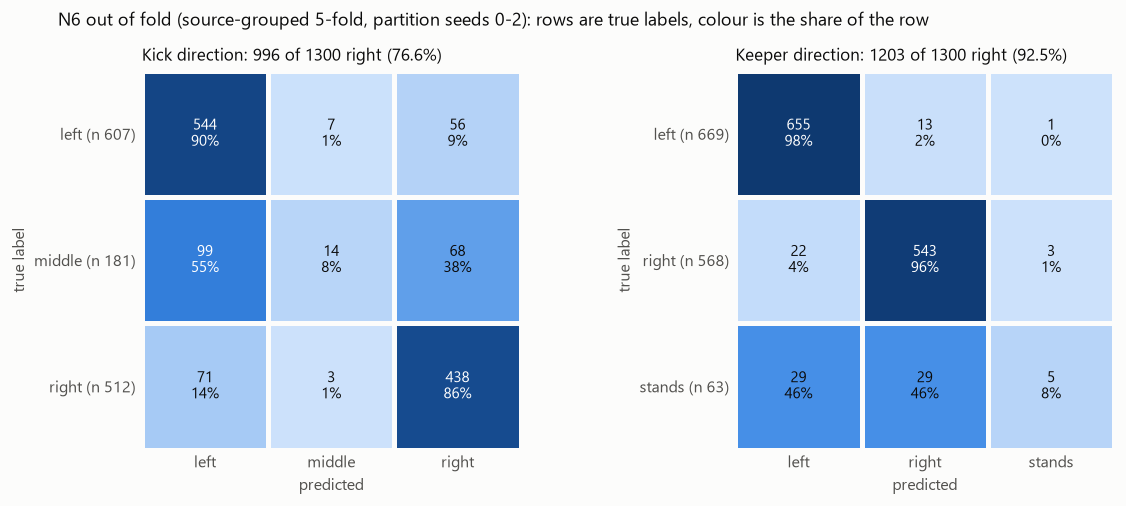

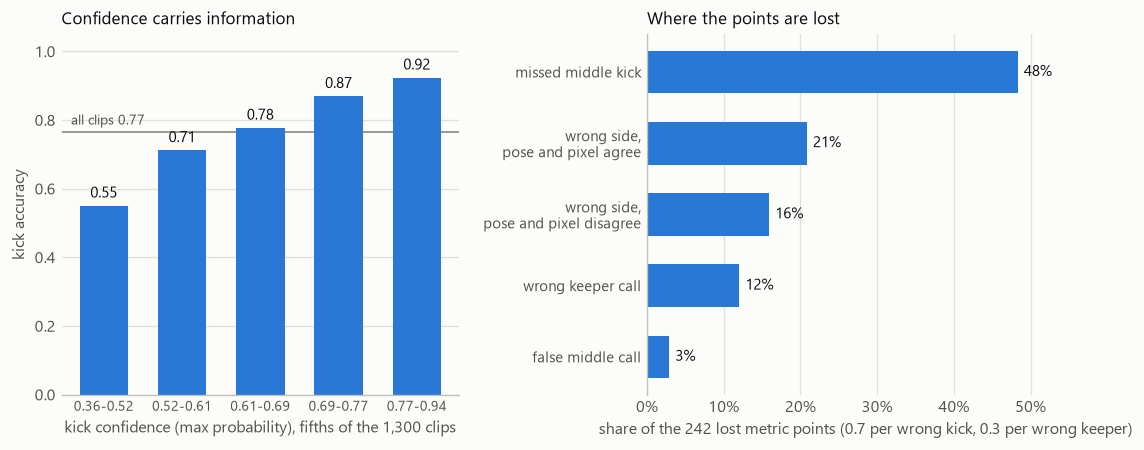

In [107]:
run("fig_results.py", tail=8)
for f in ("confusion.png", "confidence.png"): display(Image(filename=os.path.join(RUN, "logs", "fig", f)))

## 18. What did not work, and caveats
Each test below was decided by a rule written before its result, judged on source-grouped CV with fresh partition seeds. One kick clip = 0.0005 of the metric.
* **Kick cues that did not help:**
  * a follow-through or swing direction (AUC ≤ 0.55);
  * the ball's direction after contact, read from the last frames;
  * plant- and kicking-foot pointing cues;
  * run-up rhythm (`kinX.py`, +4 over four sets: below the bar);
  * head tilt and kicking-foot shape (`kinH.py`, −5);
  * middle-kick stackers on ViTPose internals (−3 to −7);
  * P(middle) scaling;
  * a 15 fps time grid, CLAHE, and degraded-crop training for 640×360;
  * Sapiens pose, DINOv2 / DINOv3 / MViT pixel features (all below ViTPose+ base);
  * view augmentation, keypoint smoothing, a common time grid;
  * LightGBM, stackers, other blend weights.
* **Keeper:** a pixel model, an early-mover split, and stands reweighting.
* **Outcome:** no model beat always predicting `goal`.
* **Where the model is weak:**
  * about half of the lost points are missed middle kicks: middle recall is about 0.08, and every component ranks middles at AUC 0.61–0.66;
  * a further quarter come from left/right errors where the pose and pixel models agree and are both wrong;
  * 640×360 clips (0.63 on 21 labelled clips) and unclicked sources (0.76 against 0.84) are weaker.
* **Caveats:**
  * Ball and keypoint quality are self-consistency checks, not labelled accuracy, and nothing was hand-corrected.
  * The tests looked at many variants, but each was decided on fresh seeds by a rule fixed in advance, and the four-set spread of the final recipe is 0.003.
  * Public (360 clips) is about 2 points above the CV level, so expect private around 0.82.

## 19. Challenges
* **The kick is never shown.**
  * Clips stop 0.02 s before contact, so the direction has to be read from the approach and the last frames.
  * Middle kicks (14% of the labelled clips) and keepers who stand (5%) are mostly decided at or after contact. They remain the main loss: 48% of the lost points are missed middles (Section 17).
* **Small, blurred players.**
  * In broadcast video a kicker is often about 100 px tall, with motion blur and compression.
  * Pose models swap left and right joints at that size. So every kicker feature is label-free (the foot that travels farther is the kicking foot), and five pose models serve as independent measurements.
* **The wrong person.**
  * In some clips the track ended on the referee or another player near the spot.
  * The label-free spot check found 32 such clips. The kicker re-pick and identity fix repaired them (Sections 13 and 14), and the pixel crops had to be recut on the right kicker.
* **Very different camera views.**
  * Behind-the-kicker, side-on, high and low angles change what a left kick looks like.
  * The ground-plane camera and the camera-aware pixel head deal with this. Six test clips whose fitted camera sat below the horizon needed a corrected azimuth (Section 15).
* **Frame rates from 15 to 60 fps.**
  * Features use time, not frame counts.
  * One test source (31 clips at 15 fps and 640×360) is unlike anything in training and is read less well.
* **Unseen sources.**
  * Almost every test source is new, so a random clip split would overstate accuracy.
  * Every decision used source-grouped CV, a rule fixed before its result, and fresh partition seeds.
* **Little data.**
  * There are 1,300 labelled clips.
  * The pixel model gains about 2.8 points of kick accuracy per doubling of its training clips, so more labelled clips would be the strongest lever. No suitable external dataset was available.
* **Compute.**
  * Detection and pose take many GPU-hours.
  * On Windows every multiprocessing worker re-imports its script, so the notebook caches the heavy stages and limits the pool size (Section 0).